# Preamble

## Imports and overall settings

In [1]:
import warnings
warnings.simplefilter("always")
from IPython.display import display, HTML, Markdown
import os
import string
from itertools import combinations, cycle
from pprint import pprint
import re
from operator import sub

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.constants import e
import pandas as pd
import seaborn as sns

from ipfnpytools.attributes import rgetattr
import ipfnpytools.arguments as args
from ipfnpytools.plot import use_base_style
from ipfnpytools.save_figure import save_figure

## Definitions

### Labels and multipliers

In [2]:
# Specific-use multipliers and labels
label_Bt = '$B_{t}$ (T)'
symbol_Ip = "$I_{{p}}$"
mult_Ip = 1E-6
units_Ip = "MA"
label_Ip =  r"{} ({})".format(symbol_Ip.format(), units_Ip)
label_Ip_binned = label_Ip + " (binned)"
symbol_base_gaspuff = r"$\Gamma_{{{}}}$"
symbol_deuterium_gaspuff = symbol_base_gaspuff.format("{D}")
mult_gaspuff = 1E-21
units_gaspuff = r"$10^{{{{{}}}}} e^{{{{-}}}}$/s".format(
    -int(np.log10(mult_gaspuff)))
label_base_gaspuff = r"{} ({})".format(symbol_base_gaspuff, units_gaspuff)
label_gaspuff = (
    r"{} ({})".format(symbol_deuterium_gaspuff, units_gaspuff).format())
label_fueling = label_gaspuff
label_fueling_binned = label_fueling + " (binned)"
label_current = label_Ip
label_current_binned = label_Ip_binned#label_current + " (binned)"
power_mult = 1E-6
power_units = 'MW'
ipolsol_mult = 1E-3
ipolsol_units = 'kA'
symbol_neavg = r"$\overline{n_{e}}$"
ne_mult = 1E-19
ne_magnitude = -int(np.log10(ne_mult))
units_ne = "$10^{{{}}}m^{{-3}}$".format(ne_magnitude)
mult_Te = 1E-3
units_Te = "keV"
mult_pe = 1E-3
units_pe = "kPa"
symbol_Wmhd = "$W_{mhd}$"
mult_Wmhd = 1E-6
units_Wmhd = "MJ"
symbol_tauE = r"$\tau_{E}$"
mult_tauE = 1E3
units_tauE = "ms"
symbol_p_avg = r"$\overline{p}$"
symbol_ptau = symbol_p_avg + symbol_tauE
mult_ptau = 1E-3
units_ptau = "kPa s"

#TODO: converter IOC|F03, F04 e F14 para Pa quando houver dados da campanha 2019/20

# General multipliers
x_IDA = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 100]
multipliers_diag_dict = dict(
    DCN=ne_mult, TOT=dict(P=power_mult, H=ne_mult), MAC=dict(I=1E-3, T=1), FPC=mult_Ip, ECS=power_mult, 
    NIS=power_mult, BPD=power_mult, BPT=power_mult, ICP=power_mult, UVS=mult_gaspuff, GIW=dict(n=1E-15, c=1E5), 
    TTH=dict(P=power_mult), IRA=dict(q=1E-6), IOC=dict(F=1E-22))
multipliers_signals_dict = dict(
    Wmhd=mult_Wmhd, p_avg=1E-3, tau_tot=mult_tauE, gaspuff_tot=1E-21, dRXP=-1E2, 
    **{"dWmhd/dt":mult_Wmhd, 'p_avg*tau_tot':mult_ptau})
multipliers_signals_dict.update({
    "{}e{}".format(quantity, x):mult for x in x_IDA
    for quantity, mult in zip(["T", "n", "p"], [mult_Te, ne_mult, mult_pe])})
multipliers_signals_dict.update({"n{}Ist".format(s):1E-17 for s in ["Div", "Main"]})
multipliers_signals_dict.update({"q{}".format(x):-1 for x in [0, 25, 50, 75, 95]})    

# General labels
labels_dict = dict(
    phase=None, beta_N=r"$\beta_{N}$", betpol=r"$\beta_{pol}$", nust_ped=r'$\nu_{e,ped}^{*}$', 
    nust_a_2=r'$\nu_{e,a/2}^{*}$', nustar_m=r'$\nu_{e,min}^{*}$', 
    #Ipolsola="$I_{div,outer}$"+0*"$I_{polsola}$"+" (kA)", Ipolsoli="$I_{div,inner}$"+0*"$I_{polsoli}$"+" (kA)", 
    Wmhd="{} ({})".format(symbol_Wmhd, units_Wmhd), CFA03A=label_base_gaspuff.format("Ar"), 
    CFA03C=label_base_gaspuff.format("Kr"), c_W="$c_{W,1-1.5keV}$ ($10^{-5}$)", c_W_l="$c_{W,>2keV}$ ($10^{-5}$)", 
    n_W="$n_{W,1-1.5keV}$ ($10^{15}m^{-3}$)", n_W_l="$n_{W,>2keV}$ ($10^{15}m^{-3}$)", cN="$c_{N}$ (%)", 
    Zeff="$Z_{eff}$", qMax="$q_{max}$ (MW)", Tdiv="$T_{div}$ (eV)", IpiFP=label_Ip, Rgeo='$R_{geo}$ (m)', 
    ahor='a (m)', bver='b (m)', Surface='S ($m^{2}$)', Vol='V ($m^{3}$)', kappa=r"$\kappa$", 
    epsilon=r"$\varepsilon$", dRXP=r"${\Delta R}_{\mathrm{sep}}$ (cm)", XPfdif=r"${\Delta \psi}_{\mathrm{sep}}}$", 
    drhopolXP=r"${\Delta \rho_{\mathrm{pol}}}_{\mathrm{sep}}$", gaspuff_tot=label_base_gaspuff.format("tot"), 
    p_avg=r"{} (kPa)".format(symbol_p_avg), tau_tot=r"{} ({})".format(symbol_tauE, units_tauE), BTF=label_Bt, rho_pol=r"$\rho_{pol}$",
    **{
        "H/L-facs":"$H_{98y2}$", "L2H_facs":"$P_{tot}/P_{LH,scal}$",
        "dWmhd/dt":r"d{}/dt ({})".format(symbol_Wmhd, units_Wmhd),
        'H-1':1*symbol_neavg+0*"H-1(core)"+0*'core'+" ($10^{{{}}}m^{{-2}})$".format(ne_magnitude), 
        'H-5':1*r"$\overline{n_{e,edge}}$"+0*"H-5(edge)"+0*'edge'+" ($10^{{{}}}m^{{-2}})$".format(ne_magnitude), 
        'H-1_corr':1*symbol_neavg+0*"H-1(core)"+0*'core'+" ($10^{{{}}}m^{{-3}})$".format(ne_magnitude), 
        'H-5_corr':1*r"$\overline{n_{e,edge}}$"+0*"H-5(edge)"+0*'edge'+" ($10^{{{}}}m^{{-3}})$".format(ne_magnitude), 
        'n/nGW':"$f_{GW}$", "C09-24":"C09-24\n(bottom)", "R/a":'$R_{geo}$/a',
        "B31-14":0*"B31-14\n(LFS)"+1*r"$\dot{B_{r}}$, B31-14 (LFS)", 'nu_e*95':r'$\nu_{e*,95}$',
        'beta_N*H_98':r"$\beta_{N} H_{98y2}$", 'beta_N/H_98':r"$\beta_{N}/H_{98y2}$", 
        'p_avg*tau_tot':r"{} ({})".format(symbol_ptau, units_ptau), "F04/F14":"F04/F14"})
labels_dict.update({s+"_tot":label_base_gaspuff.format(s) for s in ['D', 'N', 'H', 'He', 'Ar', 'Ne']})
labels_dict.update({
    s:r"$\delta_{{{}}}$".format(t) for s, t in zip(["delRoben", "delRuntn", "delRavg"], ["up", "low", "avg"])})
labels_dict.update({
    "{}e{}".format(quantity, x):"${}_{{e,{}}}$ ({})".format(quantity, x, unit) 
    for x in x_IDA 
    for quantity, unit in zip(["T", "n", "p"], [units_Te, units_ne, units_pe])})
labels_dict.update({"q{}".format(x):"$q_{{{}}}$".format(x) for x in [0, 25, 50, 75, 95, "cyl"]})
labels_dict.update({"n{}Ist".format(s):"$p_{{0, {}}}$ (a.u.)".format(s.lower()) for s in ["Div", "Main"]})
neutral_flux_label_template = "F{:02} ($10^{{22}}m^{{-2}}s^{{-1}}$)"
labels_dict.update({"F{:02}".format(i):neutral_flux_label_template.format(i) for i in range(1,21)})
labels_dict.update({"P_TOT_interp_Pradtot":"$P_{{tot(interpolated)}}$ ({})".format(power_units)})
multipliers_signals_dict.update({"P_TOT_interp_Pradtot":power_mult})
labels_dict.update({"Pradtot/P_TOT":"$P_{rad}$/$P_{tot}$"})

# Ipolsol labels and multipliers
ipolsol_base_dict = {
    ("Ipolsol" + suffix):"$I_{{div,{}}}$".format(subscript) 
    for suffix, subscript in [("a", "outer"), ("i", "inner")]}
ipolsol_string_templates, ipolsol_string_template_replacements = zip(*[
    (s.format(t, t), s_replacement.format(t_replacement))
    for s, s_replacement in [
        ('rolling_median_50ms({})', "$med_{{{{50ms}}}}$({})"), 
        ('{}-rolling_median_50ms({})', r"$\Delta${}"), 
        ('{}', '{}')]
    for t, t_replacement in [
        ("{}*qcyl", "{}$q_{{{{cyl}}}}$"),
        ("{}", "{}")]
    ])
ipolsol_dict = {
    s:s_replacement.replace(key, replacement).replace("99.9%ile", r"$\%_{ile,99.9}$") + " ({})".format(ipolsol_units) 
    for key, replacement in ipolsol_base_dict.items()
    for template, template_replacement in zip(ipolsol_string_templates, ipolsol_string_template_replacements)
    for s, s_replacement in [
        [func_template.format(t) for t in [template.format(key, key), template_replacement.format(key)]]
        for func_template in (
            [
                '{}{}({}{{}})'.format(sign, func, sign) 
                for func in ["max", "99.9%ile"] 
                for sign in ["", "-"]]
            + ["{}"])]
    }
ipolsol_dict.update({key[1:]: value[1:] for key, value in ipolsol_dict.items() if key[0] == '-'})
labels_dict.update(ipolsol_dict)
multipliers_signals_dict.update({name:ipolsol_mult for name in ipolsol_dict})
shapiro_symbol = "$W_{SW}$"
labels_dict.update({
    #"shapiro({})".format(template.format(key, key)):"$W_{{SW}}$({})".format(template_replacement.format(key)).replace(key, replacement)
    "shapiro({})".format(template.format(key, key)):"{}({})".format(shapiro_symbol, template_replacement.format(key)).replace(key, replacement)
    for key, replacement in ipolsol_base_dict.items()
    for template, template_replacement in zip(ipolsol_string_templates, ipolsol_string_template_replacements)})
labels_dict.update({
    "1-shapiro({})".format(template.format(key, key)):"1-{}({})".format(shapiro_symbol, template_replacement.format(key)).replace(key, replacement)
    for key, replacement in ipolsol_base_dict.items()
    for template, template_replacement in zip(ipolsol_string_templates, ipolsol_string_template_replacements)})

LH_suffix = "@LH"
normalized_LH_suffix = "/" + LH_suffix

# Specific power and radiated power labels and multipliers
power_suffixes_subscripts = (
    ("_OH", "ohmic"), ("ECRH", "ECRH"), ("NI", "NBI"), ("radtot", "rad"), ("ICRFc", "ICRH"), ("_TOT", "tot"),
    ("_NET", "net"), ("_heat", "heat"))
power_density_symbols_labels_units_multipliers = (
    ('R', 'R', power_units+'/m', power_mult), ('S', 'S', power_units+'/$m^{2}$', power_mult), 
    ('V', 'V', power_units+'/$m^{3}$', power_mult), 
    ('ne', "$n_{e}$", "$10^{{{}}}$ {} $m^{{3}}$".format(ne_magnitude, power_units), (power_mult / ne_mult)), 
    ('neS', "($n_{e}$S)", "$10^{{{}}}$ {} m".format(ne_magnitude, power_units), (power_mult / ne_mult)))
for suffix, subscript in power_suffixes_subscripts:
    name = "P" + suffix
    label_base = "$P_{{{}}}$".format(subscript)
    labels_dict.update({name:"{} ({})".format(label_base, power_units)})
    name_LH = name + LH_suffix
    labels_dict.update(
        {name_LH:"$P_{{{},LH}}$".format(subscript)})
    multipliers_signals_dict.update({s:power_mult for s in [name, name_LH]})
    name_normalized_LH = name + normalized_LH_suffix
    labels_dict.update(
        {name_normalized_LH:"$P_{{{}}}$/$P_{{{},LH}}$".format(*[subscript]*2)})
    multipliers_signals_dict.update({name_normalized_LH:1})
    for symbol, label, unit, mult in power_density_symbols_labels_units_multipliers:
        name_density = "{}/{}".format(name, symbol)
        labels_dict.update({name_density:"{}/{} ({})".format(label_base, label, unit)})
        multipliers_signals_dict.update({name_density:mult})
for suffix in ["tot", "sep", "sepX", "main", "div"]:
    name_Pr = "Pr_" + suffix
    label_Pr_base = "$P_{{rad,{}}}$".format(suffix)
    name_subtracted = "P_TOT-" + name_Pr
    label_subtracted_base = "$P_{tot}$-" + label_Pr_base
    labels_dict.update({(name_Pr + "/P_TOT"):"{}/$P_{{tot}}$".format(label_Pr_base)})
    for name, label_base in (
            (name_Pr, label_Pr_base), (name_subtracted, label_subtracted_base), 
            (name_Pr + '_interp_P_TOT', "$P_{{rad,{}(interpolated)}}$".format(suffix))):
        labels_dict.update({name:"{} ({})".format(label_base, power_units)})
        multipliers_signals_dict.update({name:power_mult})
    for symbol, label, unit, mult in power_density_symbols_labels_units_multipliers:
        name = '({})/{}'.format(name_subtracted, symbol)
        labels_dict.update({name:"({})/{} ({})".format(label_subtracted_base, label, unit)})
        multipliers_signals_dict.update({name:mult})

# LH labels and multipliers
labels_dict["H-1_corr" + LH_suffix] = (
    r"$\overline{{n_{{e,LH}}}}$ ($10^{{{}}}m^{{-3}})$".format(ne_magnitude))

# Custom labels
suffix_Ptot = "tot"
suffix_Psep = "SOL"
symbol_Ptot, symbol_Psep = ("$P_{{{{{}}}}}$".format(s) for s in [suffix_Ptot, suffix_Psep])
labels_dict['P_TOT-Pr_sep'] = "{} ({})".format(symbol_Psep.format(), power_units)
labels_dict['P_TOT-Pr_sep' + normalized_LH_suffix] = (
    "{}/$P_{{sep,LH}}$".format(symbol_Psep.format()))
labels_dict['P_TOT-Pr_sep' + LH_suffix] = (
    "$P_{{sep,LH}}$ ({})".format(power_units))
labels_dict['n/nGW' + LH_suffix] = "$f_{GW,LH}$"

# Inverted label dict
labels_dict_inverted = {v: k for k, v in labels_dict.items()}
labels_dict_inverted[label_current_binned] = "Ip_binned"


def rename(header):
    #TODO: docstring
    return labels_dict.get(header[header.find('|')+1:], header)


# Other label variables
label_PECRH = labels_dict['PECRH']
label_Ptot = labels_dict['P_TOT']
label_Ptot_normalized_LH = labels_dict['P_TOT/@LH']
label_Psep = labels_dict['P_TOT-Pr_sep']
label_Psep_normalized_LH = labels_dict['P_TOT-Pr_sep/@LH']
label_Wmhd = labels_dict['Wmhd']
label_tauE = labels_dict['tau_tot']
label_ptau = labels_dict['p_avg*tau_tot']
label_neavg = labels_dict["H-1_corr"]
label_neavg_LH = labels_dict["H-1_corr@LH"]
label_fGW = labels_dict["n/nGW"]
label_fGW_LH = labels_dict['n/nGW@LH']
label_q95 = labels_dict['q95']
label_Zeff = labels_dict['Zeff']
label_nuestar95 = labels_dict['nu_e*95']
label_shapiro = labels_dict['shapiro(Ipolsola)']
label_major_radius_geometric = labels_dict["Rgeo"]
label_minor_radius_horizontal = labels_dict["ahor"]
label_minor_radius_vertical = labels_dict["bver"]
label_surface = labels_dict["Surface"]
label_volume = labels_dict["Vol"]
label_inverse_aspect_ratio = labels_dict["epsilon"]
label_elongation = labels_dict["kappa"]
label_triangularity_upper = labels_dict["delRoben"]
label_triangularity_lower = labels_dict["delRuntn"]
label_triangularity_avg = labels_dict["delRavg"]
label_dRsep = labels_dict["dRXP"]
label_drhosep = labels_dict["drhopolXP"]
label_rho_pol = labels_dict["rho_pol"]

display(labels_dict)

{'phase': None,
 'beta_N': '$\\beta_{N}$',
 'betpol': '$\\beta_{pol}$',
 'nust_ped': '$\\nu_{e,ped}^{*}$',
 'nust_a_2': '$\\nu_{e,a/2}^{*}$',
 'nustar_m': '$\\nu_{e,min}^{*}$',
 'Wmhd': '$W_{mhd}$ (MJ)',
 'CFA03A': '$\\Gamma_{Ar}$ ($10^{21} e^{-}$/s)',
 'CFA03C': '$\\Gamma_{Kr}$ ($10^{21} e^{-}$/s)',
 'c_W': '$c_{W,1-1.5keV}$ ($10^{-5}$)',
 'c_W_l': '$c_{W,>2keV}$ ($10^{-5}$)',
 'n_W': '$n_{W,1-1.5keV}$ ($10^{15}m^{-3}$)',
 'n_W_l': '$n_{W,>2keV}$ ($10^{15}m^{-3}$)',
 'cN': '$c_{N}$ (%)',
 'Zeff': '$Z_{eff}$',
 'qMax': '$q_{max}$ (MW)',
 'Tdiv': '$T_{div}$ (eV)',
 'IpiFP': '$I_{p}$ (MA)',
 'Rgeo': '$R_{geo}$ (m)',
 'ahor': 'a (m)',
 'bver': 'b (m)',
 'Surface': 'S ($m^{2}$)',
 'Vol': 'V ($m^{3}$)',
 'kappa': '$\\kappa$',
 'epsilon': '$\\varepsilon$',
 'dRXP': '${\\Delta R}_{\\mathrm{sep}}$ (cm)',
 'XPfdif': '${\\Delta \\psi}_{\\mathrm{sep}}}$',
 'drhopolXP': '${\\Delta \\rho_{\\mathrm{pol}}}_{\\mathrm{sep}}$',
 'gaspuff_tot': '$\\Gamma_{tot}$ ($10^{21} e^{-}$/s)',
 'p_avg': '$\\overlin

### Labels scalings fits

In [3]:
base_quantities = ('ne', 'Te', 'pe')
fancy_base_quantities = ["${}_{{e}}$".format(quantity[:1]) for quantity in base_quantities]
base_quantities_mult_dict = dict(zip(base_quantities, [ne_mult, mult_Te, mult_pe]))

label_r2 = '$r^2$'
label_logk = 'logk'

symbol_base_exponent = r"$\gamma_{{{{{}}}}}$"
(
        label_gamma_generic_power, label_gamma_power, 
        label_gamma_fueling, label_gamma_current) = (
    r"${}$".format(symbol_base_exponent.format(symbol).replace('$', ""))
    for symbol in ["P", symbol_Ptot, symbol_deuterium_gaspuff, symbol_Ip])

symbol_base_scaled_Ptot, symbol_base_scaled_Psep = (
    r"{}[{}]$^{{{{{{:#.2g}}}}}}$".format(symbol, power_units) 
    for symbol in [symbol_Ptot, symbol_Psep])
label_base_scaled_Ptot, label_base_scaled_Psep = (
    r"{}$^{{{{{{:#.2g}}}}}}$ (({})$^{{{{{{:#.2g}}}}}}$)".format(
        symbol_Psep, power_units) 
    for symbol in [symbol_Ptot, symbol_Psep])
symbol_base_scaled_Ip = r"{}[{}]$^{{{{{{:#.2g}}}}}}$".format(symbol_Ip, units_Ip)
label_base_scaled_Ip = (
    r"{}$^{{{{{{:#.2g}}}}}}$ (({})$^{{{{{{:#.2g}}}}}}$)".format(
        symbol_Ip, units_Ip))
symbol_base_scaled_deuterium_gaspuff = r"{}[{}]$^{{{{{{:#.2g}}}}}}$".format(
    symbol_deuterium_gaspuff, units_gaspuff)
label_base_scaled_gaspuff = (
    r"{}$^{{{{{{:#.2g}}}}}}$ (({})$^{{{{{{:#.2g}}}}}}$)".format(
        symbol_deuterium_gaspuff, units_gaspuff))
label_base_scaled_gaspuff_Ip = (
    (r"{}$^{{{{{{:#.2g}}}}}}$"*2 + " (({})$^{{{{{{:#.2g}}}}}}${}$^{{{{{{:#.2g}}}}}}$)")
    .format(
        symbol_deuterium_gaspuff, symbol_Ip, units_gaspuff, units_Ip))
label_base_scaled_Ptot_gaspuff_Ip, label_base_scaled_Psep_gaspuff_Ip = (
    (
        r"{}$^{{{{{{:#.2g}}}}}}$"*3 + 
        " ({}$^{{{{{{:#.2g}}}}}}$({})$^{{{{{{:#.2g}}}}}}${}$^{{{{{{:#.2g}}}}}}$)")
    .format(
        symbol, symbol_deuterium_gaspuff, symbol_Ip, power_units, 
        units_gaspuff, units_Ip)
    for symbol in [symbol_Ptot, symbol_Psep])

(
        label_generic_scaled_Ptot, label_generic_scaled_Psep, 
        label_generic_scaled_fueling, label_generic_scaled_current) = (
    r"{}$^{{{{{}}}}}$".format(
        symbol, symbol_base_exponent.format(symbol).replace('$', ""))
    for symbol in [
        symbol_Ptot, symbol_Psep, symbol_deuterium_gaspuff, symbol_Ip])

(
        units_generic_scaled_Ptot, units_generic_scaled_Psep, 
        units_generic_scaled_fueling, units_generic_scaled_current) = (
    "{}$^{{{{{}}}}}$".format(
        units, symbol_base_exponent.format(symbol).replace('$', ""))
    for symbol, units in [
        (symbol_Ptot, power_units), (symbol_Psep, power_units), 
        (symbol_deuterium_gaspuff, "({})".format(units_gaspuff)), 
        (symbol_Ip, units_Ip)])

(
        label_generic_scaled_Ptot_with_units, 
        label_generic_scaled_Psep_with_units, 
        label_generic_scaled_fueling_with_units, 
        label_generic_scaled_current_with_units) = (
    label_generic_scaled + " ({})".format(units)
    for label_generic_scaled, units in [
        (label_generic_scaled_Ptot, units_generic_scaled_Ptot), 
        (label_generic_scaled_Psep, units_generic_scaled_Psep), 
        (label_generic_scaled_fueling, units_generic_scaled_fueling), 
        (label_generic_scaled_current, units_generic_scaled_current)])

(
        label_generic_scaled_Ptot_fueling_current, 
        label_generic_scaled_Psep_fueling_current) = (
    (
        label_generic_scaled_power + label_generic_scaled_fueling + 
        label_generic_scaled_current)
    for label_generic_scaled_power in [
        label_generic_scaled_Ptot, label_generic_scaled_Psep])

(
        label_generic_scaled_Ptot_fueling_current_with_units, 
        label_generic_scaled_Psep_fueling_current_with_units) = (
    (
        label_generic_scaled_power_fueling_current + 
        " ({})".format((
            units_generic_scaled_power + units_generic_scaled_fueling + 
            units_generic_scaled_current)))
    for (label_generic_scaled_power_fueling_current, units_generic_scaled_power) 
    in [
        (label_generic_scaled_Ptot_fueling_current, units_generic_scaled_Ptot), 
        (label_generic_scaled_Psep_fueling_current, units_generic_scaled_Psep)])

(
        label_inverted_generic_scaled_Ptot, label_inverted_generic_scaled_Psep, 
        label_inverted_generic_scaled_fueling, 
        label_inverted_generic_scaled_current) = (
    "scaled_" + labels_dict_inverted[label]
    for label in [label_Ptot, label_Psep, label_fueling, label_current])
labels_dict_inverted.update({
    label_generic_scaled_Ptot:label_inverted_generic_scaled_Ptot,
    label_generic_scaled_Ptot_with_units:label_inverted_generic_scaled_Ptot,
    label_generic_scaled_Psep:label_inverted_generic_scaled_Psep,
    label_generic_scaled_Psep_with_units:label_inverted_generic_scaled_Psep,
    label_generic_scaled_fueling:label_inverted_generic_scaled_fueling,
    label_generic_scaled_fueling_with_units:label_inverted_generic_scaled_fueling,
    label_generic_scaled_current:label_inverted_generic_scaled_current,
    label_generic_scaled_current_with_units:label_inverted_generic_scaled_current})

labels_dict_inverted.update({
    label_generic_scaled_power_fueling_current:(
        "scaled_" + 
        "_".join([
            labels_dict_inverted[label] 
            for label in [label_power, label_fueling, label_current]]))
    for label_generic_scaled_power_fueling_current, label_power in [
        (label_generic_scaled_Ptot_fueling_current, label_Ptot), 
        (label_generic_scaled_Ptot_fueling_current_with_units, label_Ptot), 
        (label_generic_scaled_Psep_fueling_current, label_Psep), 
        (label_generic_scaled_Psep_fueling_current_with_units, label_Psep)]})

### General

In [4]:
def convenient_string(x, sep='_', sep_many='...', n_many=4, sort=None):
    #TODO: docstring
    
    if sort is None:
        sort = pd.api.types.is_numeric_dtype(x)
    x = np.atleast_1d(x)
    if sort:
        x = np.sort(x)
    x = x.astype(str)
    return sep.join(x) if x.size < n_many else sep_many.join([x[0], x[-1]])


def is_writable(name, *variables):
    #TODO: docstring
    
    #return all(name not in np.atleast_1d(v) for v in variables)
    return np.isin(name, variables, invert=True).all()


def default_to_write(
        write_Bt, write_Ip, write_gaspuff, write_PECRH, write_dt, has_dt, 
        *expressed_vars, label_Bt=label_Bt, label_Ip=label_Ip, 
        label_gaspuff=label_gaspuff, 
        label_PECRH=(label_PECRH, label_Ptot, label_Psep)[0]):
    #TODO: docstring
    
    if write_Bt is None:
        write_Bt = is_writable(label_Bt, *expressed_vars)
    if write_Ip is None:
        write_Ip = is_writable(label_Ip, *expressed_vars)
    if write_gaspuff is None:
        write_gaspuff = is_writable(label_gaspuff, *expressed_vars)
    if write_PECRH is None:
        write_PECRH = is_writable(label_PECRH, *expressed_vars)
    if write_dt is None:
        write_dt = has_dt
    
    return write_Bt, write_Ip, write_gaspuff, write_PECRH, write_dt


def group_order(variable, data, sort_group, maintain_group_order):
    #TODO: doctring
    
    variable_order = None
    if variable is not None:
        if sort_group:
            data = data[variable].unique()
            variable_order = np.sort(data[pd.notna(data)])
        elif maintain_group_order and data[variable].dtype.name != 'category':
            variable_order = data[variable].unique()
            
    return variable_order


def wrap_column(data, column, order, appearance, n_wrap, wrap_title=True):
    #TODO: docstring

    data_column = data[column]
    if wrap_title:
        column_wrapped = pd.Series(column).str.wrap(n_wrap)[0]
        data = data.rename(columns={column:column_wrapped})
        column = column_wrapped
    #column = column_wrapped
    if data_column.dtype == object:
        data_column = data_column.astype(str)
    try:
        data[column] = data_column.str.wrap(n_wrap)
        #data = data.assign({
        #    column_wrapped:data_column.str.wrap(n_wrap)})
        #data = data.assign(**{column:data_column.str.wrap(n_wrap)})
    except AttributeError:
        pass
    else:
        if order is not None:
            order = pd.Series(order).astype(str).str.wrap(n_wrap)
        if appearance is not None and isinstance(appearance, dict):
            appearance = {
                pd.Series(key).astype(str).str.wrap(n_wrap)[0]: value 
                for key, value in appearance.items()}
    
    #return data, column_wrapped, order
    return data, column, order, appearance


def default_n_wrap(right, n_x_eff):
    #TODO: docstring
    
    return (15 if right is None else int(round(80 * (n_x_eff * (1 - right) - 0.13))))


qualitative_palette = sum([sns.color_palette('tab20')[i::2] for i in [0,1]], [])


def default_height(n_rows_eff, n_rows):
    #TODO: docstring
    
    return 4.13644795878 * n_rows_eff / n_rows


def default_aspect(n_rows_eff, n_cols_eff):
    #TODO: docstring
    
    return 1.22 * n_rows_eff / n_cols_eff


def default_top(n_rows_eff):
    #TODO: docstring
    
    return 1 - 0.08 / n_rows_eff


def default_left(n_cols_eff):
    #TODO: docstring
    
    return 0.15 / n_cols_eff


#TODO: make data and label_data arguments mandatory an adapt the rest
def title_suffix(
        data, label_data, label_suffix="", units_suffix="", title="", 
        relative_threshold_equal=0.015, relative_threshold_approx=0.06):
    #TODO: docstring
    
    if label_data not in data:
        return ""

    value_min, value_max, value_avg = (
        getattr(data[label_data], f)() for f in ["min", "max", "mean"])
    relative_variation = (value_max - value_min) / value_avg
    if relative_variation < relative_threshold_equal:    
        values_suffix = '={:.1f}'.format(value_avg)
    elif relative_variation < relative_threshold_approx: 
        values_suffix = r'$ \approx ${:.1f}'.format(value_avg)
    else:
        values_suffix = '={:.1f}-{:.1f}'.format(value_min, value_max)
        
    return (
        (", " if title.strip() != "" else "") + label_suffix + values_suffix + 
        units_suffix)


def informative_title(
        data, title_prefix, write_Bt, write_Ip, write_gaspuff, write_PECRH, 
        write_dt, label_Bt, label_Ip, label_gaspuff, label_PECRH, has_dt):
    #TODO: docstring

    title = title_prefix
    for write, label_suffix, units, label_data in (
            (write_Bt, '$B_{t}$', ' T', label_Bt), 
            (write_Ip, '$I_{P}$', ' MA', label_Ip),
            (
                write_gaspuff, r'$\Gamma_{D}$', r'$\times 10^{21}$ $e^{-}$/s', 
                label_gaspuff),
            (write_PECRH, '$P_{ECRH}$', ' MW', label_PECRH)):
        if write:
            title += title_suffix(
                data=data, label_data=label_data, label_suffix=label_suffix, 
                units_suffix=units, title=title)
    if write_dt and has_dt:
        if title != "":
            title += ", "
        title += r"$\Delta t \approx$"
        if data.attrs['dt_subperiod'] >= 0.1:
            title += "{}s".format(data.attrs['dt_subperiod'])
        else:
            title += "{:.0f} ms".format(data.attrs['dt_subperiod']*1E3)
    return title


_methods = ['get_{}axis'.format(s) for s in ('x','y')]
_all_labels = (
    np.add.outer(
        list(string.ascii_letters), [""] + list(string.digits), dtype=object)
    .flatten(order='F'))


def adjust_plot(
        plot, n_rows_eff, n_cols_eff, legend_title, wspace, hspace, left, 
        right, top, bottom, order, label_pos_x, label_pos_y, label_pad_x, 
        label_pad_y, label_start, label_color, title, legend_linewidth, 
        legend_markersize, title_prefix="", annotate_kw=None, title_kw=None):
    #TODO: docstring
    
    # Define default keywords
    if annotate_kw is None:
        annotate_kw = {}
    if title_kw is None:
        title_kw = {}
    
    # Adjust axes
    for ax in plot.axes.flat:
        for method in _methods:
            getattr(ax, method)().set_minor_locator(
                mpl.ticker.AutoMinorLocator())
        for side in ['right', 'top']:
            ax.spines[side].set_visible(True)
        # Explicit size required because of matplotlib bug:
        # https://github.com/matplotlib/matplotlib/issues/25298/
        ax.set_xlabel(ax.get_xlabel(), size=mpl.rcParams['axes.labelsize'])
        ax.set_ylabel(ax.get_ylabel(), size=mpl.rcParams['axes.labelsize'])
    
    # Adjust margins and legend
    plot.fig.set_figwidth(n_cols_eff * 6.69291339)
    if hasattr(plot, "_legend") and plot._legend is not None:
        for legend_handle in rgetattr(plot, "_legend.legend_handles", []):
            if isinstance(legend_handle, mpl.collections.PathCollection):
                legend_handle.set_linewidth(legend_linewidth)
                if legend_markersize is not None:
                    legend_handle._sizes = [legend_markersize]
        if legend_title is not None:
            plot._legend.set_title(legend_title)
        else:
            legend_title = plot._legend.get_title()._text
        max_legend_title_length = max(
                [
                    len(l) if "$" not in l else 1 
                    for l in legend_title.splitlines()],
                default=0)
        max_legend_entries_length = max([
            (len(l) if "$" not in l else 1) + 3 
            for s in plot._legend.get_texts() for l in s._text.splitlines()])
        max_legend_length = max(
            max_legend_title_length, max_legend_entries_length)
        if right is None:
            right = 1 - (0.15 + 0.013 * max(0, (max_legend_length - 6))) / n_cols_eff
    plt.subplots_adjust(
        wspace=wspace, hspace=hspace, left=left, right=right, top=top, 
        bottom=bottom)
    
    # Write label for each subplot box
    if plot.axes.size > 1:
        for index, ax in enumerate(
                plot.axes.flatten({"column":"F", "row":"C"}[order])):
            if label_pad_x is None:
                label_pad_x = -7 if label_pos_x > 0.5 else 7
            if label_pad_y is None:
                label_pad_y = -9 if label_pos_y > 0.5 else 9
            default_annotate_kw = dict(
                text="({})".format(_all_labels[index + label_start]), 
                xy=(label_pos_x, label_pos_y), xycoords="axes fraction", 
                xytext=(label_pad_x, label_pad_y), textcoords="offset points", 
                color=label_color, ha="right" if label_pos_x > 0.5 else "left",
                va="top" if label_pos_y > 0.5 else "bottom")
            default_annotate_kw.update(annotate_kw)
            ax.annotate(**default_annotate_kw)

    # Write title
    if title is not None and title != "":
        title = title_prefix + title
        if plot.axes.shape[1] > 1:
            plot.fig.suptitle(
                title, 
                x=(plot.fig.subplotpars.left + plot.fig.subplotpars.right) / 2, 
                y=(1 - 0.02 / n_rows_eff), **title_kw)
        else:
            plot.axes[0,0].set_title(title, **title_kw)
        

def slugify(s):
    # TODO: docstring
    
    return (
        "_".join(''.join(c for c in s if c not in r'\/:*?"><|').split())
        .replace("%", "percent"))


def rename_labels_binning(data, label, label_binned):
    #TODO: docstring
    
    return data.rename(columns={
        label:label + ' (not binned)', 
        label_binned:label})


def rename_labels_binning_fueling(data):
    #TODO: docstring
    
    return rename_labels_binning(data, label_fueling, label_fueling_binned)


def rename_labels_binning_current(data):
    #TODO: docstring
    
    return rename_labels_binning(data, label_current, label_current_binned)


def get_aspect(ax):
    #TODO: docstring
    """From: https://stackoverflow.com/questions/41597177/get-aspect-ratio-of-axes"""
    # Total figure size
    figW, figH = ax.get_figure().get_size_inches()
    # Axis size on figure
    _, _, w, h = ax.get_position().bounds
    # Ratio of display units
    disp_ratio = (figH * h) / (figW * w)
    # Ratio of data units
    # Negative over negative because of the order of subtraction
    data_ratio = sub(*ax.get_ylim()) / sub(*ax.get_xlim())

    return disp_ratio / data_ratio


def key_function(order):
    #TODO: doctring
    """ Given an order of elements, return a function to use as the 'key' argument in pandas sort methods"""
    
    return lambda x: x.map(dict(a[::-1] for a in enumerate(order)))


final_figure_regime_title = 'regime'
final_figure_kw = dict(
    write_dt=False, replacement_ELMs='ELMs (small or large)', 
    replace_evolving_ELMs=True, replace_developed_ELMs=True)
final_pair_figure_kw = dict(
    legend_title=final_figure_regime_title, **final_figure_kw)
final_rel_figure_kw = dict(
    legend_regimes_title=final_figure_regime_title, **final_figure_kw)

### Tables

In [5]:
# Table labels
macro_siunitx = r"qty"
table_labels_dict = {
    labels_dict_inverted.get(key, key):label for key, label in [
        (label_Ip, r"$\Ip$ ({})".format(units_Ip)),
        (label_gaspuff, r"$\gaspuffD$ (\{}{{E21}}{{\elec\per\s}})".format(macro_siunitx)),
        (label_PECRH, r"$\PECRH$ ({})".format(power_units)),
        (label_Ptot, r"$\Ptot$ ({})".format(power_units)),
        (label_major_radius_geometric, r"$\Rgeo$ (m)"),
        (label_minor_radius_horizontal, r"$\gls{a}$ (m)"),
        (label_minor_radius_vertical, r"$\gls{b}$ (m)"),
        (label_surface, r"$\surface$ ($m^2$)"),
        (label_volume, r"$\V$ ($m^3$)"),
        (label_inverse_aspect_ratio, r"$\gls{epsilon}$"),
        (label_elongation, r"$\gls{kappa}$"),
        (label_triangularity_upper, r"$\deltaup$"),
        (label_triangularity_lower, r"$\deltalow$"),
        (label_triangularity_avg, r"$\deltaavg$"),
        (label_dRsep, r"$\DeltaRsep$ (cm)"),
        (label_drhosep, r"$\Deltarhopolsep$"),
        ("ne0Ptot", r"$\necore$"),
        ("ne95Ptot", r"$\neped$"),
        ("Te0Ptot", r"$\Tecore$"),
        ("Te95Ptot", r"$\Teped$"),
        ("pe0Ptot", r"$\pecore$"),
        ("pe95Ptot", r"$\peped$"),
        (label_gamma_power, r"$\gammaPtot$"),
        (label_gamma_fueling, r"$\gammagaspuffD$"),
        (label_gamma_current, r"$\gammaIp$"),
        (symbol_neavg, r'$\neavg$'),
        (symbol_Wmhd, r'$\Wmhd$'),
        (symbol_tauE, r'$\tauE$'),
        (symbol_ptau, r'$\pavg \tauE$'),
    ]    
}
table_labels_dict = {labels_dict.get(k, k): v for k, v in table_labels_dict.items()}
table_labels_dict_inverted = {v: k for k, v in table_labels_dict.items()}
display(table_labels_dict)

{'$I_{p}$ (MA)': '$\\Ip$ (MA)',
 '$\\Gamma_{D}$ ($10^{21} e^{-}$/s)': '$\\gaspuffD$ (\\qty{E21}{\\elec\\per\\s})',
 '$P_{ECRH}$ (MW)': '$\\PECRH$ (MW)',
 '$P_{tot}$ (MW)': '$\\Ptot$ (MW)',
 '$R_{geo}$ (m)': '$\\Rgeo$ (m)',
 'a (m)': '$\\gls{a}$ (m)',
 'b (m)': '$\\gls{b}$ (m)',
 'S ($m^{2}$)': '$\\surface$ ($m^2$)',
 'V ($m^{3}$)': '$\\V$ ($m^3$)',
 '$\\varepsilon$': '$\\gls{epsilon}$',
 '$\\kappa$': '$\\gls{kappa}$',
 '$\\delta_{up}$': '$\\deltaup$',
 '$\\delta_{low}$': '$\\deltalow$',
 '$\\delta_{avg}$': '$\\deltaavg$',
 '${\\Delta R}_{\\mathrm{sep}}$ (cm)': '$\\DeltaRsep$ (cm)',
 '${\\Delta \\rho_{\\mathrm{pol}}}_{\\mathrm{sep}}$': '$\\Deltarhopolsep$',
 'ne0Ptot': '$\\necore$',
 'ne95Ptot': '$\\neped$',
 'Te0Ptot': '$\\Tecore$',
 'Te95Ptot': '$\\Teped$',
 'pe0Ptot': '$\\pecore$',
 'pe95Ptot': '$\\peped$',
 '$\\gamma_{{P_{{tot}}}}$': '$\\gammaPtot$',
 '$\\gamma_{{\\Gamma_{{D}}}}$': '$\\gammagaspuffD$',
 '$\\gamma_{{I_{{p}}}}$': '$\\gammaIp$',
 '$\\overline{n_{e}}$': '$\\neavg$',
 '$

In [6]:
def numrange(x1, x2, fmt=":.3f"):
    #TODO: docstring

    #return("{{{}}}-{{{}}}".format(*[fmt]*2).format(x1, x2))
    #return("$\numrange{{{{{{{}}}}}}}{{{{{{{}}}}}}}$".format(*[fmt]*2).format(x1, x2))
    return("$\\numrange{{{{{{{}}}}}}}{{{{{{{}}}}}}}$".format(*[fmt]*2).format(x1, x2))


def value_or_range(x, **numrange_kw):
    #TODO: docstring

    x_min, x_max, x_avg = (getattr(x, f)() for f in ["min", "max", "mean"])
    def f(x1, x2):
         return numrange(x1, x2, **numrange_kw)
    return x_avg.mask((x_max - x_min) / x_avg > 0.05, x_min.combine(x_max, f))


def extent(x, **numrange_kw):
    #TODO: docstring

    x_min, x_max = (getattr(x, f)() for f in ["min", "max"])
    n_decimals = int(max(
        np.ceil(-np.log10(x_max - x_min) + 0.3), 1 + np.ceil(-np.log10(x_min))))
    return numrange(x_min, x_max, fmt=":.{}f".format(n_decimals))


def table_of_scan(df, first_parameters, other_parameters=None, sort=False, **sort_values_kw):
    #TODO: docstring
    
    if other_parameters is None:
        other_parameters = [label_PECRH, label_Ptot]
    
    first_parameters, other_parameters = np.atleast_1d(first_parameters, other_parameters)
    
    grouped = df.groupby('shot', sort=False)        
    table = grouped[np.concatenate([first_parameters, other_parameters])].apply(value_or_range, fmt=":.2f")
    table.insert(0, 'time period (s)', grouped['t_begin (s)'].min().combine(grouped['t_end (s)'].max(), numrange))
    
    if sort:
        default_sort_values_kw = dict(by=first_parameters[0])
        default_sort_values_kw.update(sort_values_kw)
        table.sort_values(inplace=True, **default_sort_values_kw)

    return table

In [7]:
def replace_substrings(text, rep):
    #TODO: docstring
    
    rep = dict((re.escape(k), v) for k, v in rep.items()) 
    pattern = re.compile("|".join(rep.keys()))
    return pattern.sub(lambda m: rep[re.escape(m.group(0))], text)


def df_to_latex(
        df, formatter=None, g_precision=None, precision=1, format_kw=None, 
        **to_latex_kw):
    #TODO: docstring
    
    if formatter is None and g_precision is not None:
        formatter = "{{:#.{}g}}".format(g_precision)
    if format_kw is None:
        format_kw = {}
    
    default_to_latex_kw = dict(
        column_format='c'*(df.columns.size+1), hrules=True,
        #label='test', #siunitx=True,
    )
    default_to_latex_kw.update(to_latex_kw)
    return (
        #df.rename(columns=table_labels_dict).reset_index().style.hide()
        df.rename(columns=table_labels_dict, index=table_labels_dict).reset_index().style.hide()
        .format(formatter=formatter, precision=precision, **format_kw)
        .to_latex(**default_to_latex_kw))


def value_uncertainty(df):
    #TODO: doctring
    
    values, uncertainties = [
        df.xs(s, axis=1, level=1).astype(str) 
        for s in ['Jackknife Estimate', 'Standard Deviation']]
#    return r'\num{' + values + r' \pm ' + uncertainties + '}'
    return r'' + values + r' \pm ' + uncertainties + ''


def print_latex_table(df, precision=1, **to_latex_kw):
    #TODO: docstring
    
    print(r"\label{{tab:{}_{}}}".format(
        convenient_string(df.index, sort=True), 
        convenient_string([
            labels_dict_inverted.get(label, label) 
            for label in df.columns[1:]])))
    print(df_to_latex(df, precision=precision, **to_latex_kw))

    
def print_latex_table_iop(
        df, precision=1, label="_", caption="_", after_caption=None, 
        footnote=None, siunitx=False, twocol=False, **to_latex_kw):
    #TODO: docstring
    
    default_to_latex_kw = dict(
        column_format=('@{}'+ ('S' if siunitx else 'l')*(df.columns.size+1)), 
        hrules=True, siunitx=siunitx, #label='test',
    )
    default_to_latex_kw.update(to_latex_kw)

    table_command = 'table' + "*" if twocol else ""
    
    print(r"\begin{{{}}}".format(table_command))
    print(r"\caption{{\label{{tab:{}}} {}.}}".format(label, caption))
    if after_caption is not None:
        print(after_caption)
    print(
        (
            (r"\begin{indented}\item[]" if not twocol else "") + 
            replace_substrings(
                df_to_latex(df, precision=precision, **default_to_latex_kw), 
                {"toprule": "br", "midrule": "mr", "bottomrule":"br"})),
        end='')
    if footnote is not None:
        print((r'\item[] ' if not twocol else '') + footnote)
    if not twocol:
        print(r"\end{indented}")
    print(r"\end{{{}}}".format(table_command))

### prepare_by_regime

In [8]:
merged_labels = [
    'L-mode', 'I-phase', 'nonstationary ELM-free H-mode', 
    'evolving EDA H-mode', 'developed EDA H-mode', 'evolving ELMy H-mode', 
    'developed ELMy H-mode']
#TODO: define default colors for even more detailed labels    
default_palette_default_regimes = [
    sns.color_palette("Paired")[j] for j in [1, 7, 3, 4, 5, 8, 9]]
default_palette_default_regimes_dict = dict(zip(
    merged_labels, default_palette_default_regimes))
default_palette_rest = (
    sns.color_palette("Paired")[10:12] + sns.color_palette("tab20")[12:13] + 
    sns.color_palette("tab20c")[16:20] + sns.color_palette("Set2")[4:5] + 
    sns.color_palette("tab20c")[10:12] + sns.color_palette("tab20b")[8:12] +
    sns.color_palette("tab20c")[1:4] + sns.color_palette("tab20c")[6:8] + 
    [(0., 0., 0.)]
)
no_fill_markers = ["3", "2", "4", "1", "x", "+", 4]
no_fill_markers_rest = [5, 6, 7, 0, 1, 2, 3]
fill_markers = ["<", "^", ">", "v", "X", "P", "o"]
fill_markers_rest = ["s", "D", "*", "p", "h", "H", "8", "d", "."]
#default_markers_default_regimes = fill_markers[:5] + fill_markers[-1:] + fill_markers[-2:-1]
default_markers_default_regimes = no_fill_markers[:5] + no_fill_markers[-1:] + no_fill_markers[-2:-1]
default_markers_default_regimes_dict = dict(zip(
    merged_labels, default_markers_default_regimes))
#default_markers_rest = fill_markers_rest
default_markers_rest = no_fill_markers_rest
default_linewidth = 1
default_legend_linewidth = 2.3

def select_regimes(
        data, regimes=merged_labels[4], label=None, auto_classification=True):
    #TODO: docstring
        
    # Define default arguments
    if label is None:
        label = (
            'merged label some auto' 
            if auto_classification else 'merged label some')        

    return data[data[label].isin(np.atleast_1d(regimes))]


def prepare_by_regime(
        data, label_regimes='merged label some', group_regimes=None, 
        regime_order=None, hue=None, hue_order=None, style=None, 
        style_order=None, regime_labels=None, palette_regimes_dict=None, 
        palette_rest=None, palette=None, markers_regimes_dict=None, 
        markers_rest=None, markers=None, replace_labels=True, 
        auto_replace=True, replacement_EDA='EDA H-mode', 
        replacement_ELMs='ELMy H-mode', replacement_evolving_EDA=None, 
        replacement_developed_EDA=None, replacement_evolving_ELMs=None, 
        replacement_developed_ELMs=None, replace_evolving_labels=False, 
        replace_developed_labels=None, replace_evolving_EDA=None, 
        replace_developed_EDA=None, replace_evolving_ELMs=None, 
        replace_developed_ELMs=None, linewidth=None, legend_linewidth=None, 
        **plot_kw):
    #TODO: docstring
    """Prepare data and arguments to plot pair or rel with default labels and 
    color according to confinement regimes."""
    
    has_dt = hasattr(data, 'attrs') and 'dt_subperiod' in data.attrs
    if has_dt:
        attrs = data.attrs

    # Define default arguments
    if group_regimes is None:
        group_regimes = [
            s for s, var in [("hue", hue), ("style", style)] if var is None]
    if palette_rest is None:
        palette_rest = np.array(default_palette_rest)
    if palette_regimes_dict is None:
        palette_regimes_dict = default_palette_default_regimes_dict
    if markers_rest is None:
        markers_rest = np.array(default_markers_rest)
    if markers_regimes_dict is None:
        markers_regimes_dict = default_markers_default_regimes_dict
    
    # Define default labels and orders
    group_regimes = np.atleast_1d(group_regimes)
    if regime_labels is None:
        regime_labels = np.array(merged_labels)
    unique_labels = data[label_regimes].unique()
    group_regimes_hue = 'hue' in group_regimes
    group_regimes_style = 'style' in group_regimes
    if group_regimes_hue:
        if regime_order is None:
            regime_order = hue_order
        if hue is None:
            hue = label_regimes
    if group_regimes_style:
        if regime_order is None:
            regime_order = style_order
        if style is None:
            style = label_regimes
    
    # Define labels to replace
    replace_dict = {}
    displayed_labels = (
        unique_labels if regime_order is None else regime_order)
    if replace_evolving_EDA is None:
        replace_evolving_EDA = (
            replace_evolving_labels 
            if replace_evolving_labels is not None 
            else False)
    if replace_developed_EDA is None:
        replace_developed_EDA = (
            replace_developed_labels 
            if replace_developed_labels is not None 
            else (
                regime_labels[3] not in displayed_labels
                if auto_replace else False))
    if replace_evolving_ELMs is None:
        replace_evolving_ELMs = (
            replace_evolving_labels 
            if replace_evolving_labels is not None 
            else False)
    if replace_developed_ELMs is None:
        replace_developed_ELMs = (
            replace_developed_labels 
            if replace_developed_labels is not None 
            else (
                regime_labels[5] not in displayed_labels
                if auto_replace else False))
    if replacement_evolving_EDA is None:
        replacement_evolving_EDA = replacement_EDA
    if replacement_evolving_ELMs is None:
        replacement_evolving_ELMs = replacement_ELMs
    if replacement_developed_EDA is None:
        replacement_developed_EDA = replacement_EDA
    if replacement_developed_ELMs is None:
        replacement_developed_ELMs = replacement_ELMs        
        
    # Replace labels
    if replace_labels:
        if replace_evolving_EDA:
            replace_dict[regime_labels[3]] = replacement_evolving_EDA
        if replace_developed_EDA:
            replace_dict[regime_labels[4]] = replacement_developed_EDA
        if replace_evolving_ELMs:
            replace_dict[regime_labels[5]] = replacement_evolving_ELMs
        if replace_developed_ELMs:
            replace_dict[regime_labels[6]] = replacement_developed_ELMs
        if len(replace_dict) > 0:
            data = data.replace({label_regimes:replace_dict})
            if has_dt:
                data.attrs = attrs
            palette_regimes_dict = {
                replace_dict.get(k, k): v 
                for k, v in palette_regimes_dict.items()}
            markers_regimes_dict = {
                replace_dict.get(k, k): v 
                for k, v in markers_regimes_dict.items()}
            replace_labels_dict = np.vectorize(lambda x: replace_dict.get(x, x))
            regime_labels, unique_labels = (
                pd.unique(replace_labels_dict(labels))
                for labels in (regime_labels, unique_labels))
            if regime_order is not None:
                regime_order = pd.unique(replace_labels_dict(regime_order))
    
    # Adjust regime order
    if regime_order is None:
        existing_regime_labels = regime_labels[
            np.in1d(regime_labels, unique_labels)]
        regime_order = np.append(
            existing_regime_labels, 
            [
                label for label in unique_labels 
                if label not in existing_regime_labels])
    if group_regimes_hue:
        if hue_order is None:
            hue_order = regime_order
        else:
            hue_order = np.array(hue_order)
    if group_regimes_style:
        if style_order is None:
            style_order = regime_order
        else:
            style_order = np.array(style_order)
    
    # Define default palette
    if group_regimes_hue and palette is None:
        mask_existing_regimes = np.in1d(hue_order, regime_labels)
        palette = np.full((hue_order.size, 3), np.nan)
        palette[mask_existing_regimes] = [
            palette_regimes_dict[regime] 
            for regime in np.atleast_1d(hue_order)[mask_existing_regimes]]
        palette[~mask_existing_regimes] = palette_rest[
            :(
                np.size(mask_existing_regimes)
                - np.count_nonzero(mask_existing_regimes))]
        palette = sns.color_palette(palette)
    
    # Define default style
    if style is not None and markers is None:
        if group_regimes_style:
            mask_existing_regimes = np.in1d(style_order, regime_labels)
            markers = np.full_like(style_order, None, dtype=object)
            markers[mask_existing_regimes] = [
                markers_regimes_dict[regime] 
                for regime in np.atleast_1d(style_order)[mask_existing_regimes]]
            markers[~mask_existing_regimes] = markers_rest[
                :(
                    np.size(mask_existing_regimes)
                    - np.count_nonzero(mask_existing_regimes))]
            markers = markers.tolist()
        else:
            markers = (no_fill_markers + no_fill_markers_rest)[:data[style].nunique()]
        if linewidth is None:
            linewidth = default_linewidth
        if legend_linewidth is None:
            legend_linewidth = default_legend_linewidth
    
    # Return prepared data and default arguments
    default_plot_kw = dict(
        hue=hue, hue_order=hue_order, style=style, style_order=style_order, 
        palette=palette, markers=markers, linewidth=linewidth, 
        legend_linewidth=legend_linewidth)
    default_plot_kw.update(plot_kw)
    return data, default_plot_kw   

### plot_pair

In [9]:
#TODO: make legend markers equal to the markers in the plot even if they are not round (not possible with native sns.pairplot as of May 2024)
def plot_pair(
        data, hue=None, hue_order=None, palette=None, variables=None, 
        x_vars=None, y_vars=None, title_prefix='', prefix_var='shot', 
        n_wrap=None, write_Ip=None, write_Bt=None, write_gaspuff=None,
        write_PECRH=None, write_dt=None, title=None, label_Bt=label_Bt, 
        label_Ip=label_Ip, label_gaspuff=label_gaspuff, linewidth=0.5, 
        legend_title=None, legend_linewidth=1.5, legend_markersize=None, 
        by_figname=None, n_x_eff=None, n_y_eff=None, wspace=0.05, hspace=0.08, 
        left=None, right=None, top=None, bottom=None, label_pos_x=1, 
        label_pos_y=1, label_pad_x=None, label_pad_y=None, label_start=0, 
        label_color='black', order='column', shuffle=True, annotate_kw=None, 
        title_kw=None, default_to_write_kw=None, **pairplot_kw):
    #TODO: docstring
    """Wrapper for seaborn.pairplot with added features and automation."""
    
    # Save data attributes
    has_dt = hasattr(data, 'attrs') and 'dt_subperiod' in data.attrs
    if has_dt:
        attrs = data.attrs
    
    # Define variables to plot
    if variables is not None:
        square = True
        variables = np.atleast_1d(variables)
    else:
        square = False
        x_vars, y_vars = np.atleast_1d(x_vars, y_vars)    
    n_x, n_y = (
        variables.size if square else len(np.atleast_1d(a)) 
        for a in (x_vars, y_vars))
    has_hue = hue is not None
    
    # Define default keywords
    if palette is None:
        palette=(
            qualitative_palette[:data[hue].nunique()] 
            if has_hue else qualitative_palette)
    if title_kw is None:
        title_kw = {}
    if n_x_eff is None:
        n_x_eff = min(n_x, 1.6)
    if n_y_eff is None:
        n_y_eff = max(n_y ** (1/2), 0.5 * n_y)  
    if annotate_kw is None:
        annotate_kw = {}
    if default_to_write_kw is None:
        default_to_write_kw = {}
    if top is None:
        top = default_top(n_y_eff)
    if left is None:
        left = default_left(n_x_eff)
    if n_wrap is None:
        n_wrap = default_n_wrap(right, n_x_eff)
    
    # Wrap legend labels
    if has_hue:
        data, hue, hue_order, palette = wrap_column(
            data, hue, hue_order, palette, n_wrap)
        if has_dt:
            data.attrs = attrs
        
    # Plot data
    default_pairplot_kw = dict(
        markers='x', 
        height=default_height(n_y_eff, n_y),
        aspect=default_aspect(n_y_eff, n_x_eff), 
        plot_kws=dict(
            #s=20, 
            linewidth=linewidth,
        ),
    )
    default_pairplot_kw.update(pairplot_kw)
    pp = sns.pairplot(
        data=(data.sample(frac=1, random_state=0) if shuffle else data), 
        vars=variables, x_vars=x_vars, y_vars=y_vars, hue=hue, 
        hue_order=hue_order, palette=palette, **default_pairplot_kw)
    
    # Adjust axes, margins, legend, write labels in each subplot box and title
    default_default_to_write_kw = dict(
        label_Bt=label_Bt, label_Ip=label_Ip, label_gaspuff=label_gaspuff, 
        label_PECRH=(label_PECRH, label_Ptot, label_Psep))
    default_default_to_write_kw.update(**default_to_write_kw)
    write_Bt, write_Ip, write_gaspuff, write_PECRH, write_dt = default_to_write(
        write_Bt, write_Ip, write_gaspuff, write_PECRH, write_dt, has_dt, 
        *(variables if square else [*x_vars, *y_vars]), 
        **default_default_to_write_kw)
    if title is None:
        title = informative_title(
            data=data, title_prefix=title_prefix, write_Bt=write_Bt, 
            write_Ip=write_Ip, write_gaspuff=write_gaspuff, 
            write_PECRH=write_PECRH, write_dt=write_dt, label_Bt=label_Bt, 
            label_Ip=label_Ip, label_gaspuff=label_gaspuff, 
            label_PECRH=label_PECRH, has_dt=has_dt)
    adjust_plot(
        pp, n_rows_eff=n_y_eff, n_cols_eff=n_x_eff, legend_title=legend_title, 
        wspace=wspace, hspace=hspace, left=left, right=right, top=top, 
        bottom=bottom, order=order, label_pos_x=label_pos_x, 
        label_pos_y=label_pos_y, label_pad_x=label_pad_x, 
        label_pad_y=label_pad_y, label_start=label_start, 
        label_color=label_color, title=title, 
        legend_linewidth=legend_linewidth, legend_markersize=legend_markersize, 
        annotate_kw=annotate_kw, title_kw=title_kw)
    
    # Define figure name
    fig_name = ''
    if prefix_var is not None and prefix_var in data:
        #fig_name += convenient_string(data[prefix_var].unique(), sep='-', sort=False) + '_'
        fig_name += convenient_string(data[prefix_var].unique(), sep='-') + '_'
    if square:
        fig_name += convenient_string(
            [labels_dict_inverted.get(label, label)  for label in variables])
    elif x_vars.size == y_vars.size and (x_vars == y_vars).all():
        fig_name += convenient_string(
            [labels_dict_inverted.get(label, label)  for label in x_vars])
    else:
        fig_name += "{}_vs_{}".format(*[
            convenient_string([labels_dict_inverted.get(label, label) for label in v]) 
            for v in [y_vars, x_vars]])
    if has_hue:
        if by_figname is None:
            by_figname = (
                legend_title 
                if (legend_title is not None and legend_title != '')
                else hue)
        fig_name += "_by_{}".format(by_figname)
    if has_dt:
        fig_name += "_dt-{}s".format(data.attrs['dt_subperiod'])
    fig_name = slugify(fig_name)
    
    return pp, fig_name


def plot_pair_regimes(
        data, legend_title=None, label_regimes=None, auto_classification=True, 
        **plot_pair_kw):
    #TODO: docstring
    """Wrapper for plot_pair with default labels and colors according to 
    confinement regimes."""
    
    # Define default arguments
    if label_regimes is None:
        label_regimes = (
            'merged label some auto' 
            if auto_classification else 'merged label some')
    if legend_title is None:
        legend_title = (
            'regime (auto)' 
            if label_regimes == 'merged label some auto' 
            else 'regime (manual)')
    
    # Prepare data and arguments
    data, plot_pair_kw = prepare_by_regime(
        data, label_regimes=label_regimes, legend_title=legend_title, 
        **plot_pair_kw)
    for key in ('style', 'style_order'):
        del plot_pair_kw[key]
    
    # Plot data
    return plot_pair(data, **plot_pair_kw)

### plot_rel

In [10]:
#TODO: improve automatic subplot parameters
#TODO: add sizes features
#TODO: make legend markers equal to the markers in the plot even if they are not round (not possible with native sns.relplot as of 5 April 2024?)
#TODO: add more errorbar features
def plot_rel(
        data, x, y, yerr=None, row=None, col=None, hue=None, style=None, 
        size=None, row_order=None, col_order=None, hue_order=None, 
        style_order=None, size_order=None, palette=None, palette_err=None, 
        markers=None, sizes=None, title_prefix='', prefix_var='shot', 
        n_wrap=None, wrap_hue=True, wrap_hue_title=None, wrap_style=True, 
        wrap_style_title=None, wrap_size=None, wrap_size_title=None, 
        write_Ip=None, write_Bt=None, write_gaspuff=None, write_PECRH=None, 
        write_dt=None, title=None, label_Bt=label_Bt, label_Ip=label_Ip, 
        label_gaspuff=label_gaspuff, 
        label_PECRH=(label_PECRH, label_Ptot, label_Psep)[0], 
        legend_title=None, legend_hue_title=None, legend_style_title=None, 
        legend_size_title=None, break_legend_titles=True, legend_linewidth=0.4, 
        legend_markersize=100, keep_original_figname=True, 
        write_by_figname=True, wspace=None, hspace=0.08, left=None, right=None, 
        top=None, bottom=None, power_rows=1/2, min_row_ratio=0.5, 
        n_rows_eff=None, n_cols_eff=None, label_pos_x=1, label_pos_y=1, 
        label_pad_x=None, label_pad_y=None, label_start=0, label_color='black', 
        annotate_kw=None, order='column', shuffle=True, write_full_row=True, 
        write_full_col=True, sort_row=True, sort_col=True, sort_hue=True, 
        sort_style=True, sort_size=True, maintain_group_order=True, 
        facet_kws=None, title_kw=None, set_col_title_kw=None, 
        default_to_write_kw=None, adjust_plot_kw=None, **relplot_kw):
    #TODO: docstring    
    """Wrapper for seaborn.relplot with added features and automation."""
    
    # Save data attributes
    has_dt = hasattr(data, 'attrs') and 'dt_subperiod' in data.attrs
    if has_dt:
        attrs = data.attrs

    # Define default keywords
    if annotate_kw is None:
        annotate_kw = {}
    if facet_kws is None:
        facet_kws = {}
    default_facet_kws = {}
    if title_kw is None:
        title_kw = {}
    if set_col_title_kw is None:
        set_col_title_kw = {}
    if default_to_write_kw is None:
        default_to_write_kw = {}
    if adjust_plot_kw is None:
        adjust_plot_kw = {}
    
    # Change names of hue, style, and size if different titles are desired
    variables = [hue, style, size]
    has_vars = []
    rename_dict = {}
    for i, (var, legend_var_title) in enumerate((
            (hue, legend_hue_title), (style, legend_style_title), 
            (size, legend_size_title))):
        has_vars.append(var is not None)
        if has_vars[i]:
            if break_legend_titles:
                legend_var_title_aux = (
                    var if legend_var_title is None else legend_var_title)
                if "$" in legend_var_title_aux:
                    break_legend_title = (
                        len(legend_var_title_aux.translate(str.maketrans(
                            '', '', r'\$_{}'))) 
                        > 26)
                else:
                    break_legend_title = len(legend_var_title_aux) > 15
                if break_legend_title and "(" in legend_var_title_aux:
                    index_break = legend_var_title_aux.index("(") + 1
                    legend_var_title = (
                        legend_var_title_aux[:index_break] + "\n" + 
                        legend_var_title_aux[index_break:])
            if legend_var_title is not None:
                rename_dict[variables[i]] = legend_var_title
                variables[i] = legend_var_title
    rename_dict_inverted = {v: k for k, v in rename_dict.items()}
    data = data.rename(columns=rename_dict)
    hue, style, size = variables
    has_hue, has_style, has_size = has_vars
    
    # Prepare variables to plot
    #n_x, n_y = (len(np.atleast_1d(a)) for a in (x, y))
    x, y = np.atleast_1d(x, y)
    #TODO: raise error if n_x > 1 and col was set or n_y > 1 and row was set
    if x.size > 1:
        has_several_x = True
        data = data.melt(
            id_vars=data.columns.drop(x), var_name='var_x', 
            value_name='value_x')
        col = 'var_x'
        col_order = x
        x = 'value_x'
        default_facet_kws['sharex'] = 'col'
    else:
        has_several_x = False
        x = x[0]
        if col_order is None:
            col_order = group_order(col, data, sort_col, maintain_group_order)
    if y.size > 1:
        has_several_y = True
        data = data.melt(
            id_vars=data.columns.drop(y), var_name='var_y', 
            value_name='value_y')
        row = 'var_y'
        row_order = y
        y = 'value_y'
        default_facet_kws['sharey'] = 'row'
    else:
        has_several_y = False
        y = y[0]
        if row_order is None:
            row_order = group_order(row, data, sort_row, maintain_group_order)
    has_rows, has_cols = (key is not None for key in (row, col))
    row_order, col_order, hue_order, style_order, size_order = (
        np.atleast_1d(v_order) if v_order is not None else v_order 
        for v_order in [
            row_order, col_order, hue_order, style_order, size_order])
    #TODO: check if it works when not all elements are given in row/col_order
    n_rows, n_cols = (
        (
            (
                len(np.atleast_1d(order)) if order is not None 
                else data[key].nunique()) 
            if has_key else 1)
        for order, key, has_key in (
            (row_order, row, has_rows), (col_order, col, has_cols)))
    
    # Define more default keywords
    if n_cols_eff is None:
        n_cols_eff = min(n_cols, 2)#1.6)
    if n_rows_eff is None:
        n_rows_eff = max(n_rows ** power_rows, min_row_ratio * n_rows)
    set_col_title_kw, = args.extend_args(set_col_title_kw, n=n_cols)
    default_default_to_write_kw = dict(
        label_Bt=label_Bt, label_Ip=label_Ip, label_gaspuff=label_gaspuff, 
        label_PECRH=label_PECRH)
    default_default_to_write_kw.update(**default_to_write_kw)
    write_Bt, write_Ip, write_gaspuff, write_PECRH, write_dt = default_to_write(
        write_Bt, write_Ip, write_gaspuff, write_PECRH, write_dt, has_dt, 
        (
            [x, y] + [row][:has_rows] + [col][:has_cols] + 
            [hue][:has_hue] + [style][:has_style] + [size][:has_size]), 
        **default_default_to_write_kw)
    if top is None:
        top = default_top(n_rows_eff)
    if left is None:
        left = default_left(n_cols_eff)
    if wspace is None:
        wspace = 0.15 if facet_kws.get('sharey') is False else 0.05
    if n_wrap is None:
        #n_wrap = 15
        n_wrap = default_n_wrap(right, n_cols_eff)
    if palette is None and has_hue:
        palette = (
            'viridis' if pd.api.types.is_numeric_dtype(data[hue]) 
            #else [color for _, color in zip(
            #    data[hue].unique(), cycle(qualitative_palette))])
            else {z:color for z, color in zip(
                hue_order if hue_order is not None else data[hue].unique(), 
                cycle(qualitative_palette))})
        
    default_facet_kws.update(facet_kws)
    if wrap_hue_title is None and has_hue:
        wrap_hue_title = hue.count("$") < 2
    if wrap_style_title is None and has_style:
        wrap_style_title = style.count("$") < 2
    if wrap_size_title is None and has_size:
        wrap_size_title = size.count("$") < 2

    # Wrap legend labels and titles
    wrapped_vs = [hue, style, size]
    wrapped_v_orders = [hue_order, style_order, size_order]
    wrapped_v_appearances = [palette, markers, sizes]
    for i, (has_v, wrap_v, wrap_v_title, v, sort_v, v_order, v_appearance) in (
            enumerate([
                [
                    has_hue, wrap_hue, wrap_hue_title, hue, sort_hue, 
                    hue_order, palette], 
                [
                    has_style, wrap_style, wrap_style_title, style, sort_style, 
                    style_order, markers], 
                [
                    has_size, wrap_size, wrap_size_title, size, sort_size, 
                    size_order, sizes]])):
        if has_v and wrap_v:
            if i == 1 and style == hue:
                v = wrapped_vs[0]
            if i == 2:
                if size == hue:
                    v = wrapped_vs[0]
                elif size == style:
                    v = wrapped_vs[1]
            if v_order is None:
                v_order = group_order(v, data, sort_v, maintain_group_order)
            (
                data, wrapped_v, wrapped_v_order, 
                wrapped_v_appearance) = wrap_column(
                    data, v, v_order, v_appearance, n_wrap, 
                    wrap_title=wrap_v_title)
            wrapped_vs[i] = wrapped_v
            wrapped_v_orders[i] = wrapped_v_order
            wrapped_v_appearances[i] = wrapped_v_appearance
    wrapped_hue, wrapped_style, wrapped_size = wrapped_vs
    wrapped_hue_order, wrapped_style_order, wrapped_size_order = (
        wrapped_v_orders)
    palette, markers, sizes = wrapped_v_appearances
    if has_dt:
        data.attrs = attrs
    
    # Plot data
    default_relplot_kw = dict(
#        palette=(
#            [color for _, color in zip(
#                data[hue].unique(), cycle(qualitative_palette))] 
#            if has_hue and not pd.api.types.is_numeric_dtype(data[hue]) 
#            else None),
        #height=4.13644795878 * n_rows_eff / n_rows, 
        #aspect=1.22 * n_rows_eff / n_cols_eff, 
        height=default_height(n_rows_eff, n_rows),
        aspect=default_aspect(n_rows_eff, n_cols_eff), 
        linewidth=0.4,
    )    
    default_relplot_kw.update(relplot_kw)
#    aux_dict = dict(
#        x=x, y=y, hue=wrapped_hue, hue_order=wrapped_hue_order, 
#        style=wrapped_style, palette=palette, style_order=wrapped_style_order, 
#        markers=markers, row=row, col=col, row_order=row_order, 
#        col_order=col_order, facet_kws=default_facet_kws, **default_relplot_kw)
#    display((data.sample(frac=1, random_state=0) if shuffle else data), aux_dict)
    #TODO: change pp to something more suggestive
    if shuffle:
        data = data.sample(frac=1, random_state=0) 
    pp = sns.relplot(
        data=data, x=x, y=y, row=row, col=col, hue=wrapped_hue, 
        style=wrapped_style, size=wrapped_size, row_order=row_order, 
        col_order=col_order, hue_order=wrapped_hue_order, 
        style_order=wrapped_style_order, size_order=wrapped_size_order, 
        palette=palette, markers=markers, sizes=sizes, 
        facet_kws=default_facet_kws, **default_relplot_kw)

    # Plot error bars
    if yerr is not None:
        if palette_err is None:
            palette_err = palette
        #pp.map(plt.errorbar, x, y, yerr, marker="none", ls='none')
        for row_col, ax in (
                pp.axes_dict.items() 
                if pp.axes.size > 1 else [(None, pp.axes[0, 0])]):
            if isinstance(row_col, tuple):
                mask = data[row].eq(row_col[0]) & data[col].eq(row_col[1])
            elif row_col is not None: 
                mask = data[row if has_rows else col].eq(row_col)
            else:
                mask = slice(None)
            for group, selected in data[mask].groupby(wrapped_hue):
                if hue_order is None or group in hue_order:
                    ax.errorbar(
                        data=selected, x=x, y=y, yerr=yerr, 
                        color=palette_err[group], marker="none", ls='none')    
    
    # Write labels and titles and ajust axes, margins, and legend    
    if has_several_y or not write_full_row:
        for ax, row_name in zip(pp.axes[:,0], pp.row_names):
            ax.set_ylabel(row_name)
    else:
        for ax, row_name in zip(pp.axes[:,0], pp.row_names):
            ax.set_ylabel("{} = {}".format(row, row_name))
    if has_several_x or not write_full_col:
        for ax, col_name in zip(pp.axes[-1,:], pp.col_names):
            ax.set_xlabel(col_name)
        for ax in pp.axes.flat:
            ax.set_title("")
    else:
        for ax in pp.axes.flat:
            ax.set_title("", loc='center')
        for ax, col_name, kw in zip(
                pp.axes[0,:], pp.col_names, set_col_title_kw):
            ax.set_title("{} = {}".format(col, col_name), **kw)
    if title is None:
        title = informative_title(
            data=data, title_prefix=title_prefix, write_Bt=write_Bt, 
            write_Ip=write_Ip, write_gaspuff=write_gaspuff, 
            write_PECRH=write_PECRH, write_dt=write_dt, label_Bt=label_Bt, 
            label_Ip=label_Ip, label_gaspuff=label_gaspuff, 
            label_PECRH=label_PECRH, has_dt=has_dt)
    adjust_plot(
        pp, n_rows_eff=n_rows_eff, n_cols_eff=n_cols_eff, 
        legend_title=legend_title, wspace=wspace, hspace=hspace, left=left, 
        right=right, top=top, bottom=bottom, order=order, 
        label_pos_x=label_pos_x, label_pos_y=label_pos_y, 
        label_pad_x=label_pad_x, label_pad_y=label_pad_y, 
        label_start=label_start, label_color=label_color, title=title, 
        legend_linewidth=legend_linewidth, legend_markersize=legend_markersize, 
        annotate_kw=annotate_kw, title_kw=title_kw, **adjust_plot_kw)

    # TODO: empty symbols
    #for ax in pp.axes.flat:
    #    for col in ax.collections:
    #        col.set_edgecolors(col.get_facecolors().copy())
    #        col.set_facecolors('none')
    
    # Define figure name
    fig_name = ''
    if prefix_var is not None and prefix_var in data:
        fig_name += (
            convenient_string(data[prefix_var].unique(), sep='-', sort=True) 
            + '_')
    if has_several_y:
        fig_name += convenient_string(
            [labels_dict_inverted.get(label, label) for label in pp.row_names])
    else:
        fig_name += labels_dict_inverted.get(y, y)
    fig_name += "_vs_"
    if has_several_x:
        fig_name += convenient_string(
            [labels_dict_inverted.get(label, label) for label in pp.col_names])
    else:
        fig_name += labels_dict_inverted.get(x, x)
    if write_by_figname:
        by_figname = []
        has_by = False
        if row is not None and not has_several_y and n_rows > 1:
            by_figname.append(row)
            has_by = True
        if col is not None and not has_several_x and n_cols > 1:
            by_figname.append(col)
            has_by = True
        if has_hue:
            by_figname.append(hue)
            has_by = True
        if has_style and style != hue:
            by_figname.append(style)
            has_by = True
        if has_size and size not in [hue, style]:
            by_figname.append(size)
            has_by = True
        if has_by:
            if legend_title is not None:
                by_figname.append(legend_title)
            fig_name += "_by"
            for by in by_figname:
                fig_name += "_{}".format(labels_dict_inverted.get(*(
                        [
                            rename_dict_inverted.get(by, by) 
                            if keep_original_figname else by]
                        *2)))
    if has_dt:
        fig_name += "_dt-{}s".format(data.attrs['dt_subperiod'])
    fig_name = slugify(fig_name)
        
    return pp, fig_name

### plot_rel_regimes, etc.

In [11]:
def plot_rel_regimes(
        data, x, y, group_regimes=None, label_regimes=None, 
        legend_regimes_title=None, legend_hue_title=None,
        legend_style_title=None, hue=None, style=None, 
        auto_classification=True, **plot_rel_kw):
    #TODO: docstring
    """Wrapper for plot_rel with default labels and colors according to 
    confinement regimes."""
    
    # Define default arguments
    if label_regimes is None:
        label_regimes = (
            'merged label some auto' 
            if auto_classification else 'merged label some')   
    if group_regimes is None:
        group_regimes = [
            s for s, var in [("hue", hue), ("style", style)] 
            if var is None or var == label_regimes]
    if legend_regimes_title is None:
        legend_regimes_title = (
            'regime (auto)' 
            if label_regimes == 'merged label some auto' 
            else 'regime (manual)')
    group_regimes = np.atleast_1d(group_regimes)
    if 'hue' in group_regimes and legend_hue_title is None:
        legend_hue_title = legend_regimes_title
    if 'style' in group_regimes and legend_style_title is None:
        legend_style_title = legend_regimes_title
    
    # Prepare data and arguments
    data, plot_rel_kw = prepare_by_regime(
        data, group_regimes=group_regimes, label_regimes=label_regimes, 
        hue=hue, style=style, 
        legend_hue_title=legend_hue_title, 
        legend_style_title=legend_style_title, **plot_rel_kw)
    
    #display(*[data[plot_rel_kw[key]].unique() for key in group_regimes], x, y, plot_rel_kw)
    # Plot data
    return plot_rel(data, x, y, **plot_rel_kw)


def plot_rel_regimes_hue_shapiro_log(
        data, x, y, hue_base=rename('MAC|shapiro(Ipolsola)'), 
        **plot_rel_regimes_kw):
    #TODO: docstring

    hue = "$log_{{10}}$(1-({})".format(hue_base)
        
    default_plot_rel_regimes_kw = dict(label_pos_x=0)
    default_plot_rel_regimes_kw.update(**plot_rel_regimes_kw)
        
    return plot_rel_regimes(
        data=data.assign(**{hue:np.log10(1-data[hue_base])}), x=x, y=y, 
        hue=hue, **default_plot_rel_regimes_kw)


def plot_rel_EDA_ELMs_hue_shapiro_log(
        data, x, y, fig_name_suffix="EDA-ELMs", select_regimes_kw=None, 
        **plot_rel_regimes_hue_shapiro_log_kw):
    #TODO: docstring

    if select_regimes_kw is None:
        select_regimes_kw = {}

    default_select_regimes_kw = dict(
        regimes=merged_labels[4:7])
    default_select_regimes_kw.update(**select_regimes_kw)
    
    pp, fig_name = plot_rel_regimes_hue_shapiro_log(
        data=select_regimes(data, **default_select_regimes_kw), x=x, y=y,  
        **plot_rel_regimes_hue_shapiro_log_kw)

    if fig_name_suffix is not None and fig_name_suffix != "":
        fig_name += "_" + fig_name_suffix
    
    return pp, fig_name


def draw_isobars(
        g, levels=np.arange(2,9,2), 
        manual=((5.8, 0.22), (3.5, 0.7), (6.4, 0.6), (7.3, 0.7))):
    #TODO: docstring
    
    x, y = np.meshgrid(
        np.linspace(*g.ax.get_xlim()), np.linspace(*g.ax.get_ylim()))
    cs = g.ax.contour(
        x, y, 
        (
            multipliers_signals_dict['pe95']
            * (x / multipliers_signals_dict['ne95'])
            * (e * y / multipliers_signals_dict['Te95'])), 
        levels=levels, colors='black', linewidths=1, linestyles='--')
    g.ax.clabel(cs, fmt='%d kPa', inline_spacing=1, manual=manual)


def plot_rel_regimes_Te_vs_ne(
        data, isobars=True, draw_isobars_kw=None, **plot_rel_regimes_kw):
    #TODO: docstring

    # Define default keywords
    if draw_isobars_kw is None:
        draw_isobars_kw = {}
    
    # Plot data
    default_plot_rel_regimes_kw = dict(
        x='$n_{e,95}$ ($10^{19}m^{-3}$)', y='$T_{e,95}$ (keV)', n_cols_eff=1.2, 
        n_wrap=20)
    default_plot_rel_regimes_kw.update(plot_rel_regimes_kw)
    g, fig_name = plot_rel_regimes(data=data, **default_plot_rel_regimes_kw)

    # Draw isobars if desired
    #TODO: adicionar linhas de colisionalidade?
    if isobars:
        current_string = title_suffix(data=data, label_data=label_Ip)[1:]
        if current_string == '0.8':
            default_draw_isobars_kw = dict(
                levels=np.arange(1, 10, 2), 
                manual=((2.6, 0.25), (2.8, 0.65), (5.65, 0.55), (7.6, 0.6), (7.6, 0.75)))
        else:
            default_draw_isobars_kw = dict(levels=np.arange(1, 10, 1))
            if current_string == '0.7':
                if data['merged label some'].unique().size == 1:
                    default_manual = ((5.2, 0.35), (5.3, 0.5), (5.65, 0.55))
                else:
                    default_manual = (
                        (4.4, 0.15), (2.9, 0.45), (3.5, 0.6), (4, 0.65), 
                        (4.5, 0.65), (5.4, 0.65), (6.3, 0.75))
                default_draw_isobars_kw.update(manual=default_manual)
        default_draw_isobars_kw.update(draw_isobars_kw)
        draw_isobars(g, **default_draw_isobars_kw)

    return g, fig_name


def plot_rel_EDA_Te_vs_ne(
        data, select_regimes_kw=None, **plot_rel_regimes_Te_vs_ne_kw):
    #TODO: docstring

    if select_regimes_kw is None:
        select_regimes_kw = {}

    return plot_rel_regimes_Te_vs_ne(
        data=select_regimes(data, **select_regimes_kw), 
        **plot_rel_regimes_Te_vs_ne_kw)


def plot_rel_regimes_Te_vs_ne_hue_current(data, **plot_rel_regimes_Te_vs_ne_kw):
    #TODO: docstring

    default_plot_rel_regimes_Te_vs_ne_kw = dict(hue=label_current)
    default_plot_rel_regimes_Te_vs_ne_kw.update(plot_rel_regimes_Te_vs_ne_kw)

    return plot_rel_regimes_Te_vs_ne(
        data=rename_labels_binning_current(data), 
        **default_plot_rel_regimes_Te_vs_ne_kw)


def plot_rel_EDA_Te_vs_ne_hue_current(
        data, **plot_rel_EDA_Te_vs_ne_kw):
    #TODO: docstring

    default_plot_rel_EDA_Te_vs_ne_kw = dict(hue=label_current)
    default_plot_rel_EDA_Te_vs_ne_kw.update(plot_rel_EDA_Te_vs_ne_kw)

    return plot_rel_EDA_Te_vs_ne(
        data=rename_labels_binning_current(data), 
        **default_plot_rel_EDA_Te_vs_ne_kw)


#TODO: desenhar os pontos do EDA por cima do resto? (seria fácil usando o argumento 'key' 
#      do pd.DataFrame.sort_values, mas esta verão não tem?)
#TODO: curvas de nível de quantidades que dependem de beta_pol e nuestar_ped?
def plot_rel_regimes_betpol_vs_nu(
        data, isobars=True, draw_isobars_kw=None, **plot_rel_regimes_kw):
    #TODO: docstring

    # Define default keywords
    if draw_isobars_kw is None:
        draw_isobars_kw = {}
    
    # Plot data
    default_plot_rel_regimes_kw = dict(
        x='$n_{e,95}$ ($10^{19}m^{-3}$)', y='$T_{e,95}$ (keV)', n_cols_eff=1.2, 
        n_wrap=20)
    default_plot_rel_regimes_kw.update(plot_rel_regimes_kw)
    g, fig_name = plot_rel_regimes(data=data, **default_plot_rel_regimes_kw)

    # Draw isobars if desired
    #TODO: adicionar linhas de colisionalidade?
    if isobars:
        current_string = title_suffix(data=data, label_data=label_Ip)[1:]
        if current_string == '0.8':
            default_draw_isobars_kw = dict(
                levels=np.arange(1, 10, 2), 
                manual=((2.6, 0.25), (2.8, 0.65), (5.65, 0.55), (7.6, 0.6), (7.6, 0.75)))
        else:
            default_draw_isobars_kw = dict(levels=np.arange(1, 10, 1))
            if current_string == '0.7':
                if data['merged label some'].unique().size == 1:
                    default_manual = ((5.2, 0.35), (5.3, 0.5), (5.65, 0.55))
                else:
                    default_manual = (
                        (4.4, 0.15), (2.9, 0.45), (3.5, 0.6), (4, 0.65), 
                        (4.5, 0.65), (5.4, 0.65), (6.3, 0.75))
                default_draw_isobars_kw.update(manual=default_manual)
        default_draw_isobars_kw.update(draw_isobars_kw)
        draw_isobars(g, **default_draw_isobars_kw)

    return g, fig_name

In [12]:
def plot_rel_regimes_separatrix(data, x, y, *args, **kwargs):
    x_columns = np.atleast_1d(x).tolist()
    y_columns = np.atleast_1d(y).tolist()
    methods = list(dict.fromkeys(
        SEPARATRIX_METHOD_BY_COLUMN[column]
        for column in x_columns + y_columns
        if column in SEPARATRIX_METHOD_BY_COLUMN
    ))

    if len(methods) == 1:
        method_title = METHOD_TITLE_LABELS[methods[0]]
    elif len(methods) > 1:
        method_title = "Spline and modified-tanh fits"
    else:
        method_title = None

    if method_title is not None:
        if kwargs.get("title") is None:
            title_prefix = kwargs.get("title_prefix", "")
            kwargs["title_prefix"] = (
                f"{method_title}: {title_prefix}" if title_prefix else f"{method_title}: "
            )
        else:
            kwargs["title"] = f"{method_title}: {kwargs['title']}"

    g, fig_name = plot_rel_regimes(data, x, y, *args, **kwargs)

    if len(x_columns) > 1:
        for ax, column in zip(g.axes[-1, :], x_columns):
            ax.set_xlabel(SEPARATRIX_PLOT_LABELS.get(column, column))
    else:
        x_label = SEPARATRIX_PLOT_LABELS.get(x_columns[0], x_columns[0])
        for ax in g.axes.flat:
            ax.set_xlabel(x_label)

    if len(y_columns) > 1:
        for ax, column in zip(g.axes[:, 0], y_columns):
            ax.set_ylabel(SEPARATRIX_PLOT_LABELS.get(column, column))
    else:
        y_label = SEPARATRIX_PLOT_LABELS.get(y_columns[0], y_columns[0])
        for ax in g.axes.flat:
            ax.set_ylabel(y_label)

    return g, fig_name

### IDA

In [13]:
def melt_IDA(
        data_all, id_vars_extra=(), 
#        id_vars_default=(
#            tuple(label_base_gaspuff.format(v) for v in ('D', 'tot')) + 
#            (
#                label_Ip, label_Bt, label_PECRH, label_Ptot, '$P_{heat}$ (MW)', 
#                '$P_{tot}$-$P_{rad,sep}$ (MW)', '$P_{tot}$-$P_{rad,sepX}$ (MW)', 
#                '$P_{tot}$-$P_{rad,main}$ (MW)', '$P_{tot}$/($n_{e}$S) ($10^{-19}$ MW m)', 
#                )), 
        id_vars_default=None, id_columns_extra=slice(None, 6), rho_pol=None, 
        quantities_units=(
            ("n", "$10^{19}m^{-3}$"), ("T", "keV"), ("p", "kPa"))):
    #TODO: docstring
    
    if rho_pol is None:
        rho_pol = [x / 100 for x in x_IDA]
    
    names = []
    quantity_dict = {}
    rho_dict = {}
    for rho in np.atleast_1d(rho_pol):
        for quantity, unit in quantities_units:
            name = labels_dict["{}e{}".format(quantity, int(rho*100))]
            names.append(name)
            quantity_dict[name] = "${}_{{e}}$ ({})".format(quantity, unit)
            rho_dict[name] = rho

    has_id_vars_default = id_vars_default is not None
            
    data_IDA_melted_all = []
    for data in data_all:
        
        id_vars_default_i = (
            id_vars_default if has_id_vars_default
            else data.columns.drop(np.concatenate([
                np.atleast_1d(a) for a in (
                    data.columns[id_columns_extra], id_vars_extra, names)])))
        
        data_IDA_melted = data.melt(
            id_vars=np.concatenate([
                np.atleast_1d(a) for a in (
                    data.columns[id_columns_extra], id_vars_extra, 
                    id_vars_default_i)]),
            value_vars=names, var_name='name',
        )
        data_IDA_melted['quantity'] = data_IDA_melted['name'].map(quantity_dict)
        data_IDA_melted[label_rho_pol] = data_IDA_melted['name'].map(rho_dict)
        data_IDA_melted_all.append(data_IDA_melted)
    return data_IDA_melted_all


def plot_rel_regimes_IDA(
        data, x, col=label_rho_pol, col_order=None, origin=False, xmin=None, 
        xmax=None, ymin=None, ymax=None, **plot_rel_regimes_kw):
    #TODO: docstring

    if xmin is None and origin:
        xmin = 0
    if ymin is None and origin:
        ymin = 0
    if col_order is None and col == label_rho_pol:
        col_order = [0, 0.95]
    
    default_plot_rel_regimes_kw = dict(
        y='value', facet_kws={'sharey': False}, row='quantity', sort_row=False, 
        write_full_row=False, col=col, col_order=col_order, label_pos_y=0)
    if len(np.atleast_1d(col_order)) == 2: 
        default_plot_rel_regimes_kw['set_col_title_kw'] = [
            {"loc":loc} for loc in ['left', 'right']]
    default_plot_rel_regimes_kw.update(plot_rel_regimes_kw)
    
    g, fig_name = plot_rel_regimes(
        data=data, x=x, **default_plot_rel_regimes_kw)

    for ax in g.axes.flat:
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
    
    return g, fig_name


def plot_rel_EDA_IDA(data, x, select_regimes_kw=None, **plot_rel_regimes_IDA_kw):
    #TODO: docstring

    if select_regimes_kw is None:
        select_regimes_kw = {}
    
    default_plot_rel_regimes_IDA_kw = dict(
        replace_developed_labels=False, #label_pos_y=1, 
        #label_pos_x=0, #origin=True, style=label_fueling
    )
    default_plot_rel_regimes_IDA_kw.update(plot_rel_regimes_IDA_kw)

    return plot_rel_regimes_IDA(
        data=select_regimes(data, **select_regimes_kw), x=x, 
        **default_plot_rel_regimes_IDA_kw)


def plot_rel_regimes_IDA_style_gas(data, x, **plot_rel_regimes_IDA_kw):
    #TODO: docstring

    default_plot_rel_regimes_IDA_kw = dict(style=label_fueling)
    default_plot_rel_regimes_IDA_kw.update(plot_rel_regimes_IDA_kw)
    
    return plot_rel_regimes_IDA(
        data=rename_labels_binning_fueling(data).sort_values(
            [label_fueling, 'shot', 't_begin (s)']), 
        x=x, **default_plot_rel_regimes_IDA_kw)


def plot_rel_regimes_IDA_style_current(data, x, **plot_rel_regimes_IDA_kw):
    #TODO: docstring

    default_plot_rel_regimes_IDA_kw = dict(style=label_current)
    default_plot_rel_regimes_IDA_kw.update(plot_rel_regimes_IDA_kw)
    
    return plot_rel_regimes_IDA(
        data=rename_labels_binning_current(data).sort_values(
            [label_current, 'shot', 't_begin (s)']), 
        x=x, **default_plot_rel_regimes_IDA_kw)


def plot_rel_regimes_IDA_hue_current(data, x, **plot_rel_regimes_IDA_kw):
    #TODO: docstring

    default_plot_rel_regimes_IDA_kw = dict(hue=label_current)
    default_plot_rel_regimes_IDA_kw.update(plot_rel_regimes_IDA_kw)

    return plot_rel_regimes_IDA(
        data=rename_labels_binning_current(data), x=x, 
        **default_plot_rel_regimes_IDA_kw)


def plot_rel_EDA_IDA_hue_current(data, x, **plot_rel_EDA_IDA_kw):
    #TODO: docstring

    default_plot_rel_EDA_IDA_kw = dict(hue=label_current)
    default_plot_rel_EDA_IDA_kw.update(plot_rel_EDA_IDA_kw)

    return plot_rel_EDA_IDA(
        data=rename_labels_binning_current(data), x=x, 
        **default_plot_rel_EDA_IDA_kw)

## Plot and display settings

In [14]:
display(HTML("<style>.container { width:950pt !important; }</style>"))
# notebook works in jupyter notebook, but not in jupyterlab, where it has to be widdget
#%matplotlib notebook
#%matplotlib widget
%config InlineBackend.print_figure_kwargs = {'bbox_inches':None}
pd.set_option('display.max_columns', None)

#sns.set_style(rc={
#    "axes.grid":True, "xtick.direction":"in", "ytick.direction":"in", "xtick.top":True, "ytick.right":True, 
#})
mpl.rc_file_defaults()
use_base_style()
mpl.rcParams['legend.markerscale'] = 1
mpl.rcParams['lines.markersize'] = 8
mpl.rcParams['legend.labelspacing'] = 0.6

## Read data

### Read database with overall periods to analyze

In [15]:
filepath = '/shares/users/work/joanune/Desktop/ipfn_examples/lgileda/EDA H-mode AUG database.xlsx'
#filepath = os.path.join("lgileda", "EDA H-mode AUG database.xlsx")
data_periods = pd.read_excel(filepath)
labels = pd.read_excel(filepath, sheet_name='labels', header=None).to_numpy()[:,0]
shots = data_periods['shot'].unique()
data_periods#.head()

,shot,t_begin (s),t_end (s),label
0,34383,1.6000,1.9700,L-mode
1,34383,1.9700,2.1280,alternating: L-mode <-> I-phase
2,34383,2.1280,2.4830,I-phase
3,34383,2.4830,2.6216,"nonstationary ELM-free H-mode (evolving, with ..."
4,34383,2.6216,3.3357,ELMy H-mode (with ECMs)
...,...,...,...,...
234,38808,6.9040,7.1550,"ELMy H-mode (small ELMs, with QCM)"
235,38808,7.1550,7.2260,developed calm EDA H-mode (with QCM)
236,38808,7.2260,7.7600,"ELMy H-mode (small ELMs, with QCM)"
237,38808,7.7600,8.3000,"ELMy H-mode (small + large ELMs, with QCM)"


### Read database with subperiods and average signals

In [16]:
dt_subperiods = [0.1, 0.05, 0.02]
#selected_run_folder = 'EQH_ondrej_spline_nor_errors'
selected_run_folder = 'EQH_run_05_new_outlier_rule'
base_filename = "/shares/users/work/joanune/Desktop/ipfn_examples/lgileda/{}_database_dt-{{}}s".format(
    "-".join(shots.astype(str)) if shots.size <= 3 else "{}---{}".format(shots.min(), shots.max())
)
base_filename_updated = "/shares/users/work/joanune/Desktop/TS_profile_fitter/results/{}/{}_database_dt-{{}}s_fitted".format(selected_run_folder,
    "-".join(shots.astype(str)) if shots.size <= 3 else "{}---{}".format(shots.min(), shots.max())
)

data_average_all = []

for dt_subperiod in dt_subperiods[:3]:
    if dt_subperiod == 0.1:
        filename = base_filename_updated.format(dt_subperiod)
    else:
        filename = base_filename.format(dt_subperiod)
    
    # data_average = pd.read_csv("{}.csv".format(filename), index_col=0)
    data_average = pd.read_pickle("{}.pkl".format(filename))
    data_average.attrs = dict(dt_subperiod=dt_subperiod)
    data_average_all.append(data_average)

data_average_all[0]  # .head()

,shot,t_begin (s),t_end (s),label,BPD|Pradtot,BPT|Pr_div,BPT|Pr_main,BPT|Pr_sep,BPT|Pr_sepX,BPT|Pr_tot,DDS|nDivIst,DDS|nMainIst,ECS|PECRH,FPC|IpiFP,GIW|c_W,GIW|c_W_l,GQH|XPfdif,GQH|betpol,GQH|bver,GQH|dRXP,GQH|delRoben,GQH|delRuntn,GQH|fax-bnd,GQH|fbnd-ref,GQH|q0,GQH|q95,ICP|PICRN,IDA|Te,IDA|ne,IDA|pe,IDZ|Zeff,IOC|F03,IOC|F04,IOC|F14,MAC|-99.9%ile(-Ipolsola),MAC|-max(-Ipolsola),MAC|99.9%ile(Ipolsoli),MAC|Ipolsola,MAC|Ipolsoli,MAC|Tdiv,MAC|max(Ipolsoli),MAC|shapiro(Ipolsola),MAC|shapiro(Ipolsoli),MAI|BTF,NIS|PNI,TOT|H-1_corr,TOT|H-5_corr,TOT|P_OH,TOT|P_TOT,TOT|R/a,TOT|Rgeo,TOT|Surface,TOT|Vol,TOT|Wmhd,TOT|ahor,TOT|beta_N,TOT|dWmhd/dt,TOT|kappa,TOT|n/nGW,TOT|ne_lav,TOT|qcyl,TOT|tau_tot,TTH|H/L-facs,TTH|L2H_facs,TTH|P_NET,TTH|nust_a_2,TTH|nust_ped,TTH|nustar_m,UVS|Ar_tot,UVS|CFA03C,UVS|D_tot,UVS|H_tot,UVS|He_tot,UVS|N_tot,UVS|Ne_tot,___|gaspuff_tot,|(P_TOT-Pr_div)/R,|(P_TOT-Pr_div)/S,|(P_TOT-Pr_div)/V,|(P_TOT-Pr_div)/ne,|(P_TOT-Pr_div)/neS,|(P_TOT-Pr_main)/R,|(P_TOT-Pr_main)/S,|(P_TOT-Pr_main)/V,|(P_TOT-Pr_main)/ne,|(P_TOT-Pr_main)/neS,|(P_TOT-Pr_sep)/R,|(P_TOT-Pr_sep)/S,|(P_TOT-Pr_sep)/V,|(P_TOT-Pr_sep)/ne,|(P_TOT-Pr_sep)/neS,|(P_TOT-Pr_sepX)/R,|(P_TOT-Pr_sepX)/S,|(P_TOT-Pr_sepX)/V,|(P_TOT-Pr_sepX)/ne,|(P_TOT-Pr_sepX)/neS,|(P_TOT-Pr_tot)/R,|(P_TOT-Pr_tot)/S,|(P_TOT-Pr_tot)/V,|(P_TOT-Pr_tot)/ne,|(P_TOT-Pr_tot)/neS,|-99.9%ile(-Ipolsola*qcyl),|-99.9%ile(-Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl)),|-99.9%ile(-Ipolsola*qcyl>-rolling_0.999_quantile_50ms(-Ipolsola*qcyl)),|-99.9%ile(-Ipolsola-rolling_median_50ms(Ipolsola)),|-99.9%ile(-Ipolsola>-rolling_0.999_quantile_50ms(-Ipolsola)),|-max(-Ipolsola*qcyl),|-max(-Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl)),|-max(-Ipolsola*qcyl>-rolling_0.999_quantile_50ms(-Ipolsola*qcyl)),|-max(-Ipolsola-rolling_median_50ms(Ipolsola)),|-max(-Ipolsola>-rolling_0.999_quantile_50ms(-Ipolsola)),|-rolling_0.999_quantile_50ms(-Ipolsola),|-rolling_0.999_quantile_50ms(-Ipolsola*qcyl),|99.9%ile(Ipolsoli*qcyl),|99.9%ile(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl)),|99.9%ile(Ipolsoli*qcyl<rolling_0.999_quantile_50ms(Ipolsoli*qcyl)),|99.9%ile(Ipolsoli-rolling_median_50ms(Ipolsoli)),|99.9%ile(Ipolsoli<rolling_0.999_quantile_50ms(Ipolsoli)),|F04/F14,|Ipolsola*qcyl,|Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl),|Ipolsola*qcyl>-rolling_0.999_quantile_50ms(-Ipolsola*qcyl),|Ipolsola-rolling_median_50ms(Ipolsola),|Ipolsola>-rolling_0.999_quantile_50ms(-Ipolsola),|Ipolsoli*qcyl,|Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl),|Ipolsoli*qcyl<rolling_0.999_quantile_50ms(Ipolsoli*qcyl),|Ipolsoli-rolling_median_50ms(Ipolsoli),|Ipolsoli<rolling_0.999_quantile_50ms(Ipolsoli),|P_TOT-Pr_div,|P_TOT-Pr_main,|P_TOT-Pr_sep,|P_TOT-Pr_sepX,|P_TOT-Pr_tot,|P_TOT/R,|P_TOT/S,|P_TOT/V,|P_TOT/ne,|P_TOT/neS,|P_TOT_interp_Pradtot,|P_heat,|Pr_div/P_TOT,|Pr_div_interp_P_TOT,|Pr_main/P_TOT,|Pr_main_interp_P_TOT,|Pr_sep/P_TOT,|Pr_sepX/P_TOT,|Pr_sepX_interp_P_TOT,|Pr_sep_interp_P_TOT,|Pr_tot/P_TOT,|Pr_tot_interp_P_TOT,|Pradtot/P_TOT,|Te0,|Te10,|Te100,|Te20,|Te30,|Te40,|Te50,|Te60,|Te70,|Te80,|Te90,|Te95,|Te95_interp_Rgeo,|Zeff_interp_Rgeo,|ahor_interp_IpiFP,|beta_N*H_98,|beta_N/H_98,|delRavg,|drhopolXP,|epsilon,|max(Ipolsoli*qcyl),|max(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl)),|max(Ipolsoli*qcyl<rolling_0.999_quantile_50ms(Ipolsoli*qcyl)),|max(Ipolsoli-rolling_median_50ms(Ipolsoli)),|max(Ipolsoli<rolling_0.999_quantile_50ms(Ipolsoli)),|nGW,|ne0,|ne10,|ne100,|ne20,|ne30,|ne40,|ne50,|ne60,|ne70,|ne80,|ne90,|ne95,|ne95_interp_Rgeo,|neS,|ne_lav/nGW,|ne_lav_interp_nGW,|nu_e*95,|p_avg,|p_avg*tau_tot,|pe0,|pe10,|pe100,|pe20,|pe30,|pe40,|pe50,|pe60,|pe70,|pe80,|pe90,|pe95,|q95_interp_Rgeo,|qcyl_interp_Ipolsol,|rolling_0.999_quantile_50ms(Ipolsoli),|rolling_0.999_quantile_50ms(Ipolsoli*qcyl),|rolling_median_50ms(Ipolsola),|rolling_median_50ms(Ipolsola*qcyl),|rolling_median_50ms(Ipolsoli),|rolling_median_50ms(Ipolsoli*qcyl),|shapiro(Ipolsola*qcyl),|shapiro(Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl)),|shapiro(Ipolsola*qcyl>-r

### Read L-H transition database

In [17]:
dt_LH = 0.05
filename = "/shares/users/work/joanune/Desktop/ipfn_examples/lgileda/{}_LH_database_dt-{}s".format("-".join(shots.astype(str)) if shots.size <= 3 else "{}---{}".format(shots.min(), shots.max()), dt_LH)
#data_LH = pd.read_csv("{}.csv".format(filename), index_col=0)
data_LH = pd.read_pickle("{}.pkl".format(filename))
data_LH.attrs = dict(dt_LH=dt_LH)
data_LH#.head()

,shot,t_begin (s),t_end (s),label,BPD|Pradtot,BPT|Pr_div,BPT|Pr_main,BPT|Pr_sep,BPT|Pr_sepX,BPT|Pr_tot,DDS|nDivIst,DDS|nMainIst,ECS|PECRH,FPC|IpiFP,GIW|c_W,GIW|c_W_l,GQH|XPfdif,GQH|betpol,GQH|bver,GQH|dRXP,GQH|delRoben,GQH|delRuntn,GQH|fax-bnd,GQH|fbnd-ref,GQH|q0,GQH|q95,ICP|PICRN,IDA|Te,IDA|ne,IDA|pe,IDZ|Zeff,IOC|F03,IOC|F04,IOC|F14,MAC|-99.9%ile(-Ipolsola),MAC|-max(-Ipolsola),MAC|99.9%ile(Ipolsoli),MAC|Ipolsola,MAC|Ipolsoli,MAC|Tdiv,MAC|max(Ipolsoli),MAC|shapiro(Ipolsola),MAC|shapiro(Ipolsoli),MAI|BTF,NIS|PNI,TOT|H-1_corr,TOT|H-5_corr,TOT|P_OH,TOT|P_TOT,TOT|R/a,TOT|Rgeo,TOT|Surface,TOT|Vol,TOT|Wmhd,TOT|ahor,TOT|beta_N,TOT|dWmhd/dt,TOT|kappa,TOT|n/nGW,TOT|ne_lav,TOT|qcyl,TOT|tau_tot,TTH|H/L-facs,TTH|L2H_facs,TTH|P_NET,TTH|nust_a_2,TTH|nust_ped,TTH|nustar_m,UVS|Ar_tot,UVS|CFA03C,UVS|D_tot,UVS|H_tot,UVS|He_tot,UVS|N_tot,UVS|Ne_tot,___|gaspuff_tot,|(P_TOT-Pr_div)/R,|(P_TOT-Pr_div)/S,|(P_TOT-Pr_div)/V,|(P_TOT-Pr_div)/ne,|(P_TOT-Pr_div)/neS,|(P_TOT-Pr_main)/R,|(P_TOT-Pr_main)/S,|(P_TOT-Pr_main)/V,|(P_TOT-Pr_main)/ne,|(P_TOT-Pr_main)/neS,|(P_TOT-Pr_sep)/R,|(P_TOT-Pr_sep)/S,|(P_TOT-Pr_sep)/V,|(P_TOT-Pr_sep)/ne,|(P_TOT-Pr_sep)/neS,|(P_TOT-Pr_sepX)/R,|(P_TOT-Pr_sepX)/S,|(P_TOT-Pr_sepX)/V,|(P_TOT-Pr_sepX)/ne,|(P_TOT-Pr_sepX)/neS,|(P_TOT-Pr_tot)/R,|(P_TOT-Pr_tot)/S,|(P_TOT-Pr_tot)/V,|(P_TOT-Pr_tot)/ne,|(P_TOT-Pr_tot)/neS,|-99.9%ile(-Ipolsola*qcyl),|-99.9%ile(-Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl)),|-99.9%ile(-Ipolsola*qcyl>-rolling_0.999_quantile_50ms(-Ipolsola*qcyl)),|-99.9%ile(-Ipolsola-rolling_median_50ms(Ipolsola)),|-99.9%ile(-Ipolsola>-rolling_0.999_quantile_50ms(-Ipolsola)),|-max(-Ipolsola*qcyl),|-max(-Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl)),|-max(-Ipolsola*qcyl>-rolling_0.999_quantile_50ms(-Ipolsola*qcyl)),|-max(-Ipolsola-rolling_median_50ms(Ipolsola)),|-max(-Ipolsola>-rolling_0.999_quantile_50ms(-Ipolsola)),|-rolling_0.999_quantile_50ms(-Ipolsola),|-rolling_0.999_quantile_50ms(-Ipolsola*qcyl),|99.9%ile(Ipolsoli*qcyl),|99.9%ile(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl)),|99.9%ile(Ipolsoli*qcyl<rolling_0.999_quantile_50ms(Ipolsoli*qcyl)),|99.9%ile(Ipolsoli-rolling_median_50ms(Ipolsoli)),|99.9%ile(Ipolsoli<rolling_0.999_quantile_50ms(Ipolsoli)),|F04/F14,|Ipolsola*qcyl,|Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl),|Ipolsola*qcyl>-rolling_0.999_quantile_50ms(-Ipolsola*qcyl),|Ipolsola-rolling_median_50ms(Ipolsola),|Ipolsola>-rolling_0.999_quantile_50ms(-Ipolsola),|Ipolsoli*qcyl,|Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl),|Ipolsoli*qcyl<rolling_0.999_quantile_50ms(Ipolsoli*qcyl),|Ipolsoli-rolling_median_50ms(Ipolsoli),|Ipolsoli<rolling_0.999_quantile_50ms(Ipolsoli),|P_TOT-Pr_div,|P_TOT-Pr_main,|P_TOT-Pr_sep,|P_TOT-Pr_sepX,|P_TOT-Pr_tot,|P_TOT/R,|P_TOT/S,|P_TOT/V,|P_TOT/ne,|P_TOT/neS,|P_TOT_interp_Pradtot,|P_heat,|Pr_div/P_TOT,|Pr_div_interp_P_TOT,|Pr_main/P_TOT,|Pr_main_interp_P_TOT,|Pr_sep/P_TOT,|Pr_sepX/P_TOT,|Pr_sepX_interp_P_TOT,|Pr_sep_interp_P_TOT,|Pr_tot/P_TOT,|Pr_tot_interp_P_TOT,|Pradtot/P_TOT,|Te0,|Te10,|Te100,|Te20,|Te30,|Te40,|Te50,|Te60,|Te70,|Te80,|Te90,|Te95,|Te95_interp_Rgeo,|Zeff_interp_Rgeo,|ahor_interp_IpiFP,|beta_N*H_98,|beta_N/H_98,|delRavg,|drhopolXP,|epsilon,|max(Ipolsoli*qcyl),|max(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl)),|max(Ipolsoli*qcyl<rolling_0.999_quantile_50ms(Ipolsoli*qcyl)),|max(Ipolsoli-rolling_median_50ms(Ipolsoli)),|max(Ipolsoli<rolling_0.999_quantile_50ms(Ipolsoli)),|nGW,|ne0,|ne10,|ne100,|ne20,|ne30,|ne40,|ne50,|ne60,|ne70,|ne80,|ne90,|ne95,|ne95_interp_Rgeo,|neS,|ne_lav/nGW,|ne_lav_interp_nGW,|nu_e*95,|p_avg,|p_avg*tau_tot,|pe0,|pe10,|pe100,|pe20,|pe30,|pe40,|pe50,|pe60,|pe70,|pe80,|pe90,|pe95,|q95_interp_Rgeo,|qcyl_interp_Ipolsol,|rolling_0.999_quantile_50ms(Ipolsoli),|rolling_0.999_quantile_50ms(Ipolsoli*qcyl),|rolling_median_50ms(Ipolsola),|rolling_median_50ms(Ipolsola*qcyl),|rolling_median_50ms(Ipolsoli),|rolling_median_50ms(Ipolsoli*qcyl),|shapiro(Ipolsola*qcyl),|shapiro(Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl)),|shapiro(Ipolsola*qcyl>-r

## Prepare data

### Define merged labels

In [18]:
display(Markdown("**label**"))
print("\n".join("{}: {}".format(*p) for p in enumerate(labels)))

**label**

0: L-mode
1: alternating: L-mode <-> I-phase
2: I-phase
3: nonstationary ELM-free H-mode (evolving, with ECMs)
4: nonstationary ELM-free H-mode (evolving)
5: alternating (evolving): nonstationary ELM-free H-mode (evolving, with ECMs) <-> early calm EDA H-mode (evolving, with QCM)
6: early calm EDA H-mode (evolving, with QCM)
7: developed calm EDA H-mode (with QCM)
8: alternating: early calm EDA H-mode (evolving, with QCM) <-> early pulsating EDA H-mode (evolving, with QCM)
9: early pulsating EDA H-mode (evolving, with QCM)
10: alternating (developed): developed calm EDA H-mode (with QCM) <-> developed pulsating EDA H-mode (with QCM)
11: developed pulsating EDA H-mode (with QCM)
12: developed strongly pulsating EDA H-mode (with QCM)
13: alternating (developed): developed calm EDA H-mode (with QCM) <-> ELMy H-mode (small ELMs, with QCM)
14: alternating (developed): developed pulsating EDA H-mode (with QCM) <-> ELMy H-mode (small ELMs, with QCM)
15: alternating (developed): developed puls

In [19]:
merge_labels_dict_some = {
    labels[i]:label 
    for label, indices in zip(
        [
            'L-mode', 'I-phase', 'nonstationary ELM-free H-mode', 'evolving EDA H-mode', 'developed EDA H-mode', 
            'evolving ELMy H-mode', 'developed ELMy H-mode'], 
        [
            [0, 1], [2], np.r_[3:6], [6, 8, 9], np.r_[7, 10:13], np.r_[17, 19, 21, 22, 23, 25:28], 
            np.r_[13:17, 18, 20, 24, 28]])
    for i in indices}
merge_labels_some_name = 'merged label some'

merge_labels_dict = {
    labels[i]:label 
    for label, indices in zip(
        ['L-mode', 'I-phase', 'nonstationary ELM-free H-mode', 'EDA H-mode', 'ELMy H-mode'], 
        [[0], [1, 2], np.r_[3:6], np.r_[6:13], np.r_[13:29]])
    for i in indices}
merge_labels_name = 'merged label'

#TODO: define plot order for all labels, including non-merged
regime_plot_order_dict = {
    'L-mode':0, 'I-phase':1, 'nonstationary ELM-free H-mode':2, 'evolving ELMy H-mode':3, 'evolving EDA H-mode':4, 
    'developed ELMy H-mode':5, 'developed EDA H-mode':6}

for d, name in [(merge_labels_dict_some, merge_labels_some_name), (merge_labels_dict, merge_labels_name)]:
    inv_map = {}
    for k, v in d.items():
        inv_map[v] = inv_map.get(v, []) + [k]
    display(Markdown("**{}**".format(name)))
    pprint(inv_map, width=200)
    print('\nUnassigned labels: ')#, end='')
    pprint([label for label in labels if label not in d], width=200)
    print("\n")

**merged label some**

{'I-phase': ['I-phase'],
 'L-mode': ['L-mode', 'alternating: L-mode <-> I-phase'],
 'developed EDA H-mode': ['developed calm EDA H-mode (with QCM)',
                          'alternating (developed): developed calm EDA H-mode (with QCM) <-> developed pulsating EDA H-mode (with QCM)',
                          'developed pulsating EDA H-mode (with QCM)',
                          'developed strongly pulsating EDA H-mode (with QCM)'],
 'developed ELMy H-mode': ['alternating (developed): developed calm EDA H-mode (with QCM) <-> ELMy H-mode (small ELMs, with QCM)',
                           'alternating (developed): developed pulsating EDA H-mode (with QCM) <-> ELMy H-mode (small ELMs, with QCM)',
                           'alternating (developed): developed pulsating EDA H-mode (with QCM) <-> ELMy H-mode (large ELMs, with QCM)',
                           'ELMy H-mode (small ELMs, with QCM)',
                           'ELMy H-mode (small + large ELMs, with QCM)',
                     

**merged label**

{'EDA H-mode': ['early calm EDA H-mode (evolving, with QCM)',
                'developed calm EDA H-mode (with QCM)',
                'alternating: early calm EDA H-mode (evolving, with QCM) <-> early pulsating EDA H-mode (evolving, with QCM)',
                'early pulsating EDA H-mode (evolving, with QCM)',
                'alternating (developed): developed calm EDA H-mode (with QCM) <-> developed pulsating EDA H-mode (with QCM)',
                'developed pulsating EDA H-mode (with QCM)',
                'developed strongly pulsating EDA H-mode (with QCM)'],
 'ELMy H-mode': ['alternating (developed): developed calm EDA H-mode (with QCM) <-> ELMy H-mode (small ELMs, with QCM)',
                 'alternating (developed): developed pulsating EDA H-mode (with QCM) <-> ELMy H-mode (small ELMs, with QCM)',
                 'alternating (developed): developed pulsating EDA H-mode (with QCM) <-> ELMy H-mode (large ELMs, with QCM)',
                 'ELMy H-mode (small ELMs, with QCM)',
 

### Prepare and save database to send to others

In [20]:
display(data_periods)
data_periods_to_send = data_periods.replace(merge_labels_dict_some).replace({
    key:"ELMs (small or large)" 
    for key in ['evolving ELMy H-mode', 'developed ELMy H-mode']})

data_periods_to_send = data_periods_to_send.query("shot != 36351")

shifted_data_periods_to_send = data_periods_to_send.shift()
groups = (
    (
        (data_periods_to_send['t_begin (s)'] != shifted_data_periods_to_send['t_end (s)']) | 
        (data_periods_to_send['shot'] != shifted_data_periods_to_send['shot']) | 
        (data_periods_to_send['label'] != shifted_data_periods_to_send['label'])
    )
    .cumsum())
data_periods_to_send = (
    data_periods_to_send
    .groupby(groups, as_index=False, sort=False)
    .agg({
        'shot':'first', 't_begin (s)':'first', 't_end (s)':'last', 
        'label':'first'}))
data_periods_to_send
#shifted_data_periods_to_send

,shot,t_begin (s),t_end (s),label
0,34383,1.6000,1.9700,L-mode
1,34383,1.9700,2.1280,alternating: L-mode <-> I-phase
2,34383,2.1280,2.4830,I-phase
3,34383,2.4830,2.6216,"nonstationary ELM-free H-mode (evolving, with ..."
4,34383,2.6216,3.3357,ELMy H-mode (with ECMs)
...,...,...,...,...
234,38808,6.9040,7.1550,"ELMy H-mode (small ELMs, with QCM)"
235,38808,7.1550,7.2260,developed calm EDA H-mode (with QCM)
236,38808,7.2260,7.7600,"ELMy H-mode (small ELMs, with QCM)"
237,38808,7.7600,8.3000,"ELMy H-mode (small + large ELMs, with QCM)"


/tmp/ipykernel_23237/4033102599.py:19: FutureWarning: A grouping was used that is not in the columns of the DataFrame and so was excluded from the result. This grouping will be included in a future version of pandas. Add the grouping as a column of the DataFrame to silence this warning.
  .agg({


,shot,t_begin (s),t_end (s),label
0,34383,1.6000,2.1280,L-mode
1,34383,2.1280,2.4830,I-phase
2,34383,2.4830,2.6216,nonstationary ELM-free H-mode
3,34383,2.6216,3.3357,ELMs (small or large)
4,34383,3.3357,3.6000,nonstationary ELM-free H-mode
...,...,...,...,...
163,38808,6.8760,6.8850,ELMs (small or large)
164,38808,6.8850,6.9040,developed EDA H-mode
165,38808,6.9040,7.1550,ELMs (small or large)
166,38808,7.1550,7.2260,developed EDA H-mode


In [21]:
if [True, False][1]:
    data_periods_to_send.to_csv("EDA_shots_periods.csv", index=False)

### Remove unnecessary quantities, add LH quantities and auto labels, apply multipliers and write fancy labels

In [22]:
SEPARATRIX_PLOT_LABELS = {
    r"$n_{sep}$ ($10^{19}$ m$^{-3}$)": r"$n_{e,sep}$ ($10^{19}$ m$^{-3}$)",
    r"$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)": r"$n_{e,sep}$ ($10^{19}$ m$^{-3}$)",
    r"$T_{sep}$ (eV)": r"$T_{e,sep}$ (eV)",
    r"$T_{sep}^{(m)}$ (eV)": r"$T_{e,sep}$ (eV)",
    r"$p_{sep}$ (kPa)": r"$p_{e,sep}$ (kPa)",
    r"$p_{sep}^{(m)}$ (kPa)": r"$p_{e,sep}$ (kPa)",
    r"$\lambda_T$ (mm)": r"$\lambda_T$ (mm)",
    r"$\lambda_T^{(m)}$ (mm)": r"$\lambda_T$ (mm)",
    r"$\lambda_n$ (mm)": r"$\lambda_n$ (mm)",
    r"$\lambda_n^{(m)}$ (mm)": r"$\lambda_n$ (mm)",
    r"$\lambda_p$ (mm)": r"$\lambda_p$ (mm)",
    r"$\lambda_p^{(m)}$ (mm)": r"$\lambda_p$ (mm)",
    r"$R_{sep}$ (m)": r"$R_{sep,spl}$ (m)",
    r"$R_{sep}^{(m)}$ (m)": r"$R_{sep,mtanh}$ (m)",
    r"$R_{sep} - R_{sep-eqh}$ (mm)": r"$R_{sep} - R_{sep-eqh}$ (mm)",
    r"$R_{sep}^{(m)} - R_{sep-eqh}$ (mm)": r"$R_{sep} - R_{sep-eqh}$ (mm)",
    r"$R_{sep} - R_{sep-ide}$ (mm)": r"$R_{sep} - R_{sep-ide}$ (mm)",
    r"$R_{sep}^{(m)} - R_{sep-ide}$ (mm)": r"$R_{sep} - R_{sep-ide}$ (mm)",
}
SEPARATRIX_METHOD_BY_COLUMN = {
    r"$n_{sep}$ ($10^{19}$ m$^{-3}$)": "spline",
    r"$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)": "mtanh",
    r"$T_{sep}$ (eV)": "spline",
    r"$T_{sep}^{(m)}$ (eV)": "mtanh",
    r"$p_{sep}$ (kPa)": "spline",
    r"$p_{sep}^{(m)}$ (kPa)": "mtanh",
    r"$\lambda_T$ (mm)": "spline",
    r"$\lambda_T^{(m)}$ (mm)": "mtanh",
    r"$\lambda_n$ (mm)": "spline",
    r"$\lambda_n^{(m)}$ (mm)": "mtanh",
    r"$\lambda_p$ (mm)": "spline",
    r"$\lambda_p^{(m)}$ (mm)": "mtanh",
    r"$R_{sep}$ (m)": "spline",
    r"$R_{sep}^{(m)}$ (m)": "mtanh",
    r"$R_{sep} - R_{sep-eqh}$ (mm)": "spline",
    r"$R_{sep}^{(m)} - R_{sep-eqh}$ (mm)": "mtanh",
    r"$R_{sep} - R_{sep-ide}$ (mm)": "spline",
    r"$R_{sep}^{(m)} - R_{sep-ide}$ (mm)": "mtanh",
}

for fit_method in ("spline", "mtanh"):
    fit_display_method = "mtanh" if fit_method == "mtanh" else "spline"
    fit_labels = {
        "Rsep": r"$R_{sep}$ (m)",
        "Te_sep": r"$T_{e,sep}$ (eV)",
        "Ne_sep": r"$n_{e,sep}$ ($10^{19}$ m$^{-3}$)",
        "p_sep": r"$p_{e,sep}$ (kPa)",
        "P_SOL": r"$P_{SOL}$ (MW)",
        "P_e_SOL": r"$P_{e,SOL}$ (MW)",
        "lambda_Te_sep": r"$\lambda_T$ (mm)",
        "lambda_q_sep": r"$\lambda_q$ (mm)",
        "q_par_P_SOL_sep": r"$q_{\parallel,sep}^{P-SOL}$ (MW m$^{-2}$)",
        "q_par_SH_sep": r"$q_{\parallel,sep}^{SH}$ (MW m$^{-2}$)",
    }
    for quantity, plot_label in fit_labels.items():
        column = f"{fit_method}_{quantity}"
        SEPARATRIX_PLOT_LABELS[column] = plot_label
        SEPARATRIX_METHOD_BY_COLUMN[column] = fit_display_method

    multipliers_signals_dict.update({
        f"{fit_method}_Ne_sep": ne_mult,
        f"{fit_method}_P_SOL": power_mult,
        f"{fit_method}_P_e_SOL": power_mult,
        f"{fit_method}_lambda_Te_sep": 1e3,
        f"{fit_method}_lambda_q_sep": 1e3,
        f"{fit_method}_q_par_P_SOL_sep": 1e-6,
        f"{fit_method}_q_par_SH_sep": 1e-6,
    })

METHOD_TITLE_LABELS = {
    "spline": "Spline fit",
    "mtanh": "Modified-tanh fit",
}

In [23]:
data_final_all = []
data_final_metadata_all = []
for data_average in data_average_all:
    metadata_key_columns = ['shot', 't_begin (s)', 't_end (s)']
    metadata_columns = [
        column for column in data_average.columns
        if column not in metadata_key_columns
        and column != 'label'
        and not pd.api.types.is_numeric_dtype(data_average[column])
    ]
    data_final_metadata = data_average.loc[
        :, metadata_key_columns + metadata_columns
    ].copy()
    data_final_metadata.attrs = data_average.attrs
    data_final_metadata_all.append(data_final_metadata)

    data_final = data_average.drop(columns=[
        *metadata_columns,
        'IDA|Te', 'IDA|ne', 'IDA|pe', #'ICP|PICR'+0*'Fc'+1*'N', 
        #'ECS|PECRH', 
        #'NIS|PNI', 'TOT|P_OH', 'TOT|Rgeo', 'TOT|Surface', 'TOT|Vol', 'UVS|H_tot', 
        #'UVS|N_tot', 'FPG|delRoben', 'FPG|delRuntn', 'TOT|dWmhd/dt', '|neS'])
        #'UVS|N_tot', 'GQH|delRoben', 'GQH|delRuntn', 'TOT|dWmhd/dt', '|neS',
    ])
    data_final = data_final.merge(
        data_LH[["shot", "TOT|n/nGW", "TOT|H-1_corr", "|P_TOT-Pr_sep"]], on='shot', how='left', 
        suffixes=[None, "@LH"], validate="many_to_one")
    
    i_begin = 4
    
    for name, d in zip(['merged label', 'merged label some'], [merge_labels_dict, merge_labels_dict_some]):
        data_final.insert(i_begin, name, data_final['label'].map(d))
        i_begin += 1
    data_final.insert(i_begin, 'regime plot order', data_final['merged label some'].map(regime_plot_order_dict))
    i_begin += 1
    
#    data_final.insert(i_begin, 'merged label', data_final['label'].map(merge_labels_dict))
#    i_begin += 1
#
#    data_final.insert(i_begin, 'merged label some', data_final['label'].map(merge_labels_dict_some))
#    i_begin += 1
#    
#    data_final.insert(i_begin, 'regime plot order', data_final['label'].map(regime_plot_order_dict))
#    i_begin += 1

    shapiro_threshold = 0.97

    data_final.insert(
        i_begin, 'merged label some auto',
        np.where(
            data_final['merged label some'].isin(['developed EDA H-mode', 'developed ELMy H-mode']), 
            np.where(data_final['MAC|shapiro(Ipolsola)'] >= shapiro_threshold, 'developed EDA H-mode', 'developed ELMy H-mode'), 
            data_final['merged label some']))
    i_begin += 1
    data_final.insert(i_begin, 'regime plot order auto', data_final['merged label some auto'].map(regime_plot_order_dict))
    i_begin += 1
    
    data_final_only_signals = data_final.iloc[:,i_begin:]
    multipliers = []
    for header in data_final_only_signals:
        i = header.find('|') + 1
        mult = multipliers_signals_dict.get(header[i:], multipliers_diag_dict.get(header[:min(3, i)], 1))
        if isinstance(mult, dict):
            mult = mult.get(header[i], 1)
        multipliers.append(mult)
    data_final = data_final.assign(**data_final_only_signals*multipliers).rename(columns=rename)
    data_final = data_final.reindex(
        columns=data_final.columns[
            np.append(np.arange(i_begin), i_begin + np.argsort([s if s[:1] != '$' else s[1:] for s in data_final.columns[i_begin:]]))], 
        copy=False)
    data_final.attrs = data_average.attrs
    data_final_all.append(data_final)

data_final_all[0]#.head()

,shot,t_begin (s),t_end (s),label,merged label,merged label some,regime plot order,merged label some auto,regime plot order auto,"($P_{tot}$-$P_{rad,div}$)/$n_{e}$ ($10^{19}$ MW $m^{3}$)","($P_{tot}$-$P_{rad,div}$)/($n_{e}$S) ($10^{19}$ MW m)","($P_{tot}$-$P_{rad,div}$)/R (MW/m)","($P_{tot}$-$P_{rad,div}$)/S (MW/$m^{2}$)","($P_{tot}$-$P_{rad,div}$)/V (MW/$m^{3}$)","($P_{tot}$-$P_{rad,main}$)/$n_{e}$ ($10^{19}$ MW $m^{3}$)","($P_{tot}$-$P_{rad,main}$)/($n_{e}$S) ($10^{19}$ MW m)","($P_{tot}$-$P_{rad,main}$)/R (MW/m)","($P_{tot}$-$P_{rad,main}$)/S (MW/$m^{2}$)","($P_{tot}$-$P_{rad,main}$)/V (MW/$m^{3}$)","($P_{tot}$-$P_{rad,sepX}$)/$n_{e}$ ($10^{19}$ MW $m^{3}$)","($P_{tot}$-$P_{rad,sepX}$)/($n_{e}$S) ($10^{19}$ MW m)","($P_{tot}$-$P_{rad,sepX}$)/R (MW/m)","($P_{tot}$-$P_{rad,sepX}$)/S (MW/$m^{2}$)","($P_{tot}$-$P_{rad,sepX}$)/V (MW/$m^{3}$)","($P_{tot}$-$P_{rad,sep}$)/$n_{e}$ ($10^{19}$ MW $m^{3}$)","($P_{tot}$-$P_{rad,sep}$)/($n_{e}$S) ($10^{19}$ MW m)","($P_{tot}$-$P_{rad,sep}$)/R (MW/m)","($P_{tot}$-$P_{rad,sep}$)/S (MW/$m^{2}$)","($P_{tot}$-$P_{rad,sep}$)/V (MW/$m^{3}$)","($P_{tot}$-$P_{rad,tot}$)/$n_{e}$ ($10^{19}$ MW $m^{3}$)","($P_{tot}$-$P_{rad,tot}$)/($n_{e}$S) ($10^{19}$ MW m)","($P_{tot}$-$P_{rad,tot}$)/R (MW/m)","($P_{tot}$-$P_{rad,tot}$)/S (MW/$m^{2}$)","($P_{tot}$-$P_{rad,tot}$)/V (MW/$m^{3}$)","-$\%_{ile,99.9}$(-$I_{div,outer}$$q_{{cyl}}$) (kA)","-$\%_{ile,99.9}$(-$I_{div,outer}$) (kA)","-$\%_{ile,99.9}$(-$\Delta$$I_{div,outer}$$q_{{cyl}}$) (kA)","-$\%_{ile,99.9}$(-$\Delta$$I_{div,outer}$) (kA)","-max(-$I_{div,outer}$$q_{{cyl}}$) (kA)","-max(-$I_{div,outer}$) (kA)","-max(-$\Delta$$I_{div,outer}$$q_{{cyl}}$) (kA)","-max(-$\Delta$$I_{div,outer}$) (kA)",BPT|Pr_div/@LH,BPT|Pr_main/@LH,BPT|Pr_sep/@LH,BPT|Pr_sepX/@LH,BPT|Pr_tot/@LH,$B_{t}$ (T),DDS|nDivIst/@LH,DDS|nMainIst/@LH,F03 ($10^{22}m^{-2}s^{-1}$),F04 ($10^{22}m^{-2}s^{-1}$),F04/F14,F14 ($10^{22}m^{-2}s^{-1}$),FPC|IpiFP/@LH,GIW|c_W/@LH,GIW|c_W_l/@LH,GQH|XPfdif/@LH,GQH|betpol/@LH,GQH|bver/@LH,GQH|dRXP/@LH,GQH|delRoben/@LH,GQH|delRuntn/@LH,GQH|fax-bnd,GQH|fax-bnd/@LH,GQH|fbnd-ref,GQH|fbnd-ref/@LH,GQH|q0/@LH,GQH|q95/@LH,$H_{98y2}$,ICP|PICRN,ICP|PICRN/@LH,IDA|Te/@LH,IDA|ne/@LH,IDA|pe/@LH,IDZ|Zeff/@LH,IOC|F03/@LH,IOC|F04/@LH,IOC|F14/@LH,"$I_{div,inner}$ (kA)","$I_{div,inner}$$q_{{cyl}}$ (kA)","$I_{div,outer}$ (kA)","$I_{div,outer}$$q_{{cyl}}$ (kA)",$I_{p}$ (MA),MAC|-99.9%ile(-Ipolsola)/@LH,MAC|-max(-Ipolsola)/@LH,MAC|99.9%ile(Ipolsoli)/@LH,MAC|Ipolsola/@LH,MAC|Ipolsoli/@LH,MAC|Tdiv/@LH,MAC|max(Ipolsoli)/@LH,MAC|shapiro(Ipolsola)/@LH,MAC|shapiro(Ipolsoli)/@LH,MAI|BTF/@LH,$P_{ECRH}$ (MW),"$P_{ECRH}$/$P_{ECRH,LH}$",$P_{NBI}$ (MW),"$P_{NBI}$/$P_{NBI,LH}$",$P_{SOL}$ (MW),"$P_{SOL}$/$P_{sep,LH}$",$P_{heat}$ (MW),"$P_{heat}$/$P_{heat,LH}$",$P_{net}$ (MW),"$P_{net}$/$P_{net,LH}$",$P_{ohmic}$ (MW),"$P_{ohmic}$/$P_{ohmic,LH}$","$P_{rad,div(interpolated)}$ (MW)","$P_{rad,div}$ (MW)","$P_{rad,div}$/$P_{tot}$","$P_{rad,main(interpolated)}$ (MW)","$P_{rad,main}$ (MW)","$P_{rad,main}$/$P_{tot}$","$P_{rad,sep(interpolated)}$ (MW)","$P_{rad,sepX(interpolated)}$ (MW)","$P_{rad,sepX}$ (MW)","$P_{rad,sepX}$/$P_{tot}$","$P_{rad,sep}$ (MW)","$P_{rad,sep}$/$P_{tot}$","$P_{rad,tot(interpolated)}$ (MW)","$P_{rad,tot}$ (MW)","$P_{rad,tot}$/$P_{tot}$",$P_{rad}$ (MW),"$P_{rad}$/$P_{rad,LH}$",$P_{rad}$/$P_{tot}$,"$P_{sep,LH}$ (MW)",$P_{tot(interpolated)}$ (MW),$P_{tot}$ (MW),"$P_{tot}$-$P_{rad,div}$ (MW)","$P_{tot}$-$P_{rad,main}$ (MW)","$P_{tot}$-$P_{rad,sepX}$ (MW)","$P_{tot}$-$P_{rad,tot}$ (MW)","$P_{tot}$/$P_{tot,LH}$",$P_{tot}$/$n_{e}$ ($10^{19}$ MW $m^{3}$),$P_{tot}$/($n_{e}$S) ($10^{19}$ MW m),$P_{tot}$/R (MW/m),$P_{tot}$/S (MW/$m^{2}$),$P_{tot}$/V (MW/$m^{3}$),"$P_{tot}/P_{LH,scal}$",$R_{geo}$ (m),$R_{geo}$/a,Rsep_eqh,S ($m^{2}$),TOT|H-1_corr/@LH,TOT|H-5_corr/@LH,TOT|R/a/@LH,TOT|Rgeo/@LH,TOT|Surface/@LH,TOT|Vol/@LH,TOT|Wmhd/@LH,TOT|ahor/@LH,TOT|beta_N/@LH,TOT|dWmhd/dt/@LH,TOT|kappa/@LH,TOT|n/nGW/@LH,TOT|ne_lav,TOT|ne_lav/@LH,TOT|qcyl/@LH,TOT|tau_tot/@LH,TTH|H/L-facs/@LH,TTH|L2H_facs/@LH,T

In [24]:
#[col for col in data_average_all[0].columns if 'Rsep' in col]

In [25]:
#Te_sep_slice = data_final_all[0].loc[data_final_all[0]['shot'] == 38744, 'Tsep [eV]']
#Te_sep_slice

In [26]:
data_LH_final_only_signals = data_LH.iloc[:,i_begin:]
multipliers = []
for header in data_LH_final_only_signals:
    i = header.find('|') + 1
    mult = multipliers_signals_dict.get(header[i:], multipliers_diag_dict.get(header[:min(3, i)], 1))
    if isinstance(mult, dict):
        mult = mult.get(header[i], 1)
    multipliers.append(mult)
data_LH_final = data_LH.assign(**data_LH_final_only_signals*multipliers).rename(columns=rename)
data_LH_final = data_LH_final.reindex(
    columns=data_LH_final.columns[
        np.append(np.arange(i_begin), i_begin + np.argsort([s if s[:1] != '$' else s[1:] for s in data_LH_final.columns[i_begin:]]))], 
    copy=False)
data_LH_final.attrs = data_LH.attrs
data_LH_final

,shot,t_begin (s),t_end (s),label,$P_{rad}$ (MW),"$P_{rad,div}$ (MW)","$P_{rad,main}$ (MW)","$P_{rad,sep}$ (MW)","$P_{rad,sepX}$ (MW)","($P_{tot}$-$P_{rad,div}$)/$n_{e}$ ($10^{19}$ MW $m^{3}$)","($P_{tot}$-$P_{rad,div}$)/($n_{e}$S) ($10^{19}$ MW m)","($P_{tot}$-$P_{rad,div}$)/R (MW/m)","($P_{tot}$-$P_{rad,div}$)/S (MW/$m^{2}$)","($P_{tot}$-$P_{rad,div}$)/V (MW/$m^{3}$)","($P_{tot}$-$P_{rad,main}$)/$n_{e}$ ($10^{19}$ MW $m^{3}$)","($P_{tot}$-$P_{rad,main}$)/($n_{e}$S) ($10^{19}$ MW m)","($P_{tot}$-$P_{rad,main}$)/R (MW/m)","($P_{tot}$-$P_{rad,main}$)/S (MW/$m^{2}$)","($P_{tot}$-$P_{rad,main}$)/V (MW/$m^{3}$)","($P_{tot}$-$P_{rad,sepX}$)/$n_{e}$ ($10^{19}$ MW $m^{3}$)","($P_{tot}$-$P_{rad,sepX}$)/($n_{e}$S) ($10^{19}$ MW m)","($P_{tot}$-$P_{rad,sepX}$)/R (MW/m)","($P_{tot}$-$P_{rad,sepX}$)/S (MW/$m^{2}$)","($P_{tot}$-$P_{rad,sepX}$)/V (MW/$m^{3}$)","($P_{tot}$-$P_{rad,sep}$)/$n_{e}$ ($10^{19}$ MW $m^{3}$)","($P_{tot}$-$P_{rad,sep}$)/($n_{e}$S) ($10^{19}$ MW m)","($P_{tot}$-$P_{rad,sep}$)/R (MW/m)","($P_{tot}$-$P_{rad,sep}$)/S (MW/$m^{2}$)","($P_{tot}$-$P_{rad,sep}$)/V (MW/$m^{3}$)","($P_{tot}$-$P_{rad,tot}$)/$n_{e}$ ($10^{19}$ MW $m^{3}$)","($P_{tot}$-$P_{rad,tot}$)/($n_{e}$S) ($10^{19}$ MW m)","($P_{tot}$-$P_{rad,tot}$)/R (MW/m)","($P_{tot}$-$P_{rad,tot}$)/S (MW/$m^{2}$)","($P_{tot}$-$P_{rad,tot}$)/V (MW/$m^{3}$)","-$\%_{ile,99.9}$(-$I_{div,outer}$$q_{{cyl}}$) (kA)","-$\%_{ile,99.9}$(-$I_{div,outer}$) (kA)","-$\%_{ile,99.9}$(-$\Delta$$I_{div,outer}$$q_{{cyl}}$) (kA)","-$\%_{ile,99.9}$(-$\Delta$$I_{div,outer}$) (kA)","-max(-$I_{div,outer}$$q_{{cyl}}$) (kA)","-max(-$I_{div,outer}$) (kA)","-max(-$\Delta$$I_{div,outer}$$q_{{cyl}}$) (kA)","-max(-$\Delta$$I_{div,outer}$) (kA)",$B_{t}$ (T),F03 ($10^{22}m^{-2}s^{-1}$),F04 ($10^{22}m^{-2}s^{-1}$),F04/F14,F14 ($10^{22}m^{-2}s^{-1}$),GQH|fax-bnd,GQH|fbnd-ref,$H_{98y2}$,ICP|PICRN,IDA|Te,IDA|ne,IDA|pe,"$I_{div,inner}$ (kA)","$I_{div,inner}$$q_{{cyl}}$ (kA)","$I_{div,outer}$ (kA)","$I_{div,outer}$$q_{{cyl}}$ (kA)",$I_{p}$ (MA),$P_{ECRH}$ (MW),$P_{NBI}$ (MW),$P_{SOL}$ (MW),$P_{heat}$ (MW),$P_{net}$ (MW),$P_{ohmic}$ (MW),"$P_{rad,div(interpolated)}$ (MW)","$P_{rad,div}$/$P_{tot}$","$P_{rad,main(interpolated)}$ (MW)","$P_{rad,main}$/$P_{tot}$","$P_{rad,sep(interpolated)}$ (MW)","$P_{rad,sepX(interpolated)}$ (MW)","$P_{rad,sepX}$/$P_{tot}$","$P_{rad,sep}$/$P_{tot}$","$P_{rad,tot(interpolated)}$ (MW)","$P_{rad,tot}$ (MW)","$P_{rad,tot}$/$P_{tot}$",$P_{rad}$/$P_{tot}$,$P_{tot(interpolated)}$ (MW),$P_{tot}$ (MW),"$P_{tot}$-$P_{rad,div}$ (MW)","$P_{tot}$-$P_{rad,main}$ (MW)","$P_{tot}$-$P_{rad,sepX}$ (MW)","$P_{tot}$-$P_{rad,tot}$ (MW)",$P_{tot}$/$n_{e}$ ($10^{19}$ MW $m^{3}$),$P_{tot}$/($n_{e}$S) ($10^{19}$ MW m),$P_{tot}$/R (MW/m),$P_{tot}$/S (MW/$m^{2}$),$P_{tot}$/V (MW/$m^{3}$),"$P_{tot}/P_{LH,scal}$",$R_{geo}$ (m),$R_{geo}$/a,S ($m^{2}$),TOT|ne_lav,$T_{div}$ (eV),"$T_{e,0}$ (keV)","$T_{e,100}$ (keV)","$T_{e,10}$ (keV)","$T_{e,20}$ (keV)","$T_{e,30}$ (keV)","$T_{e,40}$ (keV)","$T_{e,50}$ (keV)","$T_{e,60}$ (keV)","$T_{e,70}$ (keV)","$T_{e,80}$ (keV)","$T_{e,90}$ (keV)","$T_{e,95}$ (keV)",V ($m^{3}$),"$W_{SW}$($I_{div,inner}$$q_{{cyl}}$)","$W_{SW}$($I_{div,inner}$)","$W_{SW}$($I_{div,outer}$$q_{{cyl}}$)","$W_{SW}$($I_{div,outer}$)","$W_{SW}$($\Delta$$I_{div,inner}$$q_{{cyl}}$)","$W_{SW}$($\Delta$$I_{div,inner}$)","$W_{SW}$($\Delta$$I_{div,outer}$$q_{{cyl}}$)","$W_{SW}$($\Delta$$I_{div,outer}$)",$W_{mhd}$ (MJ),$Z_{eff}$,"$\%_{ile,99.9}$($I_{div,inner}$$q_{{cyl}}$) (kA)","$\%_{ile,99.9}$($I_{div,inner}$) (kA)","$\%_{ile,99.9}$($\Delta$$I_{div,inner}$$q_{{cyl}}$) (kA)","$\%_{ile,99.9}$($\Delta$$I_{div,inner}$) (kA)","$\Delta$$I_{div,inner}$ (kA)","$\Delta$$I_{div,inner}$$q_{{cyl}}$ (kA)","$\Delta$$I_{div,outer}$ (kA)","$\Delta$$I_{div,outer}$$q_{{cyl}}$ (kA)",$\Gamma_{Ar}$ ($10^{21} e^{-}$/s),$\Gamma_{D}$ ($10^{21} e^{-}$/s),$\Gamma_{He}$ ($10^{21} e^{-}$/s),$\Gamma_{H}$ ($10^{21} e^{-}$/s),$\Gamma_{Kr}$ ($10^{21} e^{-}$/s),$\Gamma_{Ne}$ ($10^{21} e^{-}$/s),$\Gamma_{N}$ ($10^{21} e^{-}$/s),$\Gamma_{

### Prepare Separatrix Fitted data

In [27]:
n_knots = int(data_final_all[0]['n_knots'][0])
n_knots

plot_output_root = os.path.join(
    os.path.dirname(base_filename_updated.format(dt_subperiod)),
    "post_processing",
    "plots",
    f"knots_{n_knots}",
)
save_selected_plots = True
show_selected_plots = False

SEPARATRIX_PLOT_LABELS.update({
    r"$n_{sep}$ ($10^{19}$ m$^{-3}$)": r"$n_{e,sep,spl}$ ($10^{19}$ m$^{-3}$)",
    r"$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)": r"$n_{e,sep,mtanh}$ ($10^{19}$ m$^{-3}$)",
    r"$T_{sep}$ (eV)": r"$T_{e,sep,spl}$ (eV)",
    r"$T_{sep}^{(m)}$ (eV)": r"$T_{e,sep,mtanh}$ (eV)",
    r"$p_{sep}$ (kPa)": r"$p_{e,sep,spl}$ (kPa)",
    r"$p_{sep}^{(m)}$ (kPa)": r"$p_{e,sep,mtanh}$ (kPa)",
    r"$\lambda_p$ (mm)": r"$\lambda_{p_e}$ (mm)",
    r"$\lambda_p^{(m)}$ (mm)": r"$\lambda_{p_e}$ (mm)",
})
labels_dict.update({
    r"$n_{sep}$ ($10^{19}$ m$^{-3}$)": r"$n_{e,sep,spl}$ ($10^{19}$ m$^{-3}$)",
    r"$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)": r"$n_{e,sep,mtanh}$ ($10^{19}$ m$^{-3}$)",
    r"$T_{sep}$ (eV)": r"$T_{e,sep,spl}$ (eV)",
    r"$T_{sep}^{(m)}$ (eV)": r"$T_{e,sep,mtanh}$ (eV)",
    r"$p_{sep}$ (kPa)": r"$p_{e,sep,spl}$ (kPa)",
    r"$p_{sep}^{(m)}$ (kPa)": r"$p_{e,sep,mtanh}$ (kPa)",
})

separatrix_plot_aliases = {
    r"$n_{sep}$ ($10^{19}$ m$^{-3}$)": "spline_Ne_sep",
    r"$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)": "mtanh_Ne_sep",
    r"$T_{sep}$ (eV)": "spline_Te_sep",
    r"$T_{sep}^{(m)}$ (eV)": "mtanh_Te_sep",
    r"$p_{sep}$ (kPa)": "spline_p_sep",
    r"$p_{sep}^{(m)}$ (kPa)": "mtanh_p_sep",
    r"$\lambda_T$ (mm)": "spline_lambda_Te_sep",
    r"$\lambda_T^{(m)}$ (mm)": "mtanh_lambda_Te_sep",
    r"$\lambda_p$ (mm)": "spline_lambda_p_sep",
    r"$\lambda_p^{(m)}$ (mm)": "mtanh_lambda_p_sep",
    r"$\lambda_n$ (mm)": "spline_lambda_Ne_sep",
    r"$\lambda_n^{(m)}$ (mm)": "mtanh_lambda_Ne_sep",
    r"$R_{sep}$ (m)": "spline_Rsep",
    r"$R_{sep}^{(m)}$ (m)": "mtanh_Rsep",
    
}
for data in data_final_all:
    for alias, column in separatrix_plot_aliases.items():
        if column in data.columns:
            scale = 1e3 if column.endswith(("lambda_p_sep", "lambda_Ne_sep")) else 1.0
            data[alias] = data[column] * scale

    spline_temperature_lambda = data.get(r"$\lambda_T$ (mm)")
    spline_pressure_lambda = data.get(r"$\lambda_p$ (mm)")
    mtanh_temperature_lambda = data.get(r"$\lambda_T^{(m)}$ (mm)")
    mtanh_pressure_lambda = data.get(r"$\lambda_p^{(m)}$ (mm)")
    with np.errstate(divide="ignore", invalid="ignore"):
        if r"$\lambda_n$ (mm)" not in data.columns and (
            spline_temperature_lambda is not None
            and spline_pressure_lambda is not None
        ):
            spline_inverse_density_gradient = (
                1.0 / spline_pressure_lambda - 1.0 / spline_temperature_lambda
            )
            data[r"$\lambda_n$ (mm)"] = np.divide(
                1.0,
                spline_inverse_density_gradient,
                out=np.full(len(data), np.nan),
                where=np.isfinite(spline_inverse_density_gradient)
                & (spline_inverse_density_gradient != 0),
            )
        if r"$\lambda_n^{(m)}$ (mm)" not in data.columns and (
            mtanh_temperature_lambda is not None
            and mtanh_pressure_lambda is not None
        ):
            mtanh_inverse_density_gradient = (
                1.0 / mtanh_pressure_lambda - 1.0 / mtanh_temperature_lambda
            )
            data[r"$\lambda_n^{(m)}$ (mm)"] = np.divide(
                1.0,
                mtanh_inverse_density_gradient,
                out=np.full(len(data), np.nan),
                where=np.isfinite(mtanh_inverse_density_gradient)
                & (mtanh_inverse_density_gradient != 0),
            )

    eqh_radius = data.get("Rsep_eqh")
    data[r'$R_{sep,EQH}$ (m)'] = eqh_radius
    spline_radius = data.get(r"$R_{sep}$ (m)")
    mtanh_radius = data.get(r"$R_{sep}^{(m)}$ (m)")
    if eqh_radius is not None and spline_radius is not None:
        data[r"$R_{sep} - R_{sep-eqh}$ (mm)"] = (spline_radius - eqh_radius) * 1e3
    if eqh_radius is not None and mtanh_radius is not None:
        data[r"$R_{sep}^{(m)} - R_{sep-eqh}$ (mm)"] = (mtanh_radius - eqh_radius) * 1e3


if not getattr(plot_rel_regimes, "_separatrix_labels_applied", False):
    _plot_rel_regimes_without_separatrix_labels = plot_rel_regimes

    def plot_rel_regimes(data, x, y, *args, **kwargs):
        g, fig_name = _plot_rel_regimes_without_separatrix_labels(
            data, x, y, *args, **kwargs
        )
        x_columns = np.atleast_1d(x).tolist()
        y_columns = np.atleast_1d(y).tolist()
        if len(x_columns) > 1:
            for ax, column in zip(g.axes[-1, :], x_columns):
                ax.set_xlabel(SEPARATRIX_PLOT_LABELS.get(column, column))
        else:
            x_label = SEPARATRIX_PLOT_LABELS.get(x_columns[0], x_columns[0])
            for ax in g.axes.flat:
                ax.set_xlabel(x_label)

        if len(y_columns) > 1:
            for ax, column in zip(g.axes[:, 0], y_columns):
                ax.set_ylabel(SEPARATRIX_PLOT_LABELS.get(column, column))
        else:
            y_label = SEPARATRIX_PLOT_LABELS.get(y_columns[0], y_columns[0])
            for ax in g.axes.flat:
                ax.set_ylabel(y_label)

        return g, fig_name

    plot_rel_regimes._separatrix_labels_applied = True


def finish_plot(fig, fig_name, *directory_parts):
    if save_selected_plots:
        output_directory = os.path.join(plot_output_root, *directory_parts)
        for fmt in ['png', 'pdf']:
            save_figure(fig, fig_name, directory=output_directory, format=fmt)

    if show_selected_plots:
        plt.show()
    else:
        plt.close(fig)


def finish_time_power_plot(fig, fig_name, shot, plot_name, method):
    finish_plot(
        fig,
        fig_name,
        "time_and_power",
        plot_name,
        method,
        f"shot_{shot}",
    )

# Plot data

## Database overview

In [ ]:
pp, fig_name = plot_pair(
    data_final_all[0], 
    variables=['$P_{tot}$ (MW)', label_base_gaspuff.format('D'+0*'tot'), '$I_{p}$ (MA)', r'$\delta_{avg}$'],
    hue='shot', 
    #hue='label',
    #hue='merged label',
    #hue='merged label some',
)
fig_name

In [ ]:
save_figure(pp.fig, fig_name)

In [ ]:
#TODO: docstring
n_max = 4
if True:
    final_sets =  list(combinations(np.arange(i_begin,data_final.shape[1]), n_max))
else:
    available_pairs = [set(pair) for pair in combinations(np.arange(i_begin,data_final.shape[1]),2)]
    final_sets = []
    i = 0
    #TODO: make loop more efficient (it's too slow for large numbers, I never saw it end)
    while len(available_pairs) > 0:
        new_set = set()
        for available_pair in available_pairs:
            if not available_pair <= new_set:
                temp_set = new_set | available_pair
                if all(len(temp_set & final_set) <= 1 for final_set in final_sets):
                    new_set = temp_set
                    if len(new_set) >= n_max:
                        break
        final_sets.append(new_set)
        pairs_to_remove = [set(pair) for pair in combinations(new_set, 2)]
        available_pairs = [
            available_pair for available_pair in available_pairs
            if available_pair not in pairs_to_remove]
        i += 1
        if True:
            if i % 100 == 0:
                print(i)
#subarrays = np.array_split(i_begin + np.arange(data_final.shape[1] - i_begin), np.ceil(45/4))
#n_subarrays = len(subarrays)
#x_indices = np.repeat(subarrays, n_subarrays)
#y_indices = np.tile(subarrays, n_subarrays)

In [ ]:
#i = np.flatnonzero([38 in final_set for final_set in final_sets])[-27]
i=1100000000+800000+30000
pp, fig_name = plot_pair(
    #data_final, 
    data_final_all[0].query('shot > 35148'),
    hue='shot',
    diag_kind=None,
    #x_vars=data_final.columns[x_indices[i]], y_vars=data_final.columns[y_indices[i]],
    variables=data_final.columns[list(final_sets[i])], #plot_kws=dict(alpha=0.5),
)
fig_name

In [ ]:
#i=42
pp, fig_name = plot_pair_regimes(
    #data_final, 
    data_final_all[0].query('shot > 35148'),
    #hue=['label', 'merged label some', 'merged label'][1],
    diag_kind=None,
    #x_vars=data_final.columns[x_indices[i]], y_vars=data_final.columns[y_indices[i]],
    variables=data_final.columns[list(final_sets[i])], #plot_kws=dict(alpha=0.5),
)
fig_name

In [ ]:
y = np.array([rename(s) for s in [
    'MAC|-99.9%ile(-Ipolsola)',
    'MAC|-max(-Ipolsola)',
    'MAC|99.9%ile(Ipolsoli)',
    'MAC|max(Ipolsoli)',
    'MAC|shapiro(Ipolsola)',
    'MAC|shapiro(Ipolsoli)',
    '|-99.9%ile(-Ipolsola*qcyl)',
    '|-99.9%ile(-Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|-99.9%ile(-Ipolsola-rolling_median_50ms(Ipolsola))',
    '|-max(-Ipolsola*qcyl)',
    '|-max(-Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|-max(-Ipolsola-rolling_median_50ms(Ipolsola))',
    '|99.9%ile(Ipolsoli*qcyl)',
    '|99.9%ile(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|99.9%ile(Ipolsoli-rolling_median_50ms(Ipolsoli))',
    '|Ipolsola*qcyl',
    '|Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl)',
    '|Ipolsola-rolling_median_50ms(Ipolsola)',
    '|Ipolsoli*qcyl',
    '|Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl)',
    '|Ipolsoli-rolling_median_50ms(Ipolsoli)',
    '|max(Ipolsoli*qcyl)',
    '|max(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|max(Ipolsoli-rolling_median_50ms(Ipolsoli))',
    '|qcyl_interp_Ipolsol',
    '|rolling_median_50ms(Ipolsola)',
    '|rolling_median_50ms(Ipolsola*qcyl)',
    '|rolling_median_50ms(Ipolsoli)',
    '|rolling_median_50ms(Ipolsoli*qcyl)',
    '|shapiro(Ipolsola*qcyl)',
    '|shapiro(Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|shapiro(Ipolsola-rolling_median_50ms(Ipolsola))',
    '|shapiro(Ipolsoli*qcyl)',
    '|shapiro(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|shapiro(Ipolsoli-rolling_median_50ms(Ipolsoli))']])[[7, 4, 6, 0]]#[[-5, 4]]#[[-5, 4]]
pp, fig_name = plot_rel_regimes(
    data_final_all[0].reset_index().reset_index(names="subperiod index"), #left=0.15, 
    #data_final_all[1][y].reset_index().div(data_final_all[1]['$I_{p}$ (MA)'].reset_index(drop=True), axis=0).reset_index(names="subperiod index"),
    #data_final_all[1][y].reset_index().div((data_final_all[1]['$I_{p}$ (MA)']**1).reset_index(drop=True), axis=0).combine_first(data_final_all[1].reset_index()).reset_index(names="subperiod index"),
    x="subperiod index", y=y, style='shot', label_pos_y=0,
    shuffle=False,     
    n_rows_eff=2.5, #n_wrap=35, 
)
if [True, False][0]:
    for ax, quantity in zip(pp.axes.flatten(), np.atleast_1d(y)):
        ax.set_ylim(
            0.93 if 'SW' in quantity else -15 if 'Delta' in quantity else -30 if 'cyl' in quantity else -10, 
            1 if 'SW' in quantity else 0)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(pp.fig, fig_name, format=fmt)

In [ ]:
xy = np.array([rename(s) for s in [
    'MAC|-99.9%ile(-Ipolsola)',
    'MAC|-max(-Ipolsola)',
    'MAC|99.9%ile(Ipolsoli)',
    'MAC|max(Ipolsoli)',
    'MAC|shapiro(Ipolsola)',
    'MAC|shapiro(Ipolsoli)',
    '|-99.9%ile(-Ipolsola*qcyl)',
    '|-99.9%ile(-Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|-99.9%ile(-Ipolsola-rolling_median_50ms(Ipolsola))',
    '|-max(-Ipolsola*qcyl)',
    '|-max(-Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|-max(-Ipolsola-rolling_median_50ms(Ipolsola))',
    '|99.9%ile(Ipolsoli*qcyl)',
    '|99.9%ile(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|99.9%ile(Ipolsoli-rolling_median_50ms(Ipolsoli))',
    '|Ipolsola*qcyl',
    '|Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl)',
    '|Ipolsola-rolling_median_50ms(Ipolsola)',
    '|Ipolsoli*qcyl',
    '|Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl)',
    '|Ipolsoli-rolling_median_50ms(Ipolsoli)',
    '|max(Ipolsoli*qcyl)',
    '|max(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|max(Ipolsoli-rolling_median_50ms(Ipolsoli))',
    '|qcyl_interp_Ipolsol',
    '|rolling_median_50ms(Ipolsola)',
    '|rolling_median_50ms(Ipolsola*qcyl)',
    '|rolling_median_50ms(Ipolsoli)',
    '|rolling_median_50ms(Ipolsoli*qcyl)',
    '|shapiro(Ipolsola*qcyl)',
    '|shapiro(Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|shapiro(Ipolsola-rolling_median_50ms(Ipolsola))',
    '|shapiro(Ipolsoli*qcyl)',
    '|shapiro(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|shapiro(Ipolsoli-rolling_median_50ms(Ipolsoli))']])[[4, 6, 7]]#[[-5, 4]]#[[-5, 4]]
x = xy[0]
y = xy[1:]
pp, fig_name = plot_rel_regimes(
    data_final_all[0], label_pos_x=0,
    x=x, y=y, n_rows_eff=2.3,
    style=['shot', label_current_binned][0], sort_style=False, #shuffle=False,
    #hue=label_current,
)
if False:
    shapiro_min = 0.9
    else_min = -23
    delta_min = -16
    for ax, quantity in zip(pp.axes.flatten(), np.atleast_1d(y)):
        ax.set_ylim(
            shapiro_min if 'shap' in quantity else delta_min if 'Delta' in quantity else else_min, 
            1 if 'shap' in quantity else 0)
        ax.set_xlim(
            shapiro_min if 'shap' in x else delta_min if 'Delta' in x else else_min, 
            1 if 'shap' in x else 0)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(pp.fig, fig_name, format=fmt)

In [ ]:
xy = np.array([rename(s) for s in [
    'MAC|-99.9%ile(-Ipolsola)',
    'MAC|-max(-Ipolsola)',
    'MAC|99.9%ile(Ipolsoli)',
    'MAC|max(Ipolsoli)',
    'MAC|shapiro(Ipolsola)',
    'MAC|shapiro(Ipolsoli)',
    '|-99.9%ile(-Ipolsola*qcyl)',
    '|-99.9%ile(-Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|-99.9%ile(-Ipolsola-rolling_median_50ms(Ipolsola))',
    '|-max(-Ipolsola*qcyl)',
    '|-max(-Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|-max(-Ipolsola-rolling_median_50ms(Ipolsola))',
    '|99.9%ile(Ipolsoli*qcyl)',
    '|99.9%ile(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|99.9%ile(Ipolsoli-rolling_median_50ms(Ipolsoli))',
    '|Ipolsola*qcyl',
    '|Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl)',
    '|Ipolsola-rolling_median_50ms(Ipolsola)',
    '|Ipolsoli*qcyl',
    '|Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl)',
    '|Ipolsoli-rolling_median_50ms(Ipolsoli)',
    '|max(Ipolsoli*qcyl)',
    '|max(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|max(Ipolsoli-rolling_median_50ms(Ipolsoli))',
    '|qcyl_interp_Ipolsol',
    '|rolling_median_50ms(Ipolsola)',
    '|rolling_median_50ms(Ipolsola*qcyl)',
    '|rolling_median_50ms(Ipolsoli)',
    '|rolling_median_50ms(Ipolsoli*qcyl)',
    '|shapiro(Ipolsola*qcyl)',
    '|shapiro(Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|shapiro(Ipolsola-rolling_median_50ms(Ipolsola))',
    '|shapiro(Ipolsoli*qcyl)',
    '|shapiro(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|shapiro(Ipolsoli-rolling_median_50ms(Ipolsoli))']])[[4, 6, 7]]#[[-5, 4]]#[[-5, 4]]
x = xy[0]
y = xy[1:]
pp, fig_name = plot_rel(
    data_final_all[0], label_pos_x=0,
    x=x, y=y, n_rows_eff=2.3,
    style=['shot', label_current_binned][0], sort_style=False, #shuffle=False,
    hue=label_current,
)
if False:
    shapiro_min = 0.9
    else_min = -23
    delta_min = -16
    for ax, quantity in zip(pp.axes.flatten(), np.atleast_1d(y)):
        ax.set_ylim(
            shapiro_min if 'shap' in quantity else delta_min if 'Delta' in quantity else else_min, 
            1 if 'shap' in quantity else 0)
        ax.set_xlim(
            shapiro_min if 'shap' in x else delta_min if 'Delta' in x else else_min, 
            1 if 'shap' in x else 0)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(pp.fig, fig_name, format=fmt)

## L-H transition

### Chosen discharges and periods

In [ ]:
shots_LH_transition = (
    pd.concat([
        pd.read_excel(filepath, sheet_name=sheet_name)['shot'] 
        for sheet_name in ['gas - P (strong, 0.7 MA)', 'gas - P (strong, 0.8 MA)', 'Ip - P (strong, medium gas)']])
    .drop_duplicates())
shots_LH_transition = shots_LH_transition[shots_LH_transition != 38048].sort_values().reset_index(drop=True)
bins = np.concatenate((1.1+np.arange(18)*0.2, 4.6+np.arange(13)*0.2))#0.9+np.arange(37)*0.2
#data_LH_transition = data_LH.loc[data_LH['shot'].isin(shots_LH_transition)]
data_LH_transition = (
    data_LH_final.loc[(
        data_LH_final['shot'].isin(shots_LH_transition[shots_LH_transition != 38743])
        | (data_LH_final['shot'] == 38743) & (data_LH_final['t_end (s)'] <= 6))]
    .copy())
data_LH_transition[label_fueling_binned] = (
    pd.cut(
        data_LH_transition[label_fueling], bins=bins, right=False,
        #labels=sliding_window(bins, 2).mean(axis=-1),
        )
    .astype(object))
data_LH_transition[label_current_binned] = data_LH_transition[label_current].round(1)
data_LH_transition.sort_values(['shot', 't_begin (s)'], inplace=True)
data_LH_transition.attrs = data_LH_final.attrs
data_LH_transition#.head()

### LH power threshold

In [ ]:
pp, fig_name = plot_rel(
    data_LH_transition,
    x=[label_fueling, label_neavg, label_fGW, label_Ip][:-1], y=[label_PECRH, label_Ptot, label_Psep], 
    style=[label_Ip_binned, 'shot'][1], #label_pos_x=0, label_pos_y=0, #shuffle=False, 
    hue=[label_Ip, 'shot'][0],
    #n_rows_eff=2, #n_wrap=35, 
)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(pp.fig, fig_name, format=fmt)

## ELM classification

### Chosen discharges and periods

In [ ]:
shots_ELM_classification = (
    pd.concat([
        pd.read_excel(filepath, sheet_name=sheet_name)['shot'] 
        for sheet_name in ['gas - P (strong, 0.7 MA)', 'gas - P (strong, 0.8 MA)', 'Ip - P (strong, medium gas)']])
    .drop_duplicates())
shots_ELM_classification = shots_ELM_classification[shots_ELM_classification != 38048].sort_values().reset_index(drop=True)
data_ELM_classification_all = []
for data_final in data_final_all:
    #data_ELM_classification = data_final.loc[data_final['shot'].isin(shots_ELM_classification)]
    data_ELM_classification = (
        data_final.loc[(
            data_final['shot'].isin(shots_ELM_classification[shots_ELM_classification != 38743])
            | (data_final['shot'] == 38743) & (data_final['t_end (s)'] <= 6))]
        .copy())
    data_ELM_classification.sort_values(['shot', 't_begin (s)'], inplace=True)
    data_ELM_classification.attrs = data_final.attrs
    data_ELM_classification_all.append(data_ELM_classification)
data_ELM_classification_all[0]#.head()

### Input parameters

In [ ]:
table_ELM_classification = table_of_scan(data_ELM_classification_all[1], [label_current, label_fueling], label_PECRH)
with pd.option_context('display.float_format', "{:,.2f}".format):
    display(table_ELM_classification)

In [ ]:
print_latex_table(table_ELM_classification, precision=2)

### ELM metrics

In [ ]:
metrics_ELMs = np.array([rename(s) for s in [
    'MAC|-99.9%ile(-Ipolsola)',
    'MAC|-max(-Ipolsola)',
    'MAC|99.9%ile(Ipolsoli)',
    'MAC|max(Ipolsoli)',
    'MAC|shapiro(Ipolsola)',
    'MAC|shapiro(Ipolsoli)',
    '|-99.9%ile(-Ipolsola*qcyl)',
    '|-99.9%ile(-Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|-99.9%ile(-Ipolsola-rolling_median_50ms(Ipolsola))',
    '|-max(-Ipolsola*qcyl)',
    '|-max(-Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|-max(-Ipolsola-rolling_median_50ms(Ipolsola))',
    '|99.9%ile(Ipolsoli*qcyl)',
    '|99.9%ile(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|99.9%ile(Ipolsoli-rolling_median_50ms(Ipolsoli))',
    '|Ipolsola*qcyl',
    '|Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl)',
    '|Ipolsola-rolling_median_50ms(Ipolsola)',
    '|Ipolsoli*qcyl',
    '|Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl)',
    '|Ipolsoli-rolling_median_50ms(Ipolsoli)',
    '|max(Ipolsoli*qcyl)',
    '|max(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|max(Ipolsoli-rolling_median_50ms(Ipolsoli))',
    '|qcyl_interp_Ipolsol',
    '|rolling_median_50ms(Ipolsola)',
    '|rolling_median_50ms(Ipolsola*qcyl)',
    '|rolling_median_50ms(Ipolsoli)',
    '|rolling_median_50ms(Ipolsoli*qcyl)',
    '|shapiro(Ipolsola*qcyl)',
    '|shapiro(Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|shapiro(Ipolsola-rolling_median_50ms(Ipolsola))',
    '|shapiro(Ipolsoli*qcyl)',
    '|shapiro(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|shapiro(Ipolsoli-rolling_median_50ms(Ipolsoli))']])

In [ ]:
y = metrics_ELMs[[4, 7, 6]]#[[4, 7, 6, 0]]#[[-5, 4]]#[[-5, 4]]
x = ["subperiod index", label_PECRH, label_Ptot, label_Psep][:3]
pp, fig_name = plot_rel_regimes(
    data_ELM_classification_all[0].reset_index().reset_index(names="subperiod index"), 
    x=x, y=y, style='shot', label_pos_x=0, label_pos_y=0, #shuffle=False,     
    n_rows_eff=2, #n_wrap=35, 
)
if [False, True][0]:
    shapiro_min = 0.93
    shapiro_max = 1.002
    else_min = -10
    delta_min = -15
    cyl_min = -30
    for ax_row, quantity_row in zip(*np.broadcast_arrays(pp.axes, np.atleast_2d(y).T)):
        for ax, quantity in zip(ax_row, quantity_row):
            ax.set_ylim(
                shapiro_min if 'shap' in quantity else delta_min if 'Delta' in quantity else cyl_min if 'cyl' in quantity else else_min, 
                shapiro_max if 'shap' in quantity else 0)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(pp.fig, fig_name, format=fmt)

In [ ]:
y = metrics_ELMs[[4, 7, 6]][:]#[[4, 7, 6, 0]]#[[-5, 4]]#[[-5, 4]]
x = ["subperiod index", label_PECRH, label_Ptot, label_Psep][:3]

data_plot = data_ELM_classification_all[0].reset_index().reset_index(names="subperiod index")
base_name = rename('MAC|shapiro(Ipolsola)')
assign_dict = {}
for i, name in enumerate(np.atleast_1d(y)):
    if name == base_name:
        new_name = "1-{}".format(name)
        y[i] = new_name
        assign_dict[new_name] = 1 - data_plot[name]
    elif name[0] == '-':
        new_name = name[1:]
        y[i] = new_name
        assign_dict[new_name] = - data_plot[name]
        
data_plot = data_plot.assign(**assign_dict)
pp, fig_name = plot_rel_regimes(
    data_plot, 
    x=x, y=y, 
    style='shot', label_pos_x=0, label_pos_y=0, #shuffle=False,     
    n_rows_eff=2, #n_wrap=35, 
)
pp.set(yscale="log")
fig_name += '_log'
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(pp.fig, fig_name, format=fmt)

In [ ]:
y = metrics_ELMs[[4, 7, 6]][:]#[[4, 7, 6, 0]]#[[-5, 4]]#[[-5, 4]]
x = ["subperiod index", label_PECRH, label_Ptot, label_Psep][:3]

data_plot = data_ELM_classification_all[0].reset_index().reset_index(names="subperiod index")
base_name = rename('MAC|shapiro(Ipolsola)')
assign_dict = {}
for i, name in enumerate(np.atleast_1d(y)):
    if name == base_name:
        new_name = "1-{}".format(name)
        y[i] = new_name
        assign_dict[new_name] = 1 - data_plot[name]
    elif name[0] == '-':
        new_name = name[1:]
        y[i] = new_name
        assign_dict[new_name] = - data_plot[name]
        
data_plot = data_plot.assign(**assign_dict)
pp, fig_name = plot_rel_regimes(
    data=select_regimes(data_plot, regimes=merged_labels[3:7]),
    x=x, y=y,
    style='shot', label_pos_x=0, label_pos_y=0, #shuffle=False,     
    n_rows_eff=2, #n_wrap=35, 
)
pp.set(yscale="log")
fig_name += '_EDA-ELMs_log'
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(pp.fig, fig_name, format=fmt)

In [ ]:
y = metrics_ELMs[[4, 7, 6]][:1]#[[4, 7, 6, 0]]#[[-5, 4]]#[[-5, 4]]
x = ["subperiod index", label_PECRH, label_Ptot, label_Psep][1]

data_plot = data_ELM_classification_all[0].reset_index().reset_index(names="subperiod index")
base_name = rename('MAC|shapiro(Ipolsola)')
assign_dict = {}
for i, name in enumerate(np.atleast_1d(y)):
    if name == base_name:
        new_name = "1-{}".format(name)
        y[i] = new_name
        assign_dict[new_name] = 1 - data_plot[name]
    elif name[0] == '-':
        new_name = name[1:]
        y[i] = new_name
        assign_dict[new_name] = - data_plot[name]
        
data_plot = data_plot.assign(**assign_dict)
data_plot = select_regimes(data_plot, regimes=merged_labels[3:7])
pp, fig_name = plot_rel_regimes(
    data=data_plot, x=x, y=y,  
    auto_classification=False, legend_title='H-mode regime\n(manual):',
    replace_evolving_labels=True, replace_developed_labels=True,
    replacement_evolving_EDA='evolving EDA', 
    replacement_developed_EDA='developed EDA', 
    #replacement_ELMs='ELMs (small or large)', #write_dt=False, 
    right=0.68, **final_rel_figure_kw,
    #shuffle=False, #n_wrap=19,
    #style='shot', #label_pos_x=0, label_pos_y=0, 
)
fig_name += '_EDA-ELMs'
pp.set(yscale="log")
fig_name += '_log'
#pp.ax.set_xlim(None, 5)
xmax = pp.ax.get_xlim()[1] + 0.03
annotate_kw = dict(annotation_clip=False, textcoords='offset fontsize', color='black')
for threshold, y_offset in zip([0.95, 0.97, 0.99], [0.3, -1, -1]):
    pp.ax.axhline(1-threshold, xmax=1.3, color='black', linestyle='--')
    pp.ax.annotate(text=threshold, xy=(xmax, 1-threshold), xytext=(0,-0.25+0* y_offset), **annotate_kw)
pp.ax.annotate(text=shapiro_symbol, xy=(xmax, 1-0.95), xytext=(0, 1.25), **annotate_kw)

n_in_agreement, n_in_disagreement = (
    (data_plot["merged label some auto"] == data_plot["merged label some"])
    .value_counts())
n_total = n_in_agreement + n_in_disagreement
print(
    (
        "{} out of {} points with disagreeing classification using a {} " + 
        "threshold of {}: {:#.2g}% of points in disagreement")
    .format(
        n_in_disagreement, n_total, shapiro_symbol, shapiro_threshold, 
        100 * n_in_disagreement / n_total))

fig_name

In [ ]:
for fmt in ['png', 'pdf'][:]:
    save_figure(pp.fig, fig_name, format=fmt)

In [ ]:
y = metrics_ELMs[[4, 7, 6]][:1]#[[4, 7, 6, 0]]#[[-5, 4]]#[[-5, 4]]
x = ["subperiod index", label_PECRH, label_Ptot, label_Psep][1]

data_plot = data_ELM_classification_all[0].reset_index().reset_index(names="subperiod index")
base_name = rename('MAC|shapiro(Ipolsola)')
assign_dict = {}
for i, name in enumerate(np.atleast_1d(y)):
    if name == base_name:
        new_name = "1-{}".format(name)
        y[i] = new_name
        assign_dict[new_name] = 1 - data_plot[name]
    elif name[0] == '-':
        new_name = name[1:]
        y[i] = new_name
        assign_dict[new_name] = - data_plot[name]
        
data_plot = data_plot.assign(**assign_dict)
pp, fig_name = plot_rel_regimes(
    data=select_regimes(data_plot, regimes=merged_labels[3:7]), 
    x=x, y=y, write_dt=False, auto_classification=True, 
    legend_title='H-mode regime\n(auto):',
    replace_evolving_labels=True, replace_developed_labels=True,
    replacement_evolving_EDA='evolving EDA', 
    replacement_developed_EDA='developed EDA', 
    replacement_ELMs='ELMs (small or large)', right=0.68,#shuffle=False,
    #n_wrap=19,
    #style='shot', label_pos_x=0, label_pos_y=0, 
)
fig_name += '_EDA-ELMs'
pp.set(yscale="log")
fig_name += '_log'
#pp.ax.set_xlim(None, 5)
xmax = pp.ax.get_xlim()[1] + 0.03
annotate_kw = dict(annotation_clip=False, textcoords='offset fontsize', color='black')
for threshold, y_offset in zip([0.95, 0.97, 0.99], [0.3, -1, -1]):
    pp.ax.axhline(1-threshold, xmax=1.3, color='black', linestyle='--')
    pp.ax.annotate(text=threshold, xy=(xmax, 1-threshold), xytext=(0,-0.25+0* y_offset), **annotate_kw)
pp.ax.annotate(text=shapiro_symbol, xy=(xmax, 1-0.95), xytext=(0, 1.25), **annotate_kw)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(pp.fig, fig_name, format=fmt)

In [ ]:
xy = np.array([rename(s) for s in [
    'MAC|-99.9%ile(-Ipolsola)',
    'MAC|-max(-Ipolsola)',
    'MAC|99.9%ile(Ipolsoli)',
    'MAC|max(Ipolsoli)',
    'MAC|shapiro(Ipolsola)',
    'MAC|shapiro(Ipolsoli)',
    '|-99.9%ile(-Ipolsola*qcyl)',
    '|-99.9%ile(-Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|-99.9%ile(-Ipolsola-rolling_median_50ms(Ipolsola))',
    '|-max(-Ipolsola*qcyl)',
    '|-max(-Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|-max(-Ipolsola-rolling_median_50ms(Ipolsola))',
    '|99.9%ile(Ipolsoli*qcyl)',
    '|99.9%ile(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|99.9%ile(Ipolsoli-rolling_median_50ms(Ipolsoli))',
    '|Ipolsola*qcyl',
    '|Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl)',
    '|Ipolsola-rolling_median_50ms(Ipolsola)',
    '|Ipolsoli*qcyl',
    '|Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl)',
    '|Ipolsoli-rolling_median_50ms(Ipolsoli)',
    '|max(Ipolsoli*qcyl)',
    '|max(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|max(Ipolsoli-rolling_median_50ms(Ipolsoli))',
    '|qcyl_interp_Ipolsol',
    '|rolling_median_50ms(Ipolsola)',
    '|rolling_median_50ms(Ipolsola*qcyl)',
    '|rolling_median_50ms(Ipolsoli)',
    '|rolling_median_50ms(Ipolsoli*qcyl)',
    '|shapiro(Ipolsola*qcyl)',
    '|shapiro(Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|shapiro(Ipolsola-rolling_median_50ms(Ipolsola))',
    '|shapiro(Ipolsoli*qcyl)',
    '|shapiro(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|shapiro(Ipolsoli-rolling_median_50ms(Ipolsoli))']])[[4, 6, 7]]#[[-5, 4]]#[[-5, 4]]
x = xy[0]
y = xy[1:]
pp, fig_name = plot_rel_regimes(
    data_ELM_classification_all[0], label_pos_x=0,
    x=x, y=y, n_rows_eff=2,
    style=['shot', label_current_binned][0], sort_style=False, #shuffle=False,
    #hue=label_current,
)
if [False, True][0]:
    shapiro_min = 0.9
    shapiro_max = 1.005
    else_min = -23
    delta_min = -16
    for ax, quantity in zip(pp.axes.flatten(), np.atleast_1d(y)):
        ax.set_ylim(
            shapiro_min if 'SW' in quantity else delta_min if 'Delta' in quantity else else_min, 
            shapiro_max if 'SW' in quantity else 0)
        ax.set_xlim(
            shapiro_min if 'SW' in x else delta_min if 'Delta' in x else else_min, 
            shapiro_max if 'SW' in x else 0)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(pp.fig, fig_name, format=fmt)

In [ ]:
xy = np.array([rename(s) for s in [
    'MAC|-99.9%ile(-Ipolsola)',
    'MAC|-max(-Ipolsola)',
    'MAC|99.9%ile(Ipolsoli)',
    'MAC|max(Ipolsoli)',
    'MAC|shapiro(Ipolsola)',
    'MAC|shapiro(Ipolsoli)',
    '|-99.9%ile(-Ipolsola*qcyl)',
    '|-99.9%ile(-Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|-99.9%ile(-Ipolsola-rolling_median_50ms(Ipolsola))',
    '|-max(-Ipolsola*qcyl)',
    '|-max(-Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|-max(-Ipolsola-rolling_median_50ms(Ipolsola))',
    '|99.9%ile(Ipolsoli*qcyl)',
    '|99.9%ile(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|99.9%ile(Ipolsoli-rolling_median_50ms(Ipolsoli))',
    '|Ipolsola*qcyl',
    '|Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl)',
    '|Ipolsola-rolling_median_50ms(Ipolsola)',
    '|Ipolsoli*qcyl',
    '|Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl)',
    '|Ipolsoli-rolling_median_50ms(Ipolsoli)',
    '|max(Ipolsoli*qcyl)',
    '|max(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|max(Ipolsoli-rolling_median_50ms(Ipolsoli))',
    '|qcyl_interp_Ipolsol',
    '|rolling_median_50ms(Ipolsola)',
    '|rolling_median_50ms(Ipolsola*qcyl)',
    '|rolling_median_50ms(Ipolsoli)',
    '|rolling_median_50ms(Ipolsoli*qcyl)',
    '|shapiro(Ipolsola*qcyl)',
    '|shapiro(Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|shapiro(Ipolsola-rolling_median_50ms(Ipolsola))',
    '|shapiro(Ipolsoli*qcyl)',
    '|shapiro(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|shapiro(Ipolsoli-rolling_median_50ms(Ipolsoli))']])[[4, 6, 7]]#[[-5, 4]]#[[-5, 4]]
x = xy[0]
y = xy[1:]
pp, fig_name = plot_rel(
    data_ELM_classification_all[0], label_pos_x=0,
    x=x, y=y, n_rows_eff=1.5,
    style=['shot', label_current_binned][0], sort_style=False, #shuffle=False,
    hue=label_current,
)
if [False, True][0]:
    shapiro_min = 0.9
    shapiro_max = 1.005
    else_min = -23
    delta_min = -16
    for ax, quantity in zip(pp.axes.flatten(), np.atleast_1d(y)):
        ax.set_ylim(
            shapiro_min if 'SW' in quantity else delta_min if 'Delta' in quantity else else_min, 
            shapiro_max if 'SW' in quantity else 0)
        ax.set_xlim(
            shapiro_min if 'SW' in x else delta_min if 'Delta' in x else else_min, 
            shapiro_max if 'SW' in x else 0)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(pp.fig, fig_name, format=fmt)

In [ ]:
xy = np.array([rename(s) for s in [
    'MAC|-99.9%ile(-Ipolsola)',
    'MAC|-max(-Ipolsola)',
    'MAC|99.9%ile(Ipolsoli)',
    'MAC|max(Ipolsoli)',
    'MAC|shapiro(Ipolsola)',
    'MAC|shapiro(Ipolsoli)',
    '|-99.9%ile(-Ipolsola*qcyl)',
    '|-99.9%ile(-Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|-99.9%ile(-Ipolsola-rolling_median_50ms(Ipolsola))',
    '|-max(-Ipolsola*qcyl)',
    '|-max(-Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|-max(-Ipolsola-rolling_median_50ms(Ipolsola))',
    '|99.9%ile(Ipolsoli*qcyl)',
    '|99.9%ile(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|99.9%ile(Ipolsoli-rolling_median_50ms(Ipolsoli))',
    '|Ipolsola*qcyl',
    '|Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl)',
    '|Ipolsola-rolling_median_50ms(Ipolsola)',
    '|Ipolsoli*qcyl',
    '|Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl)',
    '|Ipolsoli-rolling_median_50ms(Ipolsoli)',
    '|max(Ipolsoli*qcyl)',
    '|max(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|max(Ipolsoli-rolling_median_50ms(Ipolsoli))',
    '|qcyl_interp_Ipolsol',
    '|rolling_median_50ms(Ipolsola)',
    '|rolling_median_50ms(Ipolsola*qcyl)',
    '|rolling_median_50ms(Ipolsoli)',
    '|rolling_median_50ms(Ipolsoli*qcyl)',
    '|shapiro(Ipolsola*qcyl)',
    '|shapiro(Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|shapiro(Ipolsola-rolling_median_50ms(Ipolsola))',
    '|shapiro(Ipolsoli*qcyl)',
    '|shapiro(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|shapiro(Ipolsoli-rolling_median_50ms(Ipolsoli))']])[[4, 6, 7]]#[[-5, 4]]#[[-5, 4]]
x = xy[0]
y = xy[1:]
pp, fig_name = plot_rel(
    data_ELM_classification_all[0], label_pos_x=0,
    x=x, y=y, n_rows_eff=1.5,
    style=['shot', label_current_binned][0], sort_style=False, #shuffle=False,
    hue=label_gaspuff, 
)
if [False, True][1]:
    shapiro_min = 0.9
    shapiro_max = 1.005
    else_min = -23
    delta_min = -16
    for ax, quantity in zip(pp.axes.flatten(), np.atleast_1d(y)):
        ax.set_ylim(
            shapiro_min if 'SW' in quantity else delta_min if 'Delta' in quantity else else_min, 
            shapiro_max if 'SW' in quantity else 0)
        ax.set_xlim(
            shapiro_min if 'SW' in x else delta_min if 'Delta' in x else else_min, 
            shapiro_max if 'SW' in x else 0)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(pp.fig, fig_name, format=fmt)

# MY PLOTS

## Shape and power

### Medium gas

In [ ]:
data_shape_scan = pd.read_excel(filepath, sheet_name='shape - P (0.8 MA, medium gas)')
data_final_shape_scan_all = []
for data_final in data_final_all:
    data_final_shape_scan = data_final.loc[data_final['shot'].isin(data_shape_scan['shot'])]
    data_final_shape_scan = data_final_shape_scan[
        (data_final_shape_scan["shot"] !=34383) | (data_final_shape_scan['t_end (s)'] <= 4.1)]
    data_final_shape_scan.attrs = data_final.attrs
    data_final_shape_scan_all.append(data_final_shape_scan)
data_final_shape_scan_all[0]#.head()

#### Input parameters

In [ ]:
table_shape_scan = table_of_scan(data_final_shape_scan_all[1], r'$\delta_{avg}$')
with pd.option_context('display.float_format', "{:,.1f}".format):
    display(table_shape_scan)

In [ ]:
print_latex_table(table_shape_scan)

In [ ]:
pp, fig_name = plot_pair_regimes(
    data_final_shape_scan_all[0], 
    #data_final_shape_scan_all[0].query('shot!=35148'), 
    x_vars=r'$\delta_{avg}$', #left=0.15, 
    y_vars=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{heat}$ (MW)', '$P_{tot}/(n_{e}S)$ ($10^{-19}$ MW m)'][:2],
    label_pos_x=0,
    #label_regimes=['label', 'merged label some', 'merged label'][1], 
    #n_x_eff=1.6, right=0.5, #n_wrap=60,    
)
for ax in pp.axes.flat:
    ax.set_ylim(None, 3.5)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(pp.fig, fig_name, format=fmt)

In [ ]:
pp, fig_name = plot_pair_regimes(
    data_final_shape_scan_all[0], 
    #data_final_shape_scan_all[0].query('shot!=35148'), 
    x_vars=r'$\delta_{avg}$', 
    y_vars=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{heat}$ (MW)', '$P_{tot}/(n_{e}S)$ ($10^{-19}$ MW m)'][:1],
    #hue=['label', 'merged label some', 'merged label'][1], 
    n_y_eff=0.76, write_dt=False, title_kw=dict(loc='right'), legend_title='',
)
for ax in pp.axes.flat:
    ax.set_ylim(None, 3.5)
fig_name

In [ ]:
pp, fig_name = plot_pair_regimes(
    #data_final_shape_scan_all[0], 
    data_final_shape_scan_all[0].query('`merged label` != "nonstationary ELM-free H-mode"'),
    #data_final_shape_scan_all[0].query('shot!=35148'), 
    x_vars=r'$\delta_{avg}$', 
    y_vars=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{heat}$ (MW)', '$P_{tot}/(n_{e}S)$ ($10^{-19}$ MW m)'][:1],
    n_y_eff=0.76, write_dt=False, legend_title='',
    label_regimes = 'merged label',
)
for ax in pp.axes.flat:
    ax.set_ylim(None, 3.5)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(pp.fig, fig_name, format=fmt)

## Time and power

In [ ]:
# ne, pe, Te
shots = [35970, 36124, 36151, 36157, 36257, 
         36980, 37193, 38049, 38066, 38067, 38742, 
         38743, 38744, 38808]

In [ ]:
shots = [35970, 36124, 36151, 36157, 36257,
         36980, 37193, 38049, 38066, 38067, 38742,
         38743, 38744, 38808]
for shot in shots:
    shot_df = data_final_all[0].loc[data_final_all[0]['shot'] == shot].copy()
    g, fig_name = plot_rel_regimes_separatrix(
        data=shot_df,
        x=['t_begin (s)', '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)'],
        y=['spline_Ne_sep', 'spline_Te_sep', 'spline_p_sep'],
    )
    if g.fig._suptitle:
        current_title = g.fig._suptitle.get_text()
        g.fig._suptitle.set_text(f"#{shot} {current_title}")
    finish_time_power_plot(g.fig, fig_name, shot, "separatrix_parameters", "spline")
                
    

In [ ]:
[col for col in data_final_fueling_scan_all[0].columns if 'n_{sep}' in col]

In [ ]:
for shot in shots:
    shot_df = data_final_all[0].loc[data_final_all[0]['shot'] == shot].copy()
    g, fig_name = plot_rel_regimes_separatrix(
        data=shot_df,
        x=['t_begin (s)', '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)'],
        y=['mtanh_Ne_sep', 'mtanh_Te_sep', 'mtanh_p_sep'],
    )
    if g.fig._suptitle:
        current_title = g.fig._suptitle.get_text()
        g.fig._suptitle.set_text(f"#{shot} {current_title}")
    finish_time_power_plot(
        g.fig, fig_name, shot, "separatrix_parameters", "mtanh"
    )

In [ ]:
for shot in shots:
    shot_df = data_final_all[0].loc[data_final_all[0]['shot'] == shot].copy()
    g, fig_name = plot_rel_regimes_separatrix(
        data=shot_df,
        x=['t_begin (s)', '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)'],
        y=['spline_lambda_Te_sep', 'spline_lambda_q_sep'],
    )
    if g.fig._suptitle:
        current_title = g.fig._suptitle.get_text()
        g.fig._suptitle.set_text(f"#{shot} {current_title}")
    finish_time_power_plot(
        g.fig, fig_name, shot, "decay_lengths", "spline"
    )

In [ ]:
for shot in shots:
    shot_df = data_final_all[0].loc[data_final_all[0]['shot'] == shot].copy()
    g, fig_name = plot_rel_regimes_separatrix(
        data=shot_df,
        x=['t_begin (s)', '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)'],
        y=['mtanh_lambda_Te_sep', 'mtanh_lambda_q_sep'],
    )
    if g.fig._suptitle:
        current_title = g.fig._suptitle.get_text()
        g.fig._suptitle.set_text(f"#{shot} {current_title}")
    finish_time_power_plot(
        g.fig, fig_name, shot, "decay_lengths", "mtanh"
    )

In [ ]:
for shot in shots:
    shot_df = data_final_all[0].loc[data_final_all[0]['shot'] == shot].copy()
    g, fig_name = plot_rel_regimes_separatrix(
        data=shot_df,
        x=['t_begin (s)', '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)'],
        y=['spline_Rsep', 'mtanh_Rsep'],
    )
    if g.fig._suptitle:
        current_title = g.fig._suptitle.get_text()
        g.fig._suptitle.set_text(f"#{shot} {current_title}")
    finish_time_power_plot(
        g.fig, fig_name, shot, "separatrix_radius", "comparison"
    )

In [ ]:
for shot in shots:
    shot_df = data_final_all[0].loc[data_final_all[0]['shot'] == shot].copy()
    g, fig_name = plot_rel_regimes_separatrix(
        data=shot_df,
        x=['t_begin (s)', '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)'],
        y=['spline_Rsep', 'mtanh_Rsep', 'Rsep_eqh'],
    )
    if g.fig._suptitle:
        current_title = g.fig._suptitle.get_text()
        g.fig._suptitle.set_text(f"#{shot} {current_title}")
    finish_time_power_plot(
        g.fig, fig_name, shot, "separatrix_radius_equilibrium", "comparison"
    )

In [ ]:
[col for col in data_final_all[0].columns if 'R_{sep}' in col]

## Power Scan (João)

### 0.7 MA

In [59]:
data_fueling_scan = pd.read_excel(filepath, sheet_name='gas - P (strong, 0.7 MA)')
label_fueling = label_gaspuff
label_fueling_binned = label_fueling + " (binned)"
bins = np.concatenate((1.1+np.arange(18)*0.2, 4.6+np.arange(13)*0.2))#0.9+np.arange(37)*0.2
data_final_fueling_scan_all = []
for data_final in data_final_all:
    #data_final_fueling_scan = data_final.loc[data_final['shot'].isin(data_fueling_scan['shot'])]
    data_final_fueling_scan = (
        data_final.loc[(
            data_final['shot'].isin(data_fueling_scan.loc[data_fueling_scan['shot'] != 38743 , 'shot'])
            | (data_final['shot'] == 38743) & (data_final['t_end (s)'] <= 6))]
        .copy())
    data_final_fueling_scan[label_fueling_binned] = pd.cut(
        data_final_fueling_scan[label_fueling], bins=bins, right=False,
        #labels=sliding_window(bins, 2).mean(axis=-1),
    ).astype(object)
    #data_final_fueling_scan[label_fueling_binned] = data_final_fueling_scan[label_fueling].round(1)
    data_final_fueling_scan.sort_values([label_fueling_binned, 'shot', 't_begin (s)'], inplace=True)
    data_final_fueling_scan.attrs = data_final.attrs
    data_final_fueling_scan_all.append(data_final_fueling_scan)
#data_final_fueling_scan_all[0]#.head()

In [ ]:
# Separatrix plasma parameters at Ip=0.7 MA (spline)
params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)','$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)','$n_{e,100}$ ($10^{19}m^{-3}$)',
       '$T_{sep}$ (eV)','$T_{sep}^{(m)}$ (eV)','$T_{e,100}$ (keV)',
      '$p_{sep}$ (kPa)','$p_{sep}^{(m)}$ (kPa)','$p_{e,100}$ (kPa)']
g, fig_name = plot_rel_regimes_separatrix(
    data=data_final_fueling_scan_all[0],
    style=label_fueling_binned,
    x=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)',
       '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
    y=[params[i] for i in [0, 3, 6]], 
    wspace=10,
    #right=0.8
)
finish_plot(g.fig, fig_name, "power_scan_joao", "0.7MA", "spline", "plasma_parameters")

In [ ]:
g.fig

In [ ]:
# Separatrix lambda parameters at Ip=0.7 MA (spline)
params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)','$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)','$n_{e,100}$ ($10^{19}m^{-3}$)',
       '$T_{sep}$ (eV)','$T_{sep}^{(m)}$ (eV)','$T_{e,100}$ (keV)',
      '$p_{sep}$ (kPa)','$p_{sep}^{(m)}$ (kPa)','$p_{e,100}$ (kPa)',
         '$\\lambda_T$ (mm)','$\\lambda_T^{(m)}$ (mm)','$\\lambda_n$ (mm)',
        '$\\lambda_n^{(m)}$ (mm)','$\\lambda_p$ (mm)','$\\lambda_p^{(m)}$ (mm)']
g, fig_name = plot_rel_regimes_separatrix(
    data=data_final_fueling_scan_all[0],
    style=label_fueling_binned,
    x=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)',
       '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
    y=[params[i] for i in [9, 11, 13]],
)
finish_plot(g.fig, fig_name, "power_scan_joao", "0.7MA", "spline", "lambda_parameters")

In [ ]:
g.fig

In [ ]:
# Separatrix difference at Ip=0.7 MA (spline)
params = [
    '$R_{sep}$ (m)', '$R_{sep} - R_{sep-eqh}$ (mm)',
    '$R_{sep}^{(m)}$ (m)', '$R_{sep}^{(m)} - R_{sep-eqh}$ (mm)',
]
g, fig_name = plot_rel_regimes_separatrix(
    data=data_final_fueling_scan_all[0],
    style=label_fueling_binned,
    x=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)',
       '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
    y=params[:2],
)
finish_plot(g.fig, fig_name, "power_scan_joao", "0.7MA", "spline", "separatrix_radius")

In [ ]:
# Separatrix plasma parameters at Ip=0.7 MA (mtanh)
params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)','$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)','$n_{e,100}$ ($10^{19}m^{-3}$)',
       '$T_{sep}$ (eV)','$T_{sep}^{(m)}$ (eV)','$T_{e,100}$ (keV)',
      '$p_{sep}$ (kPa)','$p_{sep}^{(m)}$ (kPa)','$p_{e,100}$ (kPa)']
g, fig_name = plot_rel_regimes_separatrix(
    data=data_final_fueling_scan_all[0],
    style=label_fueling_binned,
    x=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)',
       '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
    y=[params[i] for i in [1, 4, 7]],
)
finish_plot(g.fig, fig_name, "power_scan_joao", "0.7MA", "mtanh", "plasma_parameters")

In [ ]:
# Separatrix lambda parameters at Ip=0.7 MA (mtanh)
params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)','$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)','$n_{e,100}$ ($10^{19}m^{-3}$)',
       '$T_{sep}$ (eV)','$T_{sep}^{(m)}$ (eV)','$T_{e,100}$ (keV)',
      '$p_{sep}$ (kPa)','$p_{sep}^{(m)}$ (kPa)','$p_{e,100}$ (kPa)',
         '$\\lambda_T$ (mm)','$\\lambda_T^{(m)}$ (mm)','$\\lambda_n$ (mm)',
        '$\\lambda_n^{(m)}$ (mm)','$\\lambda_p$ (mm)','$\\lambda_p^{(m)}$ (mm)']
g, fig_name = plot_rel_regimes_separatrix(
    data=data_final_fueling_scan_all[0],
    style=label_fueling_binned,
    x=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)',
       '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
    y=[params[i] for i in [10, 12, 14]],
)
finish_plot(g.fig, fig_name, "power_scan_joao", "0.7MA", "mtanh", "lambda_parameters")

In [ ]:
# Separatrix difference at Ip=0.7 MA (mtanh)
params = [
    '$R_{sep}$ (m)', '$R_{sep} - R_{sep-eqh}$ (mm)',
    '$R_{sep}^{(m)}$ (m)', '$R_{sep}^{(m)} - R_{sep-eqh}$ (mm)',
]
g, fig_name = plot_rel_regimes_separatrix(
    data=data_final_fueling_scan_all[0],
    style=label_fueling_binned,
    x=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)',
       '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
    y=params[2:4],
)
finish_plot(g.fig, fig_name, "power_scan_joao", "0.7MA", "mtanh", "separatrix_radius")

In [ ]:
[col for col in data_final_fueling_scan_all[0].columns if 'R_{sep' in col]

### 0.8 MA

In [ ]:
data_fueling_scan = pd.read_excel(filepath, sheet_name='gas - P (strong, 0.8 MA)')
bins = 0.9+np.arange(37)*0.2
data_final_fueling_scan_all = []
for data_final in data_final_all:
    #data_final_fueling_scan = data_final.loc[data_final['shot'].isin(data_fueling_scan['shot'])]
    data_final_fueling_scan = data_final.loc[data_final['shot'].isin(data_fueling_scan.loc[
        data_fueling_scan['shot'] != 38048, 'shot'])].copy()
    data_final_fueling_scan[label_fueling_binned] = pd.cut(
        data_final_fueling_scan[label_fueling], bins=bins, right=False,
        #labels=sliding_window(bins, 2).mean(axis=-1),
    ).astype(object)
    #data_final_fueling_scan[label_fueling_binned] = data_final_fueling_scan[label_fueling].round(1)
    data_final_fueling_scan.attrs = data_final.attrs
    data_final_fueling_scan_all.append(data_final_fueling_scan)
#data_final_fueling_scan_all[0]#.head()

In [ ]:
# Separatrix lambda parameters at Ip=0.8 MA (spline)
params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)','$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)','$n_{e,100}$ ($10^{19}m^{-3}$)',
       '$T_{sep}$ (eV)','$T_{sep}^{(m)}$ (eV)','$T_{e,100}$ (keV)',
      '$p_{sep}$ (kPa)','$p_{sep}^{(m)}$ (kPa)','$p_{e,100}$ (kPa)',
         '$\\lambda_T$ (mm)','$\\lambda_T^{(m)}$ (mm)','$\\lambda_n$ (mm)',
        '$\\lambda_n^{(m)}$ (mm)','$\\lambda_p$ (mm)','$\\lambda_p^{(m)}$ (mm)']
g, fig_name = plot_rel_regimes(
    data=data_final_fueling_scan_all[0],
    style=label_fueling_binned,
    x=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)',
       '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
    y=[params[i] for i in [9, 11, 13]],
)
finish_plot(g.fig, fig_name, "power_scan_joao", "0.8MA", "spline", "lambda_parameters")

In [ ]:
# Separatrix difference at Ip=0.8 MA (spline)
params = [
    '$R_{sep}$ (m)', '$R_{sep} - R_{sep-eqh}$ (mm)',
    '$R_{sep}^{(m)}$ (m)', '$R_{sep}^{(m)} - R_{sep-eqh}$ (mm)',
]
g, fig_name = plot_rel_regimes(
    data=data_final_fueling_scan_all[0],
    style=label_fueling_binned,
    x=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)',
       '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
    y=params[:2],
)
finish_plot(g.fig, fig_name, "power_scan_joao", "0.8MA", "spline", "separatrix_radius")

In [ ]:
# Separatrix plasma parameters at Ip=0.8 MA (spline)
params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)','$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)','$n_{e,100}$ ($10^{19}m^{-3}$)',
       '$T_{sep}$ (eV)','$T_{sep}^{(m)}$ (eV)','$T_{e,100}$ (keV)',
      '$p_{sep}$ (kPa)','$p_{sep}^{(m)}$ (kPa)','$p_{e,100}$ (kPa)']
g, fig_name = plot_rel_regimes(
    data=data_final_fueling_scan_all[0],
    style=label_fueling_binned,
    x=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)',
       '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
    y=[params[i] for i in [0, 3, 6]],
)
finish_plot(g.fig, fig_name, "power_scan_joao", "0.8MA", "spline", "plasma_parameters")

In [ ]:
# Separatrix plasma parameters at Ip=0.8 MA (mtanh)
params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)','$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)','$n_{e,100}$ ($10^{19}m^{-3}$)',
       '$T_{sep}$ (eV)','$T_{sep}^{(m)}$ (eV)','$T_{e,100}$ (keV)',
      '$p_{sep}$ (kPa)','$p_{sep}^{(m)}$ (kPa)','$p_{e,100}$ (kPa)']
g, fig_name = plot_rel_regimes(
    data=data_final_fueling_scan_all[0],
    style=label_fueling_binned,
    x=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)',
       '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
    y=[params[i] for i in [1, 4, 7]],
)
finish_plot(g.fig, fig_name, "power_scan_joao", "0.8MA", "mtanh", "plasma_parameters")

In [ ]:
# Separatrix lambda parameters at Ip=0.8 MA (mtanh)
params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)','$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)','$n_{e,100}$ ($10^{19}m^{-3}$)',
       '$T_{sep}$ (eV)','$T_{sep}^{(m)}$ (eV)','$T_{e,100}$ (keV)',
      '$p_{sep}$ (kPa)','$p_{sep}^{(m)}$ (kPa)','$p_{e,100}$ (kPa)',
         '$\\lambda_T$ (mm)','$\\lambda_T^{(m)}$ (mm)','$\\lambda_n$ (mm)',
        '$\\lambda_n^{(m)}$ (mm)','$\\lambda_p$ (mm)','$\\lambda_p^{(m)}$ (mm)']
g, fig_name = plot_rel_regimes(
    data=data_final_fueling_scan_all[0],
    style=label_fueling_binned,
    x=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)',
       '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
    y=[params[i] for i in [10, 12, 14]],
)
finish_plot(g.fig, fig_name, "power_scan_joao", "0.8MA", "mtanh", "lambda_parameters")

In [ ]:
# Separatrix difference at Ip=0.8 MA (mtanh)
params = [
    '$R_{sep}$ (m)', '$R_{sep} - R_{sep-eqh}$ (mm)',
    '$R_{sep}^{(m)}$ (m)', '$R_{sep}^{(m)} - R_{sep-eqh}$ (mm)',
]
g, fig_name = plot_rel_regimes(
    data=data_final_fueling_scan_all[0],
    style=label_fueling_binned,
    x=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)',
       '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
    y=params[2:4],
)
finish_plot(g.fig, fig_name, "power_scan_joao", "0.8MA", "mtanh", "separatrix_radius")

## Gas Scan (João)

### 0.7 MA

In [60]:
data_fueling_scan = pd.read_excel(filepath, sheet_name='gas - P (strong, 0.7 MA)')
label_fueling = label_gaspuff
label_fueling_binned = label_fueling + " (binned)"
bins = np.concatenate((1.1+np.arange(18)*0.2, 4.6+np.arange(13)*0.2))#0.9+np.arange(37)*0.2
data_final_fueling_scan_all = []
for data_final in data_final_all:
    #data_final_fueling_scan = data_final.loc[data_final['shot'].isin(data_fueling_scan['shot'])]
    data_final_fueling_scan = (
        data_final.loc[(
            data_final['shot'].isin(data_fueling_scan.loc[data_fueling_scan['shot'] != 38743 , 'shot'])
            | (data_final['shot'] == 38743) & (data_final['t_end (s)'] <= 6))]
        .copy())
    data_final_fueling_scan[label_fueling_binned] = pd.cut(
        data_final_fueling_scan[label_fueling], bins=bins, right=False,
        #labels=sliding_window(bins, 2).mean(axis=-1),
    ).astype(object)
    #data_final_fueling_scan[label_fueling_binned] = data_final_fueling_scan[label_fueling].round(1)
    data_final_fueling_scan.sort_values([label_fueling_binned, 'shot', 't_begin (s)'], inplace=True)
    data_final_fueling_scan.attrs = data_final.attrs
    data_final_fueling_scan_all.append(data_final_fueling_scan)
#data_final_fueling_scan_all[0]#.head()

In [ ]:
# Separatrix plasma parameters at Ip=0.7 MA (spline)
params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)','$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)','$n_{e,100}$ ($10^{19}m^{-3}$)',
       '$T_{sep}$ (eV)','$T_{sep}^{(m)}$ (eV)','$T_{e,100}$ (keV)',
      '$p_{sep}$ (kPa)','$p_{sep}^{(m)}$ (kPa)','$p_{e,100}$ (kPa)']
g, fig_name = plot_rel_regimes(
    data=data_final_fueling_scan_all[0],
    hue=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)',
         '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)',
       '$p_{0, main}$ (a.u.)'][0],
    y=[params[i] for i in [0, 3, 6]],
)
finish_plot(g.fig, fig_name, "gas_scan_joao", "0.7MA", "spline", "plasma_parameters")

In [ ]:
# Separatrix lambda parameters at Ip=0.7 MA (spline)
params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)','$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)','$n_{e,100}$ ($10^{19}m^{-3}$)',
       '$T_{sep}$ (eV)','$T_{sep}^{(m)}$ (eV)','$T_{e,100}$ (keV)',
      '$p_{sep}$ (kPa)','$p_{sep}^{(m)}$ (kPa)','$p_{e,100}$ (kPa)',
         '$\\lambda_T$ (mm)','$\\lambda_T^{(m)}$ (mm)','$\\lambda_n$ (mm)',
        '$\\lambda_n^{(m)}$ (mm)','$\\lambda_p$ (mm)','$\\lambda_p^{(m)}$ (mm)']
g, fig_name = plot_rel_regimes(
    data=data_final_fueling_scan_all[0],
    hue=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)',
         '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)',
       '$p_{0, main}$ (a.u.)'][0],
    y=[params[i] for i in [9, 11, 13]],
)
finish_plot(g.fig, fig_name, "gas_scan_joao", "0.7MA", "spline", "lambda_parameters")

In [ ]:
# Separatrix difference at Ip=0.7 MA (spline)
params = [
    '$R_{sep}$ (m)', '$R_{sep} - R_{sep-eqh}$ (mm)',
    '$R_{sep}^{(m)}$ (m)', '$R_{sep}^{(m)} - R_{sep-eqh}$ (mm)',
]
g, fig_name = plot_rel_regimes(
    data=data_final_fueling_scan_all[0],
    hue=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)',
         '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)',
       '$p_{0, main}$ (a.u.)'][0],
    y=params[:2],
)
finish_plot(g.fig, fig_name, "gas_scan_joao", "0.7MA", "spline", "separatrix_radius")

In [ ]:
# Separatrix plasma parameters at Ip=0.7 MA (mtanh)
params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)','$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)','$n_{e,100}$ ($10^{19}m^{-3}$)',
       '$T_{sep}$ (eV)','$T_{sep}^{(m)}$ (eV)','$T_{e,100}$ (keV)',
      '$p_{sep}$ (kPa)','$p_{sep}^{(m)}$ (kPa)','$p_{e,100}$ (kPa)']
g, fig_name = plot_rel_regimes(
    data=data_final_fueling_scan_all[0],
    hue=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)',
         '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)',
       '$p_{0, main}$ (a.u.)'][0],
    y=[params[i] for i in [1, 4, 7]],
)
finish_plot(g.fig, fig_name, "gas_scan_joao", "0.7MA", "mtanh", "plasma_parameters")

In [ ]:
# Separatrix lambda parameters at Ip=0.7 MA (mtanh)
params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)','$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)','$n_{e,100}$ ($10^{19}m^{-3}$)',
       '$T_{sep}$ (eV)','$T_{sep}^{(m)}$ (eV)','$T_{e,100}$ (keV)',
      '$p_{sep}$ (kPa)','$p_{sep}^{(m)}$ (kPa)','$p_{e,100}$ (kPa)',
         '$\\lambda_T$ (mm)','$\\lambda_T^{(m)}$ (mm)','$\\lambda_n$ (mm)',
        '$\\lambda_n^{(m)}$ (mm)','$\\lambda_p$ (mm)','$\\lambda_p^{(m)}$ (mm)']
g, fig_name = plot_rel_regimes(
    data=data_final_fueling_scan_all[0],
    hue=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)',
         '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)',
       '$p_{0, main}$ (a.u.)'][0],
    y=[params[i] for i in [10, 12, 14]],
)
finish_plot(g.fig, fig_name, "gas_scan_joao", "0.7MA", "mtanh", "lambda_parameters")

In [ ]:
# Separatrix difference at Ip=0.7 MA (mtanh)
params = [
    '$R_{sep}$ (m)', '$R_{sep} - R_{sep-eqh}$ (mm)',
    '$R_{sep}^{(m)}$ (m)', '$R_{sep}^{(m)} - R_{sep-eqh}$ (mm)',
]
g, fig_name = plot_rel_regimes(
    data=data_final_fueling_scan_all[0],
    hue=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)',
         '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)',
       '$p_{0, main}$ (a.u.)'][0],
    y=params[2:4],
)
finish_plot(g.fig, fig_name, "gas_scan_joao", "0.7MA", "mtanh", "separatrix_radius")

In [ ]:
[col for col in data_final_fueling_scan_all[0].columns if "95" in col]

In [ ]:
# Separatrix difference at Ip=0.7 MA (mtanh)
params = ['$n_{e,95}$ ($10^{19}m^{-3}$)',  '$T_{e,95}$ (keV)', '$p_{e,95}$ (kPa)', 
          '$n_{e,0}$ ($10^{19}m^{-3}$)',  '$T_{e,0}$ (keV)', '$p_{e,0}$ (kPa)', 
]
g, fig_name = plot_rel_regimes(
    data=data_final_fueling_scan_all[0],
    hue=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)',
         '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)',
       '$p_{0, main}$ (a.u.)'][0],
    y=params, ncols=2
)
finish_plot(g.fig, fig_name, "gas_scan_joao", "0.7MA", "mtanh", "separatrix_radius")

### 0.8 MA

In [ ]:
data_fueling_scan = pd.read_excel(filepath, sheet_name='gas - P (strong, 0.8 MA)')
bins = 0.9+np.arange(37)*0.2
data_final_fueling_scan_all = []
for data_final in data_final_all:
    #data_final_fueling_scan = data_final.loc[data_final['shot'].isin(data_fueling_scan['shot'])]
    data_final_fueling_scan = data_final.loc[data_final['shot'].isin(data_fueling_scan.loc[
        data_fueling_scan['shot'] != 38048, 'shot'])].copy()
    data_final_fueling_scan[label_fueling_binned] = pd.cut(
        data_final_fueling_scan[label_fueling], bins=bins, right=False,
        #labels=sliding_window(bins, 2).mean(axis=-1),
    ).astype(object)
    #data_final_fueling_scan[label_fueling_binned] = data_final_fueling_scan[label_fueling].round(1)
    data_final_fueling_scan.attrs = data_final.attrs
    data_final_fueling_scan_all.append(data_final_fueling_scan)
#data_final_fueling_scan_all[0]#.head()

In [ ]:
# Separatrix plasma parameters at Ip=0.8 MA (spline)
params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)','$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)','$n_{e,100}$ ($10^{19}m^{-3}$)',
       '$T_{sep}$ (eV)','$T_{sep}^{(m)}$ (eV)','$T_{e,100}$ (keV)',
      '$p_{sep}$ (kPa)','$p_{sep}^{(m)}$ (kPa)','$p_{e,100}$ (kPa)',
         '$\\lambda_T$ (mm)','$\\lambda_T^{(m)}$ (mm)','$\\lambda_n$ (mm)',
        '$\\lambda_n^{(m)}$ (mm)','$\\lambda_p$ (mm)','$\\lambda_p^{(m)}$ (mm)']
g, fig_name = plot_rel_regimes(
    data=data_final_fueling_scan_all[0],
    hue=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)',
         '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)',
       '$p_{0, main}$ (a.u.)'][0],
    y=[params[i] for i in [0, 3, 6]],
)
finish_plot(g.fig, fig_name, "gas_scan_joao", "0.8MA", "spline", "plasma_parameters")

In [ ]:
# Separatrix lambda parameters at Ip=0.8 MA (spline)
params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)','$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)','$n_{e,100}$ ($10^{19}m^{-3}$)',
       '$T_{sep}$ (eV)','$T_{sep}^{(m)}$ (eV)','$T_{e,100}$ (keV)',
      '$p_{sep}$ (kPa)','$p_{sep}^{(m)}$ (kPa)','$p_{e,100}$ (kPa)',
         '$\\lambda_T$ (mm)','$\\lambda_T^{(m)}$ (mm)','$\\lambda_n$ (mm)',
        '$\\lambda_n^{(m)}$ (mm)','$\\lambda_p$ (mm)','$\\lambda_p^{(m)}$ (mm)']
g, fig_name = plot_rel_regimes(
    data=data_final_fueling_scan_all[0],
    hue=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)',
         '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)',
       '$p_{0, main}$ (a.u.)'][0],
    y=[params[i] for i in [9, 11, 13]],
)
finish_plot(g.fig, fig_name, "gas_scan_joao", "0.8MA", "spline", "lambda_parameters")

In [ ]:
# Separatrix difference at Ip=0.8 MA (spline)
params = [
    '$R_{sep}$ (m)', '$R_{sep} - R_{sep-eqh}$ (mm)',
    '$R_{sep}^{(m)}$ (m)', '$R_{sep}^{(m)} - R_{sep-eqh}$ (mm)',
]
g, fig_name = plot_rel_regimes(
    data=data_final_fueling_scan_all[0],
    hue=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)',
         '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)',
       '$p_{0, main}$ (a.u.)'][0],
    y=params[:2],
)
finish_plot(g.fig, fig_name, "gas_scan_joao", "0.8MA", "spline", "separatrix_radius")

In [ ]:
# Separatrix plasma parameters at Ip=0.8 MA (mtanh)
params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)','$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)','$n_{e,100}$ ($10^{19}m^{-3}$)',
       '$T_{sep}$ (eV)','$T_{sep}^{(m)}$ (eV)','$T_{e,100}$ (keV)',
      '$p_{sep}$ (kPa)','$p_{sep}^{(m)}$ (kPa)','$p_{e,100}$ (kPa)',
         '$\\lambda_T$ (mm)','$\\lambda_T^{(m)}$ (mm)','$\\lambda_n$ (mm)',
        '$\\lambda_n^{(m)}$ (mm)','$\\lambda_p$ (mm)','$\\lambda_p^{(m)}$ (mm)']
g, fig_name = plot_rel_regimes(
    data=data_final_fueling_scan_all[0],
    hue=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)',
         '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)',
       '$p_{0, main}$ (a.u.)'][0],
    y=[params[i] for i in [1, 4, 7]],
)
finish_plot(g.fig, fig_name, "gas_scan_joao", "0.8MA", "mtanh", "plasma_parameters")

In [ ]:
# Separatrix lambda parameters at Ip=0.8 MA (mtanh)
params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)','$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)','$n_{e,100}$ ($10^{19}m^{-3}$)',
       '$T_{sep}$ (eV)','$T_{sep}^{(m)}$ (eV)','$T_{e,100}$ (keV)',
      '$p_{sep}$ (kPa)','$p_{sep}^{(m)}$ (kPa)','$p_{e,100}$ (kPa)',
         '$\\lambda_T$ (mm)','$\\lambda_T^{(m)}$ (mm)','$\\lambda_n$ (mm)',
        '$\\lambda_n^{(m)}$ (mm)','$\\lambda_p$ (mm)','$\\lambda_p^{(m)}$ (mm)']
g, fig_name = plot_rel_regimes(
    data=data_final_fueling_scan_all[0],
    hue=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)',
         '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)',
       '$p_{0, main}$ (a.u.)'][0],
    y=[params[i] for i in [10, 12, 14]],
)
finish_plot(g.fig, fig_name, "gas_scan_joao", "0.8MA", "mtanh", "lambda_parameters")

In [ ]:
# Separatrix difference at Ip=0.8 MA (mtanh)
params = [
    '$R_{sep}$ (m)', '$R_{sep} - R_{sep-eqh}$ (mm)',
    '$R_{sep}^{(m)}$ (m)', '$R_{sep}^{(m)} - R_{sep-eqh}$ (mm)',
]
g, fig_name = plot_rel_regimes(
    data=data_final_fueling_scan_all[0],
    hue=['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)',
         '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)',
       '$p_{0, main}$ (a.u.)'][0],
    y=params[2:4],
)
finish_plot(g.fig, fig_name, "gas_scan_joao", "0.8MA", "mtanh", "separatrix_radius")

## IDA VS SPLINE PB

### 0.7 MA

In [ ]:
data_fueling_scan = pd.read_excel(filepath, sheet_name='gas - P (strong, 0.7 MA)')
label_fueling = label_gaspuff
label_fueling_binned = label_fueling + " (binned)"
bins = np.concatenate((1.1 + np.arange(18) * 0.2, 4.6 + np.arange(13) * 0.2))
data_final_fueling_scan_all = []
for data_final in data_final_all:
    data_final_fueling_scan = (
        data_final.loc[
            data_final['shot'].isin(
                data_fueling_scan.loc[data_fueling_scan['shot'] != 38743, 'shot']
            )
            | ((data_final['shot'] == 38743) & (data_final['t_end (s)'] <= 6))
        ]
        .copy()
    )
    data_final_fueling_scan[label_fueling_binned] = pd.cut(
        data_final_fueling_scan[label_fueling], bins=bins, right=False
    ).astype(object)
    data_final_fueling_scan.sort_values(
        [label_fueling_binned, 'shot', 't_begin (s)'], inplace=True
    )
    data_final_fueling_scan.attrs = data_final.attrs
    data_final_fueling_scan_all.append(data_final_fueling_scan)

params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)', '$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)', '$n_{e,100}$ ($10^{19}m^{-3}$)',
          '$T_{sep}$ (eV)', '$T_{sep}^{(m)}$ (eV)', '$T_{e,100}$ (keV)',
          '$p_{sep}$ (kPa)', '$p_{sep}^{(m)}$ (kPa)', '$p_{e,100}$ (kPa)',
          '$\\lambda_T$ (mm)', '$\\lambda_T^{(m)}$ (mm)', '$\\lambda_n$ (mm)',
          '$\\lambda_n^{(m)}$ (mm)', '$\\lambda_p$ (mm)', '$\\lambda_p^{(m)}$ (mm)']
for x_index, y_index, quantity in [(0, 2, "density"), (3, 5, "temperature"), (6, 8, "pressure")]:
    g, fig_name = plot_rel_regimes(
        data=data_final_fueling_scan_all[0],
        style=label_fueling_binned,
        hue='$P_{tot}$ (MW)',
        x=params[x_index],
        y=params[y_index],
    )
    finish_plot(g.fig, fig_name, "ida_vs_spline", "0.7MA", quantity)

### 0.8MA

In [ ]:
data_fueling_scan = pd.read_excel(filepath, sheet_name='gas - P (strong, 0.8 MA)')
bins = 0.9 + np.arange(37) * 0.2
data_final_fueling_scan_all = []
for data_final in data_final_all:
    data_final_fueling_scan = data_final.loc[
        data_final['shot'].isin(
            data_fueling_scan.loc[data_fueling_scan['shot'] != 38048, 'shot']
        )
    ].copy()
    data_final_fueling_scan[label_fueling_binned] = pd.cut(
        data_final_fueling_scan[label_fueling], bins=bins, right=False
    ).astype(object)
    data_final_fueling_scan.attrs = data_final.attrs
    data_final_fueling_scan_all.append(data_final_fueling_scan)

params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)', '$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)', '$n_{e,100}$ ($10^{19}m^{-3}$)',
          '$T_{sep}$ (eV)', '$T_{sep}^{(m)}$ (eV)', '$T_{e,100}$ (keV)',
          '$p_{sep}$ (kPa)', '$p_{sep}^{(m)}$ (kPa)', '$p_{e,100}$ (kPa)',
          '$\\lambda_T$ (mm)', '$\\lambda_T^{(m)}$ (mm)', '$\\lambda_n$ (mm)',
          '$\\lambda_n^{(m)}$ (mm)', '$\\lambda_p$ (mm)', '$\\lambda_p^{(m)}$ (mm)']
for x_index, y_index, quantity in [(0, 2, "density"), (3, 5, "temperature"), (6, 8, "pressure")]:
    g, fig_name = plot_rel_regimes(
        data=data_final_fueling_scan_all[0],
        style=label_fueling_binned,
        hue='$P_{tot}$ (MW)',
        x=params[x_index],
        y=params[y_index],
    )
    finish_plot(g.fig, fig_name, "ida_vs_spline", "0.8MA", quantity)

## IDA VS MTANH PB

### 0.7 MA

In [ ]:
data_fueling_scan = pd.read_excel(filepath, sheet_name='gas - P (strong, 0.7 MA)')
label_fueling = label_gaspuff
label_fueling_binned = label_fueling + " (binned)"
bins = np.concatenate((1.1 + np.arange(18) * 0.2, 4.6 + np.arange(13) * 0.2))
data_final_fueling_scan_all = []
for data_final in data_final_all:
    data_final_fueling_scan = (
        data_final.loc[
            data_final['shot'].isin(
                data_fueling_scan.loc[data_fueling_scan['shot'] != 38743, 'shot']
            )
            | ((data_final['shot'] == 38743) & (data_final['t_end (s)'] <= 6))
        ]
        .copy()
    )
    data_final_fueling_scan[label_fueling_binned] = pd.cut(
        data_final_fueling_scan[label_fueling], bins=bins, right=False
    ).astype(object)
    data_final_fueling_scan.sort_values(
        [label_fueling_binned, 'shot', 't_begin (s)'], inplace=True
    )
    data_final_fueling_scan.attrs = data_final.attrs
    data_final_fueling_scan_all.append(data_final_fueling_scan)

params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)', '$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)', '$n_{e,100}$ ($10^{19}m^{-3}$)',
          '$T_{sep}$ (eV)', '$T_{sep}^{(m)}$ (eV)', '$T_{e,100}$ (keV)',
          '$p_{sep}$ (kPa)', '$p_{sep}^{(m)}$ (kPa)', '$p_{e,100}$ (kPa)',
          '$\\lambda_T$ (mm)', '$\\lambda_T^{(m)}$ (mm)', '$\\lambda_n$ (mm)',
          '$\\lambda_n^{(m)}$ (mm)', '$\\lambda_p$ (mm)', '$\\lambda_p^{(m)}$ (mm)']
for x_index, y_index, quantity in [(1, 2, "density"), (4, 5, "temperature"), (7, 8, "pressure")]:
    g, fig_name = plot_rel_regimes(
        data=data_final_fueling_scan_all[0],
        style=label_fueling_binned,
        hue='$P_{tot}$ (MW)',
        x=params[x_index],
        y=params[y_index],
    )
    finish_plot(g.fig, fig_name, "ida_vs_mtanh", "0.7MA", quantity)

### 0.8 MA

In [ ]:
data_fueling_scan = pd.read_excel(filepath, sheet_name='gas - P (strong, 0.8 MA)')
bins = 0.9 + np.arange(37) * 0.2
data_final_fueling_scan_all = []
for data_final in data_final_all:
    data_final_fueling_scan = data_final.loc[
        data_final['shot'].isin(
            data_fueling_scan.loc[data_fueling_scan['shot'] != 38048, 'shot']
        )
    ].copy()
    data_final_fueling_scan[label_fueling_binned] = pd.cut(
        data_final_fueling_scan[label_fueling], bins=bins, right=False
    ).astype(object)
    data_final_fueling_scan.attrs = data_final.attrs
    data_final_fueling_scan_all.append(data_final_fueling_scan)

params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)', '$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)', '$n_{e,100}$ ($10^{19}m^{-3}$)',
          '$T_{sep}$ (eV)', '$T_{sep}^{(m)}$ (eV)', '$T_{e,100}$ (keV)',
          '$p_{sep}$ (kPa)', '$p_{sep}^{(m)}$ (kPa)', '$p_{e,100}$ (kPa)',
          '$\\lambda_T$ (mm)', '$\\lambda_T^{(m)}$ (mm)', '$\\lambda_n$ (mm)',
          '$\\lambda_n^{(m)}$ (mm)', '$\\lambda_p$ (mm)', '$\\lambda_p^{(m)}$ (mm)']
for x_index, y_index, quantity in [(1, 2, "density"), (4, 5, "temperature"), (7, 8, "pressure")]:
    g, fig_name = plot_rel_regimes(
        data=data_final_fueling_scan_all[0],
        style=label_fueling_binned,
        hue='$P_{tot}$ (MW)',
        x=params[x_index],
        y=params[y_index],
    )
    finish_plot(g.fig, fig_name, "ida_vs_mtanh", "0.8MA", quantity)

## SPL VS MTANH

### 0.7 MA

In [ ]:
data_fueling_scan = pd.read_excel(filepath, sheet_name='gas - P (strong, 0.7 MA)')
label_fueling = label_gaspuff
label_fueling_binned = label_fueling + " (binned)"
bins = np.concatenate((1.1 + np.arange(18) * 0.2, 4.6 + np.arange(13) * 0.2))
data_final_fueling_scan_all = []
for data_final in data_final_all:
    data_final_fueling_scan = (
        data_final.loc[
            data_final['shot'].isin(
                data_fueling_scan.loc[data_fueling_scan['shot'] != 38743, 'shot']
            )
            | ((data_final['shot'] == 38743) & (data_final['t_end (s)'] <= 6))
        ]
        .copy()
    )
    data_final_fueling_scan[label_fueling_binned] = pd.cut(
        data_final_fueling_scan[label_fueling], bins=bins, right=False
    ).astype(object)
    data_final_fueling_scan.sort_values(
        [label_fueling_binned, 'shot', 't_begin (s)'], inplace=True
    )
    data_final_fueling_scan.attrs = data_final.attrs
    data_final_fueling_scan_all.append(data_final_fueling_scan)

params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)', '$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)', '$n_{e,100}$ ($10^{19}m^{-3}$)',
          '$T_{sep}$ (eV)', '$T_{sep}^{(m)}$ (eV)', '$T_{e,100}$ (keV)',
          '$p_{sep}$ (kPa)', '$p_{sep}^{(m)}$ (kPa)', '$p_{e,100}$ (kPa)',
          '$\\lambda_T$ (mm)', '$\\lambda_T^{(m)}$ (mm)', '$\\lambda_n$ (mm)',
          '$\\lambda_n^{(m)}$ (mm)', '$\\lambda_p$ (mm)', '$\\lambda_p^{(m)}$ (mm)']
comparisons = [
    (0, 1, "density"), (3, 4, "temperature"), (6, 7, "pressure"),
    (9, 10, "lambda_T"), (11, 12, "lambda_n"), (13, 14, "lambda_p"),
]
for x_index, y_index, quantity in comparisons:
    g, fig_name = plot_rel_regimes(
        data=data_final_fueling_scan_all[0],
        style=label_fueling_binned,
        hue='$P_{tot}$ (MW)',
        x=params[x_index],
        y=params[y_index],
    )
    finish_plot(g.fig, fig_name, "spline_vs_mtanh", "0.7MA", quantity)

### 0.8 MA

In [ ]:
data_fueling_scan = pd.read_excel(filepath, sheet_name='gas - P (strong, 0.8 MA)')
bins = 0.9 + np.arange(37) * 0.2
data_final_fueling_scan_all = []
for data_final in data_final_all:
    data_final_fueling_scan = data_final.loc[
        data_final['shot'].isin(
            data_fueling_scan.loc[data_fueling_scan['shot'] != 38048, 'shot']
        )
    ].copy()
    data_final_fueling_scan[label_fueling_binned] = pd.cut(
        data_final_fueling_scan[label_fueling], bins=bins, right=False
    ).astype(object)
    data_final_fueling_scan.attrs = data_final.attrs
    data_final_fueling_scan_all.append(data_final_fueling_scan)

params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)', '$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)', '$n_{e,100}$ ($10^{19}m^{-3}$)',
          '$T_{sep}$ (eV)', '$T_{sep}^{(m)}$ (eV)', '$T_{e,100}$ (keV)',
          '$p_{sep}$ (kPa)', '$p_{sep}^{(m)}$ (kPa)', '$p_{e,100}$ (kPa)',
          '$\\lambda_T$ (mm)', '$\\lambda_T^{(m)}$ (mm)', '$\\lambda_n$ (mm)',
          '$\\lambda_n^{(m)}$ (mm)', '$\\lambda_p$ (mm)', '$\\lambda_p^{(m)}$ (mm)']
comparisons = [
    (0, 1, "density"), (3, 4, "temperature"), (6, 7, "pressure"),
    (9, 10, "lambda_T"), (11, 12, "lambda_n"), (13, 14, "lambda_p"),
]
for x_index, y_index, quantity in comparisons:
    g, fig_name = plot_rel_regimes(
        data=data_final_fueling_scan_all[0],
        style=label_fueling_binned,
        hue='$P_{tot}$ (MW)',
        x=params[x_index],
        y=params[y_index],
    )
    finish_plot(g.fig, fig_name, "spline_vs_mtanh", "0.8MA", quantity)

## Tsep - nsep spl

### Color - Time

In [ ]:
shots = [35970, 36124, 36151, 36157, 36257, 36980, 37193, 38049,
         38066, 38067, 38742, 38743, 38744, 38808]
for shot in shots:
    shot_df = data_final_all[0].loc[data_final_all[0]['shot'] == shot].copy()
    g, fig_name = plot_rel_regimes(
        data=shot_df,
        x='$n_{sep}$ ($10^{19}$ m$^{-3}$)',
        y='$T_{sep}$ (eV)',
        hue='t_begin (s)',
    )
    if g.fig._suptitle:
        current_title = g.fig._suptitle.get_text()
        g.fig._suptitle.set_text(f"#{shot} {current_title}")
    finish_plot(g.fig, fig_name, "tsep_nsep_spline", "color_time", f"shot_{shot}")

### Color - Ptot

In [ ]:
for shot in shots:
    shot_df = data_final_all[0].loc[data_final_all[0]['shot'] == shot].copy()
    g, fig_name = plot_rel_regimes(
        data=shot_df,
        x='$n_{sep}$ ($10^{19}$ m$^{-3}$)',
        y='$T_{sep}$ (eV)',
        hue='$P_{tot}$ (MW)',
    )
    if g.fig._suptitle:
        current_title = g.fig._suptitle.get_text()
        g.fig._suptitle.set_text(f"#{shot} {current_title}")
    finish_plot(g.fig, fig_name, "tsep_nsep_spline", "color_ptot", f"shot_{shot}")

### Color - Regime

In [ ]:
for shot in shots:
    shot_df = data_final_all[0].loc[data_final_all[0]['shot'] == shot].copy()
    g, fig_name = plot_rel_regimes(
        data=shot_df,
        x='$n_{sep}$ ($10^{19}$ m$^{-3}$)',
        y='$T_{sep}$ (eV)',
    )
    if g.fig._suptitle:
        current_title = g.fig._suptitle.get_text()
        g.fig._suptitle.set_text(f"#{shot} {current_title}")
    finish_plot(g.fig, fig_name, "tsep_nsep_spline", "color_regime", f"shot_{shot}")

## Tsep - nsep mtanh

In [ ]:
shots = [35970, 36124, 36151, 36157, 36257, 36980, 37193, 38049,
         38066, 38067, 38742, 38743, 38744, 38808]
for shot in shots:
    shot_df = data_final_all[0].loc[data_final_all[0]['shot'] == shot].copy()
    g, fig_name = plot_rel_regimes(
        data=shot_df,
        x='$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)',
        y='$T_{sep}^{(m)}$ (eV)',
        hue='t_begin (s)',
    )
    if g.fig._suptitle:
        current_title = g.fig._suptitle.get_text()
        g.fig._suptitle.set_text(f"#{shot} {current_title}")
    finish_plot(g.fig, fig_name, "tsep_nsep_mtanh", "color_time", f"shot_{shot}")

# Existing Plots

## Fueling and power

### 0.8 MA

#### Chosen discharges and periods

In [61]:
data_fueling_scan = pd.read_excel(filepath, sheet_name='gas - P (strong, 0.8 MA)')
bins = 0.9+np.arange(37)*0.2
data_final_fueling_scan_all = []
for data_final in data_final_all:
    #data_final_fueling_scan = data_final.loc[data_final['shot'].isin(data_fueling_scan['shot'])]
    data_final_fueling_scan = data_final.loc[data_final['shot'].isin(data_fueling_scan.loc[
        data_fueling_scan['shot'] != 38048, 'shot'])].copy()
    data_final_fueling_scan[label_fueling_binned] = pd.cut(
        data_final_fueling_scan[label_fueling], bins=bins, right=False,
        #labels=sliding_window(bins, 2).mean(axis=-1),
    ).astype(object)
    #data_final_fueling_scan[label_fueling_binned] = data_final_fueling_scan[label_fueling].round(1)
    data_final_fueling_scan.attrs = data_final.attrs
    data_final_fueling_scan_all.append(data_final_fueling_scan)
data_final_fueling_scan_all[0]#.head()

,shot,t_begin (s),t_end (s),label,merged label,merged label some,regime plot order,merged label some auto,regime plot order auto,"($P_{tot}$-$P_{rad,div}$)/$n_{e}$ ($10^{19}$ MW $m^{3}$)","($P_{tot}$-$P_{rad,div}$)/($n_{e}$S) ($10^{19}$ MW m)","($P_{tot}$-$P_{rad,div}$)/R (MW/m)","($P_{tot}$-$P_{rad,div}$)/S (MW/$m^{2}$)","($P_{tot}$-$P_{rad,div}$)/V (MW/$m^{3}$)","($P_{tot}$-$P_{rad,main}$)/$n_{e}$ ($10^{19}$ MW $m^{3}$)","($P_{tot}$-$P_{rad,main}$)/($n_{e}$S) ($10^{19}$ MW m)","($P_{tot}$-$P_{rad,main}$)/R (MW/m)","($P_{tot}$-$P_{rad,main}$)/S (MW/$m^{2}$)","($P_{tot}$-$P_{rad,main}$)/V (MW/$m^{3}$)","($P_{tot}$-$P_{rad,sepX}$)/$n_{e}$ ($10^{19}$ MW $m^{3}$)","($P_{tot}$-$P_{rad,sepX}$)/($n_{e}$S) ($10^{19}$ MW m)","($P_{tot}$-$P_{rad,sepX}$)/R (MW/m)","($P_{tot}$-$P_{rad,sepX}$)/S (MW/$m^{2}$)","($P_{tot}$-$P_{rad,sepX}$)/V (MW/$m^{3}$)","($P_{tot}$-$P_{rad,sep}$)/$n_{e}$ ($10^{19}$ MW $m^{3}$)","($P_{tot}$-$P_{rad,sep}$)/($n_{e}$S) ($10^{19}$ MW m)","($P_{tot}$-$P_{rad,sep}$)/R (MW/m)","($P_{tot}$-$P_{rad,sep}$)/S (MW/$m^{2}$)","($P_{tot}$-$P_{rad,sep}$)/V (MW/$m^{3}$)","($P_{tot}$-$P_{rad,tot}$)/$n_{e}$ ($10^{19}$ MW $m^{3}$)","($P_{tot}$-$P_{rad,tot}$)/($n_{e}$S) ($10^{19}$ MW m)","($P_{tot}$-$P_{rad,tot}$)/R (MW/m)","($P_{tot}$-$P_{rad,tot}$)/S (MW/$m^{2}$)","($P_{tot}$-$P_{rad,tot}$)/V (MW/$m^{3}$)","-$\%_{ile,99.9}$(-$I_{div,outer}$$q_{{cyl}}$) (kA)","-$\%_{ile,99.9}$(-$I_{div,outer}$) (kA)","-$\%_{ile,99.9}$(-$\Delta$$I_{div,outer}$$q_{{cyl}}$) (kA)","-$\%_{ile,99.9}$(-$\Delta$$I_{div,outer}$) (kA)","-max(-$I_{div,outer}$$q_{{cyl}}$) (kA)","-max(-$I_{div,outer}$) (kA)","-max(-$\Delta$$I_{div,outer}$$q_{{cyl}}$) (kA)","-max(-$\Delta$$I_{div,outer}$) (kA)",BPT|Pr_div/@LH,BPT|Pr_main/@LH,BPT|Pr_sep/@LH,BPT|Pr_sepX/@LH,BPT|Pr_tot/@LH,$B_{t}$ (T),DDS|nDivIst/@LH,DDS|nMainIst/@LH,F03 ($10^{22}m^{-2}s^{-1}$),F04 ($10^{22}m^{-2}s^{-1}$),F04/F14,F14 ($10^{22}m^{-2}s^{-1}$),FPC|IpiFP/@LH,GIW|c_W/@LH,GIW|c_W_l/@LH,GQH|XPfdif/@LH,GQH|betpol/@LH,GQH|bver/@LH,GQH|dRXP/@LH,GQH|delRoben/@LH,GQH|delRuntn/@LH,GQH|fax-bnd,GQH|fax-bnd/@LH,GQH|fbnd-ref,GQH|fbnd-ref/@LH,GQH|q0/@LH,GQH|q95/@LH,$H_{98y2}$,ICP|PICRN,ICP|PICRN/@LH,IDA|Te/@LH,IDA|ne/@LH,IDA|pe/@LH,IDZ|Zeff/@LH,IOC|F03/@LH,IOC|F04/@LH,IOC|F14/@LH,"$I_{div,inner}$ (kA)","$I_{div,inner}$$q_{{cyl}}$ (kA)","$I_{div,outer}$ (kA)","$I_{div,outer}$$q_{{cyl}}$ (kA)",$I_{p}$ (MA),MAC|-99.9%ile(-Ipolsola)/@LH,MAC|-max(-Ipolsola)/@LH,MAC|99.9%ile(Ipolsoli)/@LH,MAC|Ipolsola/@LH,MAC|Ipolsoli/@LH,MAC|Tdiv/@LH,MAC|max(Ipolsoli)/@LH,MAC|shapiro(Ipolsola)/@LH,MAC|shapiro(Ipolsoli)/@LH,MAI|BTF/@LH,$P_{ECRH}$ (MW),"$P_{ECRH}$/$P_{ECRH,LH}$",$P_{NBI}$ (MW),"$P_{NBI}$/$P_{NBI,LH}$",$P_{heat}$ (MW),"$P_{heat}$/$P_{heat,LH}$",$P_{net}$ (MW),"$P_{net}$/$P_{net,LH}$",$P_{ohmic}$ (MW),"$P_{ohmic}$/$P_{ohmic,LH}$","$P_{rad,div(interpolated)}$ (MW)","$P_{rad,div}$ (MW)","$P_{rad,div}$/$P_{tot}$","$P_{rad,main(interpolated)}$ (MW)","$P_{rad,main}$ (MW)","$P_{rad,main}$/$P_{tot}$","$P_{rad,sep(interpolated)}$ (MW)","$P_{rad,sepX(interpolated)}$ (MW)","$P_{rad,sepX}$ (MW)","$P_{rad,sepX}$/$P_{tot}$","$P_{rad,sep}$ (MW)","$P_{rad,sep}$/$P_{tot}$","$P_{rad,tot(interpolated)}$ (MW)","$P_{rad,tot}$ (MW)","$P_{rad,tot}$/$P_{tot}$",$P_{rad}$ (MW),"$P_{rad}$/$P_{rad,LH}$",$P_{rad}$/$P_{tot}$,"$P_{sep,LH}$ (MW)",$P_{sep}$ (MW),"$P_{sep}$/$P_{sep,LH}$",$P_{tot(interpolated)}$ (MW),$P_{tot}$ (MW),"$P_{tot}$-$P_{rad,div}$ (MW)","$P_{tot}$-$P_{rad,main}$ (MW)","$P_{tot}$-$P_{rad,sepX}$ (MW)","$P_{tot}$-$P_{rad,tot}$ (MW)","$P_{tot}$/$P_{tot,LH}$",$P_{tot}$/$n_{e}$ ($10^{19}$ MW $m^{3}$),$P_{tot}$/($n_{e}$S) ($10^{19}$ MW m),$P_{tot}$/R (MW/m),$P_{tot}$/S (MW/$m^{2}$),$P_{tot}$/V (MW/$m^{3}$),"$P_{tot}/P_{LH,scal}$",$R_{geo}$ (m),$R_{geo}$/a,Rsep_eqh,S ($m^{2}$),TOT|H-1_corr/@LH,TOT|H-5_corr/@LH,TOT|R/a/@LH,TOT|Rgeo/@LH,TOT|Surface/@LH,TOT|Vol/@LH,TOT|Wmhd/@LH,TOT|ahor/@LH,TOT|beta_N/@LH,TOT|dWmhd/dt/@LH,TOT|kappa/@LH,TOT|n/nGW/@LH,TOT|ne_lav,TOT|ne_lav/@LH,TOT|qcyl/@LH,TOT|tau_tot/@LH,TTH|H/L-facs/@LH,TTH|L2H_facs/@LH,T

#### Input parameters

In [ ]:
table_fueling_scan = table_of_scan(data_final_fueling_scan_all[0], label_fueling, sort=True)
with pd.option_context('display.float_format', "{:,.2f}".format):
    display(table_fueling_scan)

In [ ]:
print_latex_table(table_fueling_scan, precision=2)

In [ ]:
pp, fig_name = plot_pair_regimes(
    data_final_fueling_scan_all[0], x_vars=[label_base_gaspuff.format(v) for v in ('D', 'tot')][:1], left=0.15, 
    y_vars=(
        ['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{heat}$ (MW)', '$P_{tot}$/($n_{e}$S) ($10^{-19}$ MW m)']
        [:2]))
pp.axes[1,0].set_ylim(None, 4.5)
fig_name

In [ ]:
pp, fig_name = plot_rel_regimes(
    data_final_fueling_scan_all[0], #left=0.15, 
    x=(
        (
            [label_base_gaspuff.format(v) for v in ('D', 'tot')[:1]] + 
            [neutral_flux_label_template.format(i) for i in [3, 4, 14][1:]] + 
            ["F04/F14"][:])
        [:1]), 
    y=(
        np.array([
            '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{heat}$ (MW)', '$P_{sep}$ (MW)', 
            '$P_{tot}$-$P_{rad,sepX}$ (MW)', '$P_{tot}$-$P_{rad,main}$ (MW)', 
            '$P_{tot}$/($n_{e}$S) ($10^{-19}$ MW m)'])
        [[0, 1, 3, 4]]),
    style='shot',
)
fig_name

In [ ]:
pp, fig_name = plot_rel_regimes(
    data_final_fueling_scan_all[0], #left=0.15, 
    x=(
        (
            [label_base_gaspuff.format(v) for v in ('D', 'tot')[:1]] + 
            [neutral_flux_label_template.format(i) for i in [3, 4, 14][1:]] + 
            ["F04/F14"][:])
        [:]), 
    y=(
        np.array([
            '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{heat}$ (MW)', label_Psep, 
            '$P_{tot}$-$P_{rad,sepX}$ (MW)', '$P_{tot}$-$P_{rad,main}$ (MW)', 
            '$P_{tot}$/($n_{e}$S) ($10^{-19}$ MW m)'])
        [:-1]),
    style='shot',
)
#pp.axes[1,0].set_ylim(None, 4.5)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(pp.fig, fig_name, format=fmt)

#### Core and pedestal

In [ ]:
# ne, pe, Te
shots = [35970, 36124, 36151, 36157, 36257, 
         36980, 37193, 38049, 38066, 38067, 38742, 
         38743, 38744, 38808]

In [ ]:
data_IDA_fueling_melted_all = melt_IDA(
    (data[data['shot'] != 36349] for data in data_final_fueling_scan_all), 
    label_fueling_binned)
data_IDA_fueling_melted_all[0]

In [ ]:
g, fig_name = plot_rel_regimes_IDA_style_gas(
    data_IDA_fueling_melted_all[0], write_dt=False, 
    #origin=True,
    x=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][0]) 
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_regimes_IDA(
    data_IDA_fueling_melted_all[0], #origin=True,
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)', '$p_{0, main}$ (a.u.)'][0],
    hue=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][0])
fig_name

In [ ]:
g, fig_name = plot_rel_EDA_IDA(
    data=data_IDA_fueling_melted_all[0], label_pos_y=1, 
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)', '$p_{0, main}$ (a.u.)'][0],
    hue=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1])
fig_name

In [ ]:
g, fig_name = plot_rel_regimes_Te_vs_ne(
    rename_labels_binning_fueling(data_final_fueling_scan_all[0].query("shot != 36349")), 
    style=[label_fueling, 'shot'][0])

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
#TODO: desenhar os pontos do EDA por cima do resto (seria fácil usando o argumento 'key' 
#      do pd.DataFrame.sort_values, mas esta verão não tem)
#TODO: curvas de nível de quantidades que dependem de beta_pol e nuestar_ped?
g, fig_name = plot_rel_regimes(
    data=rename_labels_binning_fueling(data_final_fueling_scan_all[0].query("shot != 36349")),
    x=[r'$\nu_{e,ped}^{*}$', '$f_{GW}$'][:], 
    y=[r'$\beta_{pol}$', r'$\beta_{N}$'][:],
    style=[label_fueling, 'shot'][0], label_pos_y=0,
    #n_cols_eff=1.2, 
    n_wrap=20,
    #n_cols_eff=1.6, n_wrap=40, left=0.15,
    #kind='line', markers=True,
)
fig_name

#### Separatrix (Fits)

'36124...37193_$n_{sep}$_($10^{19}$_m$^{-3}$)_$T_{sep}$_(eV)_$p_{sep}$_(kPa)_vs_P_TOT_P_TOT-Pr_sep_by_merged_label_some_auto_$Gamma_{D}$_($10^{21}_e^{-}$s)_(binned)_dt-0.1s'

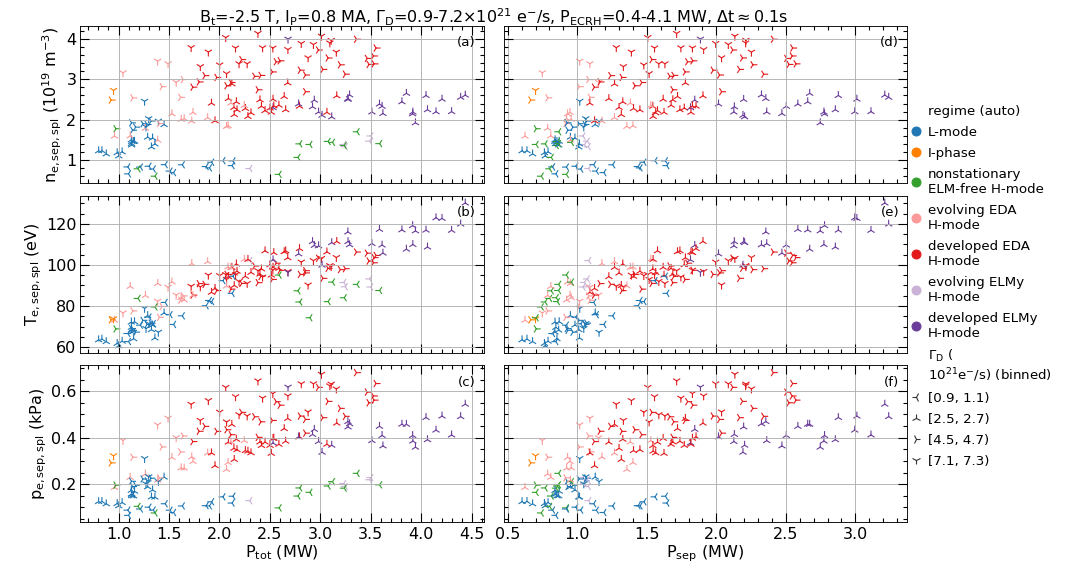

In [62]:
powers = ['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{heat}$ (MW)', label_Psep, 
            '$P_{tot}$-$P_{rad,sepX}$ (MW)', '$P_{tot}$-$P_{rad,main}$ (MW)', 
            '$P_{tot}$/($n_{e}$S) ($10^{-19}$ MW m)']
sep_params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)','$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)','$n_{e,100}$ ($10^{19}m^{-3}$)',
       '$T_{sep}$ (eV)','$T_{sep}^{(m)}$ (eV)','$T_{e,100}$ (keV)',
      '$p_{sep}$ (kPa)','$p_{sep}^{(m)}$ (kPa)','$p_{e,100}$ (kPa)']
g, fig_name= plot_rel_regimes(
    data = data_final_fueling_scan_all[0],
    #write_dt= False,
    #write_Bt= False,
    x = [powers[i]for i in [1,3]],
    y=[sep_params[i] for i in [0, 3, 6]],
    style = label_fueling_binned

)
fig_name

'36124...37193_$R_{sep}$_(m)_$R_{sep}^{(m)}$_(m)_vs_$R_{sep,EQH}$_(m)_by_merged_label_some_auto_$Gamma_{D}$_($10^{21}_e^{-}$s)_(binned)_dt-0.1s'

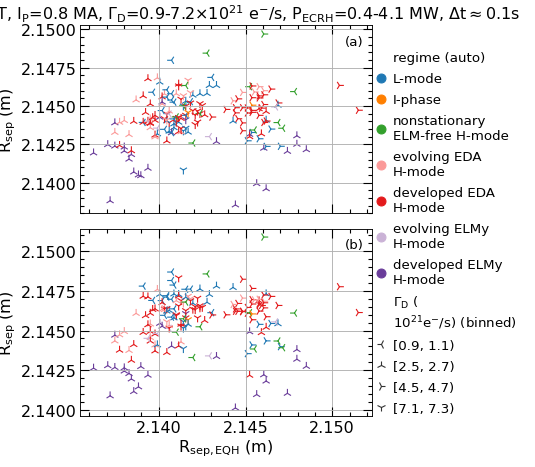

In [58]:
g, fig_name = plot_rel_regimes(
    data = data_final_fueling_scan_all[0],
    #write_dt= False,
    #write_Bt= False,
    x = ['$R_{sep,EQH}$ (m)'],
    y=['$R_{sep}$ (m)', '$R_{sep}^{(m)}$ (m)'],
    style = label_fueling_binned
)
fig_name

In [ ]:
print('Hello')

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

#### Global confinement

In [ ]:
g, fig_name = plot_rel_regimes(
    data=rename_labels_binning_fueling(data_final_fueling_scan_all[0]),
    x=[label_PECRH, label_Ptot, label_Psep, r'$\beta_{N}/H_{98y2}$'][:],
    y=[
        r'$\overline{n_{e}}$ ($10^{19}m^{-3})$', '$f_{GW}$', '$W_{mhd}$ (MJ)', 
        r'$\beta_{N}$', r'$\beta_{pol}$', r'$\tau_{E}$ (ms)', '$H_{98y2}$', 
        label_ptau, r'$\beta_{N} H_{98y2}$', 
        r'$\nu_{e,ped}^{*}$'][:],   
    style=[label_fueling, 'shot'][0], 
    #kind='line', markers=True,
)
#TODO: adicionar fits e/ou linhas com scalings típicos?
#for ax in g.axes.flat:
#    ax.set_xlim(None, 4.5)
#g.ax.set_xlim(0.6, 4.4)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
data_plot = data_final_fueling_scan_all[0]
#data_plot = data_plot[data_plot['merged label some'].isin(['developed EDA H-mode', 'evolving EDA H-mode'][:1])]
data_plot = select_regimes(data_plot)
#data_plot = data_plot.assign(**{'$P_{tot}$ (MW)':pd.cut(data_plot['$P_{tot}$ (MW)'], bins=1.7+np.arange(11)*0.2, right=False)})
g, fig_name = plot_rel_regimes(
    data=data_plot, 
    x=(
        (
            [label_base_gaspuff.format(v) for v in ('D', 'tot')[:1]] + 
            [neutral_flux_label_template.format(i) for i in [3, 4, 14][1:]] + 
            ["F04/F14"][:])
        [:1]),
    y=[
        r'$\overline{n_{e}}$ ($10^{19}m^{-3})$', '$f_{GW}$', '$W_{mhd}$ (MJ)', 
        r'$\beta_{N}$', r'$\beta_{pol}$', r'$\tau_{E}$ (ms)', '$H_{98y2}$', 
        label_ptau, r'$\beta_{N} H_{98y2}$', 
        r'$\nu_{e,ped}^{*}$'][:],
    hue='$P_{tot}$ (MW)', palette="viridis", replace_developed_labels=False,
    #kind='line', markers=True,
)
#TODO: adicionar fits e/ou linhas com scalings típicos?
#for ax in g.axes.flat:
#    ax.set_xlim(0,None)
#    ax.set_ylim(0,None)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

### 0.7 MA

#### Chosen discharges and periods

In [44]:
data_fueling_scan = pd.read_excel(filepath, sheet_name='gas - P (strong, 0.7 MA)')
label_fueling = label_gaspuff
label_fueling_binned = label_fueling + " (binned)"
bins = np.concatenate((1.1+np.arange(18)*0.2, 4.6+np.arange(13)*0.2))#0.9+np.arange(37)*0.2
data_final_fueling_scan_all = []
for data_final in data_final_all:
    #data_final_fueling_scan = data_final.loc[data_final['shot'].isin(data_fueling_scan['shot'])]
    data_final_fueling_scan = (
        data_final.loc[(
            data_final['shot'].isin(data_fueling_scan.loc[data_fueling_scan['shot'] != 38743 , 'shot'])
            | (data_final['shot'] == 38743) & (data_final['t_end (s)'] <= 6))]
        .copy())
    data_final_fueling_scan[label_fueling_binned] = pd.cut(
        data_final_fueling_scan[label_fueling], bins=bins, right=False,
        #labels=sliding_window(bins, 2).mean(axis=-1),
    ).astype(object)
    #data_final_fueling_scan[label_fueling_binned] = data_final_fueling_scan[label_fueling].round(1)
    data_final_fueling_scan.sort_values([label_fueling_binned, 'shot', 't_begin (s)'], inplace=True)
    data_final_fueling_scan.attrs = data_final.attrs
    data_final_fueling_scan_all.append(data_final_fueling_scan)
data_final_fueling_scan_all[0]#.head()

,shot,t_begin (s),t_end (s),label,merged label,merged label some,regime plot order,merged label some auto,regime plot order auto,"($P_{tot}$-$P_{rad,div}$)/$n_{e}$ ($10^{19}$ MW $m^{3}$)","($P_{tot}$-$P_{rad,div}$)/($n_{e}$S) ($10^{19}$ MW m)","($P_{tot}$-$P_{rad,div}$)/R (MW/m)","($P_{tot}$-$P_{rad,div}$)/S (MW/$m^{2}$)","($P_{tot}$-$P_{rad,div}$)/V (MW/$m^{3}$)","($P_{tot}$-$P_{rad,main}$)/$n_{e}$ ($10^{19}$ MW $m^{3}$)","($P_{tot}$-$P_{rad,main}$)/($n_{e}$S) ($10^{19}$ MW m)","($P_{tot}$-$P_{rad,main}$)/R (MW/m)","($P_{tot}$-$P_{rad,main}$)/S (MW/$m^{2}$)","($P_{tot}$-$P_{rad,main}$)/V (MW/$m^{3}$)","($P_{tot}$-$P_{rad,sepX}$)/$n_{e}$ ($10^{19}$ MW $m^{3}$)","($P_{tot}$-$P_{rad,sepX}$)/($n_{e}$S) ($10^{19}$ MW m)","($P_{tot}$-$P_{rad,sepX}$)/R (MW/m)","($P_{tot}$-$P_{rad,sepX}$)/S (MW/$m^{2}$)","($P_{tot}$-$P_{rad,sepX}$)/V (MW/$m^{3}$)","($P_{tot}$-$P_{rad,sep}$)/$n_{e}$ ($10^{19}$ MW $m^{3}$)","($P_{tot}$-$P_{rad,sep}$)/($n_{e}$S) ($10^{19}$ MW m)","($P_{tot}$-$P_{rad,sep}$)/R (MW/m)","($P_{tot}$-$P_{rad,sep}$)/S (MW/$m^{2}$)","($P_{tot}$-$P_{rad,sep}$)/V (MW/$m^{3}$)","($P_{tot}$-$P_{rad,tot}$)/$n_{e}$ ($10^{19}$ MW $m^{3}$)","($P_{tot}$-$P_{rad,tot}$)/($n_{e}$S) ($10^{19}$ MW m)","($P_{tot}$-$P_{rad,tot}$)/R (MW/m)","($P_{tot}$-$P_{rad,tot}$)/S (MW/$m^{2}$)","($P_{tot}$-$P_{rad,tot}$)/V (MW/$m^{3}$)","-$\%_{ile,99.9}$(-$I_{div,outer}$$q_{{cyl}}$) (kA)","-$\%_{ile,99.9}$(-$I_{div,outer}$) (kA)","-$\%_{ile,99.9}$(-$\Delta$$I_{div,outer}$$q_{{cyl}}$) (kA)","-$\%_{ile,99.9}$(-$\Delta$$I_{div,outer}$) (kA)","-max(-$I_{div,outer}$$q_{{cyl}}$) (kA)","-max(-$I_{div,outer}$) (kA)","-max(-$\Delta$$I_{div,outer}$$q_{{cyl}}$) (kA)","-max(-$\Delta$$I_{div,outer}$) (kA)",BPT|Pr_div/@LH,BPT|Pr_main/@LH,BPT|Pr_sep/@LH,BPT|Pr_sepX/@LH,BPT|Pr_tot/@LH,$B_{t}$ (T),DDS|nDivIst/@LH,DDS|nMainIst/@LH,F03 ($10^{22}m^{-2}s^{-1}$),F04 ($10^{22}m^{-2}s^{-1}$),F04/F14,F14 ($10^{22}m^{-2}s^{-1}$),FPC|IpiFP/@LH,GIW|c_W/@LH,GIW|c_W_l/@LH,GQH|XPfdif/@LH,GQH|betpol/@LH,GQH|bver/@LH,GQH|dRXP/@LH,GQH|delRoben/@LH,GQH|delRuntn/@LH,GQH|fax-bnd,GQH|fax-bnd/@LH,GQH|fbnd-ref,GQH|fbnd-ref/@LH,GQH|q0/@LH,GQH|q95/@LH,$H_{98y2}$,ICP|PICRN,ICP|PICRN/@LH,IDA|Te/@LH,IDA|ne/@LH,IDA|pe/@LH,IDZ|Zeff/@LH,IOC|F03/@LH,IOC|F04/@LH,IOC|F14/@LH,"$I_{div,inner}$ (kA)","$I_{div,inner}$$q_{{cyl}}$ (kA)","$I_{div,outer}$ (kA)","$I_{div,outer}$$q_{{cyl}}$ (kA)",$I_{p}$ (MA),MAC|-99.9%ile(-Ipolsola)/@LH,MAC|-max(-Ipolsola)/@LH,MAC|99.9%ile(Ipolsoli)/@LH,MAC|Ipolsola/@LH,MAC|Ipolsoli/@LH,MAC|Tdiv/@LH,MAC|max(Ipolsoli)/@LH,MAC|shapiro(Ipolsola)/@LH,MAC|shapiro(Ipolsoli)/@LH,MAI|BTF/@LH,$P_{ECRH}$ (MW),"$P_{ECRH}$/$P_{ECRH,LH}$",$P_{NBI}$ (MW),"$P_{NBI}$/$P_{NBI,LH}$",$P_{SOL}$ (MW),"$P_{SOL}$/$P_{sep,LH}$",$P_{heat}$ (MW),"$P_{heat}$/$P_{heat,LH}$",$P_{net}$ (MW),"$P_{net}$/$P_{net,LH}$",$P_{ohmic}$ (MW),"$P_{ohmic}$/$P_{ohmic,LH}$","$P_{rad,div(interpolated)}$ (MW)","$P_{rad,div}$ (MW)","$P_{rad,div}$/$P_{tot}$","$P_{rad,main(interpolated)}$ (MW)","$P_{rad,main}$ (MW)","$P_{rad,main}$/$P_{tot}$","$P_{rad,sep(interpolated)}$ (MW)","$P_{rad,sepX(interpolated)}$ (MW)","$P_{rad,sepX}$ (MW)","$P_{rad,sepX}$/$P_{tot}$","$P_{rad,sep}$ (MW)","$P_{rad,sep}$/$P_{tot}$","$P_{rad,tot(interpolated)}$ (MW)","$P_{rad,tot}$ (MW)","$P_{rad,tot}$/$P_{tot}$",$P_{rad}$ (MW),"$P_{rad}$/$P_{rad,LH}$",$P_{rad}$/$P_{tot}$,"$P_{sep,LH}$ (MW)",$P_{tot(interpolated)}$ (MW),$P_{tot}$ (MW),"$P_{tot}$-$P_{rad,div}$ (MW)","$P_{tot}$-$P_{rad,main}$ (MW)","$P_{tot}$-$P_{rad,sepX}$ (MW)","$P_{tot}$-$P_{rad,tot}$ (MW)","$P_{tot}$/$P_{tot,LH}$",$P_{tot}$/$n_{e}$ ($10^{19}$ MW $m^{3}$),$P_{tot}$/($n_{e}$S) ($10^{19}$ MW m),$P_{tot}$/R (MW/m),$P_{tot}$/S (MW/$m^{2}$),$P_{tot}$/V (MW/$m^{3}$),"$P_{tot}/P_{LH,scal}$",$R_{geo}$ (m),$R_{geo}$/a,Rsep_eqh,S ($m^{2}$),TOT|H-1_corr/@LH,TOT|H-5_corr/@LH,TOT|R/a/@LH,TOT|Rgeo/@LH,TOT|Surface/@LH,TOT|Vol/@LH,TOT|Wmhd/@LH,TOT|ahor/@LH,TOT|beta_N/@LH,TOT|dWmhd/dt/@LH,TOT|kappa/@LH,TOT|n/nGW/@LH,TOT|ne_lav,TOT|ne_lav/@LH,TOT|qcyl/@LH,TOT|tau_tot/@LH,TTH|H/L-facs/@LH,TTH|L2H_facs/@LH,T

In [45]:
[col for col in data_final_fueling_scan_all[1].columns if 'Rsep' in col]

[]

#### Input parameters

In [ ]:
table_fueling_scan = table_of_scan(data_final_fueling_scan_all[0], label_fueling)
with pd.option_context('display.float_format', "{:,.2f}".format):
    display(table_fueling_scan)

In [ ]:
print_latex_table(table_fueling_scan, precision=2)

In [ ]:
print_latex_table_iop(table_fueling_scan.drop(columns=label_Ptot), precision=2)

In [ ]:
data_plot = data_final_fueling_scan_all[0]

if data_plot.attrs['dt_subperiod'] == 0.1:# and False:
    # hyperparameter C = 100000
    exponent = 5.8892e-1#5.6239e-01
    #k_raw = 9.35E1
    k_raw = 4.9648e-7#1.9111e-06
elif data_plot.attrs['dt_subperiod'] == 0.05:# or True:
    exponent = 0.55
    #k_raw = 9.35E1
    k_raw = 3.28e-06
else:
    print("fit data missing for this dt (or dt missing)")
    raise
k = k_raw * power_mult / (mult_gaspuff**exponent)
    
y = (
    np.array([
        label_PECRH, label_Ptot, '$P_{heat}$ (MW)', label_Psep, 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', '$P_{tot}$-$P_{rad,main}$ (MW)', 
        '$P_{tot}$/($n_{e}$S) ($10^{-19}$ MW m)', r'$\beta_{N}/H_{98y2}$', 
        '$P_{tot}/P_{LH,scal}$', label_Ptot_normalized_LH, 
        label_Psep_normalized_LH])
    [[0, 1, 3]])

pp, fig_name = plot_rel_regimes(
    data_plot, #shuffle=False, 
    x=(
        (
            [label_base_gaspuff.format(v) for v in ('D', 'tot')[:1]] + 
            [label_neavg_LH][:] + 
            [neutral_flux_label_template.format(i) for i in [3, 4, 14][1:]] + 
            ["F04/F14"][:])
        [:1]), 
    y=y, label_pos_x=0, style='shot', sort_style=False, 
    **final_rel_figure_kw
)
if [True, False][0]:
    ax = pp.axes[y == label_Psep, 0][0]
    xmin, xmax = ax.get_xlim()
    delta_x = xmax - xmin
    x = np.linspace(xmin, xmax)
    #x_annotate = x[0] + 0.1 * delta_x
    x_annotate = 5.25#x[0] + 0.1 * delta_x
    ax.plot(x, k * (x**exponent), color='black', linestyle='--')
    ax.annotate(
        #text=r"{:.2f}$\times${}".format(
        #    k, symbol_base_scaled_Ip.format(exponent)), 
        text=r"$\propto${}$^{{{:.2f}}}$".format(
            symbol_deuterium_gaspuff, exponent),
        xy=(
            x_annotate, 
            k * (x_annotate**exponent) - 0.13 * np.ptp(ax.get_ylim())), 
        rotation=0.5*np.degrees(np.arctan(
            exponent * k * ((x_annotate + 0.1 * delta_x)**(exponent - 1)) 
            / ax.get_data_ratio())))

    data_fit = select_regimes(data_plot, regimes=merged_labels[4:7])
    mask_below_scaling = data_fit[label_Psep] < k * (data_fit[label_gaspuff] ** exponent)
    n_in_agreement = (
        (
            (
                data_fit.loc[mask_below_scaling, "merged label some auto"] 
                == 'developed EDA H-mode')
            .sum())
        + (
            (
                data_fit.loc[~mask_below_scaling, "merged label some auto"] 
                != 'developed EDA H-mode')
            .sum()))
    n_total = len(data_fit)
    print(
        (
            "{} out of {} points with agreeing classification: " + 
            "{:#.3g}% of points in agreement")
        .format(
            n_in_agreement, n_total, 100 * n_in_agreement / n_total))

fig_name

In [ ]:
for fmt in ['png', 'pdf'][:]:
    save_figure(pp.fig, fig_name, format=fmt)

In [ ]:
pp, fig_name = plot_rel_regimes(
    data_final_fueling_scan_all[0], #left=0.15, 
    x=(
        (
            [label_base_gaspuff.format(v) for v in ('D', 'tot')[:1]] + 
            [label_neavg_LH][:] + 
            [neutral_flux_label_template.format(i) for i in [3, 4, 14][1:]] + 
            ["F04/F14"][:])
        [:2]), 
    y=(
        np.array([
            label_PECRH, label_Ptot, '$P_{heat}$ (MW)', label_Psep, 
            '$P_{tot}$-$P_{rad,sepX}$ (MW)', '$P_{tot}$-$P_{rad,main}$ (MW)', 
            '$P_{tot}$/($n_{e}$S) ($10^{-19}$ MW m)', '$P_{tot}/P_{LH,scal}$',
            r'$\beta_{N}/H_{98y2}$'])
        [[0, 1, 3, 4, -2]][:-2]),
    style='shot', sort_style=False, label_pos_x=0,
)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(pp.fig, fig_name, format=fmt)

In [ ]:
hue = np.array([rename(s) for s in [
    'MAC|-99.9%ile(-Ipolsola)',
    'MAC|-max(-Ipolsola)',
    'MAC|99.9%ile(Ipolsoli)',
    'MAC|max(Ipolsoli)',
    'MAC|shapiro(Ipolsola)',
    'MAC|shapiro(Ipolsoli)',
    '|-99.9%ile(-Ipolsola*qcyl)',
    '|-99.9%ile(-Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|-99.9%ile(-Ipolsola-rolling_median_50ms(Ipolsola))',
    '|-max(-Ipolsola*qcyl)',
    '|-max(-Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|-max(-Ipolsola-rolling_median_50ms(Ipolsola))',
    '|99.9%ile(Ipolsoli*qcyl)',
    '|99.9%ile(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|99.9%ile(Ipolsoli-rolling_median_50ms(Ipolsoli))',
    '|Ipolsola*qcyl',
    '|Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl)',
    '|Ipolsola-rolling_median_50ms(Ipolsola)',
    '|Ipolsoli*qcyl',
    '|Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl)',
    '|Ipolsoli-rolling_median_50ms(Ipolsoli)',
    '|max(Ipolsoli*qcyl)',
    '|max(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|max(Ipolsoli-rolling_median_50ms(Ipolsoli))',
    '|qcyl_interp_Ipolsol',
    '|rolling_median_50ms(Ipolsola)',
    '|rolling_median_50ms(Ipolsola*qcyl)',
    '|rolling_median_50ms(Ipolsoli)',
    '|rolling_median_50ms(Ipolsoli*qcyl)',
    '|shapiro(Ipolsola*qcyl)',
    '|shapiro(Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|shapiro(Ipolsola-rolling_median_50ms(Ipolsola))',
    '|shapiro(Ipolsoli*qcyl)',
    '|shapiro(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|shapiro(Ipolsoli-rolling_median_50ms(Ipolsoli))']])[4]#[30]#[4]
palette = 'viridis_r' if any(name in labels_dict_inverted[hue] for name in ['Ipolsola', 'shapiro']) else 'viridis'#'Ipolsola' in hue else 'viridis'
i = hue.index("(") + 1
pp, fig_name = plot_rel_regimes(
    data_final_fueling_scan_all[0], #left=0.15, 
    x=(
        (
            [label_base_gaspuff.format(v) for v in ('D', 'tot')[:1]] + 
            [label_neavg_LH][:] + 
            [neutral_flux_label_template.format(i) for i in [3, 4, 14][1:]] + 
            ["F04/F14"][:])
        [:2]), 
    y=(
        np.array([
            label_PECRH, label_Ptot, '$P_{heat}$ (MW)', label_Psep, 
            '$P_{tot}$-$P_{rad,sepX}$ (MW)', '$P_{tot}$-$P_{rad,main}$ (MW)', 
            '$P_{tot}$/($n_{e}$S) ($10^{-19}$ MW m)'])
        [[0, 1, 3, 4][:-1]]),
    hue=hue, #
    palette=palette, 
    legend_hue_title=(
        hue[:i] + "\n" + hue[i:] 
        if (len(hue.translate(str.maketrans('', '', r'\$_{}'))) > 26 if "$" in hue else len(hue) > 15 ) 
        else None),
    auto_classification=False,
    #wrap_hue_title=False,#n_wrap=20,
    #style='shot', label_pos_x=0,
    #shuffle=False, 
)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(pp.fig, fig_name, format=fmt)

In [ ]:
pp, fig_name = plot_rel_regimes_hue_shapiro_log(
    data_final_fueling_scan_all[0], #shuffle=False, #left=0.15, 
    x=(
        (
            [label_base_gaspuff.format(v) for v in ('D', 'tot')[:1]] + 
            [label_neavg_LH][:] + 
            [neutral_flux_label_template.format(i) for i in [3, 4, 14][1:]] + 
            ["F04/F14"][:])
        [:2]), 
    y=(
        np.array([
            label_PECRH, label_Ptot, '$P_{heat}$ (MW)', label_Psep, 
            '$P_{tot}$-$P_{rad,sepX}$ (MW)', '$P_{tot}$-$P_{rad,main}$ (MW)', 
            '$P_{tot}$/($n_{e}$S) ($10^{-19}$ MW m)'])
        [[0, 1, 3, 4][:-1]]),
    auto_classification=False,
)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(pp.fig, fig_name, format=fmt)

In [ ]:
pp, fig_name = plot_rel_EDA_ELMs_hue_shapiro_log(
    data_final_fueling_scan_all[0], replace_developed_labels=False,#shuffle=False, #left=0.15, 
    x=(
        (
            [label_base_gaspuff.format(v) for v in ('D', 'tot')[:1]] + 
            [label_neavg_LH][:] + 
            [neutral_flux_label_template.format(i) for i in [3, 4, 14][1:]] + 
            ["F04/F14"][:])
        [:2]), 
    y=(
        np.array([
            label_PECRH, label_Ptot, '$P_{heat}$ (MW)', label_Psep, 
            '$P_{tot}$-$P_{rad,sepX}$ (MW)', '$P_{tot}$-$P_{rad,main}$ (MW)', 
            '$P_{tot}$/($n_{e}$S) ($10^{-19}$ MW m)'])
        [[0, 1, 3, 4][:-1]]), 
    auto_classification=False,
)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(pp.fig, fig_name, format=fmt)

In [ ]:
y = np.array([rename(s) for s in [
    'MAC|-99.9%ile(-Ipolsola)',
    'MAC|-max(-Ipolsola)',
    'MAC|99.9%ile(Ipolsoli)',
    'MAC|max(Ipolsoli)',
    'MAC|shapiro(Ipolsola)',
    'MAC|shapiro(Ipolsoli)',
    '|-99.9%ile(-Ipolsola*qcyl)',
    '|-99.9%ile(-Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|-99.9%ile(-Ipolsola-rolling_median_50ms(Ipolsola))',
    '|-max(-Ipolsola*qcyl)',
    '|-max(-Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|-max(-Ipolsola-rolling_median_50ms(Ipolsola))',
    '|99.9%ile(Ipolsoli*qcyl)',
    '|99.9%ile(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|99.9%ile(Ipolsoli-rolling_median_50ms(Ipolsoli))',
    '|Ipolsola*qcyl',
    '|Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl)',
    '|Ipolsola-rolling_median_50ms(Ipolsola)',
    '|Ipolsoli*qcyl',
    '|Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl)',
    '|Ipolsoli-rolling_median_50ms(Ipolsoli)',
    '|max(Ipolsoli*qcyl)',
    '|max(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|max(Ipolsoli-rolling_median_50ms(Ipolsoli))',
    '|qcyl_interp_Ipolsol',
    '|rolling_median_50ms(Ipolsola)',
    '|rolling_median_50ms(Ipolsola*qcyl)',
    '|rolling_median_50ms(Ipolsoli)',
    '|rolling_median_50ms(Ipolsoli*qcyl)',
    '|shapiro(Ipolsola*qcyl)',
    '|shapiro(Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|shapiro(Ipolsola-rolling_median_50ms(Ipolsola))',
    '|shapiro(Ipolsoli*qcyl)',
    '|shapiro(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|shapiro(Ipolsoli-rolling_median_50ms(Ipolsoli))']])[[4, 6]]#[[-5, 4]]#[[-5, 4]]
pp, fig_name = plot_rel_regimes(
    data_final_fueling_scan_all[0], #left=0.15, 
    x=(
        (
            [label_base_gaspuff.format(v) for v in ('D', 'tot')[:1]] + 
            [neutral_flux_label_template.format(i) for i in [3, 4, 14][1:]] + 
            ["F04/F14"][:])
        [:1]), 
    y=y,
    #hue=hue, palette=palette,
    auto_classification=False,
    style='shot', sort_style=False, #label_pos_x=0,
    left=0.16, #shuffle=False,
)
for ax, quantity in zip(pp.axes.flatten(), np.atleast_1d(y)):
    print(quantity)
    ax.set_ylim(
        0.93 if shapiro_symbol in quantity else -15 if 'Delta' in quantity else -30, 
        1 if shapiro_symbol in quantity else 0)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(pp.fig, fig_name, format=fmt)

In [ ]:
y = np.array([rename(s) for s in [
    'MAC|-99.9%ile(-Ipolsola)',
    'MAC|-max(-Ipolsola)',
    'MAC|99.9%ile(Ipolsoli)',
    'MAC|max(Ipolsoli)',
    'MAC|shapiro(Ipolsola)',
    'MAC|shapiro(Ipolsoli)',
    '|-99.9%ile(-Ipolsola*qcyl)',
    '|-99.9%ile(-Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|-99.9%ile(-Ipolsola-rolling_median_50ms(Ipolsola))',
    '|-max(-Ipolsola*qcyl)',
    '|-max(-Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|-max(-Ipolsola-rolling_median_50ms(Ipolsola))',
    '|99.9%ile(Ipolsoli*qcyl)',
    '|99.9%ile(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|99.9%ile(Ipolsoli-rolling_median_50ms(Ipolsoli))',
    '|Ipolsola*qcyl',
    '|Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl)',
    '|Ipolsola-rolling_median_50ms(Ipolsola)',
    '|Ipolsoli*qcyl',
    '|Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl)',
    '|Ipolsoli-rolling_median_50ms(Ipolsoli)',
    '|max(Ipolsoli*qcyl)',
    '|max(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|max(Ipolsoli-rolling_median_50ms(Ipolsoli))',
    '|qcyl_interp_Ipolsol',
    '|rolling_median_50ms(Ipolsola)',
    '|rolling_median_50ms(Ipolsola*qcyl)',
    '|rolling_median_50ms(Ipolsoli)',
    '|rolling_median_50ms(Ipolsoli*qcyl)',
    '|shapiro(Ipolsola*qcyl)',
    '|shapiro(Ipolsola*qcyl-rolling_median_50ms(Ipolsola*qcyl))',
    '|shapiro(Ipolsola-rolling_median_50ms(Ipolsola))',
    '|shapiro(Ipolsoli*qcyl)',
    '|shapiro(Ipolsoli*qcyl-rolling_median_50ms(Ipolsoli*qcyl))',
    '|shapiro(Ipolsoli-rolling_median_50ms(Ipolsoli))']])[[7, 10]]#[[6, 9]]

data_plot = data_final_fueling_scan_all[0]

pp, fig_name = plot_rel_regimes(
    data_plot.assign(**{
        't_begin (s)':(
            pd.cut(data_plot['t_begin (s)'], bins=20, right=False)
            .astype(object))}),
    x=(
        (
            [label_base_gaspuff.format(v) for v in ('D', 'tot')[:1]] + 
            [neutral_flux_label_template.format(i) for i in [3, 4, 14][1:]] + 
            ["F04/F14"][:])
        [:1]), 
    y=y, #regime_order=['developed EDA H-mode'],
    hue='t_begin (s)', palette=palette, legend='full',
    auto_classification=False,
    #style=['shot', 't_begin (s)'][1], #label_pos_x=0,
    left=0.16,
)
if True:
    for ax in pp.axes.flatten():
        ax.set_ylim(-15, None)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(pp.fig, fig_name, format=fmt)

In [ ]:
pp, fig_name = plot_rel_regimes(
    data_final_fueling_scan_all[0], #left=0.15, 
    x=(
        (
            [label_base_gaspuff.format(v) for v in ('D', 'tot')[:1]] + 
            [neutral_flux_label_template.format(i) for i in [3, 4, 14][1:]] + 
            ['$p_{0, div}$ (a.u.)', '$p_{0, main}$ (a.u.)'][:0] + 
            ["F04/F14"][:])
        [:]), 
    y=(
        np.array([
            '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{heat}$ (MW)', label_Psep, 
            '$P_{tot}$-$P_{rad,sepX}$ (MW)', '$P_{tot}$-$P_{rad,main}$ (MW)', 
            '$P_{tot}$/($n_{e}$S) ($10^{-19}$ MW m)'])
        [:-1]),
    style='shot', sort_style=False,
)
#pp.axes[1,0].set_ylim(None, 4.5)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(pp.fig, fig_name, format=fmt)

#### Core and pedestal

##### IDA vs stuff

In [ ]:
[col for col in data_final_fueling_scan_all[0].columns if '100' in col.lower()]

In [ ]:
data_IDA_fueling_melted_all = melt_IDA(
    data_final_fueling_scan_all, label_fueling_binned)
data_IDA_fueling_melted_all[0]
[col for col in data_IDA_fueling_melted_all[0].columns if '100' in col.lower()]

In [ ]:
g, fig_name = plot_rel_regimes_IDA_style_gas(
    data_IDA_fueling_melted_all[0], write_dt=False, #origin=True,
    x=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],) 
fig_name

In [ ]:
g, fig_name = plot_rel_regimes_IDA_style_gas(
    data_IDA_fueling_melted_all[0], #col_order=[0, 0.2], facet_kws=dict(sharey='row'), #origin=True,
    x=[
        '$P_{ECRH}$ (MW)', label_Ptot, label_Psep, 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
    **final_rel_figure_kw) 
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_regimes_IDA_style_gas(
    data_IDA_fueling_melted_all[0], #origin=True,
    x=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', label_Psep, 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][2])
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_regimes_IDA(
    data_IDA_fueling_melted_all[0], style='shot', sort_style=False, #origin=True,
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)', '$p_{0, main}$ (a.u.)'][0])
fig_name

#### Separatrix (Fits)

##### Ne, Te and pe scatter plots

'38049...38744_$n_{sep}$_($10^{19}$_m$^{-3}$)_$T_{sep}$_(eV)_$p_{sep}$_(kPa)_vs_P_TOT_P_TOT-Pr_sep_by_merged_label_some_auto_$Gamma_{D}$_($10^{21}_e^{-}$s)_(binned)_dt-0.1s'

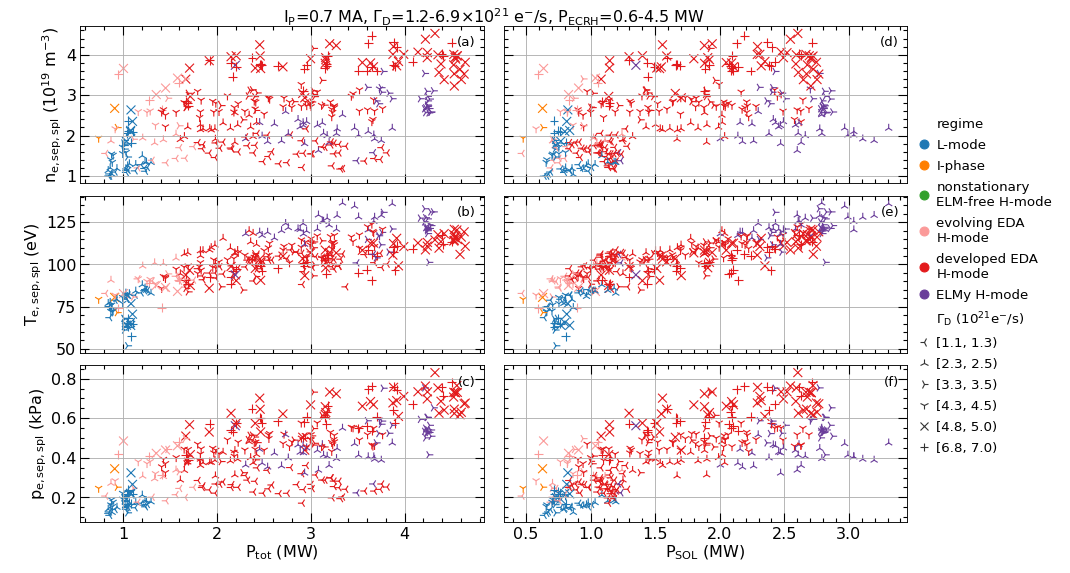

In [315]:
powers = ['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{heat}$ (MW)', label_Psep, 
            '$P_{tot}$-$P_{rad,sepX}$ (MW)', '$P_{tot}$-$P_{rad,main}$ (MW)', 
            '$P_{tot}$/($n_{e}$S) ($10^{-19}$ MW m)']
sep_params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)','$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)','$n_{e,100}$ ($10^{19}m^{-3}$)',
       '$T_{sep}$ (eV)','$T_{sep}^{(m)}$ (eV)','$T_{e,100}$ (keV)',
      '$p_{sep}$ (kPa)','$p_{sep}^{(m)}$ (kPa)','$p_{e,100}$ (kPa)']
g, fig_name = plot_rel_regimes(
    data = data_final_fueling_scan_all[0],
    write_dt= False,
    write_Bt= False,
    x = [powers[i]for i in [1,3]],
    y=[sep_params[i] for i in [0, 3, 6]],
    style = label_fueling_binned,
    legend_hue_title='regime',
    legend_style_title='$\\Gamma_{D}$ ($10^{21}  e^{-}$/s)',

)
fig_name

In [316]:
save_figure(g.fig, fig_name, format='pdf', directory = '/shares/users/work/joanune/Desktop/TESE_Joao_Pedro_Nunes/chapters/Results/Fueling/figures')

Figure saved to /shares/users/work/joanune/Desktop/TESE_Joao_Pedro_Nunes/chapters/Results/Fueling/figures/38049...38744_$n_{sep}$_($10^{19}$_m$^{-3}$)_$T_{sep}$_(eV)_$p_{sep}$_(kPa)_vs_P_TOT_P_TOT-Pr_sep_by_merged_label_some_auto_$Gamma_{D}$_($10^{21}_e^{-}$s)_(binned)_dt-0.1s.pdf


'38049...38744_$n_{sep}$_($10^{19}$_m$^{-3}$)_$T_{sep}$_(eV)_$p_{sep}$_(kPa)_vs_D_tot_by_P_TOT_merged_label_some_auto_dt-0.1s'

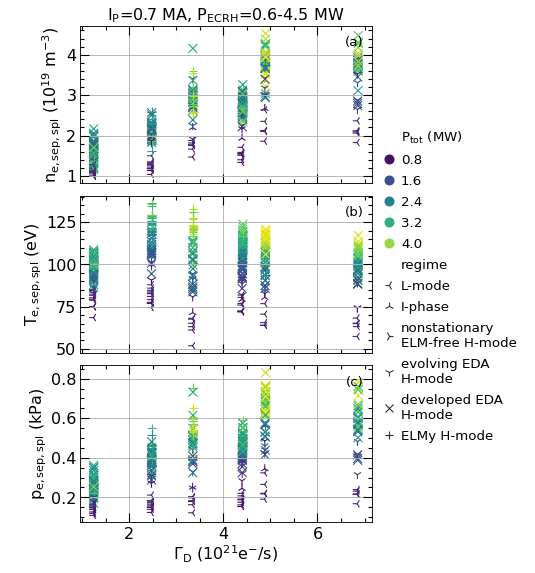

In [ ]:
powers = ['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{heat}$ (MW)', label_Psep, 
            '$P_{tot}$-$P_{rad,sepX}$ (MW)', '$P_{tot}$-$P_{rad,main}$ (MW)', 
            '$P_{tot}$/($n_{e}$S) ($10^{-19}$ MW m)']
sep_params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)','$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)','$n_{e,100}$ ($10^{19}m^{-3}$)',
       '$T_{sep}$ (eV)','$T_{sep}^{(m)}$ (eV)','$T_{e,100}$ (keV)',
      '$p_{sep}$ (kPa)','$p_{sep}^{(m)}$ (kPa)','$p_{e,100}$ (kPa)']
g, fig_name = plot_rel_regimes(
    data = data_final_fueling_scan_all[0],
    write_dt= False,
    write_Bt= False,
    x = label_fueling,
    y=[sep_params[i] for i in [0, 3, 6]],
    #style = label_fueling_binned,
    hue = powers[1],
    legend_style_title='regime',
    #legend_hue_title='regime',
    #legend_style_title='$\\Gamma_{D}$ ($10^{21}  e^{-}$/s)',

)
fig_name

##### Lambdas

'38049...38744_$lambda_T$_(mm)_$lambda_n$_(mm)_$lambda_p$_(mm)_vs_P_TOT_P_TOT-Pr_sep_by_merged_label_some_auto_dt-0.1s'

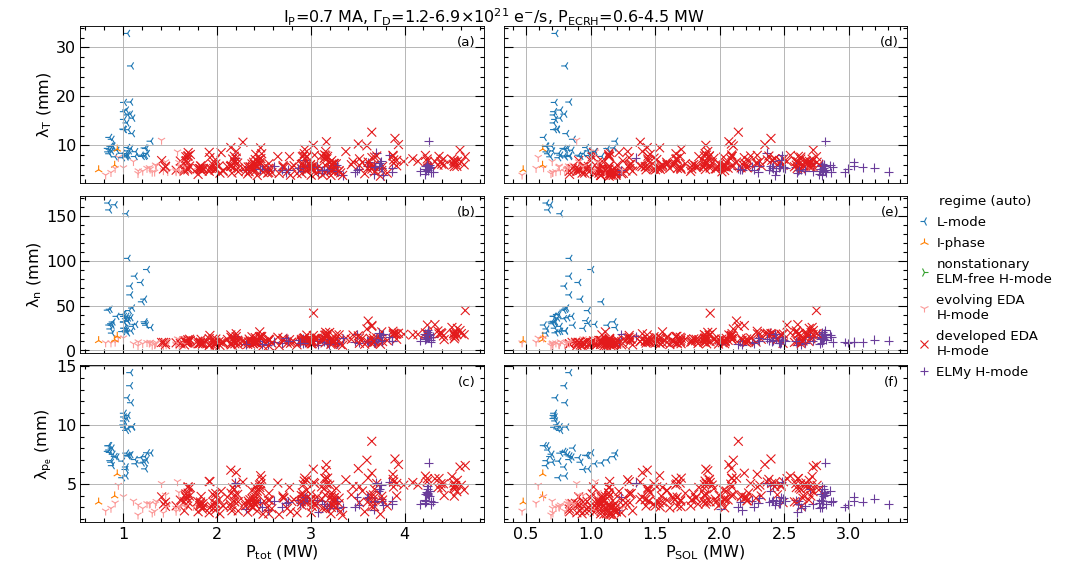

In [324]:
sep_params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)','$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)','$n_{e,100}$ ($10^{19}m^{-3}$)',
       '$T_{sep}$ (eV)','$T_{sep}^{(m)}$ (eV)','$T_{e,100}$ (keV)',
      '$p_{sep}$ (kPa)','$p_{sep}^{(m)}$ (kPa)','$p_{e,100}$ (kPa)',
         '$\\lambda_T$ (mm)','$\\lambda_T^{(m)}$ (mm)','$\\lambda_n$ (mm)',
        '$\\lambda_n^{(m)}$ (mm)','$\\lambda_p$ (mm)','$\\lambda_p^{(m)}$ (mm)']
powers = ['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{heat}$ (MW)', label_Psep, 
            '$P_{tot}$-$P_{rad,sepX}$ (MW)', '$P_{tot}$-$P_{rad,main}$ (MW)', 
            '$P_{tot}$/($n_{e}$S) ($10^{-19}$ MW m)']
g, fig_name = plot_rel_regimes(
    data = data_final_fueling_scan_all[0],
    write_dt= False,
    write_Bt= False,
    y = [sep_params[i]for i in [9,11,13]],
    x=[powers[i] for i in [1,3]],
    #legend_style_title='regime',
    #hue = label_fueling_binned,
    #style = label_fueling_binned

)
fig_name


In [317]:
merged_labels

['L-mode',
 'I-phase',
 'nonstationary ELM-free H-mode',
 'evolving EDA H-mode',
 'developed EDA H-mode',
 'evolving ELMy H-mode',
 'developed ELMy H-mode']

'38049...38744_$lambda_T$_(mm)_$lambda_n$_(mm)_$lambda_p$_(mm)_vs_D_tot_by_P_TOT_merged_label_some_auto_dt-0.1s'

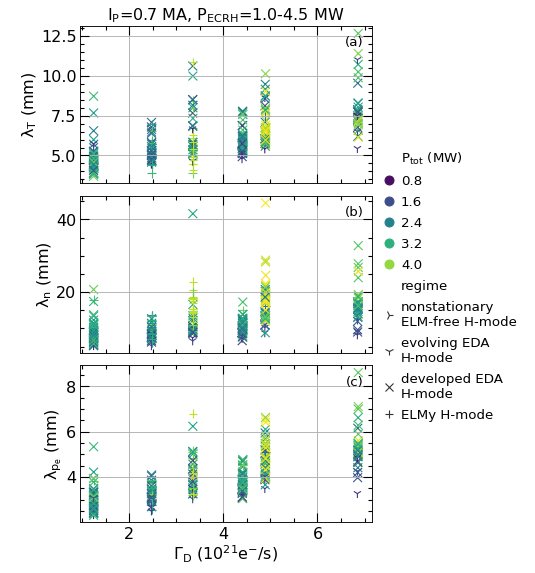

In [322]:
sep_params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)','$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)','$n_{e,100}$ ($10^{19}m^{-3}$)',
       '$T_{sep}$ (eV)','$T_{sep}^{(m)}$ (eV)','$T_{e,100}$ (keV)',
      '$p_{sep}$ (kPa)','$p_{sep}^{(m)}$ (kPa)','$p_{e,100}$ (kPa)',
         '$\\lambda_T$ (mm)','$\\lambda_T^{(m)}$ (mm)','$\\lambda_n$ (mm)',
        '$\\lambda_n^{(m)}$ (mm)','$\\lambda_p$ (mm)','$\\lambda_p^{(m)}$ (mm)']
powers = ['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{heat}$ (MW)', label_Psep, 
            '$P_{tot}$-$P_{rad,sepX}$ (MW)', '$P_{tot}$-$P_{rad,main}$ (MW)', 
            '$P_{tot}$/($n_{e}$S) ($10^{-19}$ MW m)']
regimes= ['L-mode', 'I-phase', 'nonstationary ELM-free H-mode', 'evolving EDA H-mode',
 'developed EDA H-mode', 'evolving ELMy H-mode', 'developed ELMy H-mode']
g, fig_name = plot_rel_regimes(
    data = select_regimes(
        data_final_fueling_scan_all[0],
        regimes=merged_labels[2:],  # pick the regimes
        label='merged label some auto'),
    write_dt= False,
    write_Bt= False,
    y = [sep_params[i]for i in [9,11,13]],
    x=label_fueling,
    hue = powers[1],
    legend_style_title='regime',
    #style = label_fueling_binned

)
#g.axes.flat[0].set_ylim(0, 15)
#g.axes.flat[1].set_ylim(0, 50)
#g.axes.flat[2].set_ylim(0, 10)
fig_name

##### Rsep

In [ ]:
[col for col in data_final_fueling_scan_all[0].columns if 'R_{sep' in col]

'38049...38744_$R_{sep}$_(m)_$R_{sep}^{(m)}$_(m)_vs_$R_{sep,EQH}$_(m)_by_$Gamma_{D}$_($10^{21}_e^{-}$s)_(binned)_merged_label_some_auto_dt-0.1s'

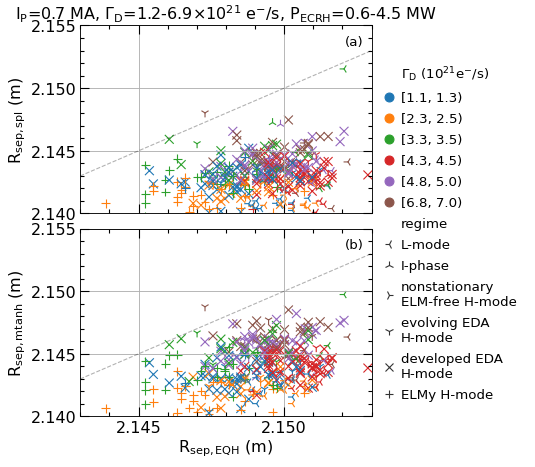

In [326]:
g, fig_name = plot_rel_regimes(
    data = data_final_fueling_scan_all[0],
    write_dt= False,
    write_Bt= False,
    x = ['$R_{sep,EQH}$ (m)'],
    y=['$R_{sep}$ (m)', '$R_{sep}^{(m)}$ (m)'],
    style = None,
    hue= label_fueling_binned,
    legend_hue_title='$\\Gamma_{D}$ ($10^{21}  e^{-}$/s)',
    legend_style_title='regime',
    #wspace=1,
    #title_kw={'pad': 20},
    #top=0.8,
    #adjust_plot_kw={'figsize': (8, 6)}
)
# Add diagonal reference line y=x
for ax in g.axes.flat:
    lim = [np.min([ax.get_xlim(), ax.get_ylim()]),
           np.max([ax.get_xlim(), ax.get_ylim()])]
    ax.plot(lim, lim, 'k--', alpha=0.3, linewidth=1)
    ax.set_xticks(ax.get_yticks())
    ax.set_ylim(2.14, 2.155)
    ax.set_xlim(2.143, 2.153)
fig_name

In [241]:
save_figure(g.fig, fig_name,
            format='pdf',
            directory = '/shares/users/work/joanune/Desktop/TESE_Joao_Pedro_Nunes/chapters/Results/Fueling/figures')

Figure saved to /shares/users/work/joanune/Desktop/TESE_Joao_Pedro_Nunes/chapters/Results/Fueling/figures/38049...38744_$R_{sep}$_(m)_$R_{sep}^{(m)}$_(m)_vs_$R_{sep,EQH}$_(m)_by_$Gamma_{D}$_($10^{21}_e^{-}$s)_(binned)_merged_label_some_auto_dt-0.1s.pdf


'38049...38744_$R_{sep}$_(m)_$R_{sep}^{(m)}$_(m)_vs_$R_{sep,EQH}$_(m)_by_merged_label_some_auto_$Gamma_{D}$_($10^{21}_e^{-}$s)_(binned)_dt-0.1s'

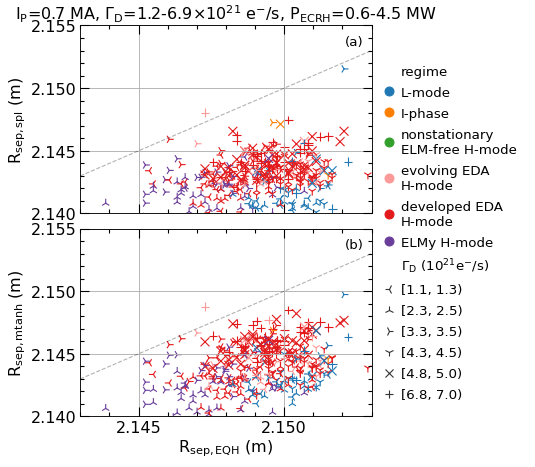

In [327]:
g, fig_name = plot_rel_regimes(
    data = data_final_fueling_scan_all[0],
    write_dt= False,
    write_Bt= False,
    x = ['$R_{sep,EQH}$ (m)'],
    y=['$R_{sep}$ (m)', '$R_{sep}^{(m)}$ (m)'],
    #style = None,
    style= label_fueling_binned,
    legend_style_title='$\\Gamma_{D}$ ($10^{21}  e^{-}$/s)',
    legend_hue_title='regime',
    #wspace=1,
    #title_kw={'pad': 20},
    #top=0.8,
    #adjust_plot_kw={'figsize': (8, 6)}
)
# Add diagonal reference line y=x
for ax in g.axes.flat:
    lim = [np.min([ax.get_xlim(), ax.get_ylim()]),
           np.max([ax.get_xlim(), ax.get_ylim()])]
    ax.plot(lim, lim, 'k--', alpha=0.3, linewidth=1)
    ax.set_xticks(ax.get_yticks())
    ax.set_ylim(2.14, 2.155)
    ax.set_xlim(2.143, 2.153)
fig_name

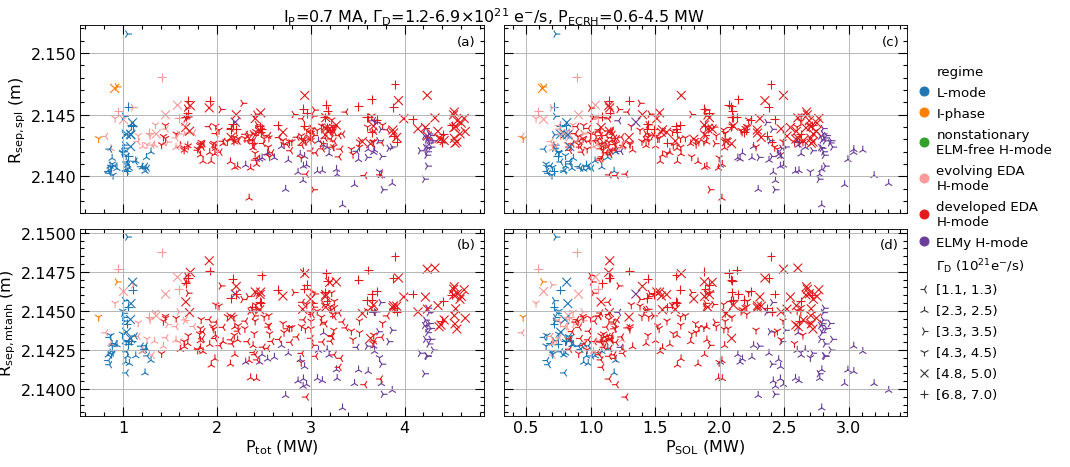

In [328]:
g, fig_name = plot_rel_regimes(
    data = data_final_fueling_scan_all[0],
    write_dt= False,
    write_Bt= False,
    x = [powers[i] for i in [1,3]],
    y=['$R_{sep}$ (m)', '$R_{sep}^{(m)}$ (m)'],
    #style = None,
    style= label_fueling_binned,
    legend_style_title='$\\Gamma_{D}$ ($10^{21}  e^{-}$/s)',
    legend_hue_title='regime',
    #wspace=1,
    #title_kw={'pad': 20},
    #top=0.8,
    #adjust_plot_kw={'figsize': (8, 6)}
)

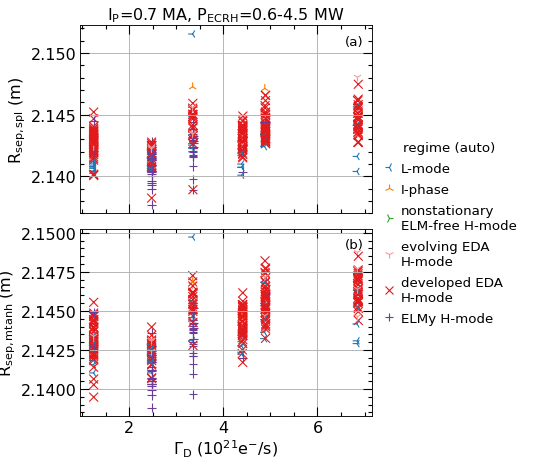

In [48]:
g, fig_name = plot_rel_regimes(
    data = data_final_fueling_scan_all[0],
    write_dt= False,
    write_Bt= False,
    x = label_fueling,
    y=['$R_{sep}$ (m)', '$R_{sep}^{(m)}$ (m)'],
    #style = None,
    #style= label_fueling_binned,
    #legend_style_title='$\\Gamma_{D}$ ($10^{21}  e^{-}$/s)',
    #legend_hue_title='regime',
    #wspace=1,
    #title_kw={'pad': 20},
    #top=0.8,
    #adjust_plot_kw={'figsize': (8, 6)}
)

#### ne_sep

In [ ]:
# Separatrix plasma parameters at Ip=0.7 MA (shot style)
g, fig_name = plot_rel_regimes_IDA(
    data=data_IDA_fueling_melted_all[0], 
    write_dt=False,
    style='shot', sort_style=False,
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)', '$p_{0, main}$ (a.u.)'][0], 
    col_order=[1.0],  # Select the separatrix
    row_order="${}_{{e}}$ ({})".format("n", "$10^{19}m^{-3}$")
)
fig_name

In [ ]:
# Separatrix plasma parameters at Ip=0.7 MA (shot style)
g, fig_name = plot_rel_regimes(
    data=data_final_fueling_scan_all[0], 
    style='shot', sort_style=False,
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)', '$p_{0, main}$ (a.u.)'][0:2], 
    y=['$n_{e,95}$ ($10^{19}m^{-3}$)','$n_{e,100}$ ($10^{19}m^{-3}$)']
)
fig_name

In [ ]:
[col for col in data_final_fueling_scan_all[0].columns if 'kPa' in col]

In [ ]:
# Separatrix plasma parameters at Ip=0.7 MA (shot style)
g, fig_name = plot_rel_regimes(
    data=data_final_fueling_scan_all[0], 
    style='shot', sort_style=False,
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)', '$p_{0, main}$ (a.u.)'][0], 
    y=['$n_{sep}$ ($10^{19}$ m$^{-3}$)','$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)','$n_{e,100}$ ($10^{19}m^{-3}$)']
)
fig_name

In [ ]:
# Separatrix plasma parameters at Ip=0.7 MA (shot style)
g, fig_name = plot_rel_regimes(
    data=data_final_fueling_scan_all[0], 
    style='shot', sort_style=False,
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)', '$p_{0, main}$ (a.u.)'][0], 
    y=['$T_{sep}$ (eV)','$T_{sep}^{(m)}$ (eV)','$T_{e,100}$ (keV)']
)
fig_name

In [ ]:
# Separatrix plasma parameters at Ip=0.7 MA (shot style)
g, fig_name = plot_rel_regimes(
    data=data_final_fueling_scan_all[0], 
    style='shot', sort_style=False,
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)', '$p_{0, main}$ (a.u.)'][0], 
    y=['$p_{sep}$ (kPa)','$p_{sep}^{(m)}$ (kPa)','$p_{e,100}$ (kPa)']
)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_regimes_IDA(
    data_IDA_fueling_melted_all[0], #origin=True,
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)', '$p_{0, main}$ (a.u.)'][0],
    hue=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1])
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
# Separatrix plasma parameters at Ip=0.7 MA (hue:P_tot)
g, fig_name = plot_rel_regimes_IDA(
    data_IDA_fueling_melted_all[0], #origin=True,
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)', '$p_{0, main}$ (a.u.)'][0],
    hue=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
    col_order=[1.0])
fig_name

In [ ]:
g, fig_name = plot_rel_regimes_IDA(
    data_IDA_fueling_melted_all[0], #origin=True,
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)', '$p_{0, main}$ (a.u.)'][0],
    hue=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][3])
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
# Separatrix plasma parameters at Ip=0.7 MA (hue:P_tot - P_rad,sep, multi-regime)
g, fig_name = plot_rel_regimes_IDA(
    data_IDA_fueling_melted_all[0], #origin=True,
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)', '$p_{0, main}$ (a.u.)'][0],
    hue=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][3],
        col_order=[1.0])
fig_name

In [ ]:
g, fig_name = plot_rel_EDA_IDA(
    data=data_IDA_fueling_melted_all[0], label_pos_y=1, 
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)', '$p_{0, main}$ (a.u.)'][0],
    hue=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1])
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
# Separatrix plasma parameters at Ip=0.7 MA (hue:P_tot, developed EDA H-mode)
g, fig_name = plot_rel_EDA_IDA(
    data=data_IDA_fueling_melted_all[0], label_pos_y=1, 
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)', '$p_{0, main}$ (a.u.)'][0],
    hue=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1],
        col_order=[0.95,1.0],
)
fig_name

In [ ]:
g, fig_name = plot_rel_EDA_IDA(
    data=data_IDA_fueling_melted_all[0],  label_pos_y=1,
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)', '$p_{0, main}$ (a.u.)'][0],
    hue=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][3])
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
# Separatrix plasma parameters at Ip=0.7 MA (hue:P_tot, developed EDA H-mode)
g, fig_name = plot_rel_EDA_IDA(
    data=data_IDA_fueling_melted_all[0], label_pos_y=1, 
    x=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)', '$p_{0, main}$ (a.u.)'][0],
    hue=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][3],
        col_order=[1.0])
fig_name

In [ ]:
g, fig_name = plot_rel_regimes_IDA(
    data_IDA_fueling_melted_all[0], #origin=True,
    hue=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)', '$p_{0, main}$ (a.u.)'][0], 
    x=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)'][1])
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_regimes_IDA(
    data_IDA_fueling_melted_all[0], #origin=True,
    hue=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)', '$p_{0, main}$ (a.u.)'][0], 
    x=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)'][3])
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_EDA_IDA(
    data=data_IDA_fueling_melted_all[0], 
    hue=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)', '$p_{0, main}$ (a.u.)'][0],
    x=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1])
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_EDA_IDA(
    data=data_IDA_fueling_melted_all[0], 
    hue=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)', '$p_{0, main}$ (a.u.)'][0],
    x=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][3])
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

##### Te vs ne

In [ ]:
g, fig_name = plot_rel_regimes_Te_vs_ne(
    rename_labels_binning_fueling(data_final_fueling_scan_all[0]), 
    style=[label_fueling, 'shot'][0])

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_regimes_Te_vs_ne(
    data_final_fueling_scan_all[0], 
    hue=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1])

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_regimes_Te_vs_ne(
    data_final_fueling_scan_all[0], 
    hue=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][3])

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_EDA_Te_vs_ne(
    data_final_fueling_scan_all[0], 
    hue=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1])
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_EDA_Te_vs_ne(
    data_final_fueling_scan_all[0], 
    hue=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][3])
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_regimes_Te_vs_ne(
    data_final_fueling_scan_all[0], 
    hue=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)', '$p_{0, main}$ (a.u.)'][0])

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_EDA_Te_vs_ne(
    data_final_fueling_scan_all[0], 
    hue=[label_fueling, 'F03 ($10^{22}m^{-2}s^{-1}$)', '$p_{0, div}$ (a.u.)', '$p_{0, main}$ (a.u.)'][0])
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

##### beta vs nu

In [ ]:
#TODO: desenhar os pontos do EDA por cima do resto (seria fácil usando o argumento 'key' 
#      do pd.DataFrame.sort_values, mas esta verão não tem)
#TODO: curvas de nível de quantidades que dependem de beta_pol e nuestar_ped?
g, fig_name = plot_rel_regimes(
    data=rename_labels_binning_fueling(data_final_fueling_scan_all[0]),
    x=[r'$\nu_{e,ped}^{*}$', '$f_{GW}$'][:], 
    y=[r'$\beta_{pol}$', r'$\beta_{N}$'][:],
    style=[label_fueling, 'shot'][0], label_pos_y=0,
    #n_cols_eff=1.2, 
    n_wrap=20,
    #n_cols_eff=1.6, n_wrap=40, left=0.15,
    #kind='line', markers=True,
)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

#### Global confinement

In [ ]:
g, fig_name = plot_rel_regimes(
    data=rename_labels_binning_fueling(data_final_fueling_scan_all[0]),#.query('shot == 38049'),
    x=[label_PECRH, label_Ptot, label_Psep, r'$\beta_{N}/H_{98y2}$'][:],
    y=[
        r'$\overline{n_{e}}$ ($10^{19}m^{-3})$', '$f_{GW}$', '$W_{mhd}$ (MJ)', 
        r'$\beta_{N}$', r'$\beta_{pol}$', r'$\tau_{E}$ (ms)', '$H_{98y2}$', 
        label_ptau, r'$\beta_{N} H_{98y2}$', 
        r'$\nu_{e,ped}^{*}$'][:],   
    style=[label_fueling, 'shot'][0], 
    #kind='line', markers=True,
)
#TODO: adicionar fits e/ou linhas com scalings típicos?
#for ax in g.axes.flat:
#    ax.set_xlim(None, 4.5)
#g.ax.set_xlim(0.6, 4.4)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
data_plot = data_final_fueling_scan_all[0]
#data_plot = data_plot[data_plot['merged label some'].isin(['developed EDA H-mode', 'evolving EDA H-mode'][:1])]
data_plot = select_regimes(data_plot)
#data_plot = data_plot.assign(**{'$P_{tot}$ (MW)':pd.cut(data_plot['$P_{tot}$ (MW)'], bins=1.7+np.arange(11)*0.2, right=False)})
g, fig_name = plot_rel_regimes(
    data=data_plot, 
    x=(
        (
            [label_base_gaspuff.format(v) for v in ('D', 'tot')[:1]] + 
            [neutral_flux_label_template.format(i) for i in [3, 4, 14][1:]] + 
            ["F04/F14"][:])
        [:1]), 
    y=[
        r'$\overline{n_{e}}$ ($10^{19}m^{-3})$', '$f_{GW}$', '$W_{mhd}$ (MJ)', 
        r'$\beta_{N}$', r'$\beta_{pol}$', r'$\tau_{E}$ (ms)', '$H_{98y2}$', 
        label_ptau, r'$\beta_{N} H_{98y2}$', 
        r'$\nu_{e,ped}^{*}$'][:],   
    hue='$P_{tot}$ (MW)', palette="viridis", replace_developed_labels=False,
    #kind='line', markers=True,
)
#TODO: adicionar fits e/ou linhas com scalings típicos?
#for ax in g.axes.flat:
#    ax.set_xlim(0,None)
#    ax.set_ylim(0,None)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

## Current and power

### Medium gas

#### Chosen discharges and periods

In [28]:
data_current_scan = pd.read_excel(filepath, sheet_name='Ip - P (strong, medium gas)')
#label_current = labels_dict['IpiFP']
#bins = 0.475+np.arange(11)*0.05
data_final_current_scan_all = []
for data_final in data_final_all:
    data_final_current_scan = data_final.loc[data_final['shot'].isin(data_current_scan['shot'])].copy()
    #data_final_current_scan = data_final.loc[data_final['shot'].isin(data_current_scan.loc[data_fueling_scan['shot'] != 37194, 'shot'])]
    #data_final_current_scan[label_current_binned] = pd.cut(
    #    data_final_current_scan[label_current], bins=bins, right=False,
    #    #labels=sliding_window(bins, 2).mean(axis=-1),
    #).astype(object)
    data_final_current_scan[label_current_binned] = data_final_current_scan[label_current].round(1)
    data_final_current_scan.sort_values([label_current_binned, 'shot', 't_begin (s)'], inplace=True)
    data_final_current_scan.attrs = data_final.attrs
    data_final_current_scan_all.append(data_final_current_scan)
data_final_current_scan_all[0]#.head()

,shot,t_begin (s),t_end (s),label,merged label,merged label some,regime plot order,merged label some auto,regime plot order auto,"($P_{tot}$-$P_{rad,div}$)/$n_{e}$ ($10^{19}$ MW $m^{3}$)","($P_{tot}$-$P_{rad,div}$)/($n_{e}$S) ($10^{19}$ MW m)","($P_{tot}$-$P_{rad,div}$)/R (MW/m)","($P_{tot}$-$P_{rad,div}$)/S (MW/$m^{2}$)","($P_{tot}$-$P_{rad,div}$)/V (MW/$m^{3}$)","($P_{tot}$-$P_{rad,main}$)/$n_{e}$ ($10^{19}$ MW $m^{3}$)","($P_{tot}$-$P_{rad,main}$)/($n_{e}$S) ($10^{19}$ MW m)","($P_{tot}$-$P_{rad,main}$)/R (MW/m)","($P_{tot}$-$P_{rad,main}$)/S (MW/$m^{2}$)","($P_{tot}$-$P_{rad,main}$)/V (MW/$m^{3}$)","($P_{tot}$-$P_{rad,sepX}$)/$n_{e}$ ($10^{19}$ MW $m^{3}$)","($P_{tot}$-$P_{rad,sepX}$)/($n_{e}$S) ($10^{19}$ MW m)","($P_{tot}$-$P_{rad,sepX}$)/R (MW/m)","($P_{tot}$-$P_{rad,sepX}$)/S (MW/$m^{2}$)","($P_{tot}$-$P_{rad,sepX}$)/V (MW/$m^{3}$)","($P_{tot}$-$P_{rad,sep}$)/$n_{e}$ ($10^{19}$ MW $m^{3}$)","($P_{tot}$-$P_{rad,sep}$)/($n_{e}$S) ($10^{19}$ MW m)","($P_{tot}$-$P_{rad,sep}$)/R (MW/m)","($P_{tot}$-$P_{rad,sep}$)/S (MW/$m^{2}$)","($P_{tot}$-$P_{rad,sep}$)/V (MW/$m^{3}$)","($P_{tot}$-$P_{rad,tot}$)/$n_{e}$ ($10^{19}$ MW $m^{3}$)","($P_{tot}$-$P_{rad,tot}$)/($n_{e}$S) ($10^{19}$ MW m)","($P_{tot}$-$P_{rad,tot}$)/R (MW/m)","($P_{tot}$-$P_{rad,tot}$)/S (MW/$m^{2}$)","($P_{tot}$-$P_{rad,tot}$)/V (MW/$m^{3}$)","-$\%_{ile,99.9}$(-$I_{div,outer}$$q_{{cyl}}$) (kA)","-$\%_{ile,99.9}$(-$I_{div,outer}$) (kA)","-$\%_{ile,99.9}$(-$\Delta$$I_{div,outer}$$q_{{cyl}}$) (kA)","-$\%_{ile,99.9}$(-$\Delta$$I_{div,outer}$) (kA)","-max(-$I_{div,outer}$$q_{{cyl}}$) (kA)","-max(-$I_{div,outer}$) (kA)","-max(-$\Delta$$I_{div,outer}$$q_{{cyl}}$) (kA)","-max(-$\Delta$$I_{div,outer}$) (kA)",BPT|Pr_div/@LH,BPT|Pr_main/@LH,BPT|Pr_sep/@LH,BPT|Pr_sepX/@LH,BPT|Pr_tot/@LH,$B_{t}$ (T),DDS|nDivIst/@LH,DDS|nMainIst/@LH,F03 ($10^{22}m^{-2}s^{-1}$),F04 ($10^{22}m^{-2}s^{-1}$),F04/F14,F14 ($10^{22}m^{-2}s^{-1}$),FPC|IpiFP/@LH,GIW|c_W/@LH,GIW|c_W_l/@LH,GQH|XPfdif/@LH,GQH|betpol/@LH,GQH|bver/@LH,GQH|dRXP/@LH,GQH|delRoben/@LH,GQH|delRuntn/@LH,GQH|fax-bnd,GQH|fax-bnd/@LH,GQH|fbnd-ref,GQH|fbnd-ref/@LH,GQH|q0/@LH,GQH|q95/@LH,$H_{98y2}$,ICP|PICRN,ICP|PICRN/@LH,IDA|Te/@LH,IDA|ne/@LH,IDA|pe/@LH,IDZ|Zeff/@LH,IOC|F03/@LH,IOC|F04/@LH,IOC|F14/@LH,"$I_{div,inner}$ (kA)","$I_{div,inner}$$q_{{cyl}}$ (kA)","$I_{div,outer}$ (kA)","$I_{div,outer}$$q_{{cyl}}$ (kA)",$I_{p}$ (MA),MAC|-99.9%ile(-Ipolsola)/@LH,MAC|-max(-Ipolsola)/@LH,MAC|99.9%ile(Ipolsoli)/@LH,MAC|Ipolsola/@LH,MAC|Ipolsoli/@LH,MAC|Tdiv/@LH,MAC|max(Ipolsoli)/@LH,MAC|shapiro(Ipolsola)/@LH,MAC|shapiro(Ipolsoli)/@LH,MAI|BTF/@LH,$P_{ECRH}$ (MW),"$P_{ECRH}$/$P_{ECRH,LH}$",$P_{NBI}$ (MW),"$P_{NBI}$/$P_{NBI,LH}$",$P_{SOL}$ (MW),"$P_{SOL}$/$P_{sep,LH}$",$P_{heat}$ (MW),"$P_{heat}$/$P_{heat,LH}$",$P_{net}$ (MW),"$P_{net}$/$P_{net,LH}$",$P_{ohmic}$ (MW),"$P_{ohmic}$/$P_{ohmic,LH}$","$P_{rad,div(interpolated)}$ (MW)","$P_{rad,div}$ (MW)","$P_{rad,div}$/$P_{tot}$","$P_{rad,main(interpolated)}$ (MW)","$P_{rad,main}$ (MW)","$P_{rad,main}$/$P_{tot}$","$P_{rad,sep(interpolated)}$ (MW)","$P_{rad,sepX(interpolated)}$ (MW)","$P_{rad,sepX}$ (MW)","$P_{rad,sepX}$/$P_{tot}$","$P_{rad,sep}$ (MW)","$P_{rad,sep}$/$P_{tot}$","$P_{rad,tot(interpolated)}$ (MW)","$P_{rad,tot}$ (MW)","$P_{rad,tot}$/$P_{tot}$",$P_{rad}$ (MW),"$P_{rad}$/$P_{rad,LH}$",$P_{rad}$/$P_{tot}$,"$P_{sep,LH}$ (MW)",$P_{tot(interpolated)}$ (MW),$P_{tot}$ (MW),"$P_{tot}$-$P_{rad,div}$ (MW)","$P_{tot}$-$P_{rad,main}$ (MW)","$P_{tot}$-$P_{rad,sepX}$ (MW)","$P_{tot}$-$P_{rad,tot}$ (MW)","$P_{tot}$/$P_{tot,LH}$",$P_{tot}$/$n_{e}$ ($10^{19}$ MW $m^{3}$),$P_{tot}$/($n_{e}$S) ($10^{19}$ MW m),$P_{tot}$/R (MW/m),$P_{tot}$/S (MW/$m^{2}$),$P_{tot}$/V (MW/$m^{3}$),"$P_{tot}/P_{LH,scal}$",$R_{geo}$ (m),$R_{geo}$/a,Rsep_eqh,S ($m^{2}$),TOT|H-1_corr/@LH,TOT|H-5_corr/@LH,TOT|R/a/@LH,TOT|Rgeo/@LH,TOT|Surface/@LH,TOT|Vol/@LH,TOT|Wmhd/@LH,TOT|ahor/@LH,TOT|beta_N/@LH,TOT|dWmhd/dt/@LH,TOT|kappa/@LH,TOT|n/nGW/@LH,TOT|ne_lav,TOT|ne_lav/@LH,TOT|qcyl/@LH,TOT|tau_tot/@LH,TTH|H/L-facs/@LH,TTH|L2H_facs/@LH,T

#### Input parameters

In [ ]:
table_current_scan = table_of_scan(data_final_current_scan_all[0], [label_current, label_fueling][0])
with pd.option_context('display.float_format', "{:,.1f}".format):
    display(table_current_scan)

In [ ]:
print_latex_table(table_current_scan, precision=1)

In [ ]:
print_latex_table_iop(table_current_scan.drop(columns=label_Ptot), precision=1)

In [ ]:
data_plot = data_final_current_scan_all[0]

if data_plot.attrs['dt_subperiod'] == 0.1:
    # hyperparameter C=10, same weight per shot
    exponent = 4.5414e-01#0.73
    #k_raw = 9.35E1
    k_raw = 3.9942e+03#9.3490e+01
elif data_plot.attrs['dt_subperiod'] == 0.05:
    exponent = 7.3481e-01#0.73
    #k_raw = 9.35E1
    k_raw = 9.3490e+01
else:
    print("fit data missing for this dt (or dt missing)")
    raise
k = k_raw * power_mult / (mult_Ip**exponent)
    
y = (
    np.array([
        label_PECRH, label_Ptot, '$P_{heat}$ (MW)', label_Psep, 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', '$P_{tot}$-$P_{rad,main}$ (MW)', 
        '$P_{tot}$/($n_{e}$S) ($10^{-19}$ MW m)', r'$\beta_{N}/H_{98y2}$', 
        '$P_{tot}/P_{LH,scal}$', label_Ptot_normalized_LH, 
        label_Psep_normalized_LH])
    [3:4])

pp, fig_name = plot_rel_regimes(
    data_plot, 
    #data_plot.query("shot!=38808"),
    #data_plot.query("shot!=35970"),
    x=label_current, y=y, label_pos_x=0, #shuffle=False,
    #style='shot', sort_style=False, 
    **final_rel_figure_kw
)
for label, ymax in [(label_PECRH, 4.5), (label_Ptot, 3.6), (label_Psep, 3.6)]:
    for ax in pp.axes[y == label, 0]:
        ax.set_ylim(None, ymax)
if [True, False][0]:
    ax = pp.axes[y == label_Psep, 0][0]
    xmin, xmax = ax.get_xlim()
    delta_x = xmax - xmin
    x = np.linspace(xmin, xmax)
    #x_annotate = x[0] + 0.1 * delta_x
    x_annotate = 0.515#x[0] + 0.1 * delta_x
    ax.plot(x, k * (x**exponent), color='black', linestyle='--')
    ax.annotate(
        #text=r"{:.2f}$\times${}".format(
        #    k, symbol_base_scaled_Ip.format(exponent)), 
        text=r"$\propto${}$^{{{:.2f}}}$".format(symbol_Ip, exponent),
        xy=(
            x_annotate, 
            k * (x_annotate**exponent) + 0.05 * np.ptp(ax.get_ylim())), 
        rotation=0.88*np.degrees(np.arctan(
            exponent * k * ((x_annotate + 0.05 * delta_x)**(exponent - 1)) 
            / ax.get_data_ratio())))

    data_fit = select_regimes(data_plot, regimes=merged_labels[4:7])
    mask_below_scaling = data_fit[label_Psep] < k * (data_fit[label_current] ** exponent)
    n_in_agreement = (
        (
            (
                data_fit.loc[mask_below_scaling, "merged label some auto"] 
                == 'developed EDA H-mode')
            .sum())
        + (
            (
                data_fit.loc[~mask_below_scaling, "merged label some auto"] 
                != 'developed EDA H-mode')
            .sum()))
    n_total = len(data_fit)
    print(
        (
            "{} out of {} points with agreeing classification: " + 
            "{:#.3g}% of points in agreement")
        .format(
            n_in_agreement, n_total, 100 * n_in_agreement / n_total))
    
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:]:
    save_figure(pp.fig, fig_name, format=fmt)

#### Core and pedestal

##### IDA vs stuff

In [ ]:
data_IDA_current_melted_all = melt_IDA(
    data_final_current_scan_all, label_current_binned)
data_IDA_current_melted_all[0]

In [ ]:
g, fig_name = plot_rel_regimes_IDA_style_current(
    data_IDA_current_melted_all[0], #col_order=[0, 0.2], facet_kws=dict(sharey='row'), #origin=True,#origin=True,
    x=[
        label_PECRH, label_Ptot, '$P_{heat}$ (MW)', label_Psep, 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1])
g.axes[1,0].set_xlim(None, 4.5)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_regimes_IDA_style_current(
    data_IDA_current_melted_all[0], #origin=True,
    x=[
        label_PECRH, label_Ptot, '$P_{heat}$ (MW)', label_Psep, 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][3])
g.axes[1,0].set_xlim(None, 3.6)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_regimes_IDA(
    data_IDA_current_melted_all[0], style='shot', sort_style=False, #origin=True,
    x=label_current, label_pos_x=0, label_pos_y=1)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_regimes_IDA(
    data_IDA_current_melted_all[0], #origin=True,
    x=label_current, label_pos_x=0, label_pos_y=1,
    hue=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1])
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_regimes_IDA(
    data_IDA_current_melted_all[0], #origin=True,
    x=label_current, label_pos_x=0, label_pos_y=1,
    hue=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][3])
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_EDA_IDA(
    data_IDA_current_melted_all[0], 
    x=label_current, label_pos_y=1, label_pos_x=0, #origin=True,
    hue=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1])
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_EDA_IDA(
    data_IDA_current_melted_all[0], 
    x=label_current, label_pos_y=1, label_pos_x=0, #origin=True,
    hue=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][3])
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_regimes_IDA_hue_current(
    data=data_IDA_current_melted_all[0], 
    x=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)'][1])
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_regimes_IDA_hue_current(
    data=data_IDA_current_melted_all[0], 
    x=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)'][3])
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_EDA_IDA_hue_current(
    data=data_IDA_current_melted_all[0], 
    x=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1])
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_EDA_IDA_hue_current(
    data=data_IDA_current_melted_all[0], 
    x=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][3])
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

##### Te vs ne

In [ ]:
g, fig_name = plot_rel_regimes_Te_vs_ne(
    rename_labels_binning_current(data_final_current_scan_all[0]), #write_dt=False,
    style=[label_current, 'shot'][0])
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_regimes_Te_vs_ne(
    rename_labels_binning_current(data_final_current_scan_all[0]),
    n_cols_eff=1, n_rows_eff=1.15, n_wrap=15,
    style=[label_current, 'shot'][0], markers=['1', '2', '+', 'x'], 
    linewidth=default_linewidth*1.3, legend_linewidth=default_legend_linewidth,
    **final_rel_figure_kw
)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_regimes_Te_vs_ne(
    data_final_current_scan_all[0], 
    hue=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1])

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_regimes_Te_vs_ne(
    data_final_current_scan_all[0], 
    hue=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][3])

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_EDA_Te_vs_ne(
    data_final_current_scan_all[0], 
    hue=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][1])
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_EDA_Te_vs_ne(
    data_final_current_scan_all[0], 
    hue=[
        '$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{tot}$-$P_{rad,sep}$ (MW)', 
        '$P_{tot}$-$P_{rad,sepX}$ (MW)', 'F03 ($10^{22}m^{-2}s^{-1}$)'][3])
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_regimes_Te_vs_ne_hue_current(data_final_current_scan_all[0])
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_EDA_Te_vs_ne_hue_current(data_final_current_scan_all[0])
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

##### beta vs nu

In [ ]:
#TODO: desenhar os pontos do EDA por cima do resto (seria fácil usando o argumento 'key' 
#      do pd.DataFrame.sort_values, mas esta verão não tem)
#TODO: curvas de nível de quantidades que dependem de beta_pol e nuestar_ped?
g, fig_name = plot_rel_regimes(
    rename_labels_binning_current(data_final_current_scan_all[0]), #write_dt=False,
    x=[r'$\nu_{e,ped}^{*}$', '$f_{GW}$'][:], 
    y=[r'$\beta_{pol}$', r'$\beta_{N}$'][:],
    style=[label_current, 'shot'][0], label_pos_y=0,
    #n_cols_eff=1.2, 
    n_wrap=20,
    #n_cols_eff=1.6, n_wrap=40, left=0.15,
    #kind='line', markers=True,
)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

#### Separatrix (Fits)

##### Ne, Te and pe scatter plots

'35970...38808_$n_{sep}$_($10^{19}$_m$^{-3}$)_$T_{sep}$_(eV)_$p_{sep}$_(kPa)_vs_P_TOT_P_TOT-Pr_sep_by_Ip_binned_merged_label_some_auto_dt-0.1s'

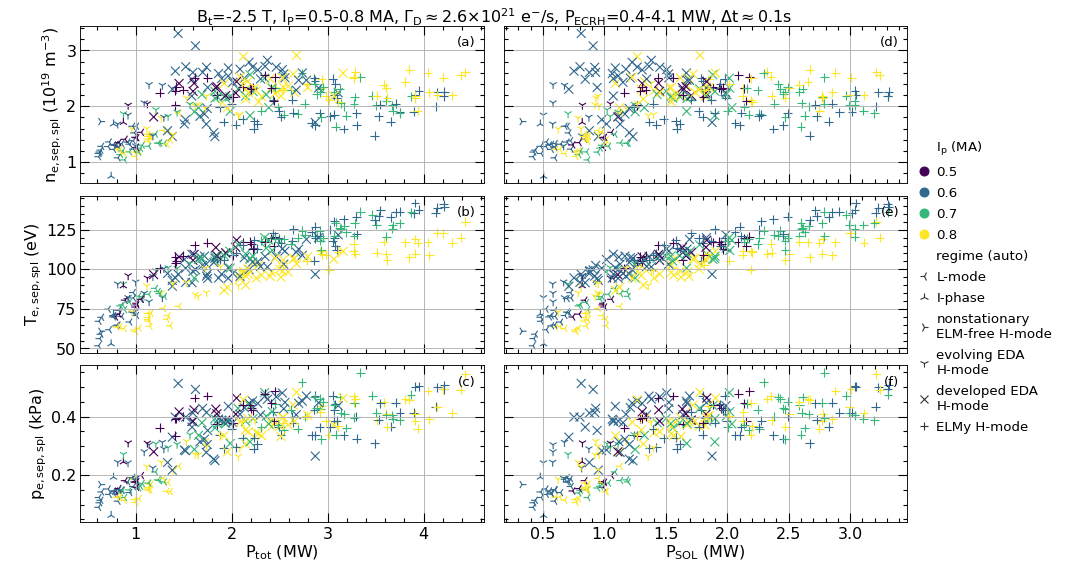

In [32]:

powers = ['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{heat}$ (MW)', label_Psep, 
            '$P_{tot}$-$P_{rad,sepX}$ (MW)', '$P_{tot}$-$P_{rad,main}$ (MW)', 
            '$P_{tot}$/($n_{e}$S) ($10^{-19}$ MW m)']
sep_params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)','$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)','$n_{e,100}$ ($10^{19}m^{-3}$)',
       '$T_{sep}$ (eV)','$T_{sep}^{(m)}$ (eV)','$T_{e,100}$ (keV)',
      '$p_{sep}$ (kPa)','$p_{sep}^{(m)}$ (kPa)','$p_{e,100}$ (kPa)']
g, fig_name = plot_rel_regimes(
    data = data_final_current_scan_all[0],
    #write_dt= False,
    #write_Bt= False,
    x = [powers[i]for i in [1,3]],
    y=[sep_params[i] for i in [0, 3, 6]],
    hue = label_current_binned,
    legend_hue_title = '$I_p$ (MA)'
    #style = label_current_binned

)
fig_name

'35970...38808_$n_{sep}$_($10^{19}$_m$^{-3}$)_$T_{sep}$_(eV)_$p_{sep}$_(kPa)_vs_Ip_binned_by_P_TOT_merged_label_some_auto_dt-0.1s'

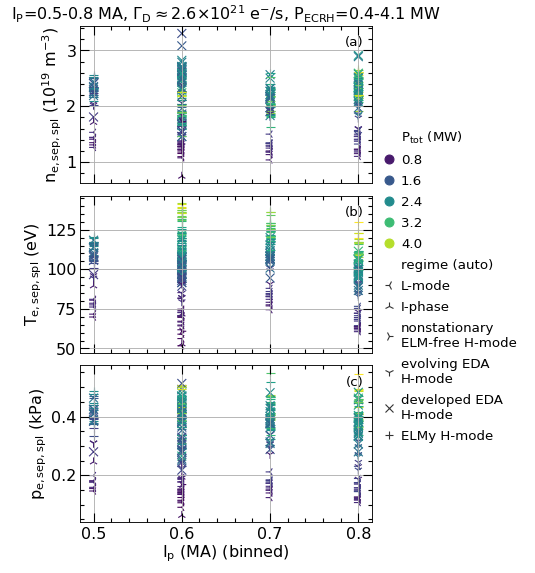

In [33]:
# Ne, Te and pe scatter plots
powers = ['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{heat}$ (MW)', label_Psep, 
            '$P_{tot}$-$P_{rad,sepX}$ (MW)', '$P_{tot}$-$P_{rad,main}$ (MW)', 
            '$P_{tot}$/($n_{e}$S) ($10^{-19}$ MW m)']
sep_params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)','$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)','$n_{e,100}$ ($10^{19}m^{-3}$)',
       '$T_{sep}$ (eV)','$T_{sep}^{(m)}$ (eV)','$T_{e,100}$ (keV)',
      '$p_{sep}$ (kPa)','$p_{sep}^{(m)}$ (kPa)','$p_{e,100}$ (kPa)']
g, fig_name = plot_rel_regimes(
    data = data_final_current_scan_all[0],
    write_dt= False,
    write_Bt= False,
    x = label_current_binned,
    y=[sep_params[i] for i in [0, 3, 6]],
    hue = powers[1],
    #style = label_current_binned

)
fig_name

##### lamNe, lamTe and lampe scatter plots

'35970...38808_$lambda_T$_(mm)_$lambda_n$_(mm)_$lambda_p$_(mm)_vs_P_TOT_P_TOT-Pr_sep_by_Ip_binned_merged_label_some_auto_dt-0.1s'

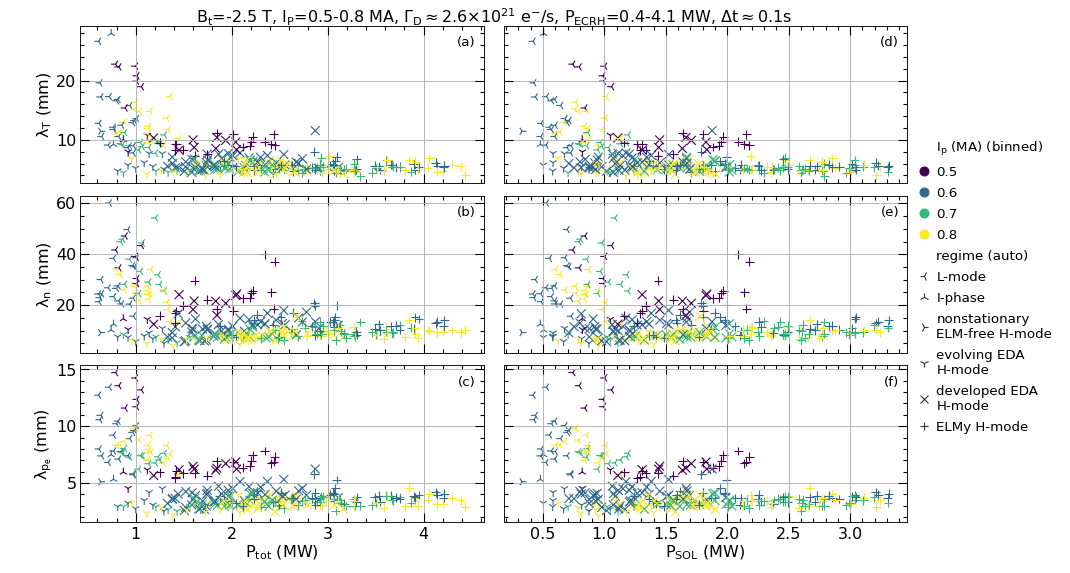

In [42]:
sep_params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)','$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)','$n_{e,100}$ ($10^{19}m^{-3}$)',
       '$T_{sep}$ (eV)','$T_{sep}^{(m)}$ (eV)','$T_{e,100}$ (keV)',
      '$p_{sep}$ (kPa)','$p_{sep}^{(m)}$ (kPa)','$p_{e,100}$ (kPa)',
         '$\\lambda_T$ (mm)','$\\lambda_T^{(m)}$ (mm)','$\\lambda_n$ (mm)',
        '$\\lambda_n^{(m)}$ (mm)','$\\lambda_p$ (mm)','$\\lambda_p^{(m)}$ (mm)']
powers = ['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{heat}$ (MW)', label_Psep, 
            '$P_{tot}$-$P_{rad,sepX}$ (MW)', '$P_{tot}$-$P_{rad,main}$ (MW)', 
            '$P_{tot}$/($n_{e}$S) ($10^{-19}$ MW m)']
g, fig_name = plot_rel_regimes(
    data = data_final_current_scan_all[0],
    #write_dt= False,
    #write_Bt= False,
    y = [sep_params[i]for i in [9,11,13]],
    x=[powers[i] for i in [1,3]],
    hue = label_current_binned,
    #style = label_current_binned

)
fig_name

'35970...38808_$lambda_T$_(mm)_$lambda_n$_(mm)_$lambda_p$_(mm)_vs_Ip_binned_by_merged_label_some_auto_dt-0.1s'

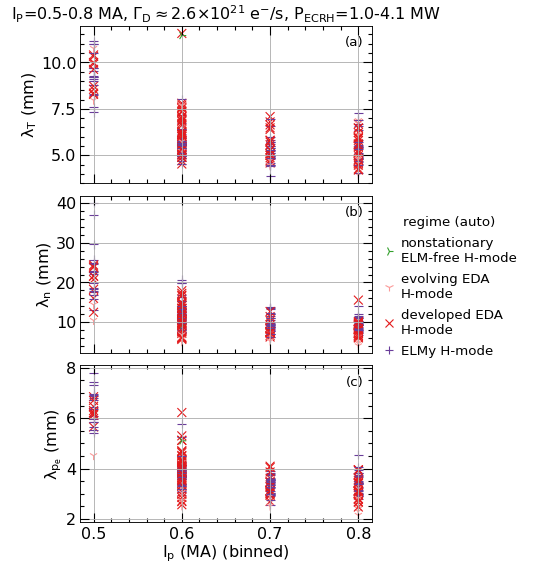

In [41]:
sep_params = ['$n_{sep}$ ($10^{19}$ m$^{-3}$)','$n_{sep}^{(m)}$ ($10^{19}$ m$^{-3}$)','$n_{e,100}$ ($10^{19}m^{-3}$)',
       '$T_{sep}$ (eV)','$T_{sep}^{(m)}$ (eV)','$T_{e,100}$ (keV)',
      '$p_{sep}$ (kPa)','$p_{sep}^{(m)}$ (kPa)','$p_{e,100}$ (kPa)',
         '$\\lambda_T$ (mm)','$\\lambda_T^{(m)}$ (mm)','$\\lambda_n$ (mm)',
        '$\\lambda_n^{(m)}$ (mm)','$\\lambda_p$ (mm)','$\\lambda_p^{(m)}$ (mm)']
powers = ['$P_{ECRH}$ (MW)', '$P_{tot}$ (MW)', '$P_{heat}$ (MW)', label_Psep, 
            '$P_{tot}$-$P_{rad,sepX}$ (MW)', '$P_{tot}$-$P_{rad,main}$ (MW)', 
            '$P_{tot}$/($n_{e}$S) ($10^{-19}$ MW m)']
g, fig_name = plot_rel_regimes(
    data = select_regimes(
                data_final_current_scan_all[0],
                regimes=merged_labels[2:],  # pick the regimes
                label='merged label some auto'),
    write_dt= False,
    write_Bt= False,
    y = [sep_params[i]for i in [9,11,13]],
    x=label_current_binned,
    #hue = powers[1],
    #style = label_current_binned

)
fig_name

##### Rsep

'35970...38808_$R_{sep}$_(m)_$R_{sep}^{(m)}$_(m)_vs_$R_{sep,EQH}$_(m)_by_Ip_binned_merged_label_some_auto_dt-0.1s'

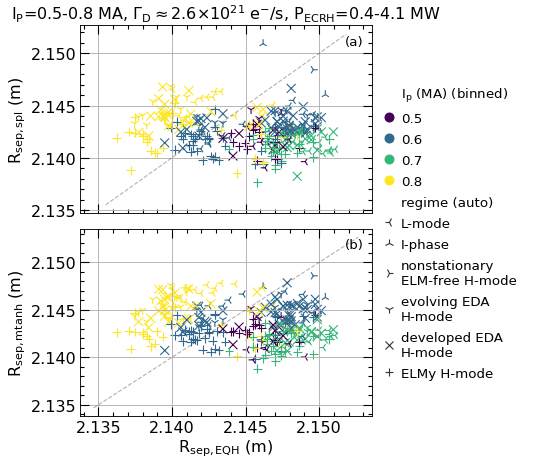

In [37]:
g, fig_name = plot_rel_regimes(
    data = data_final_current_scan_all[0],
    write_dt= False,
    write_Bt= False,
    x = ['$R_{sep,EQH}$ (m)'],
    y=['$R_{sep}$ (m)', '$R_{sep}^{(m)}$ (m)'],
    style = None,
    hue=label_current_binned,
    #wspace=1,
    #title_kw={'pad': 20},
    #top=0.8,
    #adjust_plot_kw={'figsize': (8, 6)}
)
# Add diagonal reference line y=x
for ax in g.axes.flat:
    lim = [np.min([ax.get_xlim(), ax.get_ylim()]),
           np.max([ax.get_xlim(), ax.get_ylim()])]
    ax.plot(lim, lim, 'k--', alpha=0.3, linewidth=1)
fig_name

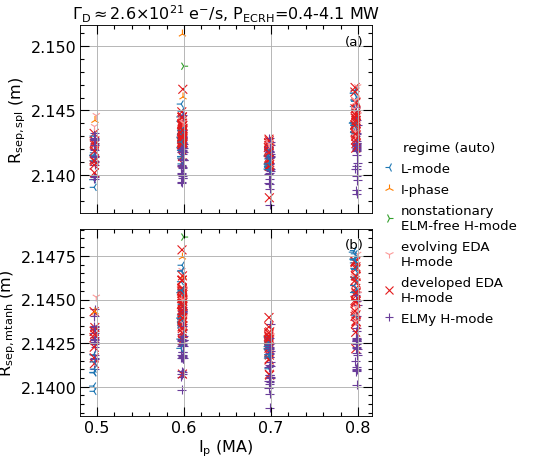

In [49]:
g, fig_name = plot_rel_regimes(
    data = data_final_current_scan_all[0],
    write_dt= False,
    write_Bt= False,
    x = label_current,
    y=['$R_{sep}$ (m)', '$R_{sep}^{(m)}$ (m)'],
    #style = None,
    #style= label_fueling_binned,
    #legend_style_title='$\\Gamma_{D}$ ($10^{21}  e^{-}$/s)',
    #legend_hue_title='regime',
    #wspace=1,
    #title_kw={'pad': 20},
    #top=0.8,
    #adjust_plot_kw={'figsize': (8, 6)}
)

#### Global confinement

In [ ]:
#TODO: arranjar uma figura de mérito adimensional para o triple product e fazer a figura com 6 caixas: 
#coluna 1 (dimensional) - Wmhd, tau_E, p_avg*tau_E; coluna 2 (dimensional) - beta_N, H98, figura de mérito
g, fig_name = plot_rel_regimes(
    data=rename_labels_binning_current(data_final_current_scan_all[0]),
    x=[label_PECRH, label_Ptot, label_Psep, r'$\beta_{N}/H_{98y2}$'][:],
    y=[
        r'$\overline{n_{e}}$ ($10^{19}m^{-3})$', '$f_{GW}$', '$W_{mhd}$ (MJ)', 
        r'$\beta_{N}$', r'$\beta_{pol}$', r'$\tau_{E}$ (ms)', '$H_{98y2}$', 
        label_ptau, r'$\beta_{N} H_{98y2}$', 
        r'$\nu_{e,ped}^{*}$'][:],    
    style=[label_current, 'shot'][0], 
    #kind='line', markers=True,
)
#TODO: adicionar fits e/ou linhas com scalings típicos?
#for ax in g.axes.flat:
#    ax.set_xlim(None, 4.5)
#g.ax.set_xlim(0.6, 4.4)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
#TODO: arranjar uma figura de mérito adimensional para o triple product e fazer a figura com 2 colunas: 
#coluna 1 (dimensional) - ne_avg, Wmhd, tau_E, p_avg*tau_E; coluna 2 (dimensional) - f_GW, beta_N, H98, figura de mérito
data_plot = data_final_current_scan_all[0]
#data_plot = data_plot[data_plot['merged label some'].isin(['developed EDA H-mode', 'evolving EDA H-mode'][:1])]
data_plot = select_regimes(data_plot)
#data_plot = data_plot.assign(**{'$P_{tot}$ (MW)':pd.cut(data_plot['$P_{tot}$ (MW)'], bins=1.1+np.arange(10)*0.2, right=False)})
g, fig_name = plot_rel_regimes(
    data=data_plot, x=[label_current, '$q_{95}$', '$q_{cyl}$'][:], 
    y=[
        r'$\overline{n_{e}}$ ($10^{19}m^{-3})$', '$f_{GW}$', '$W_{mhd}$ (MJ)', 
        r'$\beta_{N}$', r'$\beta_{pol}$', r'$\tau_{E}$ (ms)', '$H_{98y2}$', 
        label_ptau, r'$\beta_{N} H_{98y2}$', 
        r'$\nu_{e,ped}^{*}$'][:], 
    hue='$P_{tot}$ (MW)', palette="viridis", replace_developed_labels=False,
    #kind='line', markers=True,
)
#TODO: adicionar fits e/ou linhas com scalings típicos?
#for ax in g.axes.flat:
#    ax.set_xlim(0,None)
#    ax.set_ylim(0,None)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
#TODO: arranjar uma figura de mérito adimensional para o triple product e fazer a figura com 2 colunas: 
#coluna 1 (dimensional) - ne_avg, Wmhd, tau_E, p_avg*tau_E; coluna 2 (dimensional) - f_GW, beta_N, H98, figura de mérito
data_plot = data_final_current_scan_all[0]
#data_plot = data_plot[data_plot['merged label some'].isin(['developed EDA H-mode', 'evolving EDA H-mode'][:1])]
data_plot = select_regimes(data_plot)
#data_plot = data_plot.assign(**{'$P_{tot}$ (MW)':pd.cut(data_plot['$P_{tot}$ (MW)'], bins=1.1+np.arange(11)*0.2, right=False)})
g, fig_name = plot_rel_regimes(
    data=data_plot, x=[label_current, '$q_{95}$', '$q_{cyl}$'][:1], 
    y=np.array([
        r'$\overline{n_{e}}$ ($10^{19}m^{-3})$', '$f_{GW}$', '$W_{mhd}$ (MJ)', 
        r'$\beta_{N}$', r'$\beta_{pol}$', r'$\tau_{E}$ (ms)', '$H_{98y2}$', 
        label_ptau, r'$\beta_{N} H_{98y2}$', 
        r'$\nu_{e,ped}^{*}$'])[[0, 2, 5, 7]], 
    hue=label_Ptot, palette="viridis", write_PECRH=True,
    replace_developed_labels=False, label_pos_x=0, 
    **final_rel_figure_kw
)
#TODO: adicionar fits e/ou linhas com scalings típicos?
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:]:
    save_figure(g.fig, fig_name, format=fmt)

## Overview and dimensionless parameters

### Chosen discharges and periods

In [ ]:
shots_overview = (
    pd.concat([
        pd.read_excel(filepath, sheet_name=sheet_name)['shot'] 
        for sheet_name in ['gas - P (strong, 0.7 MA)', 'gas - P (strong, 0.8 MA)', 'Ip - P (strong, medium gas)']])
    .drop_duplicates())
shots_overview = shots_overview[shots_overview != 38048].sort_values().reset_index(drop=True)
bins = np.concatenate((1.1+np.arange(18)*0.2, 4.6+np.arange(13)*0.2))#0.9+np.arange(37)*0.2
data_overview_all = []
for data_final in data_final_all:
    #data_overview = data_final.loc[data_final['shot'].isin(shots_overview)]
    data_overview = (
        data_final.loc[(
            data_final['shot'].isin(shots_overview[shots_overview != 38743])
            | (data_final['shot'] == 38743) & (data_final['t_end (s)'] <= 6))]
        .copy())
    data_overview[label_fueling_binned] = (
        pd.cut(
            data_overview[label_fueling], bins=bins, right=False,
            #labels=sliding_window(bins, 2).mean(axis=-1),
            )
        .astype(object))
    data_overview[label_current_binned] = data_overview[label_current].round(1)
    data_overview.sort_values(['shot', 't_begin (s)'], inplace=True)
    data_overview.attrs = data_final.attrs
    data_overview_all.append(data_overview)
data_overview_all[0]#.head()

### Shaping parameters

In [ ]:
shaping_labels = [
    label_major_radius_geometric, label_minor_radius_horizontal, 
    label_minor_radius_vertical, label_surface, label_volume, 
    label_inverse_aspect_ratio, label_elongation, 
    label_triangularity_upper, label_triangularity_lower, 
    label_triangularity_avg, label_dRsep, label_drhosep]

table_shaping_parameters = (
    data_overview_all[0][shaping_labels].apply(extent).to_frame(name='Extent'))
table_shaping_parameters.index.name = 'Variable'
table_shaping_parameters

In [ ]:
print_latex_table_iop(table_shaping_parameters)

### Dimensional input parameters

In [ ]:
table_overview = table_of_scan(data_overview_all[0], [label_current, label_fueling], label_PECRH)
with pd.option_context('display.float_format', "{:,.2f}".format):
    display(table_overview)

In [ ]:
print_latex_table_iop(table_overview, precision=1)

In [ ]:
g, fig_name = plot_pair(
    data_overview_all[0], 
    variables=[[label_PECRH, label_Psep][0], [label_fueling, label_neavg_LH][0], label_Ip], 
    hue='shot',
)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_pair_regimes(
    data_overview_all[0],#.sort_values(['regime plot order', 'shot', 't_begin (s)']), 
    variables=[[label_PECRH, label_Psep][0], [label_fueling, label_neavg_LH][0], label_Ip], 
    **final_pair_figure_kw
)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:]:
    save_figure(g.fig, fig_name, format=fmt)

### Dimensionless input parameters

In [ ]:
#TODO substituir o fueling por n_e,lH/n_GW
#TODO experimentar substituir o Ptot/P_LH,scal por (Ptot ou Psep)/P_LH (martin (contínuo ou no momento da transição) ou real)
g, fig_name = plot_pair(
    data_overview_all[0], 
    variables=[
        *(
            [
                r'$\beta_{N}/H_{98y2}$', '$P_{tot}/P_{LH,scal}$', 
                label_Ptot_normalized_LH, label_Psep_normalized_LH]
            [2:3]), 
        *[label_fueling, label_fGW_LH][1:2], 
        *[label_q95, labels_dict['qcyl']][0:1]],
    hue='shot', #write_dt=False, 
    )
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
#TODO substituir o fueling por n_e,lH/n_GW
#TODO experimentar substituir o Ptot/P_LH,scal por (Ptot ou Psep)/P_LH (martin (contínuo ou no momento da transição) ou real)
g, fig_name = plot_pair_regimes(
    data_overview_all[0],#.sort_values(['regime plot order', 'shot', 't_begin (s)']),  
    variables=[
        *(
            [
                r'$\beta_{N}/H_{98y2}$', '$P_{tot}/P_{LH,scal}$', 
                label_Ptot_normalized_LH, label_Psep_normalized_LH]
            [2:3]), 
        *[label_fueling, label_fGW_LH][1:2], 
        *[label_q95, labels_dict['qcyl']][0:1]],
    **final_pair_figure_kw
    )
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

### Scaled input parameters

In [ ]:
data_plot = data_overview_all[0]

if data_plot.attrs['dt_subperiod'] == 0.1:
    # hyperparameter C=10000, same weight per shot, with jacknife
    exponent_fueling_overview = 0.5484873370118856
    # stddev_exponent_fueling_overview = 0.100606508261873
    exponent_current_overview = 0.8857656243237209
    # stddev_exponent_current_overview = 0.1616810675106575
    logk_raw_overview = -24.461636513842667
    # stddev_exponent_logk_raw_overview = 5.161900238133209
    k_raw_overview = np.exp(logk_raw_overview)
    
    # hyperparameter C=10000, same weight per shot, no jacknife
    #exponent_fueling_overview = 0.535241525257505
    #exponent_current_overview = 0.879016503168501
    #k_raw_overview = 5.040028146255169e-11
elif data_plot.attrs['dt_subperiod'] == 0.05:
    exponent_fueling_overview = 0.54
    # stddev_exponent_fueling_overview = 0.0908935422649036
    exponent_current_overview = 0.77
    # stddev_exponent_current_overview = 0.110635564985884
    # stddev_exponent_logk_raw_overview = 4.4323742048525
    k_raw_overview = 1.82E-10
else:
    print("fit data missing for this dt (or dt missing)")
    raise

k_overview = (
    k_raw_overview * power_mult / (mult_Ip**exponent_current_overview) / 
    (mult_gaspuff**exponent_fueling_overview))
label_scaled_fueling = label_base_scaled_gaspuff.format(
    *[exponent_fueling_overview]*2)
label_scaled_current = label_base_scaled_Ip.format(
    *[exponent_current_overview]*2)
label_scaled_fueling_current = label_base_scaled_gaspuff_Ip.format(
    *[exponent_fueling_overview, exponent_current_overview]*2)

label_inverted_scaled_fueling, label_inverted_scaled_current = (
    "{}^{:.2f}".format(label, exponent) 
    for label, exponent in [
        (labels_dict_inverted[label_fueling], exponent_fueling_overview), 
        (labels_dict_inverted[label_current], exponent_current_overview)])
labels_dict_inverted.update({
    label_scaled_fueling:label_inverted_scaled_fueling,
    label_scaled_current:label_inverted_scaled_current,
    label_scaled_fueling_current:(
        label_inverted_scaled_fueling+label_inverted_scaled_current)})

#data_plot = data_plot[data_plot['merged label some'].isin(['developed EDA H-mode', 'evolving EDA H-mode'][:1])]
#data_plot = select_regimes(data_plot)
#data_plot = data_plot.assign(**{'$P_{tot}$ (MW)':pd.cut(data_plot['$P_{tot}$ (MW)'], bins=1.1+np.arange(10)*0.2, right=False)})
data_plot = data_plot.assign(**{
    label_scaled_fueling:data_plot[label_fueling]**exponent_fueling_overview, 
    label_scaled_current:data_plot[label_current]**exponent_current_overview, 
    label_scaled_fueling_current:(
        (data_plot[label_fueling]**exponent_fueling_overview) * 
        (data_plot[label_current]**exponent_current_overview)), 
})

g, fig_name = plot_rel_regimes(
    data_plot,
    #data_plot.query("shot!=38808"),
    #data_plot.query("shot!=35970"),
    x=[label_scaled_fueling, label_scaled_current, label_scaled_fueling_current][-1], 
    y=(
        np.array([
            label_PECRH, label_Ptot, '$P_{heat}$ (MW)', label_Psep, 
            '$P_{tot}$-$P_{rad,sepX}$ (MW)', '$P_{tot}$-$P_{rad,main}$ (MW)', 
            '$P_{tot}$/($n_{e}$S) ($10^{-19}$ MW m)', r'$\beta_{N}/H_{98y2}$', 
            '$P_{tot}/P_{LH,scal}$', label_Ptot_normalized_LH, 
            label_Psep_normalized_LH])
        [3:4]),
    title_prefix=" "*17, #title_kw=dict(fontdict=dict(stretch=400)),
    #group_regimes='hue', #replace_labels=True, #markers=default_markers_default_regimes_dict, 
    #markers=default_markers_default_regimes[:-1],
    #style='shot', sort_style=False, label_pos_x=0, #shuffle=False,
    #style=final_rel_figure_kw["legend_regimes_title"], #markers=["+", "2", "3", "x", "1", "4"], linewidth=1,
    #markers=default_markers_default_regimes_dict,
    **final_rel_figure_kw
)
ax = g.axes[0, 0]
#ax.set_ylim(None, 4.1*5)
#ax.set_ylim(None, 4.1)
ax.set_ylim(
    None, 3.6 if data_plot.attrs['dt_subperiod'] == 0.1 else 4.1)
if [True, False][0]:
    xmin, xmax = ax.get_xlim()
    delta_x = xmax - xmin
    x = np.array([xmin, xmax])
    #x_annotate = x[0] + 0.1*(delta_x)
    x_annotate = (
        1.78 if data_plot.attrs['dt_subperiod'] == 0.1 else 1.95)
    ax.plot(x, k_overview*x, color='black', linestyle='--')
    ax.annotate(
#        text=r"{:.2f}$\times${}$\times${}".format(
#            k_overview, 
#            symbol_base_scaled_deuterium_gaspuff.format(
#                exponent_fueling_overview), 
#            symbol_base_scaled_Ip.format(exponent_current_overview)), 
        text=(r"$\propto$"+"{}$^{{{:.2f}}}$"*2).format(
            symbol_deuterium_gaspuff, exponent_fueling_overview, 
            symbol_Ip, exponent_current_overview),
        xy=(x_annotate, k_overview * x_annotate - 0.07 * np.ptp(ax.get_ylim())), 
        rotation=0.9*np.degrees(np.arctan(k_overview / ax.get_data_ratio())))
    
    data_fit = select_regimes(data_plot, regimes=merged_labels[4:7])
    mask_below_scaling = data_fit[label_Psep] < k_overview * data_fit[label_scaled_fueling_current]
    n_in_agreement = (
        (
            (
                data_fit.loc[mask_below_scaling, "merged label some auto"] 
                == 'developed EDA H-mode')
            .sum())
        + (
            (
                data_fit.loc[~mask_below_scaling, "merged label some auto"] 
                != 'developed EDA H-mode')
            .sum()))
    n_total = len(data_fit)
    print(
        (
            "{} out of {} points with agreeing classification: " + 
            "{:#.3g}% of points in agreement")
        .format(
            n_in_agreement, n_total, 100 * n_in_agreement / n_total))
    
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:]:
    save_figure(g.fig, fig_name, format=fmt)

### Scaled IDA parameters

In [ ]:
#exponents_fueling_current_power_kraw_r2_dict = dict(
#    ne0Psep=(8.958E-02, 9.996E-01, -1.165E-02, 1.782E+12, 0.31),
#    ne95Psep=(4.977E-03, 1.254E+00, -1.279E-03, 2.268E+12, 0.92),
#    pe0Psep=(-1.144E-01, 9.216E-01, 1.351E-01, 6.202E+00, 0.04),
#    pe95Psep=(-3.385E-01, 2.264E+00, 5.631E-02, 1.775E-03, 0.58),
#    Te0Psep=(-2.041E-01, -7.763E-02, 1.467E-01, 2.176E+07, 0.33),
#    Te95Psep=(-3.437E-01, 1.010E+00, 5.769E-02, 4.900E+03, 0.39),
#    ne0Ptot=(3.928E-02, 8.793E-01, 1.324E-01, 1.316E+13, 0.47),
#    ne95Ptot=(2.779E-02, 1.273E+00, -1.338E-02, 6.765E+11, 0.92),
#    pe0Ptot=(-8.306E-02, 4.550E-01, 7.046E-01, 1.653E-01, 0.67),
#    pe95Ptot=(-2.422E-01, 2.045E+00, 3.796E-01, 2.584E-06, 0.72),
#    Te0Ptot=(-1.224E-01, -4.239E-01, 5.721E-01, 7.847E+04, 0.73),
#    Te95Ptot=(-2.701E-01, 7.719E-01, 3.928E-01, 2.380E+01, 0.63)
#)

#exponents_fueling_current_power_kraw_r2_dict = dict(
#    ne0Psep=(4.600E-02, 5.212E-01, 8.967E-02, 2.446E+15, 0.44),
#    ne95Psep=(-8.736E-03, 1.389E+00, 1.018E-02, 6.092E+11, 0.93),
#    pe0Psep=(-2.393E-01, -1.141E-01, 5.967E-01, 5.260E+06, 0.42),
#    pe95Psep=(-3.746E-01, 1.757E+00, 4.075E-01, 6.387E-02, 0.75),
#    Te0Psep=(-2.853E-01, -6.351E-01, 5.070E-01, 1.341E+10, 0.53),
#    Te95Psep=(-3.660E-01, 3.693E-01, 3.972E-01, 6.515E+05, 0.63),
#    ne0Ptot=(5.898E-02, 4.110E-01, 1.776E-01, 1.480E+15, 0.61),
#    ne95Ptot=(-2.399E-03, 1.411E+00, -9.294E-03, 4.364E+11, 0.93),
#    pe0Ptot=(-8.982E-02, -3.915E-01, 7.892E-01, 5.846E+03, 0.78),
#    pe95Ptot=(-2.578E-01, 1.675E+00, 4.461E-01, 2.755E-04, 0.74),
#    Te0Ptot=(-1.488E-01, -8.022E-01, 6.116E-01, 2.464E+07, 0.75),
#    Te95Ptot=(-2.555E-01, 2.647E-01, 4.552E-01, 3.922E+03, 0.69),
#)

suffix = ["", "_same_weight_per_shot", "_same_weight_per_point"][1]
dt_subperiod = [0.1, 0.05, 0.02][0]
data_fits_core_pedestal = pd.read_csv(
    "jackknife_pedestal_results{}_dt-{}s.csv".format(suffix, dt_subperiod), 
    skipinitialspace=True)
data_fits_core_pedestal.attrs['suffix'] = suffix
data_fits_core_pedestal.attrs['dt_subperiod'] = dt_subperiod
data_fits_core_pedestal = data_fits_core_pedestal[
    data_fits_core_pedestal["Fourth Coordinate"].str.startswith(
        base_quantities)]
data_fits_core_pedestal["quantity"] = (
    data_fits_core_pedestal["Fourth Coordinate"].str[:2])
data_fits_core_pedestal["rho_subscript"] = (
    data_fits_core_pedestal["Fourth Coordinate"].str[2:].astype(int))
data_fits_core_pedestal["rho_pol"] = (
    data_fits_core_pedestal["rho_subscript"] / 100)
data_fits_core_pedestal.replace(
    (
        {
            "gamma1":label_gamma_fueling, "gamma2":label_gamma_current, 
            "gamma3":label_gamma_generic_power, "r2":label_r2, 
            "TOTPTOT":symbol_Ptot, "PTOT-Prsep":symbol_Psep, 
            "logkraised":"logk", "k":"1/k*"}
        #| dict(zip(base_quantities, fancy_base_quantities))
    ),
    inplace=True)
data_fits_core_pedestal["key"] = (
    data_fits_core_pedestal["Fourth Coordinate"] + 
    data_fits_core_pedestal["Third Coordinate"].replace(
        {symbol_Psep:"Psep", symbol_Ptot:"Ptot"}))
data_fits_core_pedestal.rename(columns=rename, inplace=True)##)"rho_pol":label_rho_pol

exponents_fueling_current_power_kraw_r2_dict = {}
for a in (
        data_fits_core_pedestal[
            data_fits_core_pedestal["rho_subscript"].isin([0, 95])]
        .groupby('key')):
    df = a[1].set_index('Parameter')
    values = [
        df.loc[s, 'Jackknife Estimate'] 
        for s in [
            label_gamma_fueling, label_gamma_current, 
            label_gamma_generic_power, 'logk', label_r2]]
    values[3] = np.exp(values[3])
    exponents_fueling_current_power_kraw_r2_dict[a[0]] = tuple(values)
display(data_fits_core_pedestal)
exponents_fueling_current_power_kraw_r2_dict

In [ ]:
data_IDA_overview_melted_all = melt_IDA(
    data_overview_all, [label_fueling_binned, label_current_binned])

for data_IDA_overview_melted in data_IDA_overview_melted_all:
    for suffix_power in [suffix_Ptot, suffix_Psep]:

        label_power = (
            {suffix_Ptot:label_Ptot, suffix_Psep:label_Psep}
            [suffix_power])
        label_generic_scaled_power = (
            #{"tot":label_generic_scaled_Ptot, "sep":label_generic_scaled_Psep}
            {
                suffix_Ptot:label_generic_scaled_Ptot_with_units, 
                suffix_Psep:label_generic_scaled_Psep_with_units}
            [suffix_power])
        (
                label_generic_scaled_fueling_from_fit, 
                label_generic_scaled_current_from_fit) = (
            (
                label_generic_scaled + 
                " (from {} fit)".format(
                    {suffix_Ptot:symbol_Ptot, suffix_Psep:symbol_Psep}
                    [suffix_power]))
            for label_generic_scaled in [
                #label_generic_scaled_fueling, label_generic_scaled_current]
                label_generic_scaled_fueling_with_units, 
                label_generic_scaled_current_with_units]
        )

        for base_quantity in ['n', 'T', 'p'][:]:
            for rho_pol in [0, 0.95][:]:

                quantity = "{}e{}".format(base_quantity, int(rho_pol*100))
                mask = (
                    data_IDA_overview_melted["name"] == labels_dict[quantity])

                (
                        exponent_fueling, exponent_current, exponent_power, 
                        k_raw, r2) = (
                    exponents_fueling_current_power_kraw_r2_dict
                    [quantity + "P" + suffix_power])

                for label_generic_scaled, label, exponent in [
                        (
                            label_generic_scaled_power, label_power, 
                            exponent_power), 
                        (
                            label_generic_scaled_fueling_from_fit, 
                            label_fueling, exponent_fueling), 
                        (
                            label_generic_scaled_current_from_fit, 
                            label_current, exponent_current)]:
                    data_IDA_overview_melted.loc[mask, label_generic_scaled] = (
                        data_IDA_overview_melted.loc[mask, label]**exponent)
        (
                data_IDA_overview_melted[
                    {
                        suffix_Ptot:(
                            label_generic_scaled_Ptot_fueling_current_with_units), 
                        suffix_Psep:(
                            label_generic_scaled_Psep_fueling_current_with_units)}
                    [suffix_power]]) = (
            data_IDA_overview_melted[label_generic_scaled_power] * 
            data_IDA_overview_melted[label_generic_scaled_fueling_from_fit] * 
            data_IDA_overview_melted[label_generic_scaled_current_from_fit])
        data_IDA_overview_melted.attrs['suffix'] = (
            data_fits_core_pedestal.attrs['suffix'])
        data_IDA_overview_melted.attrs['dt_subperiod_fit'] = (
            data_fits_core_pedestal.attrs['dt_subperiod'])

data_IDA_overview_melted_all[0]

In [ ]:
data_plot = data_IDA_overview_melted_all[0]
x = (
    [
        label_generic_scaled_Ptot_fueling_current,
        label_generic_scaled_Ptot_fueling_current_with_units]
    [1])
g, fig_name = plot_rel_regimes_IDA(
    data_plot, x=x, facet_kws={'sharex': False, 'sharey': False}, 
    #set_col_title_kw={"loc":"center"}, top=0.93, 
    hspace=0.15, n_rows_eff=2.2, top=0.96,
    #style='shot',
    **final_rel_figure_kw
)
#g.axes[1,0].set_xlim(None, 4.5)
fig_name += data_plot.attrs['suffix']
fig_name

In [ ]:
if [True, False][0]:
#    y_offset_data_dict = dict(
#        ne0Ptot=2.9,
#        ne95Ptot=1.3,
#        Te0Ptot=3,
#        Te95Ptot=0.29,
#        pe0Ptot=30,
#        pe95Ptot=3,
#        ne0Psep=0,
#        ne95Psep=0,
#        Te0Psep=0,
#        Te95Psep=0,
#        pe0Psep=0,
#        pe95Psep=0,
#    )
#    y_offset_data_dict = dict(
#        ne0Ptot=2.0,
#        ne95Ptot=1.3,
#        Te0Ptot=3.3,
#        Te95Ptot=0.33,
#        pe0Ptot=30,
#        pe95Ptot=3.2,
#        ne0Psep=0,
#        ne95Psep=0,
#        Te0Psep=0,
#        Te95Psep=0,
#        pe0Psep=0,
#        pe95Psep=0,
#    )
    y_offset_data_dict = dict(
        ne0Ptot=2.5,
        ne95Ptot=1.3,
        Te0Ptot=2.7,
        Te95Ptot=0.31,
        pe0Ptot=28,
        pe95Ptot=3.2,
        ne0Psep=0,
        ne95Psep=0,
        Te0Psep=0,
        Te95Psep=0,
        pe0Psep=0,
        pe95Psep=0,
    )
    
    for ax_row, base_quantity in zip(g.axes, ['n', 'T', 'p']):
        
        mult_quantity = {"n":ne_mult, "T":mult_Te, "p":mult_pe}[base_quantity]
        
        for i, (ax, rho_pol) in enumerate(zip(ax_row, [0, 0.95])):

            x_label = ax.get_xlabel()
            if x_label == '':
                x_label = g.axes[-1, i].get_xlabel()
            suffix_power = (
                {
                    label_generic_scaled_Ptot_fueling_current:(
                        suffix_Ptot), 
                    label_generic_scaled_Ptot_fueling_current_with_units:(
                        suffix_Ptot), 
                    label_generic_scaled_Psep_fueling_current:(
                        suffix_Psep), 
                    label_generic_scaled_Psep_fueling_current_with_units:(
                        suffix_Psep)}
                [x_label])
            
            rho_pol_index = int(rho_pol*100)
            quantity = "{}e{}".format(base_quantity, rho_pol_index)
            quantity_power = quantity + "P" + suffix_power

            exponent_fueling, exponent_current, exponent_power, k_raw, r2 = (
                exponents_fueling_current_power_kraw_r2_dict[quantity_power])
            k = (
                k_raw * mult_quantity / (power_mult**exponent_power) / 
                (mult_Ip**exponent_current) / (mult_gaspuff**exponent_fueling))
            
            xmin, xmax = ax.get_xlim()
            delta_x = xmax - xmin
            ymin, ymax = ax.get_ylim()
            delta_y = ymax - ymin
            x_fit = np.array([xmin, xmax])
            ax.plot(x_fit, k*x_fit, color='black', linestyle='--')
            x_annotate = None
            if x_annotate is None:
                x_annotate = xmin + 0.02 * delta_x
            y_annotate = None#ymax - 0.5 * delta_y
            y_offset_data = y_offset_data_dict[quantity_power]
            y_offset_fraction = 0            
            if y_annotate is None:
                y_annotate = (
                    k * x_annotate + y_offset_data + 
                    y_offset_fraction * delta_y)
            
            symbol_power = (
                {suffix_Ptot:symbol_Ptot, suffix_Psep:symbol_Psep}
                [suffix_power])
            text = (
                [
#                    r"{:.2f}$\times${}$\times${}$\times${}".format(
#                        k, 
#                        symbol_base_scaled_power.format(exponent_power), 
#                        symbol_base_scaled_deuterium_gaspuff.format(
#                            exponent_fueling), 
#                        symbol_base_scaled_Ip.format(exponent_current)), 
                    (r"${}_{{e,{}}}\propto$"+"{}$^{{{:#.2g}}}$"*3).format(
                        base_quantity, rho_pol_index, symbol_power, 
                        exponent_power, symbol_deuterium_gaspuff, 
                        exponent_fueling, symbol_Ip, exponent_current),
                    (r"{}$\propto$"+"{}$^{{{:#.2g}}}$"*3).format(
                        quantity, symbol_power, exponent_power,
                        symbol_deuterium_gaspuff, exponent_fueling, 
                        symbol_Ip, exponent_current)]
                [-2])           
            ax.annotate(
                text=text, xy=(x_annotate, y_annotate),                 
                rotation=(np.degrees(np.arctan(k * get_aspect(ax)))))
            ax.annotate(
                text="$r^2$={:#.2g}".format(r2), xy=(0, 1), 
                xycoords="axes fraction", xytext=(12, -12), 
                textcoords="offset points", ha="left", va="top")

In [ ]:
for fmt in ['png', 'pdf'][:]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
label_y = 'Parameter'
label_k = '$k$'
label_units = 'Units'

units_k = "{} {}".format(
    label_units,  
    "".join([
        "{}$^{{{{-{}}}}}$".format(units, label_gamma.replace('$', ""))
        for units, label_gamma in [
            (power_units, label_gamma_power), 
            ("({})".format(units_gaspuff), label_gamma_fueling), 
            (units_Ip, label_gamma_current)]]))
label_units_k = [units_k, "$^{*}$"][1]

table_fits_core_pedestal = (
    pd.DataFrame.from_dict(
        {
            key: exponents_fueling_current_power_kraw_r2_dict[key] 
            for key in exponents_fueling_current_power_kraw_r2_dict.keys() 
            if key[-3:] == suffix_Ptot}, 
        orient='index', 
        columns=[
            label_gamma_fueling, label_gamma_current, label_gamma_power, 
            label_k, '$r^2$'])
    .reset_index(names=label_y))
table_fits_core_pedestal["base quantity"] = (
    table_fits_core_pedestal[label_y].str[:2])

units_ne_table = (
    [
        units_ne, 
        r"\{}[print-unity-mantissa=false]{{E{}}}{{\m^{{-3}}}}".format(
            macro_siunitx, ne_magnitude)]
    [1])
table_fits_core_pedestal.insert(
    table_fits_core_pedestal.columns.get_loc(label_y) + 1, label_units, 
    table_fits_core_pedestal["base quantity"].map(dict(zip(
        base_quantities, [units_ne_table, units_Te, units_pe]))))

table_fits_core_pedestal[label_k] = (
    table_fits_core_pedestal[label_k] * 
    table_fits_core_pedestal["base quantity"].map(dict(zip(
        base_quantities, [ne_mult, mult_Te, mult_pe]))) / 
    (power_mult**table_fits_core_pedestal[label_gamma_power]) / 
    (mult_Ip**table_fits_core_pedestal[label_gamma_current]) / 
    (mult_gaspuff**table_fits_core_pedestal[label_gamma_fueling]))
table_fits_core_pedestal.rename(
    columns={label_k:"{} ({})".format(label_k, label_units_k)}, inplace=True)

table_fits_core_pedestal = (
    table_fits_core_pedestal
    .sort_values(by='base quantity', key=key_function(base_quantities))
    .drop(columns='base quantity'))

table_fits_core_pedestal.attrs['suffix'] = (
    data_fits_core_pedestal.attrs['suffix'])
table_fits_core_pedestal.attrs['dt_subperiod'] = (
    data_fits_core_pedestal.attrs['dt_subperiod'])

display(table_fits_core_pedestal)

print_latex_table_iop(
    table_fits_core_pedestal.set_index(label_y), label='core_pedestal', 
    caption="{}_dt-{}s".format(table_fits_core_pedestal.attrs['suffix'], table_fits_core_pedestal.attrs['dt_subperiod']), 
    footnote=r"{} {}".format(label_units_k, units_k),
    formatter=lambda x: x if isinstance(x, str) else "{:#.2g}".format(x))

In [ ]:
columns = [
    label_gamma_generic_power, label_gamma_fueling, label_gamma_current, 
    "logk", label_r2]
table_column_labels_dict = {
    label_gamma_generic_power:label_gamma_power, 'logk':r'$\ln k$'}

table_fits_core_pedestal_with_errors_full = (
    data_fits_core_pedestal
    .query(
        '`Third Coordinate` == @symbol_Ptot & rho_subscript in [0, 95] ' + 
        '& Parameter in @columns')
    .pivot(
        index=['quantity', 'key'], 
        values=['Jackknife Estimate', 'Standard Deviation'],
        columns='Parameter'))
table_fits_core_pedestal_with_errors_full.attrs['suffix'] = (
    data_fits_core_pedestal.attrs['suffix'])
table_fits_core_pedestal_with_errors_full.attrs['dt_subperiod'] = (
    data_fits_core_pedestal.attrs['dt_subperiod'])

table_fits_core_pedestal_jackknifes = (
    table_fits_core_pedestal_with_errors_full['Jackknife Estimate'])
(
        table_fits_core_pedestal_with_errors_full
        [('Jackknife Estimate', label_logk)]) = (
    table_fits_core_pedestal_jackknifes[label_logk] + 
    np.log(
        (
            table_fits_core_pedestal_jackknifes
            .index.get_level_values('quantity')
            .map(base_quantities_mult_dict)) / 
        (
            power_mult**
            table_fits_core_pedestal_jackknifes[label_gamma_generic_power]) / 
        (mult_Ip**table_fits_core_pedestal_jackknifes[label_gamma_current]) /
        (mult_gaspuff**table_fits_core_pedestal_jackknifes[label_gamma_fueling])
    )
)

table_fits_core_pedestal_with_errors = (
    table_fits_core_pedestal_with_errors_full
    .swaplevel(0, 1, axis='columns')
    .sort_index(axis="columns", key=key_function(columns))
    .sort_index(key=key_function(base_quantities))
    .droplevel('quantity')
)
table_fits_core_pedestal_with_errors.attrs['suffix'] = (
    table_fits_core_pedestal_with_errors_full.attrs['suffix'])
table_fits_core_pedestal_with_errors.attrs['dt_subperiod'] = (
    table_fits_core_pedestal_with_errors_full.attrs['dt_subperiod'])
    
display(table_fits_core_pedestal_with_errors.rename(
    columns=table_column_labels_dict))

table_fits_core_pedestal_with_errors_combined = (
    table_fits_core_pedestal_with_errors
    .groupby("Parameter", axis='columns', group_keys=False)
    .apply(value_uncertainty)
    .sort_index(axis="columns", key=key_function(columns)))
table_fits_core_pedestal_with_errors_combined.attrs['suffix'] = (
    table_fits_core_pedestal_with_errors.attrs['suffix'])
table_fits_core_pedestal_with_errors_combined.attrs['dt_subperiod'] = (
    table_fits_core_pedestal_with_errors.attrs['dt_subperiod'])
table_fits_core_pedestal_with_errors_combined
#display(table_fits_core_pedestal_with_errors_combined)

print_latex_table_iop(
    (
        table_fits_core_pedestal_with_errors_combined.rename_axis('Parameter')
        .rename(columns=table_column_labels_dict)), 
    label='core_pedestal', twocol=True,
    caption="{}_dt-{}s".format(
        table_fits_core_pedestal_with_errors_combined.attrs['suffix'], 
        table_fits_core_pedestal_with_errors_combined.attrs['dt_subperiod']),
    siunitx=True,
    after_caption=(
        r'\sisetup{table-format = +1.4(1), table-alignment-mode = format}'),
#    footnote=r"{} {}".format(label_units_k, units_k),
#    formatter=lambda x: x if isinstance(x, str) else "{:#.2g}".format(x)
)

In [ ]:
# This cell makes plots with explicit exponents in the x axis 

x_annotate = 0.53
y_offset_fraction = 0.1

for base_quantity in ['n', 'T', 'p'][:1]:
    for rho_pol in [0, 0.95][1:]:

        quantity = "{}e{}".format(base_quantity, int(rho_pol*100))
        #suffix_power = {0:"tot", 0.95:"sep"}[rho_pol]
        suffix_power = "tot"

        exponent_fueling, exponent_current, exponent_power, k_raw, r2 = (
            exponents_fueling_current_power_kraw_r2_dict[
                quantity+"P"+suffix_power])

        y = labels_dict[quantity]
        y_mult = {"n":ne_mult, "T":mult_Te, "p":mult_pe}[base_quantity]
        #label_power = {0:label_Ptot, 0.95:label_Psep}[rho_pol]
        label_power = {"tot":label_Ptot, "sep":label_Psep}[suffix_power]
        
        label_base_scaled_power = (
            {
                label_Psep:label_base_scaled_Psep, 
                label_Ptot:label_base_scaled_Ptot}
            [label_power])
        symbol_power = (
            {label_Psep:symbol_Psep, label_Ptot:symbol_Ptot}[label_power])
        symbol_base_scaled_power = (
            {
                label_Psep:symbol_base_scaled_Psep, 
                label_Ptot:symbol_base_scaled_Ptot}
            [label_power])
        label_base_scaled_power_gaspuff_Ip = (
            {
                label_Psep:label_base_scaled_Psep_gaspuff_Ip, 
                label_Ptot:label_base_scaled_Ptot_gaspuff_Ip}
            [label_power])
        k = (
            k_raw * y_mult / (power_mult**exponent_power) 
            / (mult_Ip**exponent_current) / (mult_gaspuff**exponent_fueling))
        label_scaled_power = label_base_scaled_power.format(
            *[exponent_power]*2)
        label_scaled_fueling = label_base_scaled_gaspuff.format(
            *[exponent_fueling]*2)
        label_scaled_current = label_base_scaled_Ip.format(
            *[exponent_current]*2)
        label_scaled_power_fueling_current = (
            label_base_scaled_power_gaspuff_Ip.format(
                *[exponent_power, exponent_fueling, exponent_current]*2))

        (
                label_inverted_scaled_power, label_inverted_scaled_fueling, 
                label_inverted_scaled_current) = (
            "{}^{:#.2g}".format(label, exponent) 
            for label, exponent in [
                (labels_dict_inverted[label_power], exponent_power), 
                (labels_dict_inverted[label_fueling], exponent_fueling), 
                (labels_dict_inverted[label_current], exponent_current)])
        labels_dict_inverted.update({
            label_scaled_power:label_inverted_scaled_power,
            label_scaled_fueling:label_inverted_scaled_fueling,
            label_scaled_current:label_inverted_scaled_current,
            label_scaled_power_fueling_current:(
                label_inverted_scaled_power + label_inverted_scaled_fueling + 
                label_inverted_scaled_current)})

        data_plot = data_overview_all[0]
        #data_plot = data_plot[data_plot['merged label some'].isin(['developed EDA H-mode', 'evolving EDA H-mode'][:1])]
        #data_plot = select_regimes(data_plot)
        data_plot = data_plot.assign(**{
            label_scaled_power:data_plot[label_power]**exponent_power, 
            label_scaled_fueling:data_plot[label_fueling]**exponent_fueling, 
            label_scaled_current:data_plot[label_current]**exponent_current})
        data_plot = data_plot.assign(**{
            label_scaled_power_fueling_current:(
                data_plot[label_scaled_power] * 
                data_plot[label_scaled_fueling] * 
                data_plot[label_scaled_current])})
        #data_plot = data_plot.query("shot!={}".format([38808, 35970][1]))        
        data_plot.attrs['suffix'] = data_fits_core_pedestal.attrs['suffix']
        data_plot.attrs['dt_subperiod_fit'] = data_fits_core_pedestal.attrs['dt_subperiod']
        
        g, fig_name = plot_rel_regimes(
            data_plot,
            x=(
                [
                    label_scaled_power, label_scaled_fueling, 
                    label_scaled_current, label_scaled_power_fueling_current]
                [-1:]), 
            y=y, write_Bt=True, adjust_plot_kw=dict(title_prefix=' '*16),#title_kw=dict(loc="left"),
            #style='shot', sort_style=False, label_pos_x=0, #shuffle=False,
            **final_rel_figure_kw
        )
        if [True, False][0]:
            ax = g.axes[0, 0]
            xmin, xmax = ax.get_xlim()
            delta_x = xmax - xmin
            x = np.array([xmin, xmax])
            if x_annotate is None:
                x_annotate = x[0] + -0.05*(x[1]-x[0])
            ax.plot(x, k*x, color='black', linestyle='--')
            ax.annotate(
        #        text=r"{:.2f}$\times${}$\times${}$\times${}".format(
        #            k, 
        #            symbol_base_scaled_power.format(exponent_power), 
        #            symbol_base_scaled_deuterium_gaspuff.format(exponent_fueling), 
        #            symbol_base_scaled_Ip.format(exponent_current)), 
                text=(r"$\propto$"+"{}$^{{{:#.2g}}}$"*3).format(
                    symbol_power, exponent_power,
                    symbol_deuterium_gaspuff, exponent_fueling, 
                    symbol_Ip, exponent_current),
                xy=(
                    x_annotate, 
                    k * x_annotate + y_offset_fraction * np.ptp(ax.get_ylim())), 
                rotation=0.9*np.degrees(np.arctan(k / ax.get_data_ratio())))
            ax.annotate(
                text="$r^2$={:#.2g}".format(r2), xy=(0, 1), 
                xycoords="axes fraction", xytext=(12, -12), 
                textcoords="offset points", ha="left", va="top")
        fig_name += data_plot.attrs['suffix']
        display(fig_name)

### IDA fits as a function of radius

In [ ]:
suffix = ["", "_same_weight_per_shot", "_same_weight_per_point"][1]
dt_subperiod = [0.1, 0.05, 0.02][0]
data_fits_several_rho = pd.read_csv(
    "jackknife_pedestal_results{}_dt-{}s.csv".format(suffix, dt_subperiod), 
    skipinitialspace=True)
data_fits_several_rho.attrs['suffix'] = suffix
data_fits_several_rho.attrs['dt_subperiod'] = dt_subperiod
data_fits_several_rho = data_fits_several_rho[
    data_fits_several_rho["Fourth Coordinate"].str.startswith(base_quantities)]
data_fits_several_rho["quantity"] = (
    data_fits_several_rho["Fourth Coordinate"].str[:2])
data_fits_several_rho["rho_pol"] = (
    data_fits_several_rho["Fourth Coordinate"].str[2:].astype(float) / 100)
data_fits_several_rho.replace(
    (
        {
            "gamma1":label_gamma_fueling, "gamma2":label_gamma_current, 
            "gamma3":label_gamma_generic_power, "r2":label_r2, 
            "TOTPTOT":symbol_Ptot, "PTOT-Prsep":symbol_Psep, 
            "logkraised":"logk", "k":"1/k*"} |
        dict(zip(base_quantities, fancy_base_quantities))),
    inplace=True)
data_fits_several_rho.rename(columns=rename, inplace=True)##)"rho_pol":label_rho_pol
data_fits_several_rho

In [ ]:
g, fig_name = plot_rel(
    data_fits_several_rho, x=label_rho_pol, y="Jackknife Estimate", 
    yerr="Standard Deviation", facet_kws={'sharey': False}, label_pos_x=0,
    row="quantity", row_order=fancy_base_quantities, col="Parameter", wspace=0.4, hspace=0.2, top=0.94,
    #col="quantity", col_order=fancy_base_quantities, row="Parameter", wspace=0.3, hspace=0.2,
    hue="Third Coordinate", style="Third Coordinate", 
)
fig_name += data_fits_several_rho.attrs['suffix']
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
data_plot = (
    data_fits_several_rho[data_fits_several_rho[label_rho_pol] < 1]
    .query('Parameter not in ["logk", @label_r2, "1/k*"]')
)
hue_order = (
    [label_gamma_generic_power, label_gamma_fueling, label_gamma_current, label_r2, "logk"]
    [:-2])
g, fig_name = plot_rel(
    data_plot, x=label_rho_pol, y="Jackknife Estimate", yerr="Standard Deviation", 
    label_pos_x=0, facet_kws={'sharey': False}, wrap_hue=False, wrap_style=False,
    row="quantity", row_order=fancy_base_quantities, 
    col="Third Coordinate", col_order=[symbol_Ptot, symbol_Psep][:], 
    style="Parameter", hue="Parameter", size='Parameter',
    hue_order=hue_order, style_order=hue_order, size_order=hue_order, 
    markers=dict(zip(hue_order, ["3", "4", "x", "+", "2"])),
    sizes=dict(zip(hue_order, [150] * 2 + [75] * 2 + [150])), 
    linewidth=2, legend_linewidth=2, legend_markersize=100,
)
fig_name += data_fits_several_rho.attrs['suffix']
for ax in g.axes:
    ax[0].set_xlim(None, 1)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
data_plot = (
    data_fits_several_rho[data_fits_several_rho[label_rho_pol] < 1].replace(
        {label_gamma_generic_power:label_gamma_power}))
g, fig_name = plot_rel(
    data_plot, x=label_rho_pol, y="Jackknife Estimate", 
    yerr="Standard Deviation", row="Parameter", 
    row_order=[
        label_gamma_power, label_gamma_fueling, label_gamma_current, label_r2], 
    col="Third Coordinate", col_order=[symbol_Ptot, symbol_Psep][:1], 
    hue="quantity", hue_order=fancy_base_quantities,
    style="quantity", markers=dict(zip(fancy_base_quantities, ["3", "4", "x"])),
    size='quantity', sizes=dict(zip(fancy_base_quantities, [150] * 2 + [75])), 
    linewidth=2, legend_linewidth=2, legend_markersize=100, 
    label_pos_x=0, label_pos_y=0, facet_kws={'sharey': False}, 
    write_full_row=False, legend_title='regressand',
    title=r"{{{}}}$\propto${} ; developed EDA H-mode".format(
        ",".join(fancy_base_quantities), 
        label_generic_scaled_Ptot_fueling_current),
)
fig_name += data_fits_several_rho.attrs['suffix']
for ax in g.axes:
    ax[0].set_xlim(None, 1)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:]:
    save_figure(g.fig, fig_name, format=fmt)

### Global confinement

In [ ]:
suffix = ["", "_same_weight_per_shot", "_same_weight_per_point"][1]
dt_subperiod = [0.1, 0.05, 0.02][0]
data_fits_global_confinement = pd.read_csv(
    "jackknife_pedestal_results{}_dt-{}s.csv".format(suffix, dt_subperiod), 
    skipinitialspace=True)
data_fits_global_confinement.attrs['suffix'] = suffix
data_fits_global_confinement.attrs['dt_subperiod'] = dt_subperiod
data_fits_global_confinement = data_fits_global_confinement[
    ~data_fits_global_confinement["Fourth Coordinate"]
    .str.startswith(base_quantities)]
data_fits_global_confinement.replace(
    {
        "gamma1":label_gamma_fueling, "gamma2":label_gamma_current, 
        "gamma3":label_gamma_generic_power, "r2":label_r2, 
        "logkraised":"logk", "k":"1/k*",
        "TOTPTOT":symbol_Ptot, "PTOT-Prsep":symbol_Psep, 
        "TOTH-1corr":symbol_neavg, "TOTWmhd":symbol_Wmhd, 
        "TOTtautot":symbol_tauE, "pavg*tautot":symbol_ptau},
    inplace=True)
data_fits_global_confinement["quantity"] = data_fits_global_confinement[
    "Fourth Coordinate"]
data_fits_global_confinement["key"] = (
    data_fits_global_confinement["Fourth Coordinate"] + 
    data_fits_global_confinement["Third Coordinate"].replace(
        {symbol_Psep:"Psep", symbol_Ptot:"Ptot"}))
data_fits_global_confinement_indexed = data_fits_global_confinement.set_index(
    ["Fourth Coordinate", "Third Coordinate", "Parameter"])
data_fits_global_confinement#_indexed
#data_fits_core_pedestal.rename(columns=rename, inplace=True)##)"rho_pol":label_rho_pol

In [ ]:
id_columns_extra = slice(None, 6)
id_vars_extra = [label_fueling_binned, label_current_binned]
labels_global_confinement = [label_neavg, label_Wmhd, label_tauE, label_ptau]
symbols_global_confinement = [
    symbol_neavg, symbol_Wmhd, symbol_tauE, symbol_ptau]
global_confinement_mult_dict = dict(zip(
    labels_global_confinement, [ne_mult, mult_Wmhd, mult_tauE, mult_ptau]))
symbols_to_labels_global_confinement_dict = dict(zip(
    symbols_global_confinement, labels_global_confinement))

data_global_confinement_overview_melted_all = [
    data.melt(
        id_vars=np.concatenate([np.atleast_1d(a) for a in (
            data.columns[id_columns_extra], id_vars_extra, 
            data.columns.drop(np.concatenate([np.atleast_1d(a) for a in [
                data.columns[id_columns_extra], id_vars_extra, 
                labels_global_confinement]])))]),
        value_vars=labels_global_confinement, var_name='quantity')
    for data in data_overview_all
]

for data_global_confinement_overview_melted \
        in data_global_confinement_overview_melted_all:
    for suffix_power in [suffix_Ptot, suffix_Psep]:

        symbol_power = (
            {suffix_Ptot:symbol_Ptot, suffix_Psep:symbol_Psep}
            [suffix_power])
        label_power = (
            {suffix_Ptot:label_Ptot, suffix_Psep:label_Psep}
            [suffix_power])
        label_generic_scaled_power = (
            #{"tot":label_generic_scaled_Ptot, "sep":label_generic_scaled_Psep}
            {
                suffix_Ptot:label_generic_scaled_Ptot_with_units, 
                suffix_Psep:label_generic_scaled_Psep_with_units}
            [suffix_power])
        (
                label_generic_scaled_fueling_from_fit, 
                label_generic_scaled_current_from_fit) = (
            (
                label_generic_scaled + 
                " (from {} fit)".format(
                    {suffix_Ptot:symbol_Ptot, suffix_Psep:symbol_Psep}
                    [suffix_power]))
            for label_generic_scaled in [
                #label_generic_scaled_fueling, label_generic_scaled_current]
                label_generic_scaled_fueling_with_units, 
                label_generic_scaled_current_with_units]
        )

        for quantity, symbol_quantity in zip(
                labels_global_confinement, symbols_global_confinement):
            mask = (
                data_global_confinement_overview_melted["quantity"] == quantity)

            exponent_fueling, exponent_current, exponent_power, r2 = (
                data_fits_global_confinement_indexed.loc[
                    (
                        symbol_quantity, symbol_power, 
                        [
                            label_gamma_fueling, label_gamma_current, 
                            label_gamma_generic_power, label_r2]), 
                    "Jackknife Estimate"])
            
            for label_generic_scaled, label, exponent in [
                    (
                        label_generic_scaled_power, label_power, 
                        exponent_power), 
                    (
                        label_generic_scaled_fueling_from_fit, 
                        label_fueling, exponent_fueling), 
                    (
                        label_generic_scaled_current_from_fit, 
                        label_current, exponent_current)]:
                (
                        data_global_confinement_overview_melted.loc[
                            mask, label_generic_scaled]) = (
                    data_global_confinement_overview_melted.loc[mask, label]
                    ** exponent)
        (
                data_global_confinement_overview_melted[
                    {
                        suffix_Ptot:(
                            label_generic_scaled_Ptot_fueling_current_with_units), 
                        suffix_Psep:(
                            label_generic_scaled_Psep_fueling_current_with_units)}
                    [suffix_power]]) = (
            data_global_confinement_overview_melted[
                label_generic_scaled_power] * 
            data_global_confinement_overview_melted[
                label_generic_scaled_fueling_from_fit] * 
            data_global_confinement_overview_melted[
                label_generic_scaled_current_from_fit])
    data_global_confinement_overview_melted.attrs['suffix'] = (
        data_fits_global_confinement.attrs['suffix'])
    data_global_confinement_overview_melted.attrs['dt_subperiod_fit'] = (
        data_fits_global_confinement.attrs['dt_subperiod'])
    
data_global_confinement_overview_melted_all[0]

In [ ]:
data_plot = data_global_confinement_overview_melted_all[0]
x = (
    [
        label_generic_scaled_Ptot_fueling_current,
        label_generic_scaled_Ptot_fueling_current_with_units]
    [1])
g, fig_name = plot_rel_regimes(
    data_plot, x=x, y='value', row='quantity', sort_row=False, 
    write_full_row=False, label_pos_y=0, 
    facet_kws={'sharex': False, 'sharey': False}, title_prefix=" "*16, 
    hspace=0.2,
    #n_rows_eff=2.2, 
    #style='shot',
    **final_rel_figure_kw
)
fig_name += data_plot.attrs['suffix']
fig_name

In [ ]:
if [True, False][0]:
    y_offset_data_dict = {
        label_neavg:1.1, label_Wmhd:0.11, label_tauE:80, label_ptau:1.7}
    
    for ax_row, quantity, symbol_quantity in zip(
            g.axes, labels_global_confinement, symbols_global_confinement):
        mult_quantity = global_confinement_mult_dict[quantity]
        
        for i, ax in enumerate(ax_row):

            x_label = ax.get_xlabel()
            if x_label == '':
                x_label = g.axes[-1, i].get_xlabel()
            suffix_power = (
                {
                    label_generic_scaled_Ptot_fueling_current:(
                        suffix_Ptot), 
                    label_generic_scaled_Ptot_fueling_current_with_units:(
                        suffix_Ptot), 
                    label_generic_scaled_Psep_fueling_current:(
                        suffix_Psep), 
                    label_generic_scaled_Psep_fueling_current_with_units:(
                        suffix_Psep)}
                [x_label])
            symbol_power = (
                {suffix_Ptot:symbol_Ptot, suffix_Psep:symbol_Psep}
                [suffix_power])
            
            exponent_fueling, exponent_current, exponent_power, logk, r2 = (
                data_fits_global_confinement_indexed.loc[
                    (
                        symbol_quantity, symbol_power, 
                        [
                            label_gamma_fueling, label_gamma_current, 
                            label_gamma_generic_power, label_logk, label_r2]), 
                    "Jackknife Estimate"])
            k = (
                np.exp(logk) * mult_quantity / (power_mult**exponent_power) / 
                (mult_Ip**exponent_current) / (mult_gaspuff**exponent_fueling))

            xmin, xmax = ax.get_xlim()
            delta_x = xmax - xmin
            ymin, ymax = ax.get_ylim()
            delta_y = ymax - ymin
            x_fit = np.array([xmin, xmax])
            ax.set_autoscale_on(False)
            ax.plot(x_fit, k*x_fit, color='black', linestyle='--')
            x_annotate = None
            if x_annotate is None:
                x_annotate = xmin + 0.02 * delta_x
            y_annotate = None#ymax - 0.5 * delta_y
            y_offset_data = y_offset_data_dict[quantity]
            y_offset_fraction = 0            
            if y_annotate is None:
                y_annotate = (
                    k * x_annotate + y_offset_data + 
                    y_offset_fraction * delta_y)
            
            text = (
                [
#                    r"{:.2f}$\times${}$\times${}$\times${}".format(
#                        k, 
#                        symbol_base_scaled_power.format(exponent_power), 
#                        symbol_base_scaled_deuterium_gaspuff.format(
#                            exponent_fueling), 
#                        symbol_base_scaled_Ip.format(exponent_current)), 
                    (r"$\propto$"+"{}$^{{{:#.2g}}}$"*3).format(
                        symbol_power, exponent_power, symbol_deuterium_gaspuff, 
                        exponent_fueling, symbol_Ip, exponent_current),
                    (r"{}$\propto$"+"{}$^{{{:#.2g}}}$"*3).format(
                        symbol_quantity, symbol_power, exponent_power,
                        symbol_deuterium_gaspuff, exponent_fueling, 
                        symbol_Ip, exponent_current),
                ]
                [-2])           
            ax.annotate(
                text=text, xy=(x_annotate, y_annotate),                 
                rotation=(np.degrees(np.arctan(k * get_aspect(ax)))))
            ax.annotate(
                text="{}={:#.2g}".format(label_r2, r2), xy=(0, 1), 
                xycoords="axes fraction", xytext=(12, -12), 
                textcoords="offset points", ha="left", va="top")

In [ ]:
for fmt in ['png', 'pdf'][:]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
columns = [
    label_gamma_generic_power, label_gamma_fueling, label_gamma_current, 
    "logk", label_r2]
table_column_labels_dict = {
    label_gamma_generic_power:label_gamma_power, 'logk':r'$\ln k$'}

table_fits_global_confinement_with_errors_full = (
    data_fits_global_confinement
    .query('`Third Coordinate` == @symbol_Ptot & Parameter in @columns')
    .pivot(
        index=['quantity', 'key'][:1], 
        values=['Jackknife Estimate', 'Standard Deviation'],
        columns='Parameter'))
table_fits_global_confinement_with_errors_full.attrs['suffix'] = (
    data_fits_global_confinement.attrs['suffix'])
table_fits_global_confinement_with_errors_full.attrs['dt_subperiod'] = (
    data_fits_global_confinement.attrs['dt_subperiod'])
#display(table_fits_global_confinement_with_errors_full)

table_fits_global_confinement_jackknifes = (
    table_fits_global_confinement_with_errors_full['Jackknife Estimate'])
(
        table_fits_global_confinement_with_errors_full
        [('Jackknife Estimate', label_logk)]) = (
    table_fits_global_confinement_jackknifes[label_logk] + 
    np.log(
        (
            table_fits_global_confinement_jackknifes
            .index.get_level_values('quantity')
            .map(symbols_to_labels_global_confinement_dict)
            .map(global_confinement_mult_dict)) / 
        (
            power_mult**
            table_fits_global_confinement_jackknifes[
                label_gamma_generic_power]) / 
        (
            mult_Ip**
            table_fits_global_confinement_jackknifes[label_gamma_current]) /
        (
            mult_gaspuff**
            table_fits_global_confinement_jackknifes[label_gamma_fueling])
    )
)

table_fits_global_confinement_with_errors = (
    table_fits_global_confinement_with_errors_full
    .swaplevel(0, 1, axis='columns')
    .sort_index(axis="columns", key=key_function(columns))
    .sort_index(key=key_function(symbols_global_confinement))
#   .droplevel('quantity')
)
table_fits_global_confinement_with_errors.attrs['suffix'] = (
    table_fits_global_confinement_with_errors_full.attrs['suffix'])
table_fits_global_confinement_with_errors.attrs['dt_subperiod'] = (
    table_fits_global_confinement_with_errors_full.attrs['dt_subperiod'])
display(table_fits_global_confinement_with_errors.rename(
    columns=table_column_labels_dict))

table_fits_global_confinement_with_errors_combined = (
    table_fits_global_confinement_with_errors
    .groupby("Parameter", axis='columns', group_keys=False)
    .apply(value_uncertainty)
    .sort_index(axis="columns", key=key_function(columns)))
table_fits_global_confinement_with_errors_combined.attrs['suffix'] = (
    table_fits_global_confinement_with_errors.attrs['suffix'])
table_fits_global_confinement_with_errors_combined.attrs['dt_subperiod'] = (
    table_fits_global_confinement_with_errors.attrs['dt_subperiod'])
#display(table_fits_global_confinement_with_errors_combined)

print_latex_table_iop(
    (
        table_fits_global_confinement_with_errors_combined
        .rename_axis('Parameter').rename(columns=table_column_labels_dict)), 
    label='global_confinement', twocol=True,
    caption="{}_dt-{}s".format(
        table_fits_global_confinement_with_errors_combined.attrs['suffix'], 
        table_fits_global_confinement_with_errors_combined.attrs['dt_subperiod']), 
    siunitx=True,
    after_caption=(
        r'\sisetup{table-format = +1.4(1), table-alignment-mode = format}'),
#    footnote=r"{} {}".format(label_units_k, units_k),
#    formatter=lambda x: x if isinstance(x, str) else "{:#.2g}".format(x)
)

### Dimensionless overview

In [ ]:
data_plot = data_overview_all[0]
g, fig_name = plot_rel_regimes(
    data=data_plot,#.sort_values(['regime plot order', 'shot', 't_begin (s)']), 
    x=[
        [label_PECRH, label_Psep][0], [label_fueling, label_neavg_LH][0], 
        label_Ip], 
    y=label_Zeff, 
)
fig_name
shots_without_Zeff = np.setdiff1d(
    data_plot["shot"], data_plot.query("`{}`.notna()".format(label_Zeff))["shot"])
mean_Zeff = (
    data_plot.query("`merged label some auto` == 'developed EDA H-mode'")
    [label_Zeff].mean())
print("Shots {} do not have IDZ/Zeff measurements.".format(shots_without_Zeff))
print(
    "The mean Zeff of developed EDA H-mode subperiods with bremsstrahlung" + 
    " measurements is {}.".format(mean_Zeff))

In [ ]:
data_plot = data_overview_all[0]
#data_plot = data_plot.where(data_plot.notna(), 15)
g, fig_name = plot_pair_regimes(
    data=data_plot,#.sort_values(['regime plot order', 'shot', 't_begin (s)']), 
    variables=[label_nuestar95, r'$\nu_{e,ped}^{*}$'],
)
fig_name

In [ ]:
variables=[
    *(
        [
            r'$\beta_{N}/H_{98y2}$', '$P_{tot}/P_{LH,scal}$', 
            label_Ptot_normalized_LH, label_Psep_normalized_LH]
        [2:]), 
    *[label_fueling, label_fGW_LH][:0], 
    *[label_q95, labels_dict['qcyl']][0:1],
    *(
        [label_fGW, label_nuestar95, r'$\nu_{e,ped}^{*}$', r'$\beta_{pol}$', 
        r'$\beta_{N}$', '$H_{98y2}$', r'$\beta_{N} H_{98y2}$', label_Zeff]
        [:])]

#TODO substituir o fueling por n_e,lH/n_GW
#TODO experimentar substituir o Ptot/P_LH,scal por (Ptot ou Psep)/P_LH (martin (contínuo ou no momento da transição) ou real)
g, fig_name = plot_pair_regimes(
    data_overview_all[0],#.sort_values(['regime plot order', 'shot', 't_begin (s)']),  
    variables=variables[:],
    #s=50, 
    #rasterized=True,
    n_x_eff=4,
    **final_pair_figure_kw
    )
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
#TODO: rho*, etc.
#TODO: fazer rasterized=True automaticamente a partir de um certo número de pontos?
g, fig_name = plot_rel_regimes(
    data=data_overview_all[0],#.sort_values(['regime plot order', 'shot', 't_begin (s)']), 
    #x=[[label_Ptot_normalized_LH, label_Psep_normalized_LH][0], label_nuestar95, r'$\nu_{e,ped}^{*}$', label_q95],
    x=[[label_Ptot_normalized_LH, label_Psep_normalized_LH][0], label_nuestar95, label_q95],
    #y=[label_fGW, '$H_{98y2}$', r'$\beta_{N}$'],
    y=[label_fGW, r'$\beta_{N}$', '$H_{98y2}$'],
#    label_pos_y=0, 
    #s=50, #style='shot', #markers=["s", "o", "X", "P"], 
    #style=final_rel_figure_kw["legend_regimes_title"], markers=["+", "2", "3", "x", "1", "4"], linewidth=1,
    **final_rel_figure_kw,
)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
#TODO: rho*, etc.
#TODO: fazer rasterized=True automaticamente a partir de um certo número de pontos?
g, fig_name = plot_rel_regimes(
    data=data_overview_all[0],#.sort_values(['regime plot order', 'shot', 't_begin (s)']), 
    x=[
        *(
            [
                r'$\beta_{N}/H_{98y2}$', '$P_{tot}/P_{LH,scal}$', 
                label_Ptot_normalized_LH, label_Psep_normalized_LH]
            [2:3]), 
        *[label_fueling, label_fGW_LH, [label_fGW, r'$\nu_{e,ped}^{*}$'][1]][2:3], 
        *[label_q95, labels_dict['qcyl']][0:1]],
    y=(
        [
            ['$f_{GW}$', r'$\nu_{e,ped}^{*}$'][0], r'$\beta_{pol}$', 
            r'$\beta_{N}$', '$H_{98y2}$', r'$\beta_{N} H_{98y2}$']
        [:]),
    label_pos_y=0, s=50, #style='shot', #markers=["s", "o", "X", "P"], 
    **final_rel_figure_kw,
)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

### Other stuff

In [ ]:
variables=[
    r'$\beta_{N}/H_{98y2}$', '$q_{95}$', '$f_{GW}$', r'$\nu_{e,ped}^{*}$', 
    r'$\beta_{pol}$', r'$\beta_{N}$', '$H_{98y2}$', r'$\beta_{N} H_{98y2}$']

In [ ]:
#TODO: fazer rasterized=True automaticamente a partir de um certo número de pontos?
g, fig_name = plot_rel_regimes(
    data=data_overview_all[0],#.sort_values(['regime plot order', 'shot', 't_begin (s)']), 
    x=[r'$\beta_{N}/H_{98y2}$', '$P_{tot}/P_{LH,scal}$'][:], y=[label_PECRH, label_Ptot, label_Psep, '$P_{tot}/P_{LH,scal}$'][:-1], 
    rasterized=True,
)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
#TODO: rho*, P/P_LH, etc.
#TODO: style=shape
#TODO: fazer rasterized=True automaticamente a partir de um certo número de pontos?
g, fig_name = plot_rel_regimes(
    data=data_overview_all[0].sort_values(['regime plot order', 'shot', 't_begin (s)']), label_pos_y=0,
    #style='shape', #markers=["s", "o", "X", "P"], 
    #x=variables[1:3],
    #y=variables[3:], 
    x=[r'$\beta_{N}/H_{98y2}$', '$P_{tot}/P_{LH,scal}$', r'$\nu_{e,ped}^{*}$', '$q_{95}$'][1:],
    y=['$f_{GW}$', r'$\beta_{pol}$', r'$\beta_{N}$', '$H_{98y2}$', r'$\beta_{N} H_{98y2}$'],
    label_regimes=['label', 'merged label some', 'merged label'][1],
    s=50, #write_gaspuff=False, 
    rasterized=True,
)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_regimes(
    data=data_overview_all[0].sort_values(['regime plot order', 'shot', 't_begin (s)']), label_pos_y=0,
    #style='shape', #markers=["s", "o", "X", "P"], 
    #x=variables[1:3],
    #y=variables[3:], 
    x='$q_{95}$',
    y='$f_{GW}$',
    label_regimes=['label', 'merged label some', 'merged label'][1],
    s=50, #write_gaspuff=False, 
    rasterized=True,
    legend=False, n_cols_eff=0.855, 
)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
g, fig_name = plot_rel_regimes(
    data=data_overview_all[0].sort_values(['regime plot order', 'shot', 't_begin (s)']), label_pos_y=0,
    #style='shape', #markers=["s", "o", "X", "P"], 
    #x=variables[1:3],
    #y=variables[3:], 
    x=r'$\nu_{e,ped}^{*}$',
    y=[r'$\beta_{N}$', '$H_{98y2}$'],
    label_regimes=['label', 'merged label some', 'merged label'][1],
    s=50, 
    #write_gaspuff=False, 
    rasterized=True, n_rows_eff=2,
    n_cols_eff=1.145, 
)
fig_name

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)

In [ ]:
#TODO: rho*, P/P_LH, etc.
#TODO: style=shape
#TODO: fazer rasterized=True automaticamente a partir de um certo número de pontos?
g, fig_name = plot_rel_regimes(
    data=data_overview_all[0].sort_values(['regime plot order', 'shot', 't_begin (s)']), label_pos_y=0,
    #style='shape', #markers=["s", "o", "X", "P"], 
    #x=variables[1:3],
    #y=variables[3:], 
    x=r'$\beta_{N}/H_{98y2}$',
    y=r'$\beta_{N} H_{98y2}$',
    label_regimes=['label', 'merged label some', 'merged label'][1],
    s=50, #write_gaspuff=False, 
    rasterized=True,
    legend=False, n_cols_eff=0.855,
    # Parameters to fix title cutoff
    title_kw={'pad': 15},
    adjust_plot_kw={'top': 0.95},  # Leave more space at top for title
)

In [ ]:
# Add diagonal reference line (y=x) to the scatter plot for visual comparison
for ax in g.axes.flat:
    # Get the axis limits
    lim = [
        np.min([ax.get_xlim(), ax.get_ylim()]),
        np.max([ax.get_xlim(), ax.get_ylim()]),
    ]
    # Plot diagonal line y=x
    ax.plot(lim, lim, 'k--', alpha=0.3, linewidth=1, label='y=x')
    # Reset limits to original (diagonal line shouldn't change axis limits)
    ax.set_xlim(ax.get_xlim())
    ax.set_ylim(ax.get_ylim())

In [ ]:
for fmt in ['png', 'pdf'][:1]:
    save_figure(g.fig, fig_name, format=fmt)